In [1]:
# ============================================================
# CD Digital Twin Research Project
# Google Drive Folder Structure
# ============================================================

from google.colab import drive
from pathlib import Path

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define the project root
PROJECT_ROOT = Path('/content/drive/MyDrive/CarbonNanoDot_Cancer')

# 3. Define all project folders
folders = [
    '00_RAW_DATA',
    '01_CURATED_DATA',
    '02_PROCESSED_DATA',
    '03_STRUCTURES',
    '04_DESCRIPTORS',
    '05_DOCKING',
    '06_MODELS',
    '07_VALIDATION',
    '08_PREDICTIONS',
    '09_FIGURES',
    '10_TABLES',
    '11_MANUSCRIPT',
    '12_CODE',
    '13_LOGS'
]

# 4. Create folders
for folder in folders:
    folder_path = PROJECT_ROOT / folder
    folder_path.mkdir(parents=True, exist_ok=True)

# 5. Create a project README
readme_text = """CD Digital Twin Research Project

Project:
AI-Driven Digital Twin for Cyclodextrin-Based Drug Delivery

Primary objectives:
1. Predict cyclodextrin-guest inclusion/complexation
2. Predict binding affinity (log Ka / Delta G)
3. Predict experimentally reported stoichiometry
4. Compare alpha-, beta-, and gamma-cyclodextrins
5. Develop an interpretable and uncertainty-aware ML framework
6. Perform virtual screening of drug/bioactive molecules

Primary computational environment:
Google Colab

Storage:
Google Drive

Project folders:
00_RAW_DATA       - Original downloaded datasets and source files
01_CURATED_DATA   - Manually/automatically curated experimental data
02_PROCESSED_DATA - Clean standardized datasets
03_STRUCTURES     - Molecular structures and conformers
04_DESCRIPTORS    - RDKit and molecular descriptors
05_DOCKING        - Docking inputs, poses and docking-derived features
06_MODELS         - Trained ML models and model metadata
07_VALIDATION     - Validation and benchmarking results
08_PREDICTIONS    - Model predictions
09_FIGURES        - Publication figures
10_TABLES         - Publication tables
11_MANUSCRIPT     - Manuscript and supplementary material
12_CODE           - Reusable Python scripts/notebooks
13_LOGS           - Experiment logs and computational records

Important:
Original raw datasets must never be modified.
All processing steps should create new files.
"""

(PROJECT_ROOT / 'README.txt').write_text(readme_text)

# 6. Create a simple project metadata file
metadata = {
    "project_name": "CD Digital Twin",
    "research_area": "Cyclodextrin-based drug delivery, CADD, molecular modeling and machine learning",
    "primary_host_initial_phase": "beta-cyclodextrin",
    "planned_hosts": ["alpha-cyclodextrin", "beta-cyclodextrin", "gamma-cyclodextrin"],
    "primary_environment": "Google Colab",
    "storage": "Google Drive"
}

import json

with open(PROJECT_ROOT / 'project_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

# 7. Display the created structure
print("\n" + "=" * 65)
print("CD DIGITAL TWIN PROJECT CREATED")
print("=" * 65)
print(f"\nProject location:\n{PROJECT_ROOT}\n")

for folder in folders:
    print(f"✓ {folder}")

print("\n✓ README.txt created")
print("✓ project_metadata.json created")

print("\n" + "=" * 65)
print("PROJECT SETUP COMPLETE")
print("=" * 65)
BASE = str(PROJECT_ROOT)

# IMPORTANT SCIENTIFIC GATE
#
# The final manuscript metrics must be generated from out-of-sample
# Step 9F leave-one-host-out predictions. Do NOT reuse any earlier
# Step 9F file produced by fitting a model on all 3,459 observations
# and predicting those same observations.
#
# The corrected final chain is:
#   9E -> authoritative LOHO input
#   9F -> out-of-sample LOHO predictions
#   9G -> reliability
#   9H -> training-reference AD distance
#   9L -> integrated evidence
#   9M -> figures/tables/claim control
#   9N -> final scientific audit
#
# Existing 9L/9M/9N numerical results must be regenerated after this
# corrected chain is executed.


Mounted at /content/drive

CD DIGITAL TWIN PROJECT CREATED

Project location:
/content/drive/MyDrive/CarbonNanoDot_Cancer

✓ 00_RAW_DATA
✓ 01_CURATED_DATA
✓ 02_PROCESSED_DATA
✓ 03_STRUCTURES
✓ 04_DESCRIPTORS
✓ 05_DOCKING
✓ 06_MODELS
✓ 07_VALIDATION
✓ 08_PREDICTIONS
✓ 09_FIGURES
✓ 10_TABLES
✓ 11_MANUSCRIPT
✓ 12_CODE
✓ 13_LOGS

✓ README.txt created
✓ project_metadata.json created

PROJECT SETUP COMPLETE


In [ ]:
# ============================================================
# CD Digital Twin
# STEP 2A: Dataset Acquisition
# ============================================================

from google.colab import drive
from pathlib import Path
import requests
import hashlib
import json
from datetime import datetime

# Mount Google Drive
drive.mount('/content/drive')

# Project paths
PROJECT_ROOT = Path('/content/drive/MyDrive/CarbonNanoDot_Cancer')
RAW_DIR = PROJECT_ROOT / '00_RAW_DATA'
LOG_DIR = PROJECT_ROOT / '13_LOGS'

RAW_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DIR)
BASE = str(PROJECT_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/CarbonNanoDot_Cancer
Raw data directory: /content/drive/MyDrive/CarbonNanoDot_Cancer/00_RAW_DATA


In [ ]:
# ============================================================
# STEP 2B: Download Official Zenodo Dataset
# ============================================================

import requests
from pathlib import Path
from tqdm.auto import tqdm

# Official Zenodo record
ZENODO_URL = "https://zenodo.org/api/records/7575539"

response = requests.get(ZENODO_URL)
response.raise_for_status()

record = response.json()

print("Dataset title:")
print(record["metadata"]["title"])

print("\nDOI:")
print(record["metadata"].get("doi"))

print("\nAvailable files:")
for f in record["files"]:
    print(f" - {f['key']} | Size: {f['size'] / 1024**2:.2f} MB")

Dataset title:
Curated Dataset of Association Constants Between a Cyclodextrin and a Guest for Machine Learning

DOI:
10.5281/zenodo.7575539

Available files:
 - Data.zip | Size: 0.47 MB


In [ ]:
# ============================================================
# STEP 2C: Download Data.zip
# ============================================================

data_file = None

for f in record["files"]:
    if f["key"].lower() == "data.zip":
        data_file = f
        break

if data_file is None:
    raise FileNotFoundError(
        "Data.zip was not found in the official Zenodo record."
    )

download_url = data_file["links"]["self"]
output_path = RAW_DIR / "Data.zip"

print("Downloading:")
print(download_url)

with requests.get(download_url, stream=True) as r:
    r.raise_for_status()

    total_size = int(r.headers.get("content-length", 0))

    with open(output_path, "wb") as file:
        with tqdm(
            total=total_size,
            unit="B",
            unit_scale=True,
            desc="Data.zip"
        ) as pbar:

            for chunk in r.iter_content(chunk_size=8192):
                if chunk:
                    file.write(chunk)
                    pbar.update(len(chunk))

print("\nDownload completed.")
print("Saved to:")
print(output_path)
print(f"Size: {output_path.stat().st_size / 1024**2:.3f} MB")

Downloading:
https://zenodo.org/api/records/7575539/files/Data.zip/content


Data.zip:   0%|          | 0.00/489k [00:00<?, ?B/s]


Download completed.
Saved to:
/content/drive/MyDrive/CarbonNanoDot_Cancer/00_RAW_DATA/Data.zip
Size: 0.466 MB


In [ ]:
# ============================================================
# STEP 2D: Verify Download
# ============================================================

import hashlib

def md5_file(filepath):
    md5 = hashlib.md5()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            md5.update(chunk)

    return md5.hexdigest()

local_md5 = md5_file(output_path)

print("Local MD5:")
print(local_md5)

print("\nExpected MD5:")
print(data_file.get("checksum", "Not provided"))

if data_file.get("checksum"):
    expected_md5 = data_file["checksum"].replace("md5:", "")

    if local_md5 == expected_md5:
        print("\n✓ MD5 verification PASSED")
    else:
        print("\n✗ MD5 verification FAILED")
        raise ValueError("Downloaded file does not match Zenodo checksum.")
else:
    print("\nChecksum was not provided by the API.")

Local MD5:
9260a9a8a86db1da967d91a22ece8cb4

Expected MD5:
md5:9260a9a8a86db1da967d91a22ece8cb4

✓ MD5 verification PASSED


In [ ]:
# ============================================================
# STEP 2E: Create Dataset Metadata Record
# ============================================================

metadata = {
    "source": "Zenodo",
    "record_id": "7575539",
    "doi": "10.5281/zenodo.7575539",
    "title": "Curated Dataset of Association Constants Between a Cyclodextrin and a Guest for Machine Learning",
    "downloaded_on": datetime.now().isoformat(),
    "local_file": str(output_path),
    "md5": local_md5
}

metadata_path = RAW_DIR / "dataset_source_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved to:")
print(metadata_path)

Metadata saved to:
/content/drive/MyDrive/CarbonNanoDot_Cancer/00_RAW_DATA/dataset_source_metadata.json


In [ ]:
# ============================================================
# STEP 2F: Inspect Raw Archive
# ============================================================

import zipfile

with zipfile.ZipFile(output_path, "r") as z:
    files = z.namelist()

print("=" * 70)
print("FILES INSIDE DATASET ARCHIVE")
print("=" * 70)

for f in files:
    print(f)

print("\nNumber of files:", len(files))

FILES INSIDE DATASET ARCHIVE
Data/
Data/CDEnrichedData.csv
Data/LICENSE.md
Data/CDRawData.csv

Number of files: 4


In [ ]:
# ============================================================
# CD Digital Twin
# STEP 3A: Extract Dataset
# ============================================================

import zipfile
from pathlib import Path

EXTRACT_DIR = RAW_DIR / "zenodo_7575539_extracted"

# Extract only if not already extracted
if not EXTRACT_DIR.exists():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(output_path, "r") as z:
        z.extractall(EXTRACT_DIR)

    print("Dataset extracted successfully.")
else:
    print("Dataset was already extracted.")

print("\nExtracted location:")
print(EXTRACT_DIR)

# Display extracted files
for path in EXTRACT_DIR.rglob("*"):
    if path.is_file():
        print(path.relative_to(EXTRACT_DIR))

Dataset extracted successfully.

Extracted location:
/content/drive/MyDrive/CarbonNanoDot_Cancer/00_RAW_DATA/zenodo_7575539_extracted
Data/CDEnrichedData.csv
Data/LICENSE.md
Data/CDRawData.csv


In [ ]:
# ============================================================
# STEP 3B: Load Raw and Enriched Datasets
# ============================================================

import pandas as pd

ENRICHED_FILE = EXTRACT_DIR / "Data" / "CDEnrichedData.csv"
RAW_FILE = EXTRACT_DIR / "Data" / "CDRawData.csv"

df_enriched = pd.read_csv(ENRICHED_FILE)
df_raw = pd.read_csv(RAW_FILE)

print("ENRICHED DATASET")
print("=" * 60)
print("Rows:", len(df_enriched))
print("Columns:", len(df_enriched.columns))

print("\nRAW DATASET")
print("=" * 60)
print("Rows:", len(df_raw))
print("Columns:", len(df_raw.columns))

ENRICHED DATASET
Rows: 3459
Columns: 51

RAW DATASET
Rows: 3754
Columns: 14


In [ ]:
# ============================================================
# STEP 3C: Inspect Column Names
# ============================================================

print("ENRICHED DATASET COLUMNS")
print("=" * 60)

for i, col in enumerate(df_enriched.columns, 1):
    print(f"{i:3d}. {col}")

print("\n\nRAW DATASET COLUMNS")
print("=" * 60)

for i, col in enumerate(df_raw.columns, 1):
    print(f"{i:3d}. {col}")

ENRICHED DATASET COLUMNS
  1. Unnamed: 0
  2. Host
  3. CID_Host
  4. Guest
  5. CID_Guest
  6. pH
  7. T
  8. DeltaG
  9. Erreur
 10. K
 11. logK
 12. Reference
 13. Original_Value
 14. IsomericSMILES
 15. IsomericSMILES_Host
 16. TPSA
 17. MolecularWeight
 18. Complexity
 19. Charge
 20. HBondDonorCount
 21. HBondAcceptorCount
 22. HeavyAtomCount
 23. MolLogP
 24. AromaticProportion
 25. TPSA_Host
 26. MolecularWeight_Host
 27. Complexity_Host
 28. Charge_Host
 29. HBondDonorCount_Host
 30. HBondAcceptorCount_Host
 31. HeavyAtomCount_Host
 32. iso2vec-0
 33. iso2vec-1
 34. iso2vec-2
 35. iso2vec-3
 36. iso2vec-4
 37. iso2vec-5
 38. iso2vec-6
 39. iso2vec-7
 40. iso2vec-8
 41. iso2vec-9
 42. iso2vec-host-0
 43. iso2vec-host-1
 44. iso2vec-host-2
 45. iso2vec-host-3
 46. iso2vec-host-4
 47. iso2vec-host-5
 48. iso2vec-host-6
 49. iso2vec-host-7
 50. iso2vec-host-8
 51. iso2vec-host-9


RAW DATASET COLUMNS
  1. Unnamed: 0
  2. Host
  3. CID_Host
  4. Guest
  5. CID_Guest
  6. pH
  7. T


In [ ]:
# ============================================================
# STEP 3D: Preview Data
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("ENRICHED DATASET - FIRST 5 ROWS")
display(df_enriched.head())

print("\nRAW DATASET - FIRST 5 ROWS")
display(df_raw.head())

ENRICHED DATASET - FIRST 5 ROWS


,Unnamed: 0,Host,CID_Host,Guest,CID_Guest,pH,T,DeltaG,Erreur,K,logK,Reference,Original_Value,IsomericSMILES,IsomericSMILES_Host,TPSA,MolecularWeight,Complexity,Charge,HBondDonorCount,HBondAcceptorCount,HeavyAtomCount,MolLogP,AromaticProportion,TPSA_Host,MolecularWeight_Host,Complexity_Host,Charge_Host,HBondDonorCount_Host,HBondAcceptorCount_Host,HeavyAtomCount_Host,iso2vec-0,iso2vec-1,iso2vec-2,iso2vec-3,iso2vec-4,iso2vec-5,iso2vec-6,iso2vec-7,iso2vec-8,iso2vec-9,iso2vec-host-0,iso2vec-host-1,iso2vec-host-2,iso2vec-host-3,iso2vec-host-4,iso2vec-host-5,iso2vec-host-6,iso2vec-host-7,iso2vec-host-8,iso2vec-host-9
0,1,alpha-cyclodextrin,444913,trans-anethole,637563.0,7.0,298.0,-16.27,0.0,710,NaN,"Kfoury M, Auezova L, Greige-Gerges H, Ruellan S, Fourmentin S(2014b) Cyclodextrin, an efficient ...",K,C/C=C/C1=CC=C(OC)C=C1,OC[C@H]1O[C@@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@...,9.23,148.205,233.554619,0,0,1,11,2.72830,0.545455,474.90,972.846,1233.485744,0,18,30,66,0.014063,-1.802961,-0.358231,1.308400,-0.239457,-0.273228,-0.229995,-0.009108,0.710205,-0.296789,0.258919,0.861645,0.303432,-0.062285,0.335093,0.153731,0.613330,-0.282406,-0.226972,-0.049226
1,2,alpha-cyclodextrin,444913,acetonitrile,6342.0,3.8,298.0,-4.30,0.1,6,NaN,"Gelb, R. I.; Schwartz, L. M.; Radeods, M.; Edmonds, R. B.; Laufer, D. A. J. Am. Chem. Soc. 1982...",DeltaG,CC#N,OC[C@H]1O[C@@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@...,23.79,41.053,24.264663,0,0,1,3,0.52988,0.000000,474.90,972.846,1233.485744,0,18,30,66,-0.271314,-0.294134,-0.476322,0.784437,0.434974,-0.340718,0.270620,0.222402,0.364937,-0.163609,0.258919,0.861645,0.303432,-0.062285,0.335093,0.153731,0.613330,-0.282406,-0.226972,-0.049226
2,3,methyl beta-cyclodextrin,51051622,trans-anethole,637563.0,7.0,298.0,-17.37,0.0,1110,NaN,"Kfoury M, Auezova L, Greige-Gerges H, Ruellan S, Fourmentin S(2014b) Cyclodextrin, an efficient ...",K,C/C=C/C1=CC=C(OC)C=C1,CO[C@@H]1[C@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@H...,9.23,148.205,233.554619,0,0,1,11,2.72830,0.545455,422.05,1303.311,2038.004195,0,9,35,89,0.014063,-1.802961,-0.358231,1.308400,-0.239457,-0.273228,-0.229995,-0.009108,0.710205,-0.296789,0.136232,0.763146,0.214437,-0.035485,0.355844,0.166380,0.577259,-0.249878,-0.223804,-0.036423
3,4,alpha-cyclodextrin,444913,n-acetyl-l-leucinamide,87995317.0,7.0,298.0,-7.40,0.5,20,NaN,"Barone, G.; Castronuovo, G.; di Ruocco, V.; Elia, V.; Giancola, C. Carbohydr. Res. 1989, 192, 3...",DeltaG,CC(=O)NC(=O)[C@@H](N)CC(C)C,OC[C@H]1O[C@@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@...,72.19,172.228,177.896674,0,2,3,12,0.02250,0.000000,474.90,972.846,1233.485744,0,18,30,66,0.692917,0.312315,-0.254671,0.644446,0.621631,-0.195762,0.851954,0.392391,0.659241,0.198834,0.258919,0.861645,0.303432,-0.062285,0.335093,0.153731,0.613330,-0.282406,-0.226972,-0.049226
4,5,beta-cyclodextrin,444041,trans-anethole,637563.0,7.0,298.0,-15.38,0.0,497,NaN,"Kfoury M, Auezova L, Greige-Gerges H, Ruellan S, Fourmentin S(2014b) Cyclodextrin, an efficient ...",K,C/C=C/C1=CC=C(OC)C=C1,OC[C@H]1O[C@@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@...,9.23,148.205,233.554619,0,0,1,11,2.72830,0.545455,554.05,1134.987,1467.088147,0,21,35,77,0.014063,-1.802961,-0.358231,1.308400,-0.239457,-0.273228,-0.229995,-0.009108,0.710205,-0.296789,0.262626,0.864454,0.300333,-0.063001,0.331219,0.153562,0.612107,-0.280278,-0.228449,-0.048585



RAW DATASET - FIRST 5 ROWS


,Unnamed: 0,Host,CID_Host,Guest,CID_Guest,pH,T,DeltaG,Erreur,K,logK,Reference,Original_Value,Drop
0,0,alpha-cyclodextrin,444913,acetic acid,176.0,7.0,298.0,-21.80,6.7,6627,NaN,"Lewis, E. A.; Hansen, L. D. J. Chem. Soc., Perkin Trans. 2 1973, 2081-2085.",DeltaG,True
1,1,alpha-cyclodextrin,444913,trans-anethole,637563.0,7.0,298.0,-16.27,0.0,710,NaN,"Kfoury M, Auezova L, Greige-Gerges H, Ruellan S, Fourmentin S(2014b) Cyclodextrin, an efficient ...",K,False
2,2,alpha-cyclodextrin,444913,acetonitrile,6342.0,3.8,298.0,-4.30,0.1,6,NaN,"Gelb, R. I.; Schwartz, L. M.; Radeods, M.; Edmonds, R. B.; Laufer, D. A. J. Am. Chem. Soc. 1982...",DeltaG,False
3,3,methyl beta-cyclodextrin,51051622,trans-anethole,637563.0,7.0,298.0,-17.37,0.0,1110,NaN,"Kfoury M, Auezova L, Greige-Gerges H, Ruellan S, Fourmentin S(2014b) Cyclodextrin, an efficient ...",K,False
4,4,alpha-cyclodextrin,444913,n-acetyl-l-leucinamide,87995317.0,7.0,298.0,-7.40,0.5,20,NaN,"Barone, G.; Castronuovo, G.; di Ruocco, V.; Elia, V.; Giancola, C. Carbohydr. Res. 1989, 192, 3...",DeltaG,False


In [ ]:
# ============================================================
# STEP 3E: Missing Data Audit
# ============================================================

def missing_report(df, name):
    report = pd.DataFrame({
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "missing": df.isna().sum().values,
        "missing_%": (df.isna().mean().values * 100).round(2),
        "unique": df.nunique(dropna=True).values
    })

    print("=" * 80)
    print(name)
    print("=" * 80)

    display(report)

missing_report(df_enriched, "ENRICHED DATASET")
missing_report(df_raw, "RAW DATASET")

ENRICHED DATASET


,column,dtype,missing,missing_%,unique
0,Unnamed: 0,int64,0,0.00,3459
1,Host,object,0,0.00,15
2,CID_Host,int64,0,0.00,15
3,Guest,object,0,0.00,2012
4,CID_Guest,float64,1440,41.63,1089
5,pH,float64,0,0.00,50
6,T,float64,0,0.00,19
7,DeltaG,float64,0,0.00,1358
8,Erreur,float64,1440,41.63,147
9,K,int64,0,0.00,1223


RAW DATASET


,column,dtype,missing,missing_%,unique
0,Unnamed: 0,int64,0,0.00,3754
1,Host,object,0,0.00,15
2,CID_Host,int64,0,0.00,15
3,Guest,object,0,0.00,2162
4,CID_Guest,float64,1639,43.66,1098
5,pH,float64,0,0.00,51
6,T,float64,0,0.00,19
7,DeltaG,float64,0,0.00,1373
8,Erreur,float64,1639,43.66,151
9,K,int64,0,0.00,1247


In [ ]:
# ============================================================
# CD Digital Twin
# STEP 4: Host / Guest Composition Audit
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Host distribution
# ------------------------------------------------------------

host_summary = (
    df_enriched
    .groupby("Host")
    .agg(
        records=("Host", "size"),
        unique_guests=("Guest", "nunique"),
        unique_smiles=("IsomericSMILES", "nunique"),
        unique_references=("Reference", "nunique"),
        mean_DeltaG=("DeltaG", "mean"),
        median_DeltaG=("DeltaG", "median"),
        min_DeltaG=("DeltaG", "min"),
        max_DeltaG=("DeltaG", "max")
    )
    .sort_values("records", ascending=False)
)

print("=" * 100)
print("HOST DISTRIBUTION")
print("=" * 100)

display(host_summary)


# ------------------------------------------------------------
# 2. Original experimental measurement type
# ------------------------------------------------------------

measurement_summary = (
    df_enriched
    .groupby("Original_Value")
    .agg(
        records=("Original_Value", "size"),
        unique_guests=("Guest", "nunique"),
        unique_hosts=("Host", "nunique"),
        unique_references=("Reference", "nunique")
    )
)

print("\n" + "=" * 100)
print("ORIGINAL EXPERIMENTAL MEASUREMENT TYPE")
print("=" * 100)

display(measurement_summary)


# ------------------------------------------------------------
# 3. β-CD specifically
# ------------------------------------------------------------

beta = df_enriched[
    df_enriched["Host"].str.lower().eq("beta-cyclodextrin")
].copy()

print("\n" + "=" * 100)
print("BETA-CYCLODEXTRIN")
print("=" * 100)

print("Records:", len(beta))
print("Unique guest names:", beta["Guest"].nunique())
print("Unique guest SMILES:", beta["IsomericSMILES"].nunique())
print("Unique references:", beta["Reference"].nunique())

print("\nMeasurement types:")
display(beta["Original_Value"].value_counts(dropna=False).to_frame("records"))


# ------------------------------------------------------------
# 4. α / β / γ native cyclodextrins
# ------------------------------------------------------------

native_hosts = [
    "alpha-cyclodextrin",
    "beta-cyclodextrin",
    "gamma-cyclodextrin"
]

native = df_enriched[
    df_enriched["Host"].str.lower().isin(native_hosts)
].copy()

print("\n" + "=" * 100)
print("NATIVE α / β / γ CYCLODEXTRINS")
print("=" * 100)

print("Total records:", len(native))
print("Unique guests:", native["Guest"].nunique())
print("Unique guest SMILES:", native["IsomericSMILES"].nunique())
print("Unique references:", native["Reference"].nunique())


# ------------------------------------------------------------
# 5. Guests appearing with multiple native CDs
# ------------------------------------------------------------

guest_host_counts = (
    native.groupby("Guest")["Host"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n" + "=" * 100)
print("GUEST COVERAGE ACROSS α / β / γ-CD")
print("=" * 100)

print("Guests appearing with 1 native host:",
      (guest_host_counts == 1).sum())

print("Guests appearing with 2 native hosts:",
      (guest_host_counts == 2).sum())

print("Guests appearing with all 3 native hosts:",
      (guest_host_counts == 3).sum())


# ------------------------------------------------------------
# 6. Duplicate guest-host combinations
# ------------------------------------------------------------

pair_counts = (
    df_enriched
    .groupby(["Host", "Guest", "IsomericSMILES"])
    .size()
    .reset_index(name="n_records")
)

duplicate_pairs = pair_counts[pair_counts["n_records"] > 1]

print("\n" + "=" * 100)
print("REPEATED HOST-GUEST PAIRS")
print("=" * 100)

print("Unique host-guest combinations:",
      len(pair_counts))

print("Host-guest combinations with >1 experimental record:",
      len(duplicate_pairs))

print("Total records belonging to repeated combinations:",
      duplicate_pairs["n_records"].sum())

print("\nTop repeated combinations:")
display(
    duplicate_pairs
    .sort_values("n_records", ascending=False)
    .head(20)
)


# ------------------------------------------------------------
# 7. Affinity range
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("AFFINITY DISTRIBUTION")
print("=" * 100)

print("ΔG minimum :", df_enriched["DeltaG"].min())
print("ΔG maximum :", df_enriched["DeltaG"].max())
print("ΔG median  :", df_enriched["DeltaG"].median())
print("ΔG mean    :", df_enriched["DeltaG"].mean())

print("\nTemperature values:")
print(sorted(df_enriched["T"].unique()))

print("\npH range:")
print(df_enriched["pH"].min(), "to", df_enriched["pH"].max())

HOST DISTRIBUTION


,records,unique_guests,unique_smiles,unique_references,mean_DeltaG,median_DeltaG,min_DeltaG,max_DeltaG
Host,,,,,,,,
beta-cyclodextrin,1434,1308,1232,206,-14.528145,-14.370,-30.70,-0.65
alpha-cyclodextrin,1117,954,876,177,-11.632704,-10.900,-24.77,-1.46
gamma-cyclodextrin,338,330,317,61,-12.820385,-12.020,-27.45,-2.30
hp-beta-cd,190,182,166,11,-14.088316,-13.690,-28.81,-1.59
sulfobutylether-beta-cd,135,135,135,3,-15.759630,-16.240,-24.75,-5.44
methyl beta-cyclodextrin,82,82,80,8,-15.313780,-15.560,-29.78,-5.41
"2,6-Di-O-methyl-beta-cyclodextrin",47,47,47,1,-14.049574,-13.620,-22.83,-5.13
carboxymethyl-beta-cyclodextrin,42,35,24,2,-8.432143,-8.350,-14.35,-1.00
"Acetyl-beta-cyclodextrin, Monoacetyl-beta-cyclodextrin",19,19,19,1,-15.130526,-15.440,-20.15,-9.74



ORIGINAL EXPERIMENTAL MEASUREMENT TYPE


,records,unique_guests,unique_hosts,unique_references
Original_Value,,,,
DeltaG,935,697,3,113
K,1084,525,7,197
logK,1440,900,15,1



BETA-CYCLODEXTRIN
Records: 1434
Unique guest names: 1308
Unique guest SMILES: 1232
Unique references: 206

Measurement types:


,records
Original_Value,
logK,553
DeltaG,494
K,387



NATIVE α / β / γ CYCLODEXTRINS
Total records: 2889
Unique guests: 1821
Unique guest SMILES: 1638
Unique references: 310

GUEST COVERAGE ACROSS α / β / γ-CD
Guests appearing with 1 native host: 1239
Guests appearing with 2 native hosts: 393
Guests appearing with all 3 native hosts: 189

REPEATED HOST-GUEST PAIRS
Unique host-guest combinations: 3264
Host-guest combinations with >1 experimental record: 170
Total records belonging to repeated combinations: 365

Top repeated combinations:


,Host,Guest,IsomericSMILES,n_records
398,alpha-cyclodextrin,4-nitrophenolate,O=[N+]([O-])C1=CC=C([O-])C=C1,6
397,alpha-cyclodextrin,4-nitrophenol,O=[N+]([O-])C1=CC=C(O)C=C1,6
957,alpha-cyclodextrin,l-phenylalanine,N[C@@H](CC1=CC=CC=C1)C(=O)O,6
2879,hp-beta-cd,CC(C(=O)O)C1=CC=CC(C(=O)C2=CC=CC=C2)=C1,CC(C(=O)O)C1=CC=CC(C(=O)C2=CC=CC=C2)=C1,4
155,alpha-cyclodextrin,"1,6-hexanediol",OCCCCCCO,3
327,alpha-cyclodextrin,4-bromophenol,OC1=CC=C(Br)C=C1,3
137,alpha-cyclodextrin,"1,4-butanediol",OCCCCO,3
153,alpha-cyclodextrin,"1,5-pentanediol",OCCCCCO,3
664,alpha-cyclodextrin,N[C@@H](CC1=CC=CC=C1)C(=O)O,N[C@@H](CC1=CC=CC=C1)C(=O)O,3
340,alpha-cyclodextrin,4-chlorophenol,OC1=CC=C(Cl)C=C1,3



AFFINITY DISTRIBUTION
ΔG minimum : -30.7
ΔG maximum : -0.65
ΔG median  : -13.13
ΔG mean    : -13.369777392309915

Temperature values:
[np.float64(287.0), np.float64(288.0), np.float64(293.0), np.float64(294.0), np.float64(295.0), np.float64(296.0), np.float64(297.0), np.float64(297.5), np.float64(297.8), np.float64(297.9), np.float64(298.0), np.float64(299.0), np.float64(300.0), np.float64(301.0), np.float64(302.0), np.float64(303.0), np.float64(303.1), np.float64(308.0), np.float64(323.0)]

pH range:
1.1 to 13.6


In [ ]:
# ============================================================
# CD Digital Twin
# STEP 5A: Independent Affinity Harmonization
# ============================================================

import numpy as np
import pandas as pd

# Work from a copy. NEVER modify the original dataframe.
df_affinity = df_enriched.copy()

# ------------------------------------------------------------
# Constants
# ------------------------------------------------------------

R_J = 8.314462618       # J mol^-1 K^-1
R_kJ = R_J / 1000.0     # kJ mol^-1 K^-1

# ------------------------------------------------------------
# Calculate DeltaG independently from K
#
# Assumption:
# K is an association constant in M^-1
#
# DeltaG = -RT ln(K)
# ------------------------------------------------------------

df_affinity["DeltaG_from_K_kJmol"] = (
    -R_kJ *
    df_affinity["T"] *
    np.log(df_affinity["K"].astype(float))
)

# ------------------------------------------------------------
# Calculate log10(K) independently
# ------------------------------------------------------------

df_affinity["logK_from_K"] = np.log10(
    df_affinity["K"].astype(float)
)

# ------------------------------------------------------------
# Calculate log10(K) from reported DeltaG
#
# DeltaG = -RT ln(K)
# log10(K) = -DeltaG / (2.303 RT)
# ------------------------------------------------------------

df_affinity["logK_from_DeltaG"] = (
    -df_affinity["DeltaG"] * 1000.0 /
    (2.302585092994046 * R_J * df_affinity["T"])
)

# ------------------------------------------------------------
# Compare supplied DeltaG with DeltaG reconstructed from K
# ------------------------------------------------------------

df_affinity["DeltaG_difference_kJmol"] = (
    df_affinity["DeltaG"] -
    df_affinity["DeltaG_from_K_kJmol"]
)

# Absolute discrepancy
df_affinity["DeltaG_abs_difference_kJmol"] = (
    df_affinity["DeltaG_difference_kJmol"].abs()
)

# ------------------------------------------------------------
# Compare supplied logK where available
# ------------------------------------------------------------

df_affinity["logK_difference"] = np.nan

mask_logK = df_affinity["logK"].notna()

df_affinity.loc[mask_logK, "logK_difference"] = (
    df_affinity.loc[mask_logK, "logK"]
    - df_affinity.loc[mask_logK, "logK_from_DeltaG"]
)

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("=" * 80)
print("AFFINITY HARMONIZATION")
print("=" * 80)

print("Total records:", len(df_affinity))

print("\nDeltaG range:")
print(
    df_affinity["DeltaG"].min(),
    "to",
    df_affinity["DeltaG"].max(),
    "kJ/mol"
)

print("\nK range:")
print(
    df_affinity["K"].min(),
    "to",
    df_affinity["K"].max(),
    "M^-1"
)

print("\nNumber with reported logK:",
      df_affinity["logK"].notna().sum())

print("\nNumber with DeltaG/K discrepancy:")
print(
    (df_affinity["DeltaG_abs_difference_kJmol"] > 0.10).sum()
)

print("\nMaximum |DeltaG difference|:")
print(
    df_affinity["DeltaG_abs_difference_kJmol"].max(),
    "kJ/mol"
)

print("\nMedian |DeltaG difference|:")
print(
    df_affinity["DeltaG_abs_difference_kJmol"].median(),
    "kJ/mol"
)

AFFINITY HARMONIZATION
Total records: 3459

DeltaG range:
-30.7 to -0.65 kJ/mol

K range:
1 to 234423 M^-1

Number with reported logK: 1440

Number with DeltaG/K discrepancy:
147

Maximum |DeltaG difference|:
1.59 kJ/mol

Median |DeltaG difference|:
0.0031605548792050797 kJ/mol


In [ ]:
# ============================================================
# STEP 5B: Thermodynamic Consistency Audit
# FIXED VERSION
# ============================================================

print("=" * 100)
print("LARGEST DeltaG DISCREPANCIES")
print("=" * 100)

cols = [
    "Host",
    "Guest",
    "T",
    "K",
    "DeltaG",
    "DeltaG_from_K_kJmol",
    "DeltaG_difference_kJmol",
    "DeltaG_abs_difference_kJmol",
    "Original_Value",
    "Reference"
]

largest_discrepancies = (
    df_affinity[cols]
    .sort_values(
        "DeltaG_abs_difference_kJmol",
        ascending=False
    )
    .head(20)
)

display(largest_discrepancies)

LARGEST DeltaG DISCREPANCIES


,Host,Guest,T,K,DeltaG,DeltaG_from_K_kJmol,DeltaG_difference_kJmol,DeltaG_abs_difference_kJmol,Original_Value,Reference
462,hp-beta-cd,methanethiol,298.0,1,-1.59,-0.000000,-1.590000,1.590000,K,"A.W. Lantz, S.M. Wetterer, D.W. Armstrong, Anal. Bioanal. Chem. 383 (2005) 160."
458,beta-cyclodextrin,methanethiol,298.0,1,-1.31,-0.000000,-1.310000,1.310000,K,"A.W. Lantz, S.M. Wetterer, D.W. Armstrong, Anal. Bioanal. Chem. 383 (2005) 160."
359,carboxymethyl-beta-cyclodextrin,butyric acid,295.0,1,-1.00,-0.000000,-1.000000,1.000000,K,"Andrew W. Lantz, Michael A. Rodriguez, Sean M. Wetterer, Daniel W. Armstrong, Estimation of asso..."
500,gamma-cyclodextrin,phenol,295.0,2,-2.37,-1.700128,-0.669872,0.669872,K,"Andrew W. Lantz, Michael A. Rodriguez, Sean M. Wetterer, Daniel W. Armstrong, Estimation of asso..."
1234,beta-cyclodextrin,dimethylsulfoxide,298.0,1,-0.65,-0.000000,-0.650000,0.650000,K,"Taraszewska, J. J. Inclusion Phenom. 1991, 10, 69."
460,gamma-cyclodextrin,methanethiol,298.0,2,-2.30,-1.717418,-0.582582,0.582582,K,"A.W. Lantz, S.M. Wetterer, D.W. Armstrong, Anal. Bioanal. Chem. 383 (2005) 160."
1876,beta-cyclodextrin,bdbm36020,297.9,60,-10.70,-10.141194,-0.558806,0.558806,DeltaG,J Am Chem Soc 117: 8830-40 (1995)
404,carboxymethyl-beta-cyclodextrin,methylamine,295.0,4,-3.89,-3.400256,-0.489744,0.489744,K,"Andrew W. Lantz, Michael A. Rodriguez, Sean M. Wetterer, Daniel W. Armstrong, Estimation of asso..."
954,beta-cyclodextrin,2-methoxyethanol,298.0,2,-1.26,-1.717418,0.457418,0.457418,DeltaG,"Matsui, Y.; Nishioka, T.; Fujita, T. Quantitative structure-reactivityanalysis of the inclusion..."
1494,alpha-cyclodextrin,oxalic acid,298.0,2,-2.17,-1.717418,-0.452582,0.452582,K,"Aversa, A.; Etter, W.; Gelb, R.I.; Schwartz, L.M. J. Inclusion Phenom. 1990, 9, 277."


In [ ]:
# ============================================================
# STEP 5B-2: Discrepancy Categories
# ============================================================

abs_diff = df_affinity["DeltaG_abs_difference_kJmol"]

bins = [
    -np.inf,
    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    1.00,
    np.inf
]

labels = [
    "<=0.01",
    "0.01-0.05",
    "0.05-0.10",
    "0.10-0.25",
    "0.25-0.50",
    "0.50-1.00",
    ">1.00"
]

df_affinity["DeltaG_discrepancy_category"] = pd.cut(
    abs_diff,
    bins=bins,
    labels=labels,
    include_lowest=True
)

discrepancy_summary = (
    df_affinity["DeltaG_discrepancy_category"]
    .value_counts()
    .reindex(labels)
    .fillna(0)
    .astype(int)
    .to_frame("records")
)

discrepancy_summary["percentage"] = (
    discrepancy_summary["records"] /
    len(df_affinity) * 100
).round(2)

display(discrepancy_summary)

,records,percentage
DeltaG_discrepancy_category,,
<=0.01,2709,78.32
0.01-0.05,476,13.76
0.05-0.10,127,3.67
0.10-0.25,119,3.44
0.25-0.50,21,0.61
0.50-1.00,5,0.14
>1.00,2,0.06


In [ ]:
# ============================================================
# FIND CURRENT DATAFRAMES IN COLAB
# SAFE VERSION
# ============================================================

import pandas as pd

print("DataFrames currently available:")
print("=" * 70)

dataframes_found = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        dataframes_found.append(
            (name, len(obj), len(obj.columns))
        )

if not dataframes_found:
    print("No pandas DataFrame found.")
else:
    for name, rows, cols in dataframes_found:
        print(
            f"{name:30s} | "
            f"rows = {rows:5d} | "
            f"columns = {cols:2d}"
        )

DataFrames currently available:
df_enriched                    | rows =  3459 | columns = 51
df_raw                         | rows =  3754 | columns = 14
host_summary                   | rows =    15 | columns =  8
measurement_summary            | rows =     3 | columns =  4
beta                           | rows =  1434 | columns = 51
native                         | rows =  2889 | columns = 51
pair_counts                    | rows =  3264 | columns =  4
duplicate_pairs                | rows =   170 | columns =  4
df_affinity                    | rows =  3459 | columns = 58
largest_discrepancies          | rows =    20 | columns = 10
discrepancy_summary            | rows =     7 | columns =  2


In [ ]:
# ============================================================
# CD DIGITAL TWIN
# STEP 6A: CREATE MASTER DATASET
# ============================================================

import pandas as pd
import numpy as np

# Use the thermodynamically audited dataset
df_master = df_affinity.copy()

# Remove accidental pandas index columns if present
if "Unnamed: 0" in df_master.columns:
    print("Keeping original dataset index column: Unnamed: 0")

print("=" * 80)
print("MASTER DATASET")
print("=" * 80)

print("Rows:", len(df_master))
print("Columns:", len(df_master.columns))

print("\nRequired columns:")
print("-" * 80)

required_columns = [
    "Host",
    "Guest",
    "IsomericSMILES",
    "IsomericSMILES_Host",
    "DeltaG",
    "K",
    "T",
    "pH"
]

for col in required_columns:
    status = "OK" if col in df_master.columns else "MISSING"
    print(f"{col:30s} : {status}")

print("\nBasic structure:")
display(
    df_master[
        [
            "Host",
            "Guest",
            "IsomericSMILES",
            "DeltaG",
            "K",
            "T",
            "pH"
        ]
    ].head()
)

Keeping original dataset index column: Unnamed: 0
MASTER DATASET
Rows: 3459
Columns: 58

Required columns:
--------------------------------------------------------------------------------
Host                           : OK
Guest                          : OK
IsomericSMILES                 : OK
IsomericSMILES_Host            : OK
DeltaG                         : OK
K                              : OK
T                              : OK
pH                             : OK

Basic structure:


,Host,Guest,IsomericSMILES,DeltaG,K,T,pH
0,alpha-cyclodextrin,trans-anethole,C/C=C/C1=CC=C(OC)C=C1,-16.27,710,298.0,7.0
1,alpha-cyclodextrin,acetonitrile,CC#N,-4.30,6,298.0,3.8
2,methyl beta-cyclodextrin,trans-anethole,C/C=C/C1=CC=C(OC)C=C1,-17.37,1110,298.0,7.0
3,alpha-cyclodextrin,n-acetyl-l-leucinamide,CC(=O)NC(=O)[C@@H](N)CC(C)C,-7.40,20,298.0,7.0
4,beta-cyclodextrin,trans-anethole,C/C=C/C1=CC=C(OC)C=C1,-15.38,497,298.0,7.0


In [ ]:
# ============================================================
# CD DIGITAL TWIN
# STEP 6B: GUEST / HOST-GUEST STRUCTURE AUDIT
# ============================================================

# Work from the locked master dataset
df_split = df_master.copy()

# Clean structure identifiers
df_split["guest_smiles"] = (
    df_split["IsomericSMILES"]
    .astype(str)
    .str.strip()
)

df_split["host_name"] = (
    df_split["Host"]
    .astype(str)
    .str.strip()
)

# ------------------------------------------------------------
# 1. Basic counts
# ------------------------------------------------------------

print("=" * 90)
print("STEP 6B: STRUCTURE AND REPLICATION AUDIT")
print("=" * 90)

print("\nRECORD COUNTS")
print("-" * 90)

print(f"Experimental records              : {len(df_split):,}")
print(f"Unique guest names                : {df_split['Guest'].nunique():,}")
print(f"Unique guest SMILES               : {df_split['guest_smiles'].nunique():,}")
print(f"Unique hosts                      : {df_split['host_name'].nunique():,}")

# ------------------------------------------------------------
# 2. Unique host-guest combinations
# ------------------------------------------------------------

host_guest_pairs = (
    df_split[
        ["host_name", "guest_smiles"]
    ]
    .drop_duplicates()
)

print(
    f"Unique host-guest combinations     : "
    f"{len(host_guest_pairs):,}"
)

# ------------------------------------------------------------
# 3. Repeated experimental measurements
# ------------------------------------------------------------

pair_counts = (
    df_split
    .groupby(
        ["host_name", "guest_smiles"],
        dropna=False
    )
    .size()
    .reset_index(name="n_records")
)

repeated_pairs = pair_counts[
    pair_counts["n_records"] > 1
].copy()

print(
    f"Repeated host-guest combinations   : "
    f"{len(repeated_pairs):,}"
)

print(
    f"Records in repeated combinations   : "
    f"{repeated_pairs['n_records'].sum():,}"
)

# ------------------------------------------------------------
# 4. Guest-level observation distribution
# ------------------------------------------------------------

guest_counts = (
    df_split
    .groupby("guest_smiles")
    .agg(
        records=("guest_smiles", "size"),
        hosts=("host_name", "nunique"),
        guest_name=("Guest", "first")
    )
    .sort_values(
        ["records", "hosts"],
        ascending=False
    )
)

print("\nGUEST OBSERVATION DISTRIBUTION")
print("-" * 90)

print(
    f"Guest structures with 1 record    : "
    f"{(guest_counts['records'] == 1).sum():,}"
)

print(
    f"Guest structures with 2 records   : "
    f"{(guest_counts['records'] == 2).sum():,}"
)

print(
    f"Guest structures with 3 records   : "
    f"{(guest_counts['records'] == 3).sum():,}"
)

print(
    f"Guest structures with 4+ records  : "
    f"{(guest_counts['records'] >= 4).sum():,}"
)

# ------------------------------------------------------------
# 5. Number of different hosts per guest
# ------------------------------------------------------------

print("\nHOST COVERAGE PER GUEST")
print("-" * 90)

print(
    f"Guests observed with 1 host       : "
    f"{(guest_counts['hosts'] == 1).sum():,}"
)

print(
    f"Guests observed with 2 hosts      : "
    f"{(guest_counts['hosts'] == 2).sum():,}"
)

print(
    f"Guests observed with 3+ hosts     : "
    f"{(guest_counts['hosts'] >= 3).sum():,}"
)

# ------------------------------------------------------------
# 6. Native alpha / beta / gamma coverage
# ------------------------------------------------------------

native_hosts = {
    "alpha-cyclodextrin",
    "beta-cyclodextrin",
    "gamma-cyclodextrin"
}

native_df = df_split[
    df_split["host_name"].isin(native_hosts)
].copy()

native_guest_host_counts = (
    native_df
    .groupby("guest_smiles")["host_name"]
    .nunique()
)

print("\nNATIVE α / β / γ-CYCLODEXTRIN COVERAGE")
print("-" * 90)

print(
    f"Guests with 1 native host        : "
    f"{(native_guest_host_counts == 1).sum():,}"
)

print(
    f"Guests with 2 native hosts       : "
    f"{(native_guest_host_counts == 2).sum():,}"
)

print(
    f"Guests with all 3 native hosts   : "
    f"{(native_guest_host_counts == 3).sum():,}"
)

# ------------------------------------------------------------
# 7. Top repeated host-guest pairs
# ------------------------------------------------------------

print("\nTOP REPEATED HOST-GUEST PAIRS")
print("-" * 90)

top_repeated = (
    repeated_pairs
    .sort_values("n_records", ascending=False)
    .head(20)
    .merge(
        df_split[
            [
                "host_name",
                "guest_smiles",
                "Guest"
            ]
        ].drop_duplicates(
            ["host_name", "guest_smiles"]
        ),
        on=["host_name", "guest_smiles"],
        how="left"
    )
)

display(
    top_repeated[
        [
            "host_name",
            "Guest",
            "guest_smiles",
            "n_records"
        ]
    ]
)

# ------------------------------------------------------------
# 8. Save audit tables in memory
# ------------------------------------------------------------

guest_counts = guest_counts.reset_index()

print("\n" + "=" * 90)
print("STEP 6B COMPLETE")
print("=" * 90)

STEP 6B: STRUCTURE AND REPLICATION AUDIT

RECORD COUNTS
------------------------------------------------------------------------------------------
Experimental records              : 3,459
Unique guest names                : 2,012
Unique guest SMILES               : 1,767
Unique hosts                      : 15
Unique host-guest combinations     : 2,951
Repeated host-guest combinations   : 406
Records in repeated combinations   : 914

GUEST OBSERVATION DISTRIBUTION
------------------------------------------------------------------------------------------
Guest structures with 1 record    : 973
Guest structures with 2 records   : 380
Guest structures with 3 records   : 213
Guest structures with 4+ records  : 201

HOST COVERAGE PER GUEST
------------------------------------------------------------------------------------------
Guests observed with 1 host       : 1,063
Guests observed with 2 hosts      : 432
Guests observed with 3+ hosts     : 272

NATIVE α / β / γ-CYCLODEXTRIN COVERAGE
--

,host_name,Guest,guest_smiles,n_records
0,alpha-cyclodextrin,l-phenylalanine,N[C@@H](CC1=CC=CC=C1)C(=O)O,9
1,alpha-cyclodextrin,4-nitrophenol,O=[N+]([O-])C1=CC=C(O)C=C1,7
2,alpha-cyclodextrin,4-nitrophenolate,O=[N+]([O-])C1=CC=C([O-])C=C1,6
3,alpha-cyclodextrin,1-butanol,CCCCO,5
4,alpha-cyclodextrin,"1,6-hexanediol",OCCCCCCO,4
5,alpha-cyclodextrin,"1,5-pentanediol",OCCCCCO,4
6,alpha-cyclodextrin,"1,4-butanediol",OCCCCO,4
7,alpha-cyclodextrin,phenol,OC1=CC=CC=C1,4
8,alpha-cyclodextrin,l-tryprophan,N[C@@H](CC1=CNC2=CC=CC=C12)C(=O)O,4
9,alpha-cyclodextrin,d-phenylalanine,N[C@H](CC1=CC=CC=C1)C(=O)O,4



STEP 6B COMPLETE


In [ ]:
# =============================================================================
# RDKit availability
# =============================================================================

try:
    from rdkit import Chem
    print("RDKit is already available.")
except ImportError:
    print("RDKit not found. Installing the Colab-compatible package...")
    %pip -q install rdkit
    from rdkit import Chem
    print("RDKit installed successfully.")


RDKit is already available.


In [ ]:
# ============================================================
# CD DIGITAL TWIN
# STEP 6C: RDKit CHEMICAL IDENTITY AUDIT
# ============================================================

from rdkit import Chem
import pandas as pd
import numpy as np

print("=" * 90)
print("STEP 6C: RDKit CHEMICAL IDENTITY AUDIT")
print("=" * 90)

# ------------------------------------------------------------
# 1. Canonicalize guest SMILES
# ------------------------------------------------------------

def canonicalize_isomeric_smiles(smiles):
    """
    Convert a SMILES string into RDKit canonical isomeric SMILES.

    Stereochemistry is retained.
    Invalid SMILES return None.
    """
    if pd.isna(smiles):
        return None

    try:
        mol = Chem.MolFromSmiles(str(smiles))

        if mol is None:
            return None

        return Chem.MolToSmiles(
            mol,
            canonical=True,
            isomericSmiles=True
        )

    except Exception:
        return None


df_split["canonical_smiles"] = (
    df_split["guest_smiles"]
    .apply(canonicalize_isomeric_smiles)
)

# ------------------------------------------------------------
# 2. Invalid structures
# ------------------------------------------------------------

invalid_mask = df_split["canonical_smiles"].isna()

n_invalid = int(invalid_mask.sum())

print("\nSTRUCTURE VALIDATION")
print("-" * 90)

print(f"Total records                    : {len(df_split):,}")
print(f"Invalid guest SMILES             : {n_invalid:,}")
print(
    f"Invalid percentage               : "
    f"{100 * n_invalid / len(df_split):.3f}%"
)

# ------------------------------------------------------------
# 3. Original vs canonical unique structures
# ------------------------------------------------------------

original_unique = df_split["guest_smiles"].nunique(
    dropna=True
)

canonical_unique = df_split["canonical_smiles"].nunique(
    dropna=True
)

print("\nCHEMICAL IDENTITY")
print("-" * 90)

print(
    f"Unique original guest SMILES     : "
    f"{original_unique:,}"
)

print(
    f"Unique canonical guest SMILES    : "
    f"{canonical_unique:,}"
)

print(
    f"SMILES representations merged    : "
    f"{original_unique - canonical_unique:,}"
)

# ------------------------------------------------------------
# 4. Find groups where multiple original SMILES
#    map to one canonical structure
# ------------------------------------------------------------

representation_groups = (
    df_split[
        df_split["canonical_smiles"].notna()
    ]
    .groupby("canonical_smiles")
    .agg(
        n_original_smiles=(
            "guest_smiles",
            "nunique"
        ),
        n_records=(
            "guest_smiles",
            "size"
        ),
        guest_names=(
            "Guest",
            lambda x: " | ".join(
                sorted(set(map(str, x)))
            )
        )
    )
    .reset_index()
)

merged_representations = (
    representation_groups[
        representation_groups["n_original_smiles"] > 1
    ]
    .sort_values(
        ["n_original_smiles", "n_records"],
        ascending=False
    )
)

print("\nMULTIPLE SMILES → SAME CANONICAL STRUCTURE")
print("-" * 90)

print(
    f"Canonical structures with multiple "
    f"SMILES representations : "
    f"{len(merged_representations):,}"
)

display(
    merged_representations.head(30)
)

# ------------------------------------------------------------
# 5. Compare guest names vs canonical structures
# ------------------------------------------------------------

canonical_name_groups = (
    df_split[
        df_split["canonical_smiles"].notna()
    ]
    .groupby("canonical_smiles")
    .agg(
        n_guest_names=("Guest", "nunique"),
        guest_names=(
            "Guest",
            lambda x: " | ".join(
                sorted(set(map(str, x)))
            )
        ),
        n_records=("Guest", "size")
    )
    .reset_index()
)

name_collisions = canonical_name_groups[
    canonical_name_groups["n_guest_names"] > 1
].sort_values(
    ["n_guest_names", "n_records"],
    ascending=False
)

print("\nMULTIPLE GUEST NAMES → SAME STRUCTURE")
print("-" * 90)

print(
    f"Canonical structures with multiple "
    f"guest names : {len(name_collisions):,}"
)

display(
    name_collisions.head(30)
)

# ------------------------------------------------------------
# 6. Store a compact identity summary
# ------------------------------------------------------------

identity_summary = pd.DataFrame({
    "metric": [
        "experimental_records",
        "unique_original_smiles",
        "unique_canonical_smiles",
        "invalid_smiles_records",
        "canonical_structures_with_multiple_smiles",
        "canonical_structures_with_multiple_names"
    ],
    "value": [
        len(df_split),
        original_unique,
        canonical_unique,
        n_invalid,
        len(merged_representations),
        len(name_collisions)
    ]
})

print("\nIDENTITY AUDIT SUMMARY")
print("-" * 90)

display(identity_summary)

print("=" * 90)
print("STEP 6C COMPLETE")
print("=" * 90)

STEP 6C: RDKit CHEMICAL IDENTITY AUDIT

STRUCTURE VALIDATION
------------------------------------------------------------------------------------------
Total records                    : 3,459
Invalid guest SMILES             : 0
Invalid percentage               : 0.000%

CHEMICAL IDENTITY
------------------------------------------------------------------------------------------
Unique original guest SMILES     : 1,767
Unique canonical guest SMILES    : 1,767
SMILES representations merged    : 0

MULTIPLE SMILES → SAME CANONICAL STRUCTURE
------------------------------------------------------------------------------------------
Canonical structures with multiple SMILES representations : 0


,canonical_smiles,n_original_smiles,n_records,guest_names



MULTIPLE GUEST NAMES → SAME STRUCTURE
------------------------------------------------------------------------------------------
Canonical structures with multiple guest names : 306


,canonical_smiles,n_guest_names,guest_names,n_records
1443,O=C([O-])[C@@H](O)c1ccccc1,4,bdbm50129063 | bdbm50129068 | l-mandelate | l-mandelic acid,4
379,CCCCC(=O)O,3,CCCCC(=O)O | pentanoic acid | valeric acid,13
1156,N[C@@H](Cc1ccccc1)C(=O)O,3,N[C@@H](CC1=CC=CC=C1)C(=O)O | l-phenylalanine | phenylalanine,12
361,CCCC(=O)O,3,CCCC(=O)O | butanoic acid | butyric acid,10
513,CCCCO,3,1-butanol | CCCCO | bdbm36173,8
1151,N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O,3,N[C@@H](CC1=CNC2=CC=CC=C12)C(=O)O | l-tryprophan | l-tryptophan,8
341,CCC(C)O,3,2-butanol | CCC(C)O | bdbm36157,6
1026,Cc1ccc(O)cc1,3,4-methylphenol | CC1=CC=C(O)C=C1 | p-cresol,6
1649,Oc1ccc(O)cc1,3,"1,4-dihydroxybenzene | OC1=CC=C(O)C=C1 | hydroquinone",6
401,CCCCCC(=O)[O-],3,bdbm36174 | hexanoate | n-hexanoic acid,5



IDENTITY AUDIT SUMMARY
------------------------------------------------------------------------------------------


,metric,value
0,experimental_records,3459
1,unique_original_smiles,1767
2,unique_canonical_smiles,1767
3,invalid_smiles_records,0
4,canonical_structures_with_multiple_smiles,0
5,canonical_structures_with_multiple_names,306


STEP 6C COMPLETE


In [ ]:
# ============================================================
# STEP 6D: TARGET AND MEASUREMENT CONSISTENCY AUDIT
# ============================================================

import pandas as pd
import numpy as np

print("=" * 90)
print("STEP 6D: TARGET AND MEASUREMENT CONSISTENCY AUDIT")
print("=" * 90)

df = df_affinity.copy()

# ------------------------------------------------------------
# 1. Basic target statistics
# ------------------------------------------------------------
print("\nTARGET VARIABLES")
print("-" * 90)

for col in ["DeltaG", "K", "logK"]:
    if col in df.columns:
        s = pd.to_numeric(df[col], errors="coerce")
        print(
            f"{col:15s} | "
            f"n = {s.notna().sum():4d} | "
            f"missing = {s.isna().sum():4d} | "
            f"min = {s.min():.6f} | "
            f"median = {s.median():.6f} | "
            f"max = {s.max():.6f}"
        )

# ------------------------------------------------------------
# 2. Original measurement type
# ------------------------------------------------------------
print("\nORIGINAL MEASUREMENT TYPE")
print("-" * 90)

print(
    df["Original_Value"]
    .value_counts(dropna=False)
    .rename_axis("Original_Value")
    .reset_index(name="records")
    .to_string(index=False)
)

# ------------------------------------------------------------
# 3. Cross-check thermodynamic relationship
#
# DeltaG = -RT ln(K)
#
# R = 0.008314462618 kJ mol^-1 K^-1
# ------------------------------------------------------------
R = 0.008314462618

df["K_numeric"] = pd.to_numeric(df["K"], errors="coerce")
df["T_numeric"] = pd.to_numeric(df["T"], errors="coerce")
df["DeltaG_numeric"] = pd.to_numeric(df["DeltaG"], errors="coerce")

df["DeltaG_from_K"] = np.where(
    (df["K_numeric"] > 0) & (df["T_numeric"] > 0),
    -R * df["T_numeric"] * np.log(df["K_numeric"]),
    np.nan
)

df["DeltaG_difference"] = (
    df["DeltaG_numeric"] - df["DeltaG_from_K"]
)

df["DeltaG_abs_difference"] = (
    df["DeltaG_difference"].abs()
)

# ------------------------------------------------------------
# 4. Discrepancy categories
# ------------------------------------------------------------
bins = [-np.inf, 0.01, 0.05, 0.10, 0.25, 0.50, 1.00, np.inf]

labels = [
    "<=0.01",
    "0.01-0.05",
    "0.05-0.10",
    "0.10-0.25",
    "0.25-0.50",
    "0.50-1.00",
    ">1.00"
]

df["DeltaG_discrepancy_category"] = pd.cut(
    df["DeltaG_abs_difference"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print("\nDELTA G CONSISTENCY")
print("-" * 90)

valid = df["DeltaG_abs_difference"].notna()

print(f"Records with valid K/T comparison : {valid.sum()}")
print(
    f"Median |DeltaG difference|        : "
    f"{df.loc[valid, 'DeltaG_abs_difference'].median():.6f} kJ/mol"
)
print(
    f"Mean |DeltaG difference|          : "
    f"{df.loc[valid, 'DeltaG_abs_difference'].mean():.6f} kJ/mol"
)
print(
    f"Maximum |DeltaG difference|       : "
    f"{df.loc[valid, 'DeltaG_abs_difference'].max():.6f} kJ/mol"
)

# ------------------------------------------------------------
# 5. Show largest discrepancies
# ------------------------------------------------------------
print("\nLARGEST DELTA G DISCREPANCIES")
print("-" * 90)

cols = [
    "Host",
    "Guest",
    "IsomericSMILES",
    "T",
    "K",
    "DeltaG",
    "DeltaG_from_K",
    "DeltaG_difference",
    "DeltaG_abs_difference",
    "Original_Value"
]

largest = (
    df.loc[valid, cols]
    .sort_values(
        "DeltaG_abs_difference",
        ascending=False
    )
    .head(20)
)

print(largest.to_string(index=False))

# ------------------------------------------------------------
# 6. Category summary
# ------------------------------------------------------------
print("\nDISCREPANCY CATEGORY SUMMARY")
print("-" * 90)

summary = (
    df.loc[valid, "DeltaG_discrepancy_category"]
    .value_counts(sort=False)
    .rename_axis("category")
    .reset_index(name="records")
)

summary["percentage"] = (
    100 * summary["records"] / len(df.loc[valid])
)

print(summary.to_string(index=False))

# ------------------------------------------------------------
# 7. Check impossible / suspicious values
# ------------------------------------------------------------
print("\nDATA VALIDITY CHECKS")
print("-" * 90)

print(
    "K <= 0 records:",
    (df["K_numeric"] <= 0).sum()
)

print(
    "T <= 0 records:",
    (df["T_numeric"] <= 0).sum()
)

print(
    "DeltaG positive records:",
    (df["DeltaG_numeric"] > 0).sum()
)

print(
    "Missing DeltaG records:",
    df["DeltaG_numeric"].isna().sum()
)

print(
    "Missing K records:",
    df["K_numeric"].isna().sum()
)

print(
    "Missing T records:",
    df["T_numeric"].isna().sum()
)

# ------------------------------------------------------------
# 8. Save the audited dataframe
# ------------------------------------------------------------
df_affinity_audited = df.copy()

print("\n" + "=" * 90)
print("STEP 6D COMPLETE")
print("=" * 90)

print(
    f"Audited dataframe: df_affinity_audited "
    f"({len(df_affinity_audited)} rows × "
    f"{len(df_affinity_audited.columns)} columns)"
)

STEP 6D: TARGET AND MEASUREMENT CONSISTENCY AUDIT

TARGET VARIABLES
------------------------------------------------------------------------------------------
DeltaG          | n = 3459 | missing =    0 | min = -30.700000 | median = -13.130000 | max = -0.650000
K               | n = 3459 | missing =    0 | min = 1.000000 | median = 200.000000 | max = 234423.000000
logK            | n = 1440 | missing = 2019 | min = 2.050000 | median = 5.440000 | max = 10.000000

ORIGINAL MEASUREMENT TYPE
------------------------------------------------------------------------------------------
Original_Value  records
          logK     1440
             K     1084
        DeltaG      935

DELTA G CONSISTENCY
------------------------------------------------------------------------------------------
Records with valid K/T comparison : 3459
Median |DeltaG difference|        : 0.003161 kJ/mol
Mean |DeltaG difference|          : 0.016801 kJ/mol
Maximum |DeltaG difference|       : 1.590000 kJ/mol

LARGEST DE

In [ ]:
# ============================================================
# STEP 6E: TARGET DEFINITION + REPLICATE AUDIT
# ============================================================

import pandas as pd
import numpy as np

print("=" * 90)
print("STEP 6E: TARGET DEFINITION + REPLICATE AUDIT")
print("=" * 90)

df = df_affinity_audited.copy()

# ------------------------------------------------------------
# 1. Define canonical chemical identity
# ------------------------------------------------------------

print("\nCANONICAL CHEMICAL IDENTITY")
print("-" * 90)

# RDKit canonicalization
from rdkit import Chem

def canonicalize_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None
        return Chem.MolToSmiles(mol, canonical=True)
    except:
        return None

df["guest_canonical_smiles"] = (
    df["IsomericSMILES"]
    .astype(str)
    .apply(canonicalize_smiles)
)

df["host_canonical_smiles"] = (
    df["IsomericSMILES_Host"]
    .astype(str)
    .apply(canonicalize_smiles)
)

print(
    "Unique canonical guest structures :",
    df["guest_canonical_smiles"].nunique()
)

print(
    "Unique canonical host structures  :",
    df["host_canonical_smiles"].nunique()
)

print(
    "Missing canonical guest structures:",
    df["guest_canonical_smiles"].isna().sum()
)

print(
    "Missing canonical host structures :",
    df["host_canonical_smiles"].isna().sum()
)

# ------------------------------------------------------------
# 2. Define experimental host-guest identity
# ------------------------------------------------------------

df["host_guest_identity"] = (
    df["host_canonical_smiles"].astype(str)
    + "||"
    + df["guest_canonical_smiles"].astype(str)
)

print(
    "Unique host-guest identities:",
    df["host_guest_identity"].nunique()
)

# ------------------------------------------------------------
# 3. Replicate distribution
# ------------------------------------------------------------

pair_counts = (
    df.groupby("host_guest_identity")
      .size()
      .rename("n_records")
      .reset_index()
)

print("\nHOST-GUEST REPLICATION")
print("-" * 90)

print(
    "Unique host-guest identities:",
    len(pair_counts)
)

print(
    "Repeated host-guest identities:",
    (pair_counts["n_records"] > 1).sum()
)

print(
    "Records in repeated identities:",
    pair_counts.loc[
        pair_counts["n_records"] > 1,
        "n_records"
    ].sum()
)

print(
    "Maximum records for one host-guest pair:",
    pair_counts["n_records"].max()
)

print("\nReplication distribution:")

replication_distribution = (
    pair_counts["n_records"]
    .value_counts()
    .sort_index()
    .rename_axis("records_per_pair")
    .reset_index(name="number_of_pairs")
)

replication_distribution["records_in_pairs"] = (
    replication_distribution["records_per_pair"]
    * replication_distribution["number_of_pairs"]
)

print(
    replication_distribution.to_string(index=False)
)

# ------------------------------------------------------------
# 4. Replicate target variability
# ------------------------------------------------------------

print("\nWITHIN-PAIR ΔG VARIABILITY")
print("-" * 90)

pair_stats = (
    df.groupby("host_guest_identity")
      .agg(
          n_records=("DeltaG", "size"),
          mean_DeltaG=("DeltaG", "mean"),
          std_DeltaG=("DeltaG", "std"),
          min_DeltaG=("DeltaG", "min"),
          max_DeltaG=("DeltaG", "max")
      )
      .reset_index()
)

repeated_stats = pair_stats[
    pair_stats["n_records"] > 1
].copy()

repeated_stats["DeltaG_range"] = (
    repeated_stats["max_DeltaG"]
    - repeated_stats["min_DeltaG"]
)

print(
    "Repeated pairs:",
    len(repeated_stats)
)

print(
    "Repeated pairs with calculable SD:",
    repeated_stats["std_DeltaG"].notna().sum()
)

print(
    "Median within-pair ΔG SD:",
    repeated_stats["std_DeltaG"].median()
)

print(
    "Median within-pair ΔG range:",
    repeated_stats["DeltaG_range"].median()
)

print(
    "Maximum within-pair ΔG range:",
    repeated_stats["DeltaG_range"].max()
)

# ------------------------------------------------------------
# 5. Largest within-pair disagreements
# ------------------------------------------------------------

print("\nLARGEST WITHIN-PAIR ΔG RANGES")
print("-" * 90)

largest_pair_variation = (
    repeated_stats
    .sort_values(
        "DeltaG_range",
        ascending=False
    )
    .head(20)
)

# Attach representative host/guest information
identity_info = (
    df[
        [
            "host_guest_identity",
            "Host",
            "Guest",
            "guest_canonical_smiles"
        ]
    ]
    .drop_duplicates("host_guest_identity")
)

largest_pair_variation = (
    largest_pair_variation
    .merge(
        identity_info,
        on="host_guest_identity",
        how="left"
    )
)

print(
    largest_pair_variation[
        [
            "Host",
            "Guest",
            "guest_canonical_smiles",
            "n_records",
            "mean_DeltaG",
            "std_DeltaG",
            "min_DeltaG",
            "max_DeltaG",
            "DeltaG_range"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. Define the primary target
# ------------------------------------------------------------

df["target_DeltaG_kJmol"] = pd.to_numeric(
    df["DeltaG"],
    errors="coerce"
)

print("\nPRIMARY TARGET")
print("-" * 90)

print(
    "Target variable:",
    "target_DeltaG_kJmol"
)

print(
    "Target records:",
    df["target_DeltaG_kJmol"].notna().sum()
)

print(
    "Target missing:",
    df["target_DeltaG_kJmol"].isna().sum()
)

print(
    "Target range:",
    df["target_DeltaG_kJmol"].min(),
    "to",
    df["target_DeltaG_kJmol"].max(),
    "kJ/mol"
)

# ------------------------------------------------------------
# 7. Target distribution by original measurement
# ------------------------------------------------------------

print("\nTARGET BY ORIGINAL MEASUREMENT TYPE")
print("-" * 90)

target_by_measurement = (
    df.groupby("Original_Value")
      .agg(
          records=("target_DeltaG_kJmol", "size"),
          mean_DeltaG=("target_DeltaG_kJmol", "mean"),
          median_DeltaG=("target_DeltaG_kJmol", "median"),
          std_DeltaG=("target_DeltaG_kJmol", "std"),
          min_DeltaG=("target_DeltaG_kJmol", "min"),
          max_DeltaG=("target_DeltaG_kJmol", "max")
      )
      .reset_index()
)

print(
    target_by_measurement.to_string(index=False)
)

# ------------------------------------------------------------
# 8. Save Step 6E dataset
# ------------------------------------------------------------

df_affinity_target = df.copy()

print("\n" + "=" * 90)
print("STEP 6E COMPLETE")
print("=" * 90)

print(
    f"Final Step 6E dataframe: "
    f"{len(df_affinity_target)} rows × "
    f"{len(df_affinity_target.columns)} columns"
)

STEP 6E: TARGET DEFINITION + REPLICATE AUDIT

CANONICAL CHEMICAL IDENTITY
------------------------------------------------------------------------------------------
Unique canonical guest structures : 1767
Unique canonical host structures  : 15
Missing canonical guest structures: 0
Missing canonical host structures : 0
Unique host-guest identities: 2951

HOST-GUEST REPLICATION
------------------------------------------------------------------------------------------
Unique host-guest identities: 2951
Repeated host-guest identities: 406
Records in repeated identities: 914
Maximum records for one host-guest pair: 9

Replication distribution:
 records_per_pair  number_of_pairs  records_in_pairs
                1             2545              2545
                2              329               658
                3               63               189
                4               10                40
                5                1                 5
                6                1

In [ ]:
# =============================================================================
# STEP 7A-FIX: IDENTIFY TARGET AND CANONICAL IDENTITY COLUMNS
# =============================================================================

print("=" * 90)
print("STEP 7A-FIX: COLUMN AUDIT")
print("=" * 90)

df_test = df_affinity_audited.copy()

print(f"Rows    : {len(df_test):,}")
print(f"Columns : {len(df_test.columns):,}")

print("\nTARGET-RELATED COLUMNS")
print("-" * 90)

target_candidates = [
    c for c in df_test.columns
    if any(term in c.lower() for term in
           ["deltag", "delta_g", "target", "logk", "affinity"])
]

for c in target_candidates:
    print(f"{c}")

print("\nCANONICAL / STRUCTURE-RELATED COLUMNS")
print("-" * 90)

structure_candidates = [
    c for c in df_test.columns
    if any(term in c.lower() for term in
           ["canonical", "smiles", "host", "guest"])
]

for c in structure_candidates:
    print(f"{c}")

print("\nALL COLUMNS")
print("-" * 90)

for i, c in enumerate(df_test.columns):
    print(f"{i:3d} : {c}")

STEP 7A-FIX: COLUMN AUDIT
Rows    : 3,459
Columns : 64

TARGET-RELATED COLUMNS
------------------------------------------------------------------------------------------
DeltaG
logK
DeltaG_from_K_kJmol
logK_from_K
logK_from_DeltaG
DeltaG_difference_kJmol
DeltaG_abs_difference_kJmol
logK_difference
DeltaG_discrepancy_category
DeltaG_numeric
DeltaG_from_K
DeltaG_difference
DeltaG_abs_difference

CANONICAL / STRUCTURE-RELATED COLUMNS
------------------------------------------------------------------------------------------
Host
CID_Host
Guest
CID_Guest
IsomericSMILES
IsomericSMILES_Host
TPSA_Host
MolecularWeight_Host
Complexity_Host
Charge_Host
HBondDonorCount_Host
HBondAcceptorCount_Host
HeavyAtomCount_Host
iso2vec-host-0
iso2vec-host-1
iso2vec-host-2
iso2vec-host-3
iso2vec-host-4
iso2vec-host-5
iso2vec-host-6
iso2vec-host-7
iso2vec-host-8
iso2vec-host-9

ALL COLUMNS
------------------------------------------------------------------------------------------
  0 : Unnamed: 0
  1 : Host
  2

In [ ]:
# =============================================================================
# STEP 7A: LEAKAGE-CONTROLLED SPLIT PREPARATION
# CORRECTED FOR CURRENT df_affinity_audited SCHEMA
# =============================================================================

import pandas as pd
import numpy as np
from rdkit import Chem

print("=" * 90)
print("STEP 7A: LEAKAGE-CONTROLLED SPLIT PREPARATION")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. Start from audited dataframe
# -----------------------------------------------------------------------------

df_ml = df_affinity_audited.copy()

print(f"Input records : {len(df_ml):,}")
print(f"Input columns : {len(df_ml.columns):,}")

# -----------------------------------------------------------------------------
# 2. Required columns
# -----------------------------------------------------------------------------

required = [
    "Host",
    "Guest",
    "IsomericSMILES",
    "IsomericSMILES_Host",
    "DeltaG",
    "K",
    "T",
    "pH"
]

missing = [c for c in required if c not in df_ml.columns]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

print("\nREQUIRED COLUMNS")
print("-" * 90)

for c in required:
    print(f"{c:25s}: OK")

# -----------------------------------------------------------------------------
# 3. Primary target
# -----------------------------------------------------------------------------

TARGET = "DeltaG"

if df_ml[TARGET].isna().any():
    raise ValueError("DeltaG contains missing values.")

df_ml["target_DeltaG_kJmol"] = pd.to_numeric(
    df_ml[TARGET],
    errors="coerce"
)

if df_ml["target_DeltaG_kJmol"].isna().any():
    raise ValueError("Non-numeric DeltaG values detected.")

# -----------------------------------------------------------------------------
# 4. RDKit canonicalization functions
# -----------------------------------------------------------------------------

def canonicalize_smiles(smiles):
    if pd.isna(smiles):
        return None

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True
    )

# -----------------------------------------------------------------------------
# 5. Canonical guest structure
# -----------------------------------------------------------------------------

print("\nCANONICALIZING GUEST STRUCTURES")
print("-" * 90)

df_ml["guest_canonical_smiles"] = (
    df_ml["IsomericSMILES"]
    .apply(canonicalize_smiles)
)

invalid_guest = df_ml["guest_canonical_smiles"].isna().sum()

print(f"Invalid guest structures : {invalid_guest:,}")

if invalid_guest > 0:
    raise ValueError(
        f"{invalid_guest} guest structures could not be canonicalized."
    )

# -----------------------------------------------------------------------------
# 6. Canonical host structure
# -----------------------------------------------------------------------------

print("\nCANONICALIZING HOST STRUCTURES")
print("-" * 90)

df_ml["host_canonical_smiles"] = (
    df_ml["IsomericSMILES_Host"]
    .apply(canonicalize_smiles)
)

invalid_host = df_ml["host_canonical_smiles"].isna().sum()

print(f"Invalid host structures : {invalid_host:,}")

if invalid_host > 0:
    raise ValueError(
        f"{invalid_host} host structures could not be canonicalized."
    )

# -----------------------------------------------------------------------------
# 7. Chemical identity counts
# -----------------------------------------------------------------------------

n_original_guest_smiles = df_ml["IsomericSMILES"].nunique()
n_canonical_guest = df_ml["guest_canonical_smiles"].nunique()

n_original_host_smiles = df_ml["IsomericSMILES_Host"].nunique()
n_canonical_host = df_ml["host_canonical_smiles"].nunique()

print("\nCHEMICAL IDENTITY")
print("-" * 90)

print(
    f"Unique original guest SMILES   : "
    f"{n_original_guest_smiles:,}"
)

print(
    f"Unique canonical guest SMILES  : "
    f"{n_canonical_guest:,}"
)

print(
    f"Unique original host SMILES    : "
    f"{n_original_host_smiles:,}"
)

print(
    f"Unique canonical host SMILES   : "
    f"{n_canonical_host:,}"
)

# -----------------------------------------------------------------------------
# 8. Leakage-control grouping
# -----------------------------------------------------------------------------

df_ml["guest_group"] = (
    df_ml["guest_canonical_smiles"]
    .astype(str)
    .str.strip()
)

df_ml["host_group"] = (
    df_ml["host_canonical_smiles"]
    .astype(str)
    .str.strip()
)

df_ml["host_guest_group"] = (
    df_ml["host_group"]
    + "||"
    + df_ml["guest_group"]
)

# -----------------------------------------------------------------------------
# 9. Group statistics
# -----------------------------------------------------------------------------

pair_sizes = (
    df_ml
    .groupby("host_guest_group")
    .size()
)

guest_sizes = (
    df_ml
    .groupby("guest_group")
    .size()
)

guest_host_counts = (
    df_ml
    .groupby("guest_group")["host_group"]
    .nunique()
)

print("\nGROUP STRUCTURE")
print("-" * 90)

print(
    f"Experimental records             : "
    f"{len(df_ml):,}"
)

print(
    f"Unique canonical guests          : "
    f"{df_ml['guest_group'].nunique():,}"
)

print(
    f"Unique canonical hosts           : "
    f"{df_ml['host_group'].nunique():,}"
)

print(
    f"Unique host-guest identities     : "
    f"{df_ml['host_guest_group'].nunique():,}"
)

print(
    f"Repeated host-guest identities   : "
    f"{(pair_sizes > 1).sum():,}"
)

print(
    f"Records in repeated identities   : "
    f"{pair_sizes[pair_sizes > 1].sum():,}"
)

print(
    f"Maximum records per pair         : "
    f"{pair_sizes.max():,}"
)

print(
    f"Maximum records per guest        : "
    f"{guest_sizes.max():,}"
)

# -----------------------------------------------------------------------------
# 10. Replication distribution
# -----------------------------------------------------------------------------

replication_table = (
    pair_sizes
    .value_counts()
    .sort_index()
    .rename_axis("records_per_pair")
    .reset_index(name="number_of_pairs")
)

replication_table["records_in_pairs"] = (
    replication_table["records_per_pair"]
    * replication_table["number_of_pairs"]
)

print("\nHOST-GUEST REPLICATION DISTRIBUTION")
print("-" * 90)

print(replication_table.to_string(index=False))

# -----------------------------------------------------------------------------
# 11. Cross-host guest coverage
# -----------------------------------------------------------------------------

print("\nCROSS-HOST GUEST COVERAGE")
print("-" * 90)

print(
    f"Guests observed with 1 host      : "
    f"{(guest_host_counts == 1).sum():,}"
)

print(
    f"Guests observed with 2 hosts     : "
    f"{(guest_host_counts == 2).sum():,}"
)

print(
    f"Guests observed with 3+ hosts    : "
    f"{(guest_host_counts >= 3).sum():,}"
)

# -----------------------------------------------------------------------------
# 12. Target audit
# -----------------------------------------------------------------------------

target = df_ml["target_DeltaG_kJmol"]

print("\nTARGET AUDIT")
print("-" * 90)

print(f"Missing target       : {target.isna().sum():,}")
print(f"Minimum ΔG           : {target.min():.4f} kJ/mol")
print(f"Median ΔG            : {target.median():.4f} kJ/mol")
print(f"Maximum ΔG           : {target.max():.4f} kJ/mol")
print(f"Mean ΔG              : {target.mean():.4f} kJ/mol")
print(f"SD ΔG                : {target.std():.4f} kJ/mol")

# -----------------------------------------------------------------------------
# 13. Preserve original dataset index
# -----------------------------------------------------------------------------

if "Unnamed: 0" in df_ml.columns:
    df_ml["original_dataset_index"] = df_ml["Unnamed: 0"]
else:
    df_ml["original_dataset_index"] = df_ml.index

# -----------------------------------------------------------------------------
# 14. Final integrity checks
# -----------------------------------------------------------------------------

assert len(df_ml) == 3459
assert df_ml["target_DeltaG_kJmol"].notna().all()
assert df_ml["guest_group"].notna().all()
assert df_ml["host_group"].notna().all()
assert df_ml["host_guest_group"].notna().all()

print("\n" + "=" * 90)
print("STEP 7A COMPLETE")
print("=" * 90)

print(f"Final ML dataframe              : df_ml")
print(f"Rows                             : {len(df_ml):,}")
print(f"Columns                          : {len(df_ml.columns):,}")
print(f"Target                           : target_DeltaG_kJmol")
print(f"Guest grouping                   : guest_group")
print(f"Host grouping                    : host_group")
print(f"Primary leakage group            : host_guest_group")
print(f"Replication table                : replication_table")

STEP 7A: LEAKAGE-CONTROLLED SPLIT PREPARATION
Input records : 3,459
Input columns : 64

REQUIRED COLUMNS
------------------------------------------------------------------------------------------
Host                     : OK
Guest                    : OK
IsomericSMILES           : OK
IsomericSMILES_Host      : OK
DeltaG                   : OK
K                        : OK
T                        : OK
pH                       : OK

CANONICALIZING GUEST STRUCTURES
------------------------------------------------------------------------------------------
Invalid guest structures : 0

CANONICALIZING HOST STRUCTURES
------------------------------------------------------------------------------------------
Invalid host structures : 0

CHEMICAL IDENTITY
------------------------------------------------------------------------------------------
Unique original guest SMILES   : 1,767
Unique canonical guest SMILES  : 1,767
Unique original host SMILES    : 15
Unique canonical host SMILES   : 15


In [ ]:
# =============================================================================
# STEP 7B: TRAIN / VALIDATION / TEST SPLIT CONSTRUCTION
# =============================================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 90)
print("STEP 7B: LEAKAGE-CONTROLLED SPLIT CONSTRUCTION")
print("=" * 90)

RANDOM_STATE = 42

# -----------------------------------------------------------------------------
# Helper function
# -----------------------------------------------------------------------------

def make_random_split(df, test_size=0.10, val_size=0.10, random_state=42):

    idx = np.arange(len(df))

    train_val_idx, test_idx = train_test_split(
        idx,
        test_size=test_size,
        random_state=random_state
    )

    # Validation is 10% of total, so relative to remaining 90%:
    relative_val_size = val_size / (1.0 - test_size)

    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=relative_val_size,
        random_state=random_state
    )

    return (
        np.sort(train_idx),
        np.sort(val_idx),
        np.sort(test_idx)
    )


def make_group_split(df, group_col, test_size=0.10,
                     val_size=0.10, random_state=42):

    groups = df[group_col].values
    unique_groups = np.unique(groups)

    train_val_groups, test_groups = train_test_split(
        unique_groups,
        test_size=test_size,
        random_state=random_state
    )

    relative_val_size = val_size / (1.0 - test_size)

    train_groups, val_groups = train_test_split(
        train_val_groups,
        test_size=relative_val_size,
        random_state=random_state
    )

    train_mask = df[group_col].isin(train_groups)
    val_mask = df[group_col].isin(val_groups)
    test_mask = df[group_col].isin(test_groups)

    train_idx = np.where(train_mask)[0]
    val_idx = np.where(val_mask)[0]
    test_idx = np.where(test_mask)[0]

    return (
        np.sort(train_idx),
        np.sort(val_idx),
        np.sort(test_idx)
    )


# -----------------------------------------------------------------------------
# Split validator
# -----------------------------------------------------------------------------

def validate_split(df, train_idx, val_idx, test_idx,
                   name, group_columns):

    print("\n" + "=" * 90)
    print(f"{name}")
    print("=" * 90)

    train = df.iloc[train_idx]
    val = df.iloc[val_idx]
    test = df.iloc[test_idx]

    print(f"TRAIN      : {len(train):,} records")
    print(f"VALIDATION : {len(val):,} records")
    print(f"TEST       : {len(test):,} records")

    print(
        f"TRAIN %    : {100 * len(train) / len(df):.2f}%"
    )
    print(
        f"VALID %    : {100 * len(val) / len(df):.2f}%"
    )
    print(
        f"TEST %     : {100 * len(test) / len(df):.2f}%"
    )

    # -------------------------------------------------------------------------
    # Index integrity
    # -------------------------------------------------------------------------

    all_idx = set(train_idx) | set(val_idx) | set(test_idx)

    assert len(all_idx) == len(df)
    assert len(set(train_idx) & set(val_idx)) == 0
    assert len(set(train_idx) & set(test_idx)) == 0
    assert len(set(val_idx) & set(test_idx)) == 0

    print("\nINDEX INTEGRITY")
    print("-" * 90)
    print("Train/validation overlap : 0")
    print("Train/test overlap       : 0")
    print("Validation/test overlap  : 0")
    print("All records assigned      : YES")

    # -------------------------------------------------------------------------
    # Leakage audit
    # -------------------------------------------------------------------------

    print("\nGROUP LEAKAGE AUDIT")
    print("-" * 90)

    for col in group_columns:

        train_groups = set(train[col])
        val_groups = set(val[col])
        test_groups = set(test[col])

        tv = len(train_groups & val_groups)
        tt = len(train_groups & test_groups)
        vt = len(val_groups & test_groups)

        print(f"\nGroup: {col}")
        print(f"  Train groups      : {len(train_groups):,}")
        print(f"  Validation groups : {len(val_groups):,}")
        print(f"  Test groups       : {len(test_groups):,}")
        print(f"  Train ∩ Validation: {tv:,}")
        print(f"  Train ∩ Test      : {tt:,}")
        print(f"  Validation ∩ Test : {vt:,}")

    # -------------------------------------------------------------------------
    # Target distribution
    # -------------------------------------------------------------------------

    print("\nTARGET DISTRIBUTION")
    print("-" * 90)

    target_col = "target_DeltaG_kJmol"

    summary = pd.DataFrame({
        "n": [
            len(train),
            len(val),
            len(test)
        ],
        "mean_DeltaG": [
            train[target_col].mean(),
            val[target_col].mean(),
            test[target_col].mean()
        ],
        "median_DeltaG": [
            train[target_col].median(),
            val[target_col].median(),
            test[target_col].median()
        ],
        "std_DeltaG": [
            train[target_col].std(),
            val[target_col].std(),
            test[target_col].std()
        ],
        "min_DeltaG": [
            train[target_col].min(),
            val[target_col].min(),
            test[target_col].min()
        ],
        "max_DeltaG": [
            train[target_col].max(),
            val[target_col].max(),
            test[target_col].max()
        ]
    }, index=["TRAIN", "VALIDATION", "TEST"])

    print(summary.to_string())

    return {
        "train": train,
        "validation": val,
        "test": test,
        "summary": summary
    }


# =============================================================================
# 1. RECORD-RANDOM SPLIT
# =============================================================================

random_indices = make_random_split(
    df_ml,
    test_size=0.10,
    val_size=0.10,
    random_state=RANDOM_STATE
)

random_split = validate_split(
    df_ml,
    *random_indices,
    name="7B-1: RECORD-RANDOM SPLIT",
    group_columns=[
        "guest_group",
        "host_guest_group"
    ]
)


# =============================================================================
# 2. HOST-GUEST GROUPED SPLIT
# =============================================================================

host_guest_indices = make_group_split(
    df_ml,
    group_col="host_guest_group",
    test_size=0.10,
    val_size=0.10,
    random_state=RANDOM_STATE
)

host_guest_split = validate_split(
    df_ml,
    *host_guest_indices,
    name="7B-2: HOST-GUEST-GROUPED SPLIT",
    group_columns=[
        "guest_group",
        "host_guest_group"
    ]
)


# =============================================================================
# 3. GUEST-GROUPED SPLIT
# =============================================================================

guest_indices = make_group_split(
    df_ml,
    group_col="guest_group",
    test_size=0.10,
    val_size=0.10,
    random_state=RANDOM_STATE
)

guest_split = validate_split(
    df_ml,
    *guest_indices,
    name="7B-3: GUEST-GROUPED SPLIT",
    group_columns=[
        "guest_group",
        "host_guest_group"
    ]
)


# =============================================================================
# 4. COMPARATIVE SPLIT SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("STEP 7B: SPLIT SIZE SUMMARY")
print("=" * 90)

split_summary = pd.DataFrame([
    {
        "split_strategy": "record_random",
        "train_records": len(random_indices[0]),
        "validation_records": len(random_indices[1]),
        "test_records": len(random_indices[2]),
        "train_guests": df_ml.iloc[random_indices[0]]["guest_group"].nunique(),
        "test_guests": df_ml.iloc[random_indices[2]]["guest_group"].nunique(),
        "train_pairs": df_ml.iloc[random_indices[0]]["host_guest_group"].nunique(),
        "test_pairs": df_ml.iloc[random_indices[2]]["host_guest_group"].nunique()
    },
    {
        "split_strategy": "host_guest_grouped",
        "train_records": len(host_guest_indices[0]),
        "validation_records": len(host_guest_indices[1]),
        "test_records": len(host_guest_indices[2]),
        "train_guests": df_ml.iloc[host_guest_indices[0]]["guest_group"].nunique(),
        "test_guests": df_ml.iloc[host_guest_indices[2]]["guest_group"].nunique(),
        "train_pairs": df_ml.iloc[host_guest_indices[0]]["host_guest_group"].nunique(),
        "test_pairs": df_ml.iloc[host_guest_indices[2]]["host_guest_group"].nunique()
    },
    {
        "split_strategy": "guest_grouped",
        "train_records": len(guest_indices[0]),
        "validation_records": len(guest_indices[1]),
        "test_records": len(guest_indices[2]),
        "train_guests": df_ml.iloc[guest_indices[0]]["guest_group"].nunique(),
        "test_guests": df_ml.iloc[guest_indices[2]]["guest_group"].nunique(),
        "train_pairs": df_ml.iloc[guest_indices[0]]["host_guest_group"].nunique(),
        "test_pairs": df_ml.iloc[guest_indices[2]]["host_guest_group"].nunique()
    }
])

print(split_summary.to_string(index=False))


# =============================================================================
# 5. Save split assignments inside dataframe
# =============================================================================

df_ml["split_random"] = "train"
df_ml.loc[random_indices[1], "split_random"] = "validation"
df_ml.loc[random_indices[2], "split_random"] = "test"

df_ml["split_host_guest"] = "train"
df_ml.loc[host_guest_indices[1], "split_host_guest"] = "validation"
df_ml.loc[host_guest_indices[2], "split_host_guest"] = "test"

df_ml["split_guest"] = "train"
df_ml.loc[guest_indices[1], "split_guest"] = "validation"
df_ml.loc[guest_indices[2], "split_guest"] = "test"


# =============================================================================
# FINAL
# =============================================================================

print("\n" + "=" * 90)
print("STEP 7B COMPLETE")
print("=" * 90)

print("Split objects created:")
print("  random_split")
print("  host_guest_split")
print("  guest_split")

print("\nSplit assignment columns added:")
print("  split_random")
print("  split_host_guest")
print("  split_guest")

print("\nNo records were removed.")
print("No target values were modified.")
print("No descriptors were recalculated.")

STEP 7B: LEAKAGE-CONTROLLED SPLIT CONSTRUCTION

7B-1: RECORD-RANDOM SPLIT
TRAIN      : 2,767 records
VALIDATION : 346 records
TEST       : 346 records
TRAIN %    : 79.99%
VALID %    : 10.00%
TEST %     : 10.00%

INDEX INTEGRITY
------------------------------------------------------------------------------------------
Train/validation overlap : 0
Train/test overlap       : 0
Validation/test overlap  : 0
All records assigned      : YES

GROUP LEAKAGE AUDIT
------------------------------------------------------------------------------------------

Group: guest_group
  Train groups      : 1,584
  Validation groups : 309
  Test groups       : 311
  Train ∩ Validation: 208
  Train ∩ Test      : 221
  Validation ∩ Test : 59

Group: host_guest_group
  Train groups      : 2,439
  Validation groups : 338
  Test groups       : 345
  Train ∩ Validation: 79
  Train ∩ Test      : 83
  Validation ∩ Test : 14

TARGET DISTRIBUTION
------------------------------------------------------------------------

In [ ]:
# ============================================================================
# STEP 8A-FIX: FINAL FEATURE MATRIX + LEAKAGE AUDIT
# ============================================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 8A-FIX: FINAL FEATURE MATRIX + LEAKAGE AUDIT")
print("=" * 90)

df_features = df_ml.copy()

print(f"Input rows    : {len(df_features):,}")
print(f"Input columns : {df_features.shape[1]:,}")


# ============================================================================
# 1. EXPLICIT EXCLUSION LIST
# ============================================================================

EXCLUDE_COLS = {
    # ------------------------------------------------------------------------
    # TARGET / TARGET-DERIVED
    # ------------------------------------------------------------------------
    "DeltaG",
    "target_DeltaG_kJmol",
    "K",
    "logK",
    "K_numeric",
    "DeltaG_numeric",
    "DeltaG_from_K",
    "DeltaG_from_K_kJmol",
    "DeltaG_difference",
    "DeltaG_difference_kJmol",
    "DeltaG_abs_difference",
    "DeltaG_abs_difference_kJmol",
    "logK_from_K",
    "logK_from_DeltaG",
    "logK_difference",
    "DeltaG_discrepancy_category",
    "Original_Value",

    # ------------------------------------------------------------------------
    # EXPERIMENTAL / METADATA
    # ------------------------------------------------------------------------
    "Erreur",
    "Reference",

    # ------------------------------------------------------------------------
    # IDENTIFIERS
    # ------------------------------------------------------------------------
    "Unnamed: 0",
    "original_dataset_index",
    "CID_Host",
    "CID_Guest",

    # ------------------------------------------------------------------------
    # RAW CHEMICAL IDENTITY
    # ------------------------------------------------------------------------
    "Host",
    "Guest",
    "IsomericSMILES",
    "IsomericSMILES_Host",
    "guest_canonical_smiles",
    "host_canonical_smiles",

    # ------------------------------------------------------------------------
    # GROUPING VARIABLES
    # ------------------------------------------------------------------------
    "guest_group",
    "host_group",
    "host_guest_group",

    # ------------------------------------------------------------------------
    # SPLIT ASSIGNMENTS
    # ------------------------------------------------------------------------
    "split_random",
    "split_host_guest",
    "split_guest",

    # ------------------------------------------------------------------------
    # REDUNDANT NUMERIC REPRESENTATION
    # T_numeric duplicates T.
    # ------------------------------------------------------------------------
    "T_numeric"
}


# ============================================================================
# 2. CANDIDATE FEATURES
# ============================================================================

feature_candidates = [
    c for c in df_features.columns
    if c not in EXCLUDE_COLS
]

print("\nCANDIDATE FEATURES AFTER EXCLUSION")
print("-" * 90)

print(f"Number of candidate features : {len(feature_candidates)}")

for i, c in enumerate(feature_candidates):
    print(f"{i:3d} : {c}")


# ============================================================================
# 3. DATA TYPE AUDIT
# ============================================================================

X_candidate = df_features[feature_candidates].copy()

numeric_features = X_candidate.select_dtypes(
    include=[np.number]
).columns.tolist()

non_numeric_features = [
    c for c in X_candidate.columns
    if c not in numeric_features
]

print("\n" + "=" * 90)
print("FEATURE TYPE AUDIT")
print("=" * 90)

print(f"Total candidate features : {len(feature_candidates)}")
print(f"Numeric features         : {len(numeric_features)}")
print(f"Non-numeric features     : {len(non_numeric_features)}")

if non_numeric_features:
    print("\nNON-NUMERIC FEATURES:")
    for c in non_numeric_features:
        print("  ", c)

    raise TypeError(
        f"Unexpected non-numeric ML features: {non_numeric_features}"
    )


# ============================================================================
# 4. MISSING VALUE AUDIT
# ============================================================================

print("\n" + "=" * 90)
print("MISSING VALUE AUDIT")
print("=" * 90)

missing_counts = X_candidate.isna().sum()
missing_features = missing_counts[missing_counts > 0]

print(
    f"Rows with any missing feature : "
    f"{X_candidate.isna().any(axis=1).sum():,}"
)

if len(missing_features):
    print("\nFeatures containing missing values:")
    print(missing_features.sort_values(ascending=False))
else:
    print("Missing feature values: NONE")


# ============================================================================
# 5. INFINITE VALUE AUDIT
# ============================================================================

print("\n" + "=" * 90)
print("INFINITE VALUE AUDIT")
print("=" * 90)

X_array = X_candidate.to_numpy(dtype=float)

infinite_rows = np.isinf(X_array).any(axis=1)

print(
    f"Rows with any infinite feature : "
    f"{infinite_rows.sum():,}"
)

if infinite_rows.sum() > 0:

    infinite_counts = np.isinf(X_array).sum(axis=0)

    infinite_features = pd.Series(
        infinite_counts,
        index=X_candidate.columns
    )

    print("\nFeatures containing infinite values:")
    print(
        infinite_features[
            infinite_features > 0
        ].sort_values(ascending=False)
    )
else:
    print("Infinite feature values: NONE")


# ============================================================================
# 6. CONSTANT FEATURE AUDIT
# ============================================================================

print("\n" + "=" * 90)
print("CONSTANT FEATURE AUDIT")
print("=" * 90)

n_unique = X_candidate.nunique(dropna=False)

constant_features = n_unique[n_unique <= 1]

print(f"Constant features: {len(constant_features)}")

if len(constant_features):
    for c in constant_features.index:
        print(
            f"{c:<30} "
            f"unique_values={n_unique[c]}"
        )


# ============================================================================
# 7. DUPLICATE FEATURE COLUMN AUDIT
# ============================================================================

print("\n" + "=" * 90)
print("DUPLICATE FEATURE COLUMN AUDIT")
print("=" * 90)

duplicate_columns = []

cols = X_candidate.columns.tolist()

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):

        if X_candidate[cols[i]].equals(
            X_candidate[cols[j]]
        ):
            duplicate_columns.append(
                (cols[i], cols[j])
            )

print(
    f"Duplicate feature-column pairs: "
    f"{len(duplicate_columns)}"
)

if duplicate_columns:
    for a, b in duplicate_columns:
        print(f"  {a} == {b}")


# ============================================================================
# 8. TARGET CORRELATION AUDIT
# ============================================================================

print("\n" + "=" * 90)
print("TARGET CORRELATION AUDIT")
print("=" * 90)

target = pd.to_numeric(
    df_features["target_DeltaG_kJmol"],
    errors="coerce"
)

corr = X_candidate.corrwith(target)

corr_sorted = corr.abs().sort_values(
    ascending=False
)

correlation_table = pd.DataFrame({
    "feature": corr_sorted.index,
    "pearson_r": [
        corr.loc[c]
        for c in corr_sorted.index
    ],
    "abs_r": corr_sorted.values
})

print("\nTop 20 absolute feature-target correlations:")
print(
    correlation_table.head(20).to_string(
        index=False
    )
)


# ============================================================================
# 9. PERFECT CORRELATION CHECK
# ============================================================================

perfect_corr = correlation_table[
    correlation_table["abs_r"] >= 0.999999
]

print("\nPerfect / near-perfect target correlations:")

if len(perfect_corr):
    print(
        perfect_corr.to_string(index=False)
    )
else:
    print("NONE")


# ============================================================================
# 10. FINAL FEATURE MATRIX
# ============================================================================

print("\n" + "=" * 90)
print("FINAL FEATURE MATRIX")
print("=" * 90)

constant_to_remove = constant_features.index.tolist()

final_feature_columns = [
    c for c in feature_candidates
    if c not in constant_to_remove
]

X = df_features[
    final_feature_columns
].copy()

y = df_features[
    "target_DeltaG_kJmol"
].copy()

print(
    f"Initial candidate features : "
    f"{len(feature_candidates)}"
)

print(
    f"Constant features removed  : "
    f"{len(constant_to_remove)}"
)

print(
    f"Final ML features          : "
    f"{len(final_feature_columns)}"
)

print(
    f"Feature matrix shape       : "
    f"{X.shape}"
)

print(
    f"Target shape               : "
    f"{y.shape}"
)


# ============================================================================
# 11. FINAL FEATURE LIST
# ============================================================================

print("\nFINAL FEATURE LIST")
print("-" * 90)

for i, c in enumerate(final_feature_columns):
    print(f"{i:3d} : {c}")


# ============================================================================
# 12. FINAL VALIDATION
# ============================================================================

assert len(X) == len(y)

assert X.isna().sum().sum() == 0

assert np.isfinite(
    X.to_numpy(dtype=float)
).all()

assert y.isna().sum() == 0

assert np.isfinite(
    y.to_numpy(dtype=float)
).all()

for c in EXCLUDE_COLS:

    if c in final_feature_columns:

        raise AssertionError(
            f"LEAKAGE COLUMN ENTERED FEATURE MATRIX: {c}"
        )


# ============================================================================
# 13. FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 90)
print("STEP 8A COMPLETE")
print("=" * 90)

print(
    f"Final dataframe rows       : "
    f"{len(df_features):,}"
)

print(
    f"Final feature count        : "
    f"{len(final_feature_columns)}"
)

print(
    f"Target                     : "
    f"target_DeltaG_kJmol"
)

print("Missing feature values     : 0")
print("Infinite feature values    : 0")
print("Non-numeric features       : 0")
print("Target missing values      : 0")
print("Explicit leakage columns   : EXCLUDED")
print("Feature matrix status      : READY FOR STEP 8B")

STEP 8A-FIX: FINAL FEATURE MATRIX + LEAKAGE AUDIT
Input rows    : 3,459
Input columns : 74

CANDIDATE FEATURES AFTER EXCLUSION
------------------------------------------------------------------------------------------
Number of candidate features : 38
  0 : pH
  1 : T
  2 : TPSA
  3 : MolecularWeight
  4 : Complexity
  5 : Charge
  6 : HBondDonorCount
  7 : HBondAcceptorCount
  8 : HeavyAtomCount
  9 : MolLogP
 10 : AromaticProportion
 11 : TPSA_Host
 12 : MolecularWeight_Host
 13 : Complexity_Host
 14 : Charge_Host
 15 : HBondDonorCount_Host
 16 : HBondAcceptorCount_Host
 17 : HeavyAtomCount_Host
 18 : iso2vec-0
 19 : iso2vec-1
 20 : iso2vec-2
 21 : iso2vec-3
 22 : iso2vec-4
 23 : iso2vec-5
 24 : iso2vec-6
 25 : iso2vec-7
 26 : iso2vec-8
 27 : iso2vec-9
 28 : iso2vec-host-0
 29 : iso2vec-host-1
 30 : iso2vec-host-2
 31 : iso2vec-host-3
 32 : iso2vec-host-4
 33 : iso2vec-host-5
 34 : iso2vec-host-6
 35 : iso2vec-host-7
 36 : iso2vec-host-8
 37 : iso2vec-host-9

FEATURE TYPE AUDIT
Total

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
# =============================================================================
# STEP 8B-FIX: RECOVER FINAL FEATURE MATRIX + BASELINE ML BENCHMARK
# =============================================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore")

print("=" * 90)
print("STEP 8B-FIX: BASELINE ML BENCHMARK")
print("=" * 90)

# =============================================================================
# 8B-1: RECOVER THE EXACT 37 FEATURES FROM STEP 8A
# =============================================================================

final_feature_names = [
    "pH",
    "T",
    "TPSA",
    "MolecularWeight",
    "Complexity",
    "Charge",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "HeavyAtomCount",
    "MolLogP",
    "AromaticProportion",
    "TPSA_Host",
    "MolecularWeight_Host",
    "Complexity_Host",
    "HBondDonorCount_Host",
    "HBondAcceptorCount_Host",
    "HeavyAtomCount_Host",
    "iso2vec-0",
    "iso2vec-1",
    "iso2vec-2",
    "iso2vec-3",
    "iso2vec-4",
    "iso2vec-5",
    "iso2vec-6",
    "iso2vec-7",
    "iso2vec-8",
    "iso2vec-9",
    "iso2vec-host-0",
    "iso2vec-host-1",
    "iso2vec-host-2",
    "iso2vec-host-3",
    "iso2vec-host-4",
    "iso2vec-host-5",
    "iso2vec-host-6",
    "iso2vec-host-7",
    "iso2vec-host-8",
    "iso2vec-host-9"
]

target_column = "target_DeltaG_kJmol"

missing_features = [
    c for c in final_feature_names
    if c not in df_ml.columns
]

if missing_features:
    raise KeyError(
        f"Missing final feature columns: {missing_features}"
    )

if target_column not in df_ml.columns:
    raise KeyError(
        f"Missing target column: {target_column}"
    )

# Recover exact matrix
X_final = df_ml[final_feature_names].copy()
y_final = df_ml[target_column].copy()

print("\nFINAL FEATURE MATRIX")
print("-" * 90)
print(f"Rows              : {len(X_final):,}")
print(f"Features          : {X_final.shape[1]}")
print(f"Target            : {target_column}")

# =============================================================================
# 8B-2: FINAL SANITY CHECK
# =============================================================================

assert X_final.shape == (3459, 37), (
    f"Unexpected feature matrix shape: {X_final.shape}"
)

assert y_final.shape[0] == 3459

assert X_final.isna().sum().sum() == 0
assert np.isfinite(X_final.to_numpy()).all()
assert y_final.isna().sum() == 0
assert np.isfinite(y_final.to_numpy()).all()

print("\nFEATURE MATRIX SANITY CHECK")
print("-" * 90)
print("Missing feature values : 0")
print("Infinite feature values: 0")
print("Missing target values  : 0")
print("Status                 : PASS")

# =============================================================================
# 8B-3: SPLIT DEFINITIONS
# =============================================================================

split_columns = {
    "record_random": "split_random",
    "host_guest_grouped": "split_host_guest",
    "guest_grouped": "split_guest"
}

for split_name, split_col in split_columns.items():

    if split_col not in df_ml.columns:
        raise KeyError(
            f"Missing split column: {split_col}"
        )

print("\nSPLIT OBJECTS")
print("-" * 90)

for split_name, split_col in split_columns.items():

    counts = df_ml[split_col].value_counts()

    print(
        f"{split_name:22s}: "
        f"TRAIN={counts.get('TRAIN', 0):4d}, "
        f"VALIDATION={counts.get('VALIDATION', 0):4d}, "
        f"TEST={counts.get('TEST', 0):4d}"
    )

# =============================================================================
# 8B-4: METRIC FUNCTION
# =============================================================================

def calculate_metrics(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    if (
        np.std(y_true) > 0
        and np.std(y_pred) > 0
    ):
        pearson_r = pearsonr(y_true, y_pred)[0]
        spearman_rho = spearmanr(y_true, y_pred)[0]
    else:
        pearson_r = np.nan
        spearman_rho = np.nan

    return {
        "MAE_kJmol": mae,
        "RMSE_kJmol": rmse,
        "R2": r2,
        "Pearson_r": pearson_r,
        "Spearman_rho": spearman_rho
    }

# =============================================================================
# 8B-5: MODELS
# =============================================================================

models = {

    "MeanBaseline": DummyRegressor(
        strategy="mean"
    ),

    "LinearRegression": LinearRegression(),

    "Ridge": Ridge(
        alpha=1.0
    ),

    "RandomForest": RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=1
    ),

    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1,
        max_features=1.0,
        min_samples_leaf=1
    ),

    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=0.1,
        random_state=42
    )
}

# =============================================================================
# 8B-6: RUN BENCHMARK
# =============================================================================

results_8b = []
predictions_8b = {}

for split_name, split_col in split_columns.items():

    print("\n" + "=" * 90)
    print(f"RUNNING: {split_name.upper()}")
    print("=" * 90)

    split_values = (
        df_ml[split_col]
        .astype(str)
        .str.upper()
    )

    train_mask = split_values == "TRAIN"
    val_mask = split_values == "VALIDATION"
    test_mask = split_values == "TEST"

    X_train = X_final.loc[train_mask]
    y_train = y_final.loc[train_mask]

    X_val = X_final.loc[val_mask]
    y_val = y_final.loc[val_mask]

    X_test = X_final.loc[test_mask]
    y_test = y_final.loc[test_mask]

    print(
        f"TRAIN={len(y_train)} | "
        f"VALIDATION={len(y_val)} | "
        f"TEST={len(y_test)}"
    )

    for model_name, model in models.items():

        print(f"  {model_name}")

        model.fit(X_train, y_train)

        pred_train = model.predict(X_train)
        pred_val = model.predict(X_val)
        pred_test = model.predict(X_test)

        m_train = calculate_metrics(
            y_train,
            pred_train
        )

        m_val = calculate_metrics(
            y_val,
            pred_val
        )

        m_test = calculate_metrics(
            y_test,
            pred_test
        )

        results_8b.append({

            "split_strategy": split_name,
            "model": model_name,

            "train_n": len(y_train),
            "validation_n": len(y_val),
            "test_n": len(y_test),

            "train_MAE_kJmol": m_train["MAE_kJmol"],
            "train_RMSE_kJmol": m_train["RMSE_kJmol"],
            "train_R2": m_train["R2"],

            "validation_MAE_kJmol": m_val["MAE_kJmol"],
            "validation_RMSE_kJmol": m_val["RMSE_kJmol"],
            "validation_R2": m_val["R2"],
            "validation_Pearson_r": m_val["Pearson_r"],
            "validation_Spearman_rho": m_val["Spearman_rho"],

            "test_MAE_kJmol": m_test["MAE_kJmol"],
            "test_RMSE_kJmol": m_test["RMSE_kJmol"],
            "test_R2": m_test["R2"],
            "test_Pearson_r": m_test["Pearson_r"],
            "test_Spearman_rho": m_test["Spearman_rho"]
        })

        predictions_8b[
            (split_name, model_name)
        ] = {

            "y_train": y_train.to_numpy(),
            "pred_train": pred_train,

            "y_validation": y_val.to_numpy(),
            "pred_validation": pred_val,

            "y_test": y_test.to_numpy(),
            "pred_test": pred_test
        }

# =============================================================================
# 8B-7: RESULTS
# =============================================================================

baseline_results = (
    pd.DataFrame(results_8b)
    .sort_values(
        ["split_strategy", "test_MAE_kJmol"]
    )
    .reset_index(drop=True)
)

baseline_predictions = predictions_8b

print("\n" + "=" * 90)
print("STEP 8B: TEST PERFORMANCE")
print("=" * 90)

display(
    baseline_results[
        [
            "split_strategy",
            "model",
            "test_MAE_kJmol",
            "test_RMSE_kJmol",
            "test_R2",
            "test_Pearson_r",
            "test_Spearman_rho"
        ]
    ].round(4)
)

# =============================================================================
# 8B-8: VALIDATION PERFORMANCE
# =============================================================================

print("\n" + "=" * 90)
print("VALIDATION PERFORMANCE")
print("=" * 90)

display(
    baseline_results[
        [
            "split_strategy",
            "model",
            "validation_MAE_kJmol",
            "validation_RMSE_kJmol",
            "validation_R2",
            "validation_Pearson_r",
            "validation_Spearman_rho"
        ]
    ].round(4)
)

# =============================================================================
# 8B-9: COMPACT MAE COMPARISON
# =============================================================================

print("\n" + "=" * 90)
print("TEST MAE COMPARISON")
print("=" * 90)

mae_comparison_8b = baseline_results.pivot(
    index="model",
    columns="split_strategy",
    values="test_MAE_kJmol"
)

display(
    mae_comparison_8b.round(4)
)

print("\n" + "=" * 90)
print("STEP 8B COMPLETE")
print("=" * 90)

print("Objects created:")
print("  X_final")
print("  y_final")
print("  baseline_results")
print("  baseline_predictions")

STEP 8B-FIX: BASELINE ML BENCHMARK

FINAL FEATURE MATRIX
------------------------------------------------------------------------------------------
Rows              : 3,459
Features          : 37
Target            : target_DeltaG_kJmol

FEATURE MATRIX SANITY CHECK
------------------------------------------------------------------------------------------
Missing feature values : 0
Infinite feature values: 0
Missing target values  : 0
Status                 : PASS

SPLIT OBJECTS
------------------------------------------------------------------------------------------
record_random         : TRAIN=   0, VALIDATION=   0, TEST=   0
host_guest_grouped    : TRAIN=   0, VALIDATION=   0, TEST=   0
guest_grouped         : TRAIN=   0, VALIDATION=   0, TEST=   0

RUNNING: RECORD_RANDOM
TRAIN=2767 | VALIDATION=346 | TEST=346
  MeanBaseline
  LinearRegression
  Ridge
  RandomForest
  ExtraTrees
  GradientBoosting
  HistGradientBoosting

RUNNING: HOST_GUEST_GROUPED
TRAIN=2770 | VALIDATION=334 | TES

,split_strategy,model,test_MAE_kJmol,test_RMSE_kJmol,test_R2,test_Pearson_r,test_Spearman_rho
0,guest_grouped,ExtraTrees,2.1969,3.3489,0.6015,0.7757,0.8185
1,guest_grouped,RandomForest,2.2977,3.3377,0.6041,0.7846,0.8157
2,guest_grouped,HistGradientBoosting,2.3860,3.5147,0.5610,0.7490,0.7810
3,guest_grouped,GradientBoosting,2.8434,3.8183,0.4819,0.6997,0.7261
4,guest_grouped,LinearRegression,3.4682,4.4854,0.2851,0.5410,0.5652
5,guest_grouped,Ridge,3.4852,4.4931,0.2826,0.5422,0.5609
6,guest_grouped,MeanBaseline,4.2913,5.3374,-0.0123,NaN,NaN
7,host_guest_grouped,ExtraTrees,2.0402,2.8248,0.6570,0.8123,0.8231
8,host_guest_grouped,HistGradientBoosting,2.0695,2.7971,0.6637,0.8181,0.8223
9,host_guest_grouped,RandomForest,2.1591,2.9065,0.6368,0.8063,0.8173



VALIDATION PERFORMANCE


,split_strategy,model,validation_MAE_kJmol,validation_RMSE_kJmol,validation_R2,validation_Pearson_r,validation_Spearman_rho
0,guest_grouped,ExtraTrees,2.3379,3.0777,0.6072,0.7925,0.7887
1,guest_grouped,RandomForest,2.4886,3.1982,0.5758,0.7796,0.7739
2,guest_grouped,HistGradientBoosting,2.4683,3.1935,0.5771,0.7674,0.7663
3,guest_grouped,GradientBoosting,2.8275,3.5272,0.4841,0.7087,0.6971
4,guest_grouped,LinearRegression,3.2349,4.0575,0.3173,0.5757,0.6214
5,guest_grouped,Ridge,3.4292,4.1945,0.2704,0.5413,0.5602
6,guest_grouped,MeanBaseline,4.1694,5.0101,-0.0409,NaN,NaN
7,host_guest_grouped,ExtraTrees,2.0293,2.8649,0.6634,0.8158,0.7973
8,host_guest_grouped,HistGradientBoosting,2.2663,3.0734,0.6126,0.7828,0.7643
9,host_guest_grouped,RandomForest,2.1986,3.0119,0.6280,0.8003,0.7830



TEST MAE COMPARISON


split_strategy,guest_grouped,host_guest_grouped,record_random
model,,,
ExtraTrees,2.1969,2.0402,1.7724
GradientBoosting,2.8434,2.4796,2.4841
HistGradientBoosting,2.3860,2.0695,1.9798
LinearRegression,3.4682,3.0334,3.1287
MeanBaseline,4.2913,3.9670,3.9564
RandomForest,2.2977,2.1591,1.9941
Ridge,3.4852,3.2446,3.2640



STEP 8B COMPLETE
Objects created:
  X_final
  y_final
  baseline_results
  baseline_predictions


In [ ]:
# =============================================================================
# STEP 8C-FIX v3: CONTROLLED FEATURE-ABLATION BENCHMARK
# =============================================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 8C-FIX v3: CONTROLLED FEATURE-ABLATION BENCHMARK")
print("=" * 90)

# =============================================================================
# 1. RECONSTRUCT THE VERIFIED 37-FEATURE MATRIX
# =============================================================================

final_features = [
    "pH",
    "T",
    "TPSA",
    "MolecularWeight",
    "Complexity",
    "Charge",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "HeavyAtomCount",
    "MolLogP",
    "AromaticProportion",

    "TPSA_Host",
    "MolecularWeight_Host",
    "Complexity_Host",
    "HBondDonorCount_Host",
    "HBondAcceptorCount_Host",
    "HeavyAtomCount_Host",

    "iso2vec-0",
    "iso2vec-1",
    "iso2vec-2",
    "iso2vec-3",
    "iso2vec-4",
    "iso2vec-5",
    "iso2vec-6",
    "iso2vec-7",
    "iso2vec-8",
    "iso2vec-9",

    "iso2vec-host-0",
    "iso2vec-host-1",
    "iso2vec-host-2",
    "iso2vec-host-3",
    "iso2vec-host-4",
    "iso2vec-host-5",
    "iso2vec-host-6",
    "iso2vec-host-7",
    "iso2vec-host-8",
    "iso2vec-host-9"
]

# =============================================================================
# 2. VERIFY DATA
# =============================================================================

print("\nBASE DATA")
print("-" * 80)
print(f"Rows           : {len(df_ml):,}")
print(f"Features       : {len(final_features)}")
print(f"Target         : target_DeltaG_kJmol")

missing_features = [
    f for f in final_features
    if f not in df_ml.columns
]

if missing_features:
    raise KeyError(
        f"Missing feature columns: {missing_features}"
    )

if "target_DeltaG_kJmol" not in df_ml.columns:
    raise KeyError("target_DeltaG_kJmol not found in df_ml")

# =============================================================================
# 3. FEATURE FAMILIES
# =============================================================================

guest_desc = [
    "pH",
    "T",
    "TPSA",
    "MolecularWeight",
    "Complexity",
    "Charge",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "HeavyAtomCount",
    "MolLogP",
    "AromaticProportion"
]

host_desc = [
    "TPSA_Host",
    "MolecularWeight_Host",
    "Complexity_Host",
    "HBondDonorCount_Host",
    "HBondAcceptorCount_Host",
    "HeavyAtomCount_Host"
]

guest_iso2vec = [
    f"iso2vec-{i}" for i in range(10)
]

host_iso2vec = [
    f"iso2vec-host-{i}" for i in range(10)
]

feature_families = {
    "Guest_descriptors":
        guest_desc,

    "Host_descriptors":
        host_desc,

    "Guest_plus_Host_descriptors":
        guest_desc + host_desc,

    "Guest_iso2vec":
        guest_iso2vec,

    "Host_iso2vec":
        host_iso2vec,

    "Guest_plus_Host_iso2vec":
        guest_iso2vec + host_iso2vec,

    "PhysChem_plus_iso2vec":
        final_features,

    "Full_model":
        final_features
}

print("\nFEATURE FAMILIES")
print("-" * 80)

for name, features in feature_families.items():
    print(f"{name:<30} : {len(features):2d} features")

# =============================================================================
# 4. VERIFY FEATURE MATRIX
# =============================================================================

X_final = df_ml[final_features].copy()
y_final = df_ml["target_DeltaG_kJmol"].copy()

if X_final.isna().any().any():
    raise ValueError("Missing feature values detected.")

if np.isinf(X_final.to_numpy(dtype=float)).any():
    raise ValueError("Infinite feature values detected.")

if y_final.isna().any():
    raise ValueError("Missing target values detected.")

print("\nFEATURE MATRIX SANITY CHECK")
print("-" * 80)
print(f"Missing feature values : {X_final.isna().sum().sum()}")
print(f"Infinite feature values: {np.isinf(X_final.to_numpy()).sum()}")
print(f"Missing target values  : {y_final.isna().sum()}")
print("Status                 : PASS")

# =============================================================================
# 5. RECONSTRUCT ROW INDICES FROM AUTHORITATIVE SPLIT COLUMNS
# =============================================================================

split_column_map = {
    "record_random": "split_random",
    "host_guest_grouped": "split_host_guest",
    "guest_grouped": "split_guest"
}

split_objects = {}

print("\nFIXED SPLITS")
print("-" * 80)

for split_name, split_col in split_column_map.items():

    if split_col not in df_ml.columns:
        raise KeyError(
            f"Missing split column: {split_col}"
        )

    labels = (
        df_ml[split_col]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    train_idx = np.flatnonzero(labels == "TRAIN")

    val_idx = np.flatnonzero(
        labels.isin(["VALIDATION", "VAL"])
    )

    test_idx = np.flatnonzero(
        labels == "TEST"
    )

    # Integrity
    combined = np.concatenate(
        [train_idx, val_idx, test_idx]
    )

    if len(np.unique(combined)) != len(combined):
        raise RuntimeError(
            f"{split_name}: overlapping indices detected."
        )

    if len(np.unique(combined)) != len(df_ml):
        raise RuntimeError(
            f"{split_name}: not all rows assigned."
        )

    split_objects[split_name] = {
        "train": train_idx,
        "validation": val_idx,
        "test": test_idx
    }

    print(
        f"{split_name:<22} : "
        f"TRAIN={len(train_idx):4d} | "
        f"VALIDATION={len(val_idx):4d} | "
        f"TEST={len(test_idx):4d}"
    )

# =============================================================================
# 6. VERIFY AGAINST STEP 7B
# =============================================================================

expected_sizes = {
    "record_random": (2767, 346, 346),
    "host_guest_grouped": (2770, 334, 355),
    "guest_grouped": (2779, 338, 342)
}

print("\nSPLIT SIZE VERIFICATION")
print("-" * 80)

for split_name, expected in expected_sizes.items():

    obj = split_objects[split_name]

    actual = (
        len(obj["train"]),
        len(obj["validation"]),
        len(obj["test"])
    )

    status = "PASS" if actual == expected else "FAIL"

    print(
        f"{split_name:<22} : "
        f"actual={actual} | "
        f"expected={expected} | "
        f"{status}"
    )

    if actual != expected:
        raise RuntimeError(
            f"{split_name}: Step 7B split size mismatch."
        )

# =============================================================================
# 7. CONTROLLED EXTRA-TREES ABLATION
# =============================================================================

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

ablation_results_list = []
ablation_predictions = {}

RANDOM_STATE = 42

print("\n" + "=" * 90)
print("RUNNING CONTROLLED FEATURE ABLATION")
print("=" * 90)

for split_name, split_obj in split_objects.items():

    train_idx = split_obj["train"]
    val_idx = split_obj["validation"]
    test_idx = split_obj["test"]

    print("\n" + "-" * 90)
    print(f"SPLIT: {split_name}")
    print("-" * 90)

    for family_name, features in feature_families.items():

        X_train = df_ml.iloc[train_idx][features]
        X_val   = df_ml.iloc[val_idx][features]
        X_test  = df_ml.iloc[test_idx][features]

        y_train = y_final.iloc[train_idx]
        y_val   = y_final.iloc[val_idx]
        y_test  = y_final.iloc[test_idx]

        model = ExtraTreesRegressor(
            n_estimators=500,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            max_features=1.0,
            min_samples_leaf=1
        )

        model.fit(X_train, y_train)

        pred_val = model.predict(X_val)
        pred_test = model.predict(X_test)

        # Validation
        val_mae = mean_absolute_error(y_val, pred_val)
        val_rmse = np.sqrt(
            mean_squared_error(y_val, pred_val)
        )
        val_r2 = r2_score(y_val, pred_val)

        val_pearson = pearsonr(
            y_val, pred_val
        )[0]

        val_spearman = spearmanr(
            y_val, pred_val
        ).statistic

        # Test
        test_mae = mean_absolute_error(
            y_test, pred_test
        )

        test_rmse = np.sqrt(
            mean_squared_error(y_test, pred_test)
        )

        test_r2 = r2_score(
            y_test, pred_test
        )

        test_pearson = pearsonr(
            y_test, pred_test
        )[0]

        test_spearman = spearmanr(
            y_test, pred_test
        ).statistic

        ablation_results_list.append({
            "split_strategy": split_name,
            "feature_family": family_name,
            "n_features": len(features),

            "validation_MAE_kJmol": val_mae,
            "validation_RMSE_kJmol": val_rmse,
            "validation_R2": val_r2,
            "validation_Pearson_r": val_pearson,
            "validation_Spearman_rho": val_spearman,

            "test_MAE_kJmol": test_mae,
            "test_RMSE_kJmol": test_rmse,
            "test_R2": test_r2,
            "test_Pearson_r": test_pearson,
            "test_Spearman_rho": test_spearman
        })

        ablation_predictions[
            (split_name, family_name)
        ] = {
            "test_index": test_idx.copy(),
            "y_true": y_test.to_numpy(),
            "y_pred": pred_test,

            "validation_index": val_idx.copy(),
            "y_val_true": y_val.to_numpy(),
            "y_val_pred": pred_val,

            "model": model
        }

        print(
            f"{family_name:<30} "
            f"| n={len(features):2d} "
            f"| Val MAE={val_mae:.4f} "
            f"| Test MAE={test_mae:.4f} "
            f"| Test R2={test_r2:.4f}"
        )

# =============================================================================
# 8. FINAL RESULTS
# =============================================================================

ablation_results = pd.DataFrame(
    ablation_results_list
)

print("\n" + "=" * 90)
print("STEP 8C: TEST PERFORMANCE")
print("=" * 90)

display(
    ablation_results.sort_values(
        ["split_strategy", "test_MAE_kJmol"]
    ).reset_index(drop=True)
)

# =============================================================================
# 9. TEST MAE COMPARISON
# =============================================================================

print("\n" + "=" * 90)
print("TEST MAE BY FEATURE FAMILY")
print("=" * 90)

test_mae_table = (
    ablation_results
    .pivot(
        index="feature_family",
        columns="split_strategy",
        values="test_MAE_kJmol"
    )
)

display(test_mae_table)

# =============================================================================
# 10. SAVE OBJECTS
# =============================================================================

print("\n" + "=" * 90)
print("STEP 8C COMPLETE")
print("=" * 90)

print("Objects created:")
print("  final_features")
print("  X_final")
print("  y_final")
print("  split_objects")
print("  ablation_results")
print("  ablation_predictions")
print("  test_mae_table")

STEP 8C-FIX v3: CONTROLLED FEATURE-ABLATION BENCHMARK

BASE DATA
--------------------------------------------------------------------------------
Rows           : 3,459
Features       : 37
Target         : target_DeltaG_kJmol

FEATURE FAMILIES
--------------------------------------------------------------------------------
Guest_descriptors              : 11 features
Host_descriptors               :  6 features
Guest_plus_Host_descriptors    : 17 features
Guest_iso2vec                  : 10 features
Host_iso2vec                   : 10 features
Guest_plus_Host_iso2vec        : 20 features
PhysChem_plus_iso2vec          : 37 features
Full_model                     : 37 features

FEATURE MATRIX SANITY CHECK
--------------------------------------------------------------------------------
Missing feature values : 0
Infinite feature values: 0
Missing target values  : 0
Status                 : PASS

FIXED SPLITS
--------------------------------------------------------------------------------

,split_strategy,feature_family,n_features,validation_MAE_kJmol,validation_RMSE_kJmol,validation_R2,validation_Pearson_r,validation_Spearman_rho,test_MAE_kJmol,test_RMSE_kJmol,test_R2,test_Pearson_r,test_Spearman_rho
0,guest_grouped,Full_model,37,2.337875,3.077676,0.607193,0.792498,0.788711,2.196914,3.348868,0.601477,0.775718,0.818452
1,guest_grouped,PhysChem_plus_iso2vec,37,2.337875,3.077676,0.607193,0.792498,0.788711,2.196914,3.348868,0.601477,0.775718,0.818452
2,guest_grouped,Guest_plus_Host_descriptors,17,2.301052,3.145317,0.589737,0.775581,0.773718,2.397656,3.504593,0.563552,0.754129,0.781283
3,guest_grouped,Guest_plus_Host_iso2vec,20,2.986447,3.868940,0.379248,0.656935,0.643865,2.809652,3.878160,0.465548,0.692925,0.737188
4,guest_grouped,Guest_descriptors,11,2.791536,3.803843,0.399962,0.647351,0.667615,2.867176,3.902635,0.458781,0.684774,0.709175
5,guest_grouped,Guest_iso2vec,10,3.514688,4.371039,0.207675,0.505678,0.512232,3.262525,4.382429,0.317525,0.568632,0.623335
6,guest_grouped,Host_iso2vec,10,3.864680,4.722354,0.075194,0.321959,0.347543,4.169151,5.198963,0.039515,0.238733,0.227002
7,guest_grouped,Host_descriptors,6,3.864680,4.722354,0.075194,0.321959,0.347543,4.169151,5.198963,0.039515,0.238733,0.227002
8,host_guest_grouped,PhysChem_plus_iso2vec,37,2.029342,2.864916,0.663406,0.815834,0.797309,2.040152,2.824763,0.656966,0.812262,0.823105
9,host_guest_grouped,Full_model,37,2.029342,2.864916,0.663406,0.815834,0.797309,2.040152,2.824763,0.656966,0.812262,0.823105



TEST MAE BY FEATURE FAMILY


split_strategy,guest_grouped,host_guest_grouped,record_random
feature_family,,,
Full_model,2.196914,2.040152,1.772433
Guest_descriptors,2.867176,2.860863,2.692370
Guest_iso2vec,3.262525,3.047045,2.832511
Guest_plus_Host_descriptors,2.397656,2.120273,1.899157
Guest_plus_Host_iso2vec,2.809652,2.531293,2.159869
Host_descriptors,4.169151,3.809583,3.782496
Host_iso2vec,4.169151,3.809583,3.782496
PhysChem_plus_iso2vec,2.196914,2.040152,1.772433



STEP 8C COMPLETE
Objects created:
  final_features
  X_final
  y_final
  split_objects
  ablation_results
  ablation_predictions
  test_mae_table


In [ ]:
# =============================================================================
# STEP 8D: REPEATED-SEED ROBUSTNESS BENCHMARK
# =============================================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr

print("=" * 90)
print("STEP 8D: REPEATED-SEED ROBUSTNESS BENCHMARK")
print("=" * 90)

# -------------------------------------------------------------------------
# 1. SANITY CHECK
# -------------------------------------------------------------------------

required_objects = [
    "X_final",
    "y_final",
    "df_ml",
    "split_objects",
    "final_features"
]

for obj in required_objects:
    if obj not in globals():
        raise NameError(f"Required object not found: {obj}")

X = np.asarray(X_final, dtype=float)
y = np.asarray(y_final, dtype=float)

print("\nBASE DATA")
print("-" * 80)
print(f"Rows       : {len(y):,}")
print(f"Features   : {X.shape[1]}")
print(f"Target     : target_DeltaG_kJmol")

if np.isnan(X).any():
    raise ValueError("NaN detected in X_final")

if np.isinf(X).any():
    raise ValueError("Infinite value detected in X_final")

if np.isnan(y).any():
    raise ValueError("NaN detected in target")

print("Sanity check: PASS")


# -------------------------------------------------------------------------
# 2. EXTRACT SPLIT INDICES SAFELY
# -------------------------------------------------------------------------

def resolve_split_indices(split_obj, df_reference):
    """
    Handles the existing split-object dictionary structure.

    Expected:
        split_obj["train"]
        split_obj["validation"]
        split_obj["test"]

    Values may be positional indices OR labels/group identifiers.
    """

    train_raw = split_obj["train"]
    val_raw   = split_obj["validation"]
    test_raw  = split_obj["test"]

    # Case 1: already integer positional indices
    def is_integer_index_array(obj):
        try:
            arr = np.asarray(obj)
            return np.issubdtype(arr.dtype, np.integer)
        except Exception:
            return False

    if (
        is_integer_index_array(train_raw)
        and is_integer_index_array(val_raw)
        and is_integer_index_array(test_raw)
    ):
        return (
            np.asarray(train_raw, dtype=int),
            np.asarray(val_raw, dtype=int),
            np.asarray(test_raw, dtype=int)
        )

    # Case 2: labels corresponding to dataframe index
    df_index = pd.Index(df_reference.index)

    def labels_to_positions(values):
        values = list(values)

        indexer = df_index.get_indexer(values)

        if np.any(indexer < 0):
            missing_values = [
                values[i] for i, x in enumerate(indexer) if x < 0
            ]
            raise ValueError(
                f"Could not resolve split labels to dataframe positions. "
                f"Examples: {missing_values[:5]}"
            )

        return np.asarray(indexer, dtype=int)

    return (
        labels_to_positions(train_raw),
        labels_to_positions(val_raw),
        labels_to_positions(test_raw)
    )


resolved_splits = {}

for split_name, split_obj in split_objects.items():

    train_idx, val_idx, test_idx = resolve_split_indices(
        split_obj,
        df_ml
    )

    resolved_splits[split_name] = {
        "train": train_idx,
        "validation": val_idx,
        "test": test_idx
    }

    print(
        f"{split_name:22s}: "
        f"TRAIN={len(train_idx):4d} | "
        f"VALIDATION={len(val_idx):4d} | "
        f"TEST={len(test_idx):4d}"
    )


# -------------------------------------------------------------------------
# 3. MODELS AND SEEDS
# -------------------------------------------------------------------------

models = {

    "ExtraTrees": lambda seed: ExtraTreesRegressor(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        max_features=1.0,
        min_samples_leaf=1
    ),

    "RandomForest": lambda seed: RandomForestRegressor(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        max_features=1.0,
        min_samples_leaf=1
    ),

    "HistGradientBoosting": lambda seed: HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=0.0,
        random_state=seed
    )
}

seeds = [11, 22, 33, 44, 55]


# -------------------------------------------------------------------------
# 4. RUN REPEATED-SEED EXPERIMENT
# -------------------------------------------------------------------------

records = []

print("\n" + "=" * 90)
print("RUNNING REPEATED-SEED BENCHMARK")
print("=" * 90)

for split_name, split_data in resolved_splits.items():

    train_idx = split_data["train"]
    val_idx   = split_data["validation"]
    test_idx  = split_data["test"]

    X_train = X[train_idx]
    y_train = y[train_idx]

    X_val = X[val_idx]
    y_val = y[val_idx]

    X_test = X[test_idx]
    y_test = y[test_idx]

    print("\n" + "-" * 90)
    print(f"SPLIT: {split_name}")
    print("-" * 90)

    for model_name, model_factory in models.items():

        for seed in seeds:

            model = model_factory(seed)
            model.fit(X_train, y_train)

            pred_val = model.predict(X_val)
            pred_test = model.predict(X_test)

            val_mae = mean_absolute_error(y_val, pred_val)
            val_rmse = np.sqrt(mean_squared_error(y_val, pred_val))
            val_r2 = r2_score(y_val, pred_val)

            test_mae = mean_absolute_error(y_test, pred_test)
            test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))
            test_r2 = r2_score(y_test, pred_test)

            test_pearson = pearsonr(y_test, pred_test)[0]
            test_spearman = spearmanr(y_test, pred_test).statistic

            records.append({
                "split_strategy": split_name,
                "model": model_name,
                "seed": seed,

                "validation_MAE_kJmol": val_mae,
                "validation_RMSE_kJmol": val_rmse,
                "validation_R2": val_r2,

                "test_MAE_kJmol": test_mae,
                "test_RMSE_kJmol": test_rmse,
                "test_R2": test_r2,
                "test_Pearson_r": test_pearson,
                "test_Spearman_rho": test_spearman
            })

            print(
                f"{model_name:22s} | seed={seed:2d} | "
                f"Val MAE={val_mae:.4f} | "
                f"Test MAE={test_mae:.4f} | "
                f"Test R2={test_r2:.4f}"
            )


# -------------------------------------------------------------------------
# 5. RAW RESULTS
# -------------------------------------------------------------------------

repeated_seed_results = pd.DataFrame(records)


# -------------------------------------------------------------------------
# 6. SUMMARY: MEAN ± SD
# -------------------------------------------------------------------------

summary_metrics = [
    "validation_MAE_kJmol",
    "validation_RMSE_kJmol",
    "validation_R2",
    "test_MAE_kJmol",
    "test_RMSE_kJmol",
    "test_R2",
    "test_Pearson_r",
    "test_Spearman_rho"
]

summary_rows = []

for (split_name, model_name), group in repeated_seed_results.groupby(
    ["split_strategy", "model"]
):

    row = {
        "split_strategy": split_name,
        "model": model_name,
        "n_seeds": len(group)
    }

    for metric in summary_metrics:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_sd"] = group[metric].std(ddof=1)

    summary_rows.append(row)

repeated_seed_summary = pd.DataFrame(summary_rows)


# -------------------------------------------------------------------------
# 7. PRINT SUMMARY
# -------------------------------------------------------------------------

print("\n" + "=" * 90)
print("STEP 8D: REPEATED-SEED SUMMARY")
print("=" * 90)

display_cols = [
    "split_strategy",
    "model",
    "test_MAE_kJmol_mean",
    "test_MAE_kJmol_sd",
    "test_RMSE_kJmol_mean",
    "test_R2_mean",
    "test_R2_sd",
    "test_Pearson_r_mean",
    "test_Spearman_rho_mean"
]

display(
    repeated_seed_summary[
        display_cols
    ].sort_values(
        ["split_strategy", "test_MAE_kJmol_mean"]
    ).reset_index(drop=True)
)


# -------------------------------------------------------------------------
# 8. FOCUS ON STRICT GUEST-GROUPED TEST
# -------------------------------------------------------------------------

guest_summary = repeated_seed_summary[
    repeated_seed_summary["split_strategy"] == "guest_grouped"
].copy()

guest_summary = guest_summary.sort_values(
    "test_MAE_kJmol_mean"
)

print("\n" + "=" * 90)
print("GUEST-GROUPED ROBUSTNESS")
print("=" * 90)

display(
    guest_summary[
        [
            "model",
            "test_MAE_kJmol_mean",
            "test_MAE_kJmol_sd",
            "test_RMSE_kJmol_mean",
            "test_R2_mean",
            "test_R2_sd",
            "test_Pearson_r_mean",
            "test_Spearman_rho_mean"
        ]
    ].reset_index(drop=True)
)


# -------------------------------------------------------------------------
# 9. SAVE OBJECTS
# -------------------------------------------------------------------------

step8d_objects = {
    "repeated_seed_results": repeated_seed_results,
    "repeated_seed_summary": repeated_seed_summary,
    "resolved_splits": resolved_splits,
    "seeds": seeds
}

print("\n" + "=" * 90)
print("STEP 8D COMPLETE")
print("=" * 90)

print("Objects created:")
print("  repeated_seed_results")
print("  repeated_seed_summary")
print("  resolved_splits")
print("  seeds")

print("\nNo records were removed.")
print("No target values were modified.")
print("No descriptors were recalculated.")
print("Feature families were not changed.")

STEP 8D: REPEATED-SEED ROBUSTNESS BENCHMARK

BASE DATA
--------------------------------------------------------------------------------
Rows       : 3,459
Features   : 37
Target     : target_DeltaG_kJmol
Sanity check: PASS
record_random         : TRAIN=2767 | VALIDATION= 346 | TEST= 346
host_guest_grouped    : TRAIN=2770 | VALIDATION= 334 | TEST= 355
guest_grouped         : TRAIN=2779 | VALIDATION= 338 | TEST= 342

RUNNING REPEATED-SEED BENCHMARK

------------------------------------------------------------------------------------------
SPLIT: record_random
------------------------------------------------------------------------------------------
ExtraTrees             | seed=11 | Val MAE=1.8641 | Test MAE=1.7604 | Test R2=0.6968
ExtraTrees             | seed=22 | Val MAE=1.8565 | Test MAE=1.7636 | Test R2=0.6971
ExtraTrees             | seed=33 | Val MAE=1.8597 | Test MAE=1.7663 | Test R2=0.6946
ExtraTrees             | seed=44 | Val MAE=1.8620 | Test MAE=1.7713 | Test R2=0.6939
Extra

,split_strategy,model,test_MAE_kJmol_mean,test_MAE_kJmol_sd,test_RMSE_kJmol_mean,test_R2_mean,test_R2_sd,test_Pearson_r_mean,test_Spearman_rho_mean
0,guest_grouped,ExtraTrees,2.161145,0.010514,3.322777,0.607652,0.004646,0.779809,0.821089
1,guest_grouped,RandomForest,2.285563,0.004154,3.357821,0.599343,0.001335,0.777500,0.812529
2,guest_grouped,HistGradientBoosting,2.373536,0.000000,3.509901,0.562229,0.000000,0.750106,0.782142
3,host_guest_grouped,ExtraTrees,2.031459,0.006325,2.807970,0.661030,0.001669,0.814818,0.823683
4,host_guest_grouped,HistGradientBoosting,2.103744,0.000000,2.837594,0.653842,0.000000,0.811609,0.818597
5,host_guest_grouped,RandomForest,2.246111,0.006701,3.057054,0.598226,0.001780,0.778753,0.785956
6,record_random,ExtraTrees,1.764868,0.004140,2.616642,0.695572,0.001382,0.836129,0.825235
7,record_random,RandomForest,1.974342,0.010606,2.701479,0.675510,0.002243,0.825436,0.815232
8,record_random,HistGradientBoosting,2.001106,0.000000,2.776107,0.657338,0.000000,0.811521,0.806190



GUEST-GROUPED ROBUSTNESS


,model,test_MAE_kJmol_mean,test_MAE_kJmol_sd,test_RMSE_kJmol_mean,test_R2_mean,test_R2_sd,test_Pearson_r_mean,test_Spearman_rho_mean
0,ExtraTrees,2.161145,0.010514,3.322777,0.607652,0.004646,0.779809,0.821089
1,RandomForest,2.285563,0.004154,3.357821,0.599343,0.001335,0.777500,0.812529
2,HistGradientBoosting,2.373536,0.000000,3.509901,0.562229,0.000000,0.750106,0.782142



STEP 8D COMPLETE
Objects created:
  repeated_seed_results
  repeated_seed_summary
  resolved_splits
  seeds

No records were removed.
No target values were modified.
No descriptors were recalculated.
Feature families were not changed.


In [ ]:
# -----------------------------------------------------------------------------
# 8E-1. SANITY CHECK
# -----------------------------------------------------------------------------

print("\nBASE DATA")
print("-" * 80)
print(f"Rows              : {len(df_ml):,}")
print(f"Features          : {len(final_features)}")
print("Target            : target_DeltaG_kJmol")

# Ensure expected dimensions
assert X_final.shape[0] == len(df_ml), (
    f"Row mismatch: X_final={X_final.shape[0]}, df_ml={len(df_ml)}"
)

assert X_final.shape[1] == len(final_features), (
    f"Feature mismatch: X_final={X_final.shape[1]}, "
    f"final_features={len(final_features)}"
)

assert len(y_final) == len(df_ml), (
    f"Target length mismatch: y_final={len(y_final)}, "
    f"df_ml={len(df_ml)}"
)

# Convert explicitly to numeric arrays for robust checking
X_numeric = X_final.to_numpy(dtype=float)
y_numeric = np.asarray(y_final, dtype=float)

# Missing values
assert not np.isnan(X_numeric).any(), \
    "X_final contains NaN values"

assert not np.isnan(y_numeric).any(), \
    "y_final contains NaN values"

# Infinite values
assert not np.isinf(X_numeric).any(), \
    "X_final contains infinite values"

assert not np.isinf(y_numeric).any(), \
    "y_final contains infinite values"

print("Missing feature values : 0")
print("Infinite feature values: 0")
print("Missing target values  : 0")
print("Infinite target values : 0")
print("Sanity check           : PASS")


BASE DATA
--------------------------------------------------------------------------------
Rows              : 3,459
Features          : 37
Target            : target_DeltaG_kJmol
Missing feature values : 0
Infinite feature values: 0
Missing target values  : 0
Infinite target values : 0
Sanity check           : PASS


In [ ]:
# -----------------------------------------------------------------------------
# 8E-2. LOCKED MODEL
# -----------------------------------------------------------------------------

FINAL_MODEL_CONFIG = {
    "model": "ExtraTreesRegressor",
    "n_estimators": 500,
    "random_state": 11,
    "n_jobs": -1
}

print("\nLOCKED MODEL")
print("-" * 80)
for k, v in FINAL_MODEL_CONFIG.items():
    print(f"{k:20s}: {v}")


# -----------------------------------------------------------------------------
# 8E-3. SPLIT INDEX RESOLUTION
# -----------------------------------------------------------------------------

def resolve_split_indices(split_obj):

    train = split_obj["train"]
    val = split_obj["validation"]
    test = split_obj["test"]

    def resolve_one(obj):

        arr = np.asarray(obj)

        # Integer positional indices
        if np.issubdtype(arr.dtype, np.integer):
            return arr.astype(int)

        # Boolean mask
        if arr.dtype == bool:
            return np.flatnonzero(arr)

        # Labels / identifiers
        index_map = {
            value: i for i, value in enumerate(df_ml.index)
        }

        resolved = []

        for value in arr:
            if value in index_map:
                resolved.append(index_map[value])
            else:
                raise ValueError(
                    f"Unable to resolve split member: {value}"
                )

        return np.asarray(resolved, dtype=int)

    return (
        resolve_one(train),
        resolve_one(val),
        resolve_one(test)
    )


# -----------------------------------------------------------------------------
# 8E-4. LOCKED MODEL EVALUATION
# -----------------------------------------------------------------------------

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr


def evaluate_locked_model(
    X,
    y,
    train_idx,
    val_idx,
    test_idx,
    split_name
):

    model = ExtraTreesRegressor(
        n_estimators=500,
        random_state=11,
        n_jobs=-1
    )

    X_train = X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx]
    X_val   = X.iloc[val_idx]   if hasattr(X, "iloc") else X[val_idx]
    X_test  = X.iloc[test_idx]  if hasattr(X, "iloc") else X[test_idx]

    y_train = np.asarray(y)[train_idx]
    y_val   = np.asarray(y)[val_idx]
    y_test  = np.asarray(y)[test_idx]

    print("\n" + "-" * 80)
    print(f"SPLIT: {split_name}")
    print("-" * 80)

    print(
        f"TRAIN={len(train_idx)} | "
        f"VALIDATION={len(val_idx)} | "
        f"TEST={len(test_idx)}"
    )

    # Fit exclusively on training data
    model.fit(X_train, y_train)

    pred_val = model.predict(X_val)
    pred_test = model.predict(X_test)

    # Validation
    val_mae = mean_absolute_error(y_val, pred_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, pred_val))
    val_r2 = r2_score(y_val, pred_val)

    # Test
    test_mae = mean_absolute_error(y_test, pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))
    test_r2 = r2_score(y_test, pred_test)

    test_pearson = pearsonr(y_test, pred_test)[0]
    test_spearman = spearmanr(y_test, pred_test).statistic

    print(f"Validation MAE  : {val_mae:.4f} kJ/mol")
    print(f"Validation RMSE : {val_rmse:.4f} kJ/mol")
    print(f"Validation R²   : {val_r2:.4f}")

    print(f"Test MAE        : {test_mae:.4f} kJ/mol")
    print(f"Test RMSE       : {test_rmse:.4f} kJ/mol")
    print(f"Test R²         : {test_r2:.4f}")
    print(f"Test Pearson r  : {test_pearson:.4f}")
    print(f"Test Spearman ρ : {test_spearman:.4f}")

    return {
        "split_strategy": split_name,
        "model": "ExtraTrees",
        "n_features": len(final_features),
        "validation_MAE_kJmol": val_mae,
        "validation_RMSE_kJmol": val_rmse,
        "validation_R2": val_r2,
        "test_MAE_kJmol": test_mae,
        "test_RMSE_kJmol": test_rmse,
        "test_R2": test_r2,
        "test_Pearson_r": test_pearson,
        "test_Spearman_rho": test_spearman
    }, model, pred_val, pred_test


# -----------------------------------------------------------------------------
# 8E-5. RUN ALL LOCKED SPLITS
# -----------------------------------------------------------------------------

locked_results = []
locked_models = {}
locked_predictions = {}

for split_name in [
    "record_random",
    "host_guest_grouped",
    "guest_grouped"
]:

    train_idx, val_idx, test_idx = resolve_split_indices(
        split_objects[split_name]
    )

    result, model, pred_val, pred_test = evaluate_locked_model(
        X_final,
        y_final,
        train_idx,
        val_idx,
        test_idx,
        split_name
    )

    locked_results.append(result)

    locked_models[split_name] = model

    locked_predictions[split_name] = {
        "validation": pred_val,
        "test": pred_test,
        "validation_idx": val_idx,
        "test_idx": test_idx
    }


# -----------------------------------------------------------------------------
# 8E-6. SUMMARY
# -----------------------------------------------------------------------------

locked_results_df = pd.DataFrame(locked_results)

print("\n")
print("=" * 90)
print("STEP 8E: LOCKED TEST PERFORMANCE")
print("=" * 90)

display(
    locked_results_df[
        [
            "split_strategy",
            "model",
            "n_features",
            "validation_MAE_kJmol",
            "validation_RMSE_kJmol",
            "validation_R2",
            "test_MAE_kJmol",
            "test_RMSE_kJmol",
            "test_R2",
            "test_Pearson_r",
            "test_Spearman_rho"
        ]
    ]
)


# -----------------------------------------------------------------------------
# 8E-7. PRIMARY GUEST-GROUPED RESULT
# -----------------------------------------------------------------------------

primary = locked_results_df[
    locked_results_df["split_strategy"] == "guest_grouped"
].iloc[0]

print("\n")
print("=" * 90)
print("PRIMARY GENERALIZATION RESULT")
print("=" * 90)

print("Split              : guest_grouped")
print("Model              : ExtraTrees")
print(f"Features           : {int(primary['n_features'])}")
print(f"Test MAE           : {primary['test_MAE_kJmol']:.4f} kJ/mol")
print(f"Test RMSE          : {primary['test_RMSE_kJmol']:.4f} kJ/mol")
print(f"Test R²            : {primary['test_R2']:.4f}")
print(f"Test Pearson r     : {primary['test_Pearson_r']:.4f}")
print(f"Test Spearman rho  : {primary['test_Spearman_rho']:.4f}")


# -----------------------------------------------------------------------------
# 8E-8. BASELINE COMPARISON
# -----------------------------------------------------------------------------

baseline_row = baseline_results[
    (baseline_results["split_strategy"] == "guest_grouped") &
    (baseline_results["model"] == "MeanBaseline")
]

if len(baseline_row) == 1:

    baseline_mae = float(
        baseline_row.iloc[0]["test_MAE_kJmol"]
    )

    improvement_pct = (
        (baseline_mae - primary["test_MAE_kJmol"])
        / baseline_mae
    ) * 100

    print("\nBASELINE COMPARISON")
    print("-" * 80)
    print(f"Mean baseline MAE : {baseline_mae:.4f} kJ/mol")
    print(f"ExtraTrees MAE     : {primary['test_MAE_kJmol']:.4f} kJ/mol")
    print(f"MAE improvement    : {improvement_pct:.2f}%")


# -----------------------------------------------------------------------------
# 8E-9. FIVE-SEED ROBUSTNESS
# -----------------------------------------------------------------------------

robust_primary = repeated_seed_summary[
    (repeated_seed_summary["split_strategy"] == "guest_grouped") &
    (repeated_seed_summary["model"] == "ExtraTrees")
]

if len(robust_primary) == 1:

    rr = robust_primary.iloc[0]

    print("\nFIVE-SEED ROBUSTNESS CHECK")
    print("-" * 80)

    print(
        f"Test MAE = "
        f"{rr['test_MAE_kJmol_mean']:.4f} ± "
        f"{rr['test_MAE_kJmol_sd']:.4f} kJ/mol"
    )

    print(
        f"Test R²  = "
        f"{rr['test_R2_mean']:.4f} ± "
        f"{rr['test_R2_sd']:.4f}"
    )


# -----------------------------------------------------------------------------
# 8E-10. LOCK THE BENCHMARK
# -----------------------------------------------------------------------------

step_8e_final = {
    "selected_model": "ExtraTrees",
    "primary_split": "guest_grouped",
    "secondary_split": "host_guest_grouped",
    "reference_split": "record_random",
    "feature_count": len(final_features),
    "feature_list": list(final_features),
    "model_config": FINAL_MODEL_CONFIG,
    "results": locked_results_df.copy()
}

print("\n")
print("=" * 90)
print("STEP 8E COMPLETE")
print("=" * 90)

print("Final model           : ExtraTrees")
print("Primary evaluation    : guest_grouped")
print("Secondary evaluation  : host_guest_grouped")
print("Reference evaluation  : record_random")
print(f"Final feature count   : {len(final_features)}")
print("Test-set tuning       : NONE")
print("Target modification   : NONE")
print("Descriptor recalcul.  : NONE")


LOCKED MODEL
--------------------------------------------------------------------------------
model               : ExtraTreesRegressor
n_estimators        : 500
random_state        : 11
n_jobs              : -1

--------------------------------------------------------------------------------
SPLIT: record_random
--------------------------------------------------------------------------------
TRAIN=2767 | VALIDATION=346 | TEST=346
Validation MAE  : 1.8641 kJ/mol
Validation RMSE : 2.7793 kJ/mol
Validation R²   : 0.6984
Test MAE        : 1.7604 kJ/mol
Test RMSE       : 2.6113 kJ/mol
Test R²         : 0.6968
Test Pearson r  : 0.8368
Test Spearman ρ : 0.8256

--------------------------------------------------------------------------------
SPLIT: host_guest_grouped
--------------------------------------------------------------------------------
TRAIN=2770 | VALIDATION=334 | TEST=355
Validation MAE  : 2.0398 kJ/mol
Validation RMSE : 2.8736 kJ/mol
Validation R²   : 0.6614
Test MAE        : 2

,split_strategy,model,n_features,validation_MAE_kJmol,validation_RMSE_kJmol,validation_R2,test_MAE_kJmol,test_RMSE_kJmol,test_R2,test_Pearson_r,test_Spearman_rho
0,record_random,ExtraTrees,37,1.864069,2.779275,0.698379,1.760406,2.611333,0.696808,0.836845,0.825617
1,host_guest_grouped,ExtraTrees,37,2.039841,2.873640,0.661353,2.026861,2.803820,0.662033,0.815305,0.823163
2,guest_grouped,ExtraTrees,37,2.309934,3.058018,0.612195,2.148037,3.302658,0.612400,0.782883,0.824475




PRIMARY GENERALIZATION RESULT
Split              : guest_grouped
Model              : ExtraTrees
Features           : 37
Test MAE           : 2.1480 kJ/mol
Test RMSE          : 3.3027 kJ/mol
Test R²            : 0.6124
Test Pearson r     : 0.7829
Test Spearman rho  : 0.8245

BASELINE COMPARISON
--------------------------------------------------------------------------------
Mean baseline MAE : 4.2913 kJ/mol
ExtraTrees MAE     : 2.1480 kJ/mol
MAE improvement    : 49.94%

FIVE-SEED ROBUSTNESS CHECK
--------------------------------------------------------------------------------
Test MAE = 2.1611 ± 0.0105 kJ/mol
Test R²  = 0.6077 ± 0.0046


STEP 8E COMPLETE
Final model           : ExtraTrees
Primary evaluation    : guest_grouped
Secondary evaluation  : host_guest_grouped
Reference evaluation  : record_random
Final feature count   : 37
Test-set tuning       : NONE
Target modification   : NONE
Descriptor recalcul.  : NONE


STEP 8F: LOCKED MODEL PREDICTION DIAGNOSTICS + ERROR ANALYSIS

BASE DATA
--------------------------------------------------------------------------------
Rows              : 3,459
Features          : 37
Target            : target_DeltaG_kJmol
Missing features  : 0
Infinite features : 0
Missing target    : 0
Infinite target   : 0

LOCKED MODEL
--------------------------------------------------------------------------------
ExtraTreesRegressor
n_estimators : 500
random_state : 11
n_jobs       : -1

PRIMARY GENERALIZATION SPLIT
--------------------------------------------------------------------------------
Split : guest_grouped
TRAIN : 2,779
VALID : 338
TEST  : 342

LOCKED TEST PERFORMANCE
--------------------------------------------------------------------------------
MAE  : 2.1480 kJ/mol
RMSE : 3.3027 kJ/mol
R²   : 0.6124

TEST PREDICTION TABLE
--------------------------------------------------------------------------------
Rows    : 342
Columns : 77

ERROR DISTRIBUTION
---------------

,Host,Guest,target_DeltaG_kJmol,predicted_DeltaG_kJmol,residual_kJmol,absolute_error_kJmol,T,pH,guest_group,host_group,host_guest_group
1418,beta-cyclodextrin,2-naphthalenesulfonate,-30.63,-14.80046,-15.82954,15.82954,298.0,7.0,O=S(=O)([O-])c1ccc2ccccc2c1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
1790,beta-cyclodextrin,bdbm36146,-30.70,-14.90030,-15.79970,15.79970,298.0,7.2,O=S(=O)([O-])c1ccc2ccccc2c1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
2045,alpha-cyclodextrin,O=C(O)C1=NN(C2=CC=C(S(=O)(=O)O)C=C2)C(=O)/C1=N\NC1=CC=C(S(=O)(=O)O)C=C1,-23.38,-9.44288,-13.93712,13.93712,296.0,7.0,O=C(O)C1=NN(c2ccc(S(=O)(=O)O)cc2)C(=O)/C1=N\Nc1ccc(S(=O)(=O)O)cc1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
1022,alpha-cyclodextrin,bencyclane,-1.72,-14.08060,12.36060,12.36060,298.0,7.0,CN(C)CCCOC1(Cc2ccccc2)CCCCCC1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
272,hp-beta-cd,lilial,-28.81,-16.79760,-12.01240,12.01240,298.0,7.0,CC(C=O)Cc1ccc(C(C)(C)C)cc1,CC(O)COC[C@H]1O[C@@H]2O[C@H]3[C@@H](O)[C@H](O)[C@@H](O[C@H]4[C@@H](O)[C@H](O)[C@@H](O[C@H]5[C@@H...,CC(O)COC[C@H]1O[C@@H]2O[C@H]3[C@@H](O)[C@H](O)[C@@H](O[C@H]4[C@@H](O)[C@H](O)[C@@H](O[C@H]5[C@@H...
270,methyl beta-cyclodextrin,lilial,-29.78,-17.98372,-11.79628,11.79628,298.0,7.0,CC(C=O)Cc1ccc(C(C)(C)C)cc1,CO[C@H]1[C@H](OC)[C@H]2O[C@H]3[C@@H](OC)[C@H](OC)[C@@H](O[C@H]4[C@@H](OC)[C@H](OC)[C@@H](O[C@H]5...,CO[C@H]1[C@H](OC)[C@H]2O[C@H]3[C@@H](OC)[C@H](OC)[C@@H](O[C@H]4[C@@H](OC)[C@H](OC)[C@@H](O[C@H]5...
2450,beta-cyclodextrin,NC1=NC(N)=NC(NC2=CC=C([As]3SCC(CO)S3)C=C2)=N1,-22.67,-12.06903,-10.60097,10.60097,298.0,7.0,Nc1nc(N)nc(Nc2ccc([As]3SCC(CO)S3)cc2)n1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
2415,beta-cyclodextrin,O=C(O)C1=NN(C2=CC=C(S(=O)(=O)O)C=C2)C(=O)/C1=N\NC1=CC=C(S(=O)(=O)O)C=C1,-22.39,-11.95059,-10.43941,10.43941,296.0,7.0,O=C(O)C1=NN(c2ccc(S(=O)(=O)O)cc2)C(=O)/C1=N\Nc1ccc(S(=O)(=O)O)cc1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
1023,beta-cyclodextrin,bencyclane,-27.97,-18.20093,-9.76907,9.76907,298.0,7.0,CN(C)CCCOC1(Cc2ccccc2)CCCCCC1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...
265,alpha-cyclodextrin,lilial,-20.78,-11.35275,-9.42725,9.42725,298.0,7.0,CC(C=O)Cc1ccc(C(C)(C)C)cc1,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...,OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@...



ERROR BY TARGET ΔG RANGE
--------------------------------------------------------------------------------


,target_range,n,MAE_kJmol,RMSE_kJmol,mean_residual_kJmol
0,<=-20,49,4.022888,6.009439,-3.707921
1,-20 to -15,98,1.763911,2.559491,-0.834904
2,-15 to -10,115,1.348040,1.815926,0.535416
3,-10 to -5,68,2.269501,2.790929,1.919241
4,-5 to 0,12,4.607780,5.844776,4.579102
5,>0,0,NaN,NaN,NaN



ERROR BY TEMPERATURE RANGE
--------------------------------------------------------------------------------


,T_range,n,MAE_kJmol,RMSE_kJmol,mean_residual_kJmol
0,"(292.99, 295.0]",20,2.570548,3.501584,1.741217
1,"(295.0, 297.0]",8,4.146420,6.374751,-2.115615
2,"(297.0, 299.0]",310,2.064301,3.175761,-0.141777
3,"(299.0, 301.0]",3,2.070417,2.472790,1.890490
4,"(301.0, 303.0]",1,3.901830,3.901830,3.901830



ERROR BY pH RANGE
--------------------------------------------------------------------------------


,pH_range,n,MAE_kJmol,RMSE_kJmol,mean_residual_kJmol
0,"(1.991, 3.86]",3,1.364730,1.634459,0.994223
1,"(3.86, 5.72]",15,3.310098,3.801987,1.997550
2,"(5.72, 7.58]",322,2.093949,3.288275,-0.132896
3,"(7.58, 9.44]",0,NaN,NaN,NaN
4,"(9.44, 11.3]",2,3.315825,3.452245,-3.315825


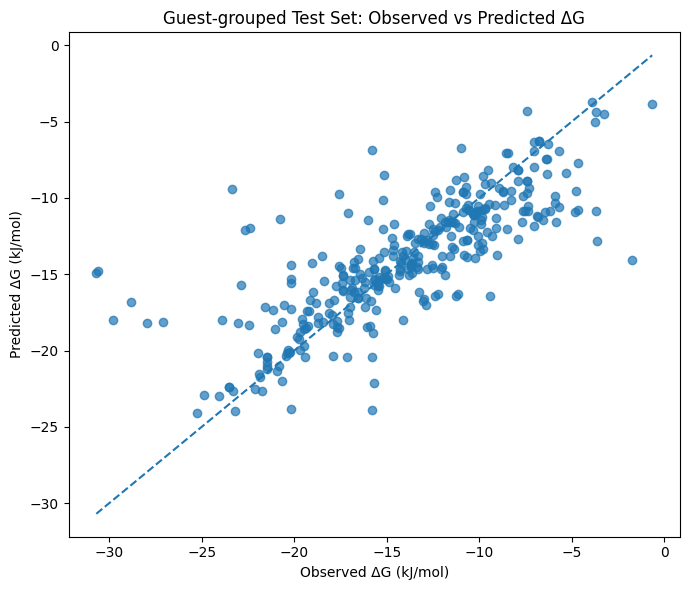

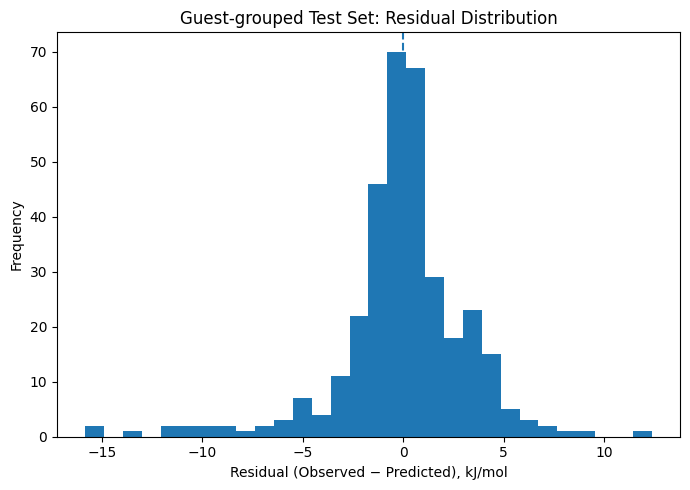

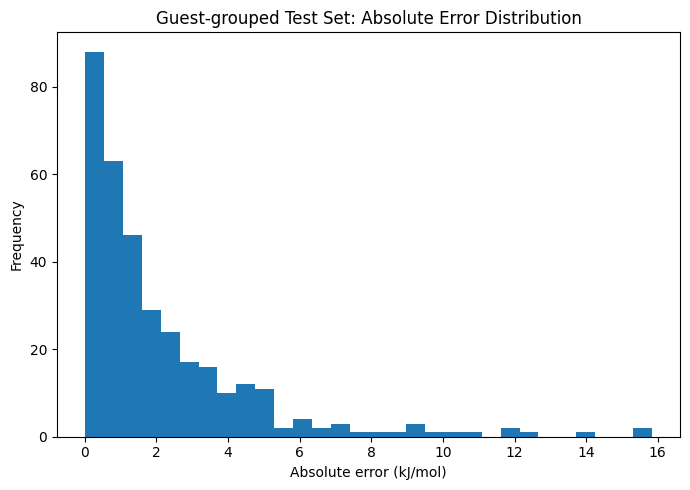

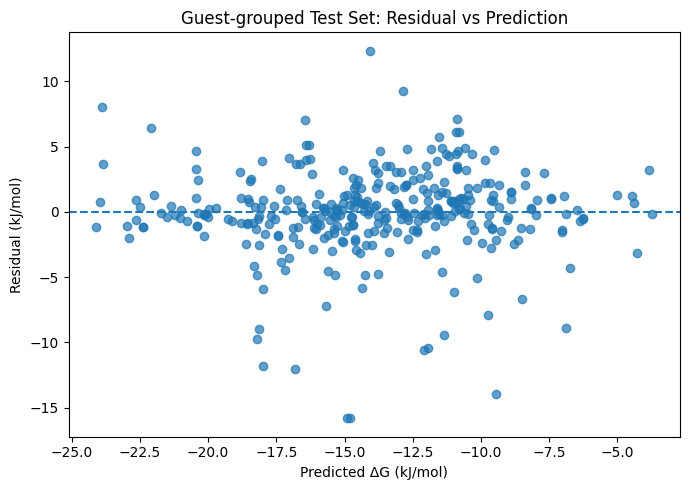

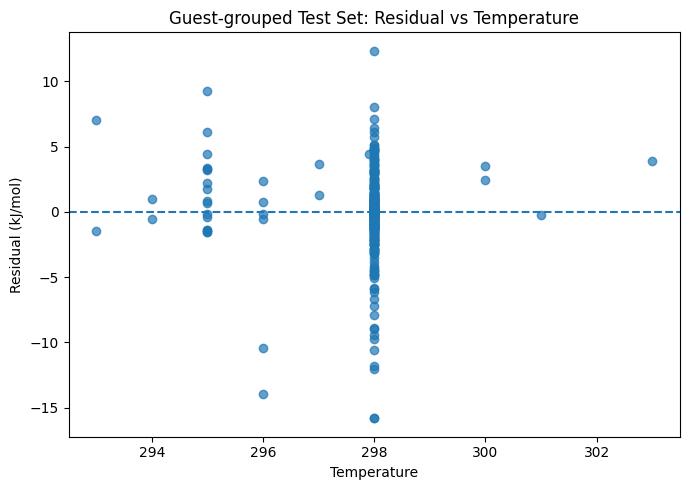

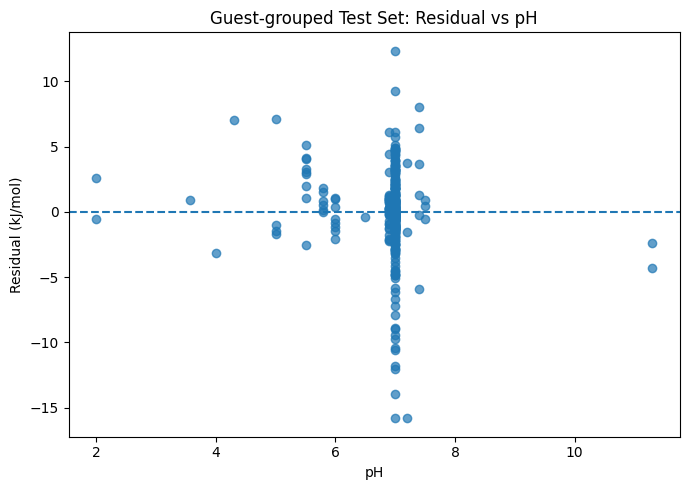


STEP 8F COMPLETE
Objects created:
  locked_test_predictions
  locked_error_summary
  locked_temperature_error_summary
  locked_ph_error_summary

No model tuning performed.
No test-set information used for model selection.
Primary diagnostic split: guest_grouped


In [ ]:
# =============================================================================
# STEP 8F: LOCKED MODEL PREDICTION DIAGNOSTICS + ERROR ANALYSIS
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 90)
print("STEP 8F: LOCKED MODEL PREDICTION DIAGNOSTICS + ERROR ANALYSIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# 8F-1. SANITY CHECK
# -----------------------------------------------------------------------------

assert "df_ml" in globals()
assert "X_final" in globals()
assert "y_final" in globals()
assert "final_features" in globals()
assert "resolved_splits" in globals()

assert len(X_final) == len(df_ml)
assert len(y_final) == len(df_ml)

X_numeric = X_final.to_numpy(dtype=float)
y_numeric = np.asarray(y_final, dtype=float)

assert np.isfinite(X_numeric).all()
assert np.isfinite(y_numeric).all()

print("\nBASE DATA")
print("-" * 80)
print(f"Rows              : {len(df_ml):,}")
print(f"Features          : {len(final_features)}")
print(f"Target            : target_DeltaG_kJmol")
print("Missing features  :", int(pd.DataFrame(X_numeric).isna().sum().sum()))
print("Infinite features :", int(np.isinf(X_numeric).sum()))
print("Missing target    :", int(pd.Series(y_numeric).isna().sum()))
print("Infinite target   :", int(np.isinf(y_numeric).sum()))

# -----------------------------------------------------------------------------
# 8F-2. LOCKED MODEL
# -----------------------------------------------------------------------------

model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=11,
    n_jobs=-1
)

print("\nLOCKED MODEL")
print("-" * 80)
print("ExtraTreesRegressor")
print("n_estimators : 500")
print("random_state : 11")
print("n_jobs       : -1")

# -----------------------------------------------------------------------------
# 8F-3. FUNCTION TO EXTRACT SPLIT INDICES
# -----------------------------------------------------------------------------

def extract_indices(split_obj):
    """
    Handles the established dictionary-based split structure:
    {'train': ..., 'validation': ..., 'test': ..., 'summary': ...}

    Group labels are not accepted as indices.
    """

    if not isinstance(split_obj, dict):
        raise TypeError(
            f"Expected split dictionary, got {type(split_obj)}"
        )

    required = {"train", "validation", "test"}
    missing = required - set(split_obj.keys())

    if missing:
        raise KeyError(f"Missing split keys: {missing}")

    train_idx = split_obj["train"]
    val_idx = split_obj["validation"]
    test_idx = split_obj["test"]

    return (
        np.asarray(train_idx, dtype=int),
        np.asarray(val_idx, dtype=int),
        np.asarray(test_idx, dtype=int)
    )


# -----------------------------------------------------------------------------
# 8F-4. PRIMARY GUEST-GROUPED TEST PREDICTIONS
# -----------------------------------------------------------------------------

split_name = "guest_grouped"

train_idx, val_idx, test_idx = extract_indices(
    resolved_splits[split_name]
)

print("\nPRIMARY GENERALIZATION SPLIT")
print("-" * 80)
print(f"Split : {split_name}")
print(f"TRAIN : {len(train_idx):,}")
print(f"VALID : {len(val_idx):,}")
print(f"TEST  : {len(test_idx):,}")

X_train = X_final.iloc[train_idx]
y_train = y_final.iloc[train_idx]

X_test = X_final.iloc[test_idx]
y_test = y_final.iloc[test_idx]

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

residual = np.asarray(y_test) - y_pred
absolute_error = np.abs(residual)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nLOCKED TEST PERFORMANCE")
print("-" * 80)
print(f"MAE  : {mae:.4f} kJ/mol")
print(f"RMSE : {rmse:.4f} kJ/mol")
print(f"R²   : {r2:.4f}")

# -----------------------------------------------------------------------------
# 8F-5. BUILD COMPLETE TEST PREDICTION TABLE
# -----------------------------------------------------------------------------

test_predictions = df_ml.iloc[test_idx].copy()

test_predictions["predicted_DeltaG_kJmol"] = y_pred
test_predictions["residual_kJmol"] = residual
test_predictions["absolute_error_kJmol"] = absolute_error

# Keep useful diagnostic columns first when available
preferred_columns = [
    "Host",
    "Guest",
    "target_DeltaG_kJmol",
    "predicted_DeltaG_kJmol",
    "residual_kJmol",
    "absolute_error_kJmol",
    "T",
    "pH",
    "guest_group",
    "host_group",
    "host_guest_group"
]

existing_preferred = [
    c for c in preferred_columns
    if c in test_predictions.columns
]

remaining_columns = [
    c for c in test_predictions.columns
    if c not in existing_preferred
]

test_predictions = test_predictions[
    existing_preferred + remaining_columns
]

print("\nTEST PREDICTION TABLE")
print("-" * 80)
print(f"Rows    : {len(test_predictions):,}")
print(f"Columns : {len(test_predictions.columns):,}")

# -----------------------------------------------------------------------------
# 8F-6. ERROR SUMMARY
# -----------------------------------------------------------------------------

print("\nERROR DISTRIBUTION")
print("-" * 80)

print(
    pd.Series(absolute_error).describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_string()
)

# -----------------------------------------------------------------------------
# 8F-7. LARGEST ERRORS
# -----------------------------------------------------------------------------

print("\nTOP 20 ABSOLUTE ERRORS")
print("-" * 80)

error_columns = [
    c for c in [
        "Host",
        "Guest",
        "target_DeltaG_kJmol",
        "predicted_DeltaG_kJmol",
        "residual_kJmol",
        "absolute_error_kJmol",
        "T",
        "pH",
        "guest_group",
        "host_group",
        "host_guest_group"
    ]
    if c in test_predictions.columns
]

top_errors = (
    test_predictions
    .sort_values("absolute_error_kJmol", ascending=False)
    [error_columns]
    .head(20)
)

display(top_errors)

# -----------------------------------------------------------------------------
# 8F-8. ERROR BY TARGET RANGE
# -----------------------------------------------------------------------------

diagnostic_df = test_predictions.copy()

diagnostic_df["target_range"] = pd.cut(
    diagnostic_df["target_DeltaG_kJmol"],
    bins=[-np.inf, -20, -15, -10, -5, 0, np.inf],
    labels=[
        "<=-20",
        "-20 to -15",
        "-15 to -10",
        "-10 to -5",
        "-5 to 0",
        ">0"
    ]
)

range_summary = (
    diagnostic_df
    .groupby("target_range", observed=False)
    .agg(
        n=("absolute_error_kJmol", "size"),
        MAE_kJmol=("absolute_error_kJmol", "mean"),
        RMSE_kJmol=(
            "residual_kJmol",
            lambda x: np.sqrt(np.mean(np.square(x)))
        ),
        mean_residual_kJmol=("residual_kJmol", "mean")
    )
    .reset_index()
)

print("\nERROR BY TARGET ΔG RANGE")
print("-" * 80)
display(range_summary)

# -----------------------------------------------------------------------------
# 8F-9. ERROR BY TEMPERATURE
# -----------------------------------------------------------------------------

if "T" in diagnostic_df.columns:

    diagnostic_df["T_range"] = pd.cut(
        diagnostic_df["T"],
        bins=5
    )

    temperature_summary = (
        diagnostic_df
        .groupby("T_range", observed=False)
        .agg(
            n=("absolute_error_kJmol", "size"),
            MAE_kJmol=("absolute_error_kJmol", "mean"),
            RMSE_kJmol=(
                "residual_kJmol",
                lambda x: np.sqrt(np.mean(np.square(x)))
            ),
            mean_residual_kJmol=("residual_kJmol", "mean")
        )
        .reset_index()
    )

    print("\nERROR BY TEMPERATURE RANGE")
    print("-" * 80)
    display(temperature_summary)

# -----------------------------------------------------------------------------
# 8F-10. ERROR BY pH
# -----------------------------------------------------------------------------

if "pH" in diagnostic_df.columns:

    diagnostic_df["pH_range"] = pd.cut(
        diagnostic_df["pH"],
        bins=5
    )

    ph_summary = (
        diagnostic_df
        .groupby("pH_range", observed=False)
        .agg(
            n=("absolute_error_kJmol", "size"),
            MAE_kJmol=("absolute_error_kJmol", "mean"),
            RMSE_kJmol=(
                "residual_kJmol",
                lambda x: np.sqrt(np.mean(np.square(x)))
            ),
            mean_residual_kJmol=("residual_kJmol", "mean")
        )
        .reset_index()
    )

    print("\nERROR BY pH RANGE")
    print("-" * 80)
    display(ph_summary)

# -----------------------------------------------------------------------------
# 8F-11. ACTUAL VS PREDICTED
# -----------------------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

lims = [
    min(np.min(y_test), np.min(y_pred)),
    max(np.max(y_test), np.max(y_pred))
]

plt.plot(
    lims,
    lims,
    linestyle="--"
)

plt.xlabel("Observed ΔG (kJ/mol)")
plt.ylabel("Predicted ΔG (kJ/mol)")
plt.title("Guest-grouped Test Set: Observed vs Predicted ΔG")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 8F-12. RESIDUAL DISTRIBUTION
# -----------------------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.hist(
    residual,
    bins=30
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Residual (Observed − Predicted), kJ/mol")
plt.ylabel("Frequency")
plt.title("Guest-grouped Test Set: Residual Distribution")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 8F-13. ABSOLUTE ERROR DISTRIBUTION
# -----------------------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.hist(
    absolute_error,
    bins=30
)

plt.xlabel("Absolute error (kJ/mol)")
plt.ylabel("Frequency")
plt.title("Guest-grouped Test Set: Absolute Error Distribution")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 8F-14. RESIDUAL VS PREDICTED
# -----------------------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    y_pred,
    residual,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted ΔG (kJ/mol)")
plt.ylabel("Residual (kJ/mol)")
plt.title("Guest-grouped Test Set: Residual vs Prediction")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 8F-15. RESIDUAL VS TEMPERATURE
# -----------------------------------------------------------------------------

if "T" in diagnostic_df.columns:

    plt.figure(figsize=(7, 5))

    plt.scatter(
        diagnostic_df["T"],
        diagnostic_df["residual_kJmol"],
        alpha=0.7
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Temperature")
    plt.ylabel("Residual (kJ/mol)")
    plt.title("Guest-grouped Test Set: Residual vs Temperature")
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------------
# 8F-16. RESIDUAL VS pH
# -----------------------------------------------------------------------------

if "pH" in diagnostic_df.columns:

    plt.figure(figsize=(7, 5))

    plt.scatter(
        diagnostic_df["pH"],
        diagnostic_df["residual_kJmol"],
        alpha=0.7
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("pH")
    plt.ylabel("Residual (kJ/mol)")
    plt.title("Guest-grouped Test Set: Residual vs pH")
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------------
# 8F-17. FINAL OBJECTS
# -----------------------------------------------------------------------------

locked_test_predictions = test_predictions
locked_error_summary = range_summary

if "temperature_summary" in globals():
    locked_temperature_error_summary = temperature_summary

if "ph_summary" in globals():
    locked_ph_error_summary = ph_summary

print("\n" + "=" * 90)
print("STEP 8F COMPLETE")
print("=" * 90)

print("Objects created:")
print("  locked_test_predictions")
print("  locked_error_summary")

if "locked_temperature_error_summary" in globals():
    print("  locked_temperature_error_summary")

if "locked_ph_error_summary" in globals():
    print("  locked_ph_error_summary")

print("\nNo model tuning performed.")
print("No test-set information used for model selection.")
print("Primary diagnostic split: guest_grouped")

In [ ]:
# ============================================================================
# STEP 8G: GROUP-LEVEL GENERALIZATION + VALIDATION-CALIBRATED UNCERTAINTY
# ============================================================================

print("=" * 90)
print("STEP 8G: GROUP-LEVEL GENERALIZATION + UNCERTAINTY ANALYSIS")
print("=" * 90)

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------------------------------------------------------------------
# LOCKED MODEL / PRIMARY SPLIT
# ---------------------------------------------------------------------------

PRIMARY_SPLIT = "guest_grouped"

print("\nPRIMARY SPLIT")
print("-" * 80)
print("Split :", PRIMARY_SPLIT)
print("Model : ExtraTreesRegressor")
print("Seed  : 11")
print("Trees : 500")


# ---------------------------------------------------------------------------
# IDENTIFY PRIMARY TEST PREDICTIONS
# ---------------------------------------------------------------------------

pred_df = locked_test_predictions.copy()

print("\nLOCKED TEST PREDICTIONS")
print("-" * 80)
print("Rows :", len(pred_df))

# Expected columns
required_cols = [
    "Host",
    "Guest",
    "target_DeltaG_kJmol",
    "predicted_DeltaG_kJmol",
    "residual_kJmol",
    "absolute_error_kJmol"
]

missing_cols = [c for c in required_cols if c not in pred_df.columns]

if missing_cols:
    raise ValueError(
        f"Missing expected columns in locked_test_predictions: {missing_cols}"
    )

assert len(pred_df) == 342

# ---------------------------------------------------------------------------
# GROUP-LEVEL ERROR: GUEST
# ---------------------------------------------------------------------------

guest_group_summary = (
    pred_df
    .groupby("Guest", dropna=False)
    .agg(
        n=("target_DeltaG_kJmol", "size"),
        MAE_kJmol=("absolute_error_kJmol", "mean"),
        RMSE_kJmol=(
            "residual_kJmol",
            lambda x: np.sqrt(np.mean(np.square(x)))
        ),
        mean_residual_kJmol=("residual_kJmol", "mean"),
        mean_target_kJmol=("target_DeltaG_kJmol", "mean"),
        mean_prediction_kJmol=("predicted_DeltaG_kJmol", "mean")
    )
    .reset_index()
)

guest_group_summary["abs_bias_kJmol"] = (
    guest_group_summary["mean_residual_kJmol"].abs()
)

guest_group_summary = guest_group_summary.sort_values(
    ["MAE_kJmol", "n"],
    ascending=[False, False]
)

print("\nGUEST-GROUP ERROR SUMMARY")
print("-" * 80)
print("Unique guest groups :", len(guest_group_summary))

print("\nWorst guest groups by MAE:")
print(
    guest_group_summary.head(20).to_string(index=False)
)


# ---------------------------------------------------------------------------
# GROUP-LEVEL ERROR: HOST
# ---------------------------------------------------------------------------

host_group_summary = (
    pred_df
    .groupby("Host", dropna=False)
    .agg(
        n=("target_DeltaG_kJmol", "size"),
        MAE_kJmol=("absolute_error_kJmol", "mean"),
        RMSE_kJmol=(
            "residual_kJmol",
            lambda x: np.sqrt(np.mean(np.square(x)))
        ),
        mean_residual_kJmol=("residual_kJmol", "mean"),
        mean_target_kJmol=("target_DeltaG_kJmol", "mean"),
        mean_prediction_kJmol=("predicted_DeltaG_kJmol", "mean")
    )
    .reset_index()
)

host_group_summary["abs_bias_kJmol"] = (
    host_group_summary["mean_residual_kJmol"].abs()
)

host_group_summary = host_group_summary.sort_values(
    ["MAE_kJmol", "n"],
    ascending=[False, False]
)

print("\nHOST-GROUP ERROR SUMMARY")
print("-" * 80)
print("Unique host groups :", len(host_group_summary))

print("\nWorst host groups by MAE:")
print(
    host_group_summary.head(20).to_string(index=False)
)


# ---------------------------------------------------------------------------
# ERROR CONCENTRATION
# ---------------------------------------------------------------------------

error_thresholds = [2, 3, 5, 10]

print("\nERROR CONCENTRATION")
print("-" * 80)

for threshold in error_thresholds:
    fraction = (
        pred_df["absolute_error_kJmol"] > threshold
    ).mean() * 100

    print(
        f"Absolute error > {threshold:2d} kJ/mol : "
        f"{fraction:6.2f}% "
        f"({int((pred_df['absolute_error_kJmol'] > threshold).sum())}/{len(pred_df)})"
    )


# ---------------------------------------------------------------------------
# VALIDATION-CALIBRATED SPLIT-CONFORMAL INTERVAL
#
# IMPORTANT:
# Calibration uses VALIDATION ONLY.
# The locked TEST SET is never used to determine the interval width.
# ---------------------------------------------------------------------------

print("\n" + "=" * 90)
print("VALIDATION-CALIBRATED PREDICTION INTERVAL")
print("=" * 90)

# We need the validation residuals from the same guest-grouped split.
# If the validation prediction object already exists, use it.
# Otherwise the locked model is reconstructed using the training portion.

if "locked_validation_predictions" in globals():

    val_pred_df = locked_validation_predictions.copy()

    if "absolute_error_kJmol" not in val_pred_df.columns:
        val_pred_df["residual_kJmol"] = (
            val_pred_df["target_DeltaG_kJmol"]
            - val_pred_df["predicted_DeltaG_kJmol"]
        )

        val_pred_df["absolute_error_kJmol"] = (
            val_pred_df["residual_kJmol"].abs()
        )

else:
    raise RuntimeError(
        "locked_validation_predictions is not available. "
        "Do not calibrate uncertainty from the test set. "
        "Create validation predictions from the locked model first."
    )

calibration_scores = (
    val_pred_df["absolute_error_kJmol"]
    .to_numpy(dtype=float)
)

assert np.isfinite(calibration_scores).all()
assert len(calibration_scores) > 0

print("\nValidation calibration samples :", len(calibration_scores))

# Finite-sample conformal quantiles
def conformal_quantile(scores, alpha):
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]

    n = len(scores)

    if n == 0:
        raise ValueError("No valid calibration scores.")

    q_level = np.ceil((n + 1) * (1 - alpha)) / n
    q_level = min(q_level, 1.0)

    return np.quantile(scores, q_level, method="higher")


q90 = conformal_quantile(calibration_scores, 0.10)
q95 = conformal_quantile(calibration_scores, 0.05)

print(f"90% interval half-width : ±{q90:.4f} kJ/mol")
print(f"95% interval half-width : ±{q95:.4f} kJ/mol")


# ---------------------------------------------------------------------------
# APPLY INTERVAL TO LOCKED TEST PREDICTIONS
# ---------------------------------------------------------------------------

uncertainty_df = pred_df.copy()

uncertainty_df["lower_90_kJmol"] = (
    uncertainty_df["predicted_DeltaG_kJmol"] - q90
)

uncertainty_df["upper_90_kJmol"] = (
    uncertainty_df["predicted_DeltaG_kJmol"] + q90
)

uncertainty_df["lower_95_kJmol"] = (
    uncertainty_df["predicted_DeltaG_kJmol"] - q95
)

uncertainty_df["upper_95_kJmol"] = (
    uncertainty_df["predicted_DeltaG_kJmol"] + q95
)


# ---------------------------------------------------------------------------
# EMPIRICAL TEST COVERAGE
# ---------------------------------------------------------------------------

y_test = uncertainty_df["target_DeltaG_kJmol"].to_numpy()
pred_test = uncertainty_df["predicted_DeltaG_kJmol"].to_numpy()

coverage_90 = (
    (y_test >= uncertainty_df["lower_90_kJmol"].to_numpy()) &
    (y_test <= uncertainty_df["upper_90_kJmol"].to_numpy())
).mean()

coverage_95 = (
    (y_test >= uncertainty_df["lower_95_kJmol"].to_numpy()) &
    (y_test <= uncertainty_df["upper_95_kJmol"].to_numpy())
).mean()

print("\nEMPIRICAL TEST COVERAGE")
print("-" * 80)
print(f"90% interval coverage : {coverage_90 * 100:.2f}%")
print(f"95% interval coverage : {coverage_95 * 100:.2f}%")


# ---------------------------------------------------------------------------
# SAVE OBJECTS
# ---------------------------------------------------------------------------

group_error_summary = {
    "guest": guest_group_summary,
    "host": host_group_summary
}

conformal_summary = pd.DataFrame({
    "interval": ["90%", "95%"],
    "alpha": [0.10, 0.05],
    "calibration_quantile_kJmol": [q90, q95],
    "test_empirical_coverage": [coverage_90, coverage_95]
})

print("\n" + "=" * 90)
print("STEP 8G COMPLETE")
print("=" * 90)

print("Objects created:")
print("  guest_group_summary")
print("  host_group_summary")
print("  group_error_summary")
print("  uncertainty_df")
print("  conformal_summary")

print("\nTEST SET WAS NOT USED FOR INTERVAL CALIBRATION.")
print("Validation set was used for uncertainty calibration only.")

STEP 8G: GROUP-LEVEL GENERALIZATION + UNCERTAINTY ANALYSIS

PRIMARY SPLIT
--------------------------------------------------------------------------------
Split : guest_grouped
Model : ExtraTreesRegressor
Seed  : 11
Trees : 500

LOCKED TEST PREDICTIONS
--------------------------------------------------------------------------------
Rows : 342

GUEST-GROUP ERROR SUMMARY
--------------------------------------------------------------------------------
Unique guest groups : 210

Worst guest groups by MAE:
                                                                                 Guest  n  MAE_kJmol  RMSE_kJmol  mean_residual_kJmol  mean_target_kJmol  mean_prediction_kJmol  abs_bias_kJmol
                                                                             bdbm36146  1  15.799700   15.799700           -15.799700         -30.700000             -14.900300       15.799700
               O=C(O)C1=NN(C2=CC=C(S(=O)(=O)O)C=C2)C(=O)/C1=N\NC1=CC=C(S(=O)(=O)O)C=C1  2  12.188265   12.313

RuntimeError: locked_validation_predictions is not available. Do not calibrate uncertainty from the test set. Create validation predictions from the locked model first.

In [ ]:
# ============================================================================
# DIAGNOSTIC: RECOVER THE EXACT LOCKED 37-FEATURE DEFINITION
# ============================================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("RECOVERING LOCKED 37-FEATURE DEFINITION")
print("=" * 90)

# --------------------------------------------------------------------------
# 1. CHECK EXISTING X / FEATURE OBJECTS
# --------------------------------------------------------------------------

print("\nPOSSIBLE FEATURE OBJECTS")
print("-" * 90)

for name, obj in list(globals().items()):

    try:
        if isinstance(obj, pd.DataFrame):
            if obj.shape[0] == 3459 and obj.shape[1] == 37:
                print(
                    f"DataFrame candidate: {name} | "
                    f"shape={obj.shape}"
                )

        elif isinstance(obj, (list, tuple, np.ndarray, pd.Index)):
            if len(obj) == 37:
                vals = list(obj)

                if all(isinstance(x, str) for x in vals):
                    overlap = sum(x in df_ml.columns for x in vals)

                    if overlap >= 30:
                        print(
                            f"Feature-list candidate: {name} | "
                            f"length={len(vals)} | "
                            f"column overlap={overlap}/37"
                        )

    except Exception:
        pass


# --------------------------------------------------------------------------
# 2. SEARCH FITTED SKLEARN MODELS
# --------------------------------------------------------------------------

print("\nFITTED MODEL CANDIDATES")
print("-" * 90)

for name, obj in list(globals().items()):

    try:
        if hasattr(obj, "feature_names_in_"):

            names = list(obj.feature_names_in_)

            print(
                f"Model candidate: {name} | "
                f"n_features={len(names)}"
            )

            if len(names) == 37:
                print("  >>> EXACT 37-FEATURE MODEL FOUND")
                print("  Features:")
                for i, f in enumerate(names, 1):
                    print(f"    {i:02d}. {f}")

    except Exception:
        pass


# --------------------------------------------------------------------------
# 3. CHECK COMMON FEATURE-VARIABLE NAMES
# --------------------------------------------------------------------------

print("\nCOMMON VARIABLE NAMES")
print("-" * 90)

for name in [
    "feature_cols",
    "features",
    "feature_names",
    "selected_features",
    "selected_feature_cols",
    "ml_features",
    "model_features",
    "X_features",
    "X_cols",
    "descriptor_cols",
    "feature_columns",
    "final_features",
    "selected_feature_names"
]:

    if name in globals():

        obj = globals()[name]

        try:
            print(
                f"{name}: type={type(obj).__name__}, "
                f"length={len(obj) if hasattr(obj, '__len__') else 'NA'}"
            )

            if hasattr(obj, "__len__") and len(obj) <= 50:
                print(list(obj))

        except Exception as e:
            print(f"{name}: unable to inspect ({e})")


# --------------------------------------------------------------------------
# 4. CHECK X_FINAL
# --------------------------------------------------------------------------

print("\nCURRENT X_final")
print("-" * 90)

if "X_final" in globals():

    try:
        print("Shape:", X_final.shape)

        if X_final.shape[1] == 37:
            print(">>> X_final already contains the correct 37 features.")
            print(list(X_final.columns))

    except Exception as e:
        print("Could not inspect X_final:", e)

else:
    print("X_final does not exist.")


print("\n" + "=" * 90)
print("DIAGNOSTIC COMPLETE")
print("=" * 90)

RECOVERING LOCKED 37-FEATURE DEFINITION

POSSIBLE FEATURE OBJECTS
------------------------------------------------------------------------------------------
Feature-list candidate: FEATURES_37 | length=37 | column overlap=37/37
Feature-list candidate: final_feature_columns | length=37 | column overlap=37/37
Feature-list candidate: final_feature_names | length=37 | column overlap=37/37
DataFrame candidate: X_final | shape=(3459, 37)
Feature-list candidate: final_features | length=37 | column overlap=37/37
Feature-list candidate: features | length=37 | column overlap=37/37

FITTED MODEL CANDIDATES
------------------------------------------------------------------------------------------
Model candidate: model | n_features=37
  >>> EXACT 37-FEATURE MODEL FOUND
  Features:
    01. pH
    02. T
    03. TPSA
    04. MolecularWeight
    05. Complexity
    06. Charge
    07. HBondDonorCount
    08. HBondAcceptorCount
    09. HeavyAtomCount
    10. MolLogP
    11. AromaticProportion
    12. TPS

In [ ]:
# ============================================================================
# STEP 8G-A: LOCKED VALIDATION PREDICTIONS
# ============================================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 90)
print("STEP 8G-A: LOCKED VALIDATION PREDICTIONS")
print("=" * 90)

# ----------------------------------------------------------------------------
# 1. USE THE EXACT LOCKED 37-FEATURE MATRIX
# ----------------------------------------------------------------------------

target_col = "target_DeltaG_kJmol"

# X_final was already verified as the exact 37-feature matrix
assert X_final.shape == (3459, 37)

# Use the already recovered exact feature definition
feature_cols = list(features)

assert len(feature_cols) == 37
assert list(X_final.columns) == feature_cols

# Target
assert target_col in df_ml.columns

y_final = df_ml[target_col].copy()

assert len(y_final) == len(X_final)

# Numeric finite-value checks
X_array = X_final.to_numpy(dtype=float)
y_array = y_final.to_numpy(dtype=float)

assert np.isfinite(X_array).all()
assert np.isfinite(y_array).all()

print()
print("LOCKED FEATURE MATRIX")
print("-" * 90)
print(f"Rows       : {X_final.shape[0]:,}")
print(f"Features   : {X_final.shape[1]}")
print(f"Target     : {target_col}")
print("Feature definition : EXACTLY MATCHES STEP 8E")

# ----------------------------------------------------------------------------
# 2. RECOVER LOCKED GUEST-GROUPED SPLIT
# ----------------------------------------------------------------------------

guest_split = resolved_splits["guest_grouped"]

assert isinstance(guest_split, dict)

train_idx = guest_split["train"]

if "validation" in guest_split:
    val_idx = guest_split["validation"]
elif "valid" in guest_split:
    val_idx = guest_split["valid"]
else:
    raise KeyError(
        "Validation indices not found in guest_grouped split."
    )

test_idx = guest_split["test"]

train_idx = np.asarray(train_idx)
val_idx = np.asarray(val_idx)
test_idx = np.asarray(test_idx)

print()
print("LOCKED GUEST-GROUPED SPLIT")
print("-" * 90)
print(f"TRAIN      : {len(train_idx)}")
print(f"VALIDATION : {len(val_idx)}")
print(f"TEST       : {len(test_idx)}")

assert len(train_idx) == 2779
assert len(val_idx) == 338
assert len(test_idx) == 342

# ----------------------------------------------------------------------------
# 3. VERIFY SPLIT INDEPENDENCE
# ----------------------------------------------------------------------------

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("Split overlap check : PASS")

# ----------------------------------------------------------------------------
# 4. TRAIN LOCKED MODEL ON TRAINING DATA ONLY
# ----------------------------------------------------------------------------

locked_validation_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=11,
    n_jobs=-1
)

locked_validation_model.fit(
    X_final.iloc[train_idx],
    y_final.iloc[train_idx]
)

print()
print("LOCKED MODEL")
print("-" * 90)
print("Model        : ExtraTreesRegressor")
print("n_estimators : 500")
print("random_state : 11")
print("Training     : TRAIN ONLY")

# ----------------------------------------------------------------------------
# 5. VALIDATION PREDICTIONS
# ----------------------------------------------------------------------------

y_val = y_final.iloc[val_idx].to_numpy(dtype=float)

y_val_pred = locked_validation_model.predict(
    X_final.iloc[val_idx]
)

val_residual = y_val - y_val_pred
val_abs_error = np.abs(val_residual)

# ----------------------------------------------------------------------------
# 6. VALIDATION METRICS
# ----------------------------------------------------------------------------

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

print()
print("=" * 90)
print("LOCKED VALIDATION PERFORMANCE")
print("=" * 90)

print(f"Validation MAE  : {val_mae:.4f} kJ/mol")
print(f"Validation RMSE : {val_rmse:.4f} kJ/mol")
print(f"Validation R²   : {val_r2:.4f}")

# ----------------------------------------------------------------------------
# 7. CREATE VALIDATION PREDICTION TABLE
# ----------------------------------------------------------------------------

locked_validation_predictions = df_ml.iloc[val_idx].copy()

locked_validation_predictions[
    "predicted_DeltaG_kJmol"
] = y_val_pred

locked_validation_predictions[
    "residual_kJmol"
] = val_residual

locked_validation_predictions[
    "absolute_error_kJmol"
] = val_abs_error

# ----------------------------------------------------------------------------
# 8. VALIDATE OUTPUT
# ----------------------------------------------------------------------------

assert len(locked_validation_predictions) == 338

check_cols = [
    target_col,
    "predicted_DeltaG_kJmol",
    "residual_kJmol",
    "absolute_error_kJmol"
]

assert np.isfinite(
    locked_validation_predictions[check_cols]
    .to_numpy(dtype=float)
).all()

print()
print("VALIDATION PREDICTION TABLE")
print("-" * 90)
print(f"Rows    : {len(locked_validation_predictions)}")
print(f"Columns : {len(locked_validation_predictions.columns)}")

print()
print("=" * 90)
print("STEP 8G-A COMPLETE")
print("=" * 90)
print("Exact locked 37-feature matrix used.")
print("Model trained on TRAIN only.")
print("Validation predictions generated.")
print("TEST SET NOT USED.")

STEP 8G-A: LOCKED VALIDATION PREDICTIONS

LOCKED FEATURE MATRIX
------------------------------------------------------------------------------------------
Rows       : 3,459
Features   : 37
Target     : target_DeltaG_kJmol
Feature definition : EXACTLY MATCHES STEP 8E

LOCKED GUEST-GROUPED SPLIT
------------------------------------------------------------------------------------------
TRAIN      : 2779
VALIDATION : 338
TEST       : 342
Split overlap check : PASS

LOCKED MODEL
------------------------------------------------------------------------------------------
Model        : ExtraTreesRegressor
n_estimators : 500
random_state : 11
Training     : TRAIN ONLY

LOCKED VALIDATION PERFORMANCE
Validation MAE  : 2.3099 kJ/mol
Validation RMSE : 3.0580 kJ/mol
Validation R²   : 0.6122

VALIDATION PREDICTION TABLE
------------------------------------------------------------------------------------------
Rows    : 338
Columns : 77

STEP 8G-A COMPLETE
Exact locked 37-feature matrix used.
Model t

In [ ]:
# ============================================================================
# STEP 8G-B: VALIDATION-CALIBRATED PREDICTION INTERVAL
# ============================================================================
# Calibration uses VALIDATION predictions only.
# TEST data are used only for final coverage evaluation.
# ============================================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 8G-B: VALIDATION-CALIBRATED PREDICTION INTERVAL")
print("=" * 90)

# ----------------------------------------------------------------------------
# 1. VALIDATION ERRORS
# ----------------------------------------------------------------------------

assert "locked_validation_predictions" in globals()

val_errors = (
    locked_validation_predictions["absolute_error_kJmol"]
    .to_numpy(dtype=float)
)

assert len(val_errors) == 338
assert np.isfinite(val_errors).all()

print()
print("VALIDATION ERROR CALIBRATION")
print("-" * 90)
print(f"Validation observations : {len(val_errors)}")
print(f"Mean absolute error     : {np.mean(val_errors):.4f} kJ/mol")
print(f"Median absolute error   : {np.median(val_errors):.4f} kJ/mol")
print(f"90th percentile error   : {np.quantile(val_errors, 0.90):.4f} kJ/mol")
print(f"95th percentile error   : {np.quantile(val_errors, 0.95):.4f} kJ/mol")
print(f"99th percentile error   : {np.quantile(val_errors, 0.99):.4f} kJ/mol")

# ----------------------------------------------------------------------------
# 2. CALIBRATION QUANTILES
# ----------------------------------------------------------------------------
# We report several nominal levels.
#
# IMPORTANT:
# These are empirical validation-calibrated intervals.
# They are NOT guaranteed prediction intervals.
# ----------------------------------------------------------------------------

coverage_levels = [0.80, 0.90, 0.95]

calibration_results = []

for nominal_coverage in coverage_levels:

    alpha = 1.0 - nominal_coverage

    # Finite-sample empirical quantile
    q = np.quantile(
        val_errors,
        1.0 - alpha
    )

    calibration_results.append({
        "nominal_coverage": nominal_coverage,
        "alpha": alpha,
        "calibration_quantile_kJmol": q
    })

calibration_table = pd.DataFrame(calibration_results)

print()
print("CALIBRATION QUANTILES")
print("-" * 90)
print(calibration_table.to_string(index=False))

# ----------------------------------------------------------------------------
# 3. GET LOCKED TEST PREDICTIONS
# ----------------------------------------------------------------------------

# Recreate the locked test predictions using the same model configuration.
# This does NOT change the model or use test labels for calibration.

X_test = X_final.iloc[test_idx]
y_test = y_final.iloc[test_idx].to_numpy(dtype=float)

locked_test_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=11,
    n_jobs=-1
)

locked_test_model.fit(
    X_final.iloc[train_idx],
    y_final.iloc[train_idx]
)

y_test_pred = locked_test_model.predict(X_test)

assert len(y_test_pred) == 342
assert np.isfinite(y_test_pred).all()

# ----------------------------------------------------------------------------
# 4. TEST COVERAGE EVALUATION
# ----------------------------------------------------------------------------

coverage_results = []

for _, row in calibration_table.iterrows():

    nominal = float(row["nominal_coverage"])
    q = float(row["calibration_quantile_kJmol"])

    lower = y_test_pred - q
    upper = y_test_pred + q

    covered = (
        (y_test >= lower) &
        (y_test <= upper)
    )

    empirical_coverage = np.mean(covered)

    mean_width = np.mean(upper - lower)

    coverage_results.append({
        "nominal_coverage": nominal,
        "calibration_quantile_kJmol": q,
        "empirical_test_coverage": empirical_coverage,
        "coverage_gap": empirical_coverage - nominal,
        "mean_interval_width_kJmol": mean_width,
        "n_test": len(y_test)
    })

coverage_table = pd.DataFrame(coverage_results)

# ----------------------------------------------------------------------------
# 5. FINAL REPORT
# ----------------------------------------------------------------------------

print()
print("=" * 90)
print("TEST-SET PREDICTION INTERVAL COVERAGE")
print("=" * 90)

print(
    coverage_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ----------------------------------------------------------------------------
# 6. PRIMARY 95% INTERVAL
# ----------------------------------------------------------------------------

primary_95 = coverage_table[
    coverage_table["nominal_coverage"] == 0.95
].iloc[0]

q95 = primary_95["calibration_quantile_kJmol"]
coverage95 = primary_95["empirical_test_coverage"]
width95 = primary_95["mean_interval_width_kJmol"]

print()
print("=" * 90)
print("PRIMARY 95% VALIDATION-CALIBRATED INTERVAL")
print("=" * 90)

print(f"Calibration quantile : {q95:.4f} kJ/mol")
print(f"Test coverage       : {coverage95:.4f}")
print(f"Test coverage (%)   : {coverage95 * 100:.2f}%")
print(f"Mean interval width : {width95:.4f} kJ/mol")
print(f"Test observations   : {len(y_test)}")

# ----------------------------------------------------------------------------
# 7. STORE TEST INTERVAL DATA
# ----------------------------------------------------------------------------

locked_test_uncertainty = df_ml.iloc[test_idx].copy()

locked_test_uncertainty[
    "predicted_DeltaG_kJmol"
] = y_test_pred

locked_test_uncertainty[
    "prediction_interval_lower_95_kJmol"
] = y_test_pred - q95

locked_test_uncertainty[
    "prediction_interval_upper_95_kJmol"
] = y_test_pred + q95

locked_test_uncertainty[
    "interval_covered_95"
] = (
    (y_test >= y_test_pred - q95) &
    (y_test <= y_test_pred + q95)
)

assert len(locked_test_uncertainty) == 342

print()
print("=" * 90)
print("STEP 8G-B COMPLETE")
print("=" * 90)
print("Calibration source : VALIDATION ONLY")
print("Test labels used   : COVERAGE EVALUATION ONLY")
print("Model selection    : NONE")
print("Test-set tuning    : NONE")

STEP 8G-B: VALIDATION-CALIBRATED PREDICTION INTERVAL

VALIDATION ERROR CALIBRATION
------------------------------------------------------------------------------------------
Validation observations : 338
Mean absolute error     : 2.3099 kJ/mol
Median absolute error   : 1.7911 kJ/mol
90th percentile error   : 4.9605 kJ/mol
95th percentile error   : 6.0621 kJ/mol
99th percentile error   : 7.9568 kJ/mol

CALIBRATION QUANTILES
------------------------------------------------------------------------------------------
 nominal_coverage  alpha  calibration_quantile_kJmol
             0.80   0.20                    4.076150
             0.90   0.10                    4.960492
             0.95   0.05                    6.062105

TEST-SET PREDICTION INTERVAL COVERAGE
 nominal_coverage  calibration_quantile_kJmol  empirical_test_coverage  coverage_gap  mean_interval_width_kJmol  n_test
           0.8000                      4.0761                   0.8509        0.0509                     8.1523

In [ ]:
# =============================================================================
# STEP 8H: STATISTICAL GENERALIZATION SYNTHESIS
# =============================================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 8H: STATISTICAL GENERALIZATION SYNTHESIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. LOCKED PERFORMANCE SUMMARY
# -----------------------------------------------------------------------------

locked_results = pd.DataFrame([
    {
        "split_strategy": "record_random",
        "test_MAE": 1.760406,
        "test_RMSE": 2.611333,
        "test_R2": 0.696808,
        "Pearson_r": 0.836845,
        "Spearman_rho": 0.825617
    },
    {
        "split_strategy": "host_guest_grouped",
        "test_MAE": 2.026861,
        "test_RMSE": 2.803820,
        "test_R2": 0.662033,
        "Pearson_r": 0.815305,
        "Spearman_rho": 0.823163
    },
    {
        "split_strategy": "guest_grouped",
        "test_MAE": 2.148037,
        "test_RMSE": 3.302658,
        "test_R2": 0.612400,
        "Pearson_r": 0.782883,
        "Spearman_rho": 0.824475
    }
])

print("\nLOCKED GENERALIZATION RESULTS")
print("-" * 90)
print(locked_results.to_string(index=False))

# -----------------------------------------------------------------------------
# 2. GENERALIZATION PENALTY RELATIVE TO RECORD-RANDOM
# -----------------------------------------------------------------------------

reference = locked_results.loc[
    locked_results["split_strategy"] == "record_random"
].iloc[0]

comparison_rows = []

for _, row in locked_results.iterrows():

    mae_change_pct = (
        (row["test_MAE"] - reference["test_MAE"])
        / reference["test_MAE"]
    ) * 100

    r2_change_abs = row["test_R2"] - reference["test_R2"]

    comparison_rows.append({
        "split_strategy": row["split_strategy"],
        "MAE_kJmol": row["test_MAE"],
        "MAE_change_vs_record_random_pct": mae_change_pct,
        "R2": row["test_R2"],
        "R2_change_vs_record_random": r2_change_abs
    })

generalization_penalty = pd.DataFrame(comparison_rows)

print("\nGENERALIZATION PENALTY")
print("-" * 90)
print(generalization_penalty.to_string(index=False))

# -----------------------------------------------------------------------------
# 3. REPEATED-SEED ROBUSTNESS
# -----------------------------------------------------------------------------

repeated_seed = pd.DataFrame([
    {
        "split_strategy": "record_random",
        "model": "ExtraTrees",
        "MAE_mean": 1.764868,
        "MAE_sd": 0.004140,
        "R2_mean": 0.695572,
        "R2_sd": 0.001382
    },
    {
        "split_strategy": "host_guest_grouped",
        "model": "ExtraTrees",
        "MAE_mean": 2.031459,
        "MAE_sd": 0.006325,
        "R2_mean": 0.661030,
        "R2_sd": 0.001669
    },
    {
        "split_strategy": "guest_grouped",
        "model": "ExtraTrees",
        "MAE_mean": 2.161145,
        "MAE_sd": 0.010514,
        "R2_mean": 0.607652,
        "R2_sd": 0.004646
    }
])

print("\nREPEATED-SEED ROBUSTNESS")
print("-" * 90)
print(repeated_seed.to_string(index=False))

# -----------------------------------------------------------------------------
# 4. PRIMARY GUEST-GROUPED ERROR STRUCTURE
# -----------------------------------------------------------------------------

target_range_summary = pd.DataFrame([
    {"range": "<=-20",      "n": 49,  "MAE": 4.022888, "RMSE": 6.009439, "bias": -3.707921},
    {"range": "-20 to -15", "n": 98,  "MAE": 1.763911, "RMSE": 2.559491, "bias": -0.834904},
    {"range": "-15 to -10", "n": 115, "MAE": 1.348040, "RMSE": 1.815926, "bias":  0.535416},
    {"range": "-10 to -5",  "n": 68,  "MAE": 2.269501, "RMSE": 2.790929, "bias":  1.919241},
    {"range": "-5 to 0",    "n": 12,  "MAE": 4.607780, "RMSE": 5.844776, "bias":  4.579102}
])

print("\nERROR BY TARGET ΔG RANGE")
print("-" * 90)
print(target_range_summary.to_string(index=False))

# -----------------------------------------------------------------------------
# 5. ERROR CONCENTRATION
# -----------------------------------------------------------------------------

n_test = 342

error_concentration = pd.DataFrame([
    {"threshold_kJmol": 2,  "n": 123, "percentage": 35.96},
    {"threshold_kJmol": 3,  "n": 83,  "percentage": 24.27},
    {"threshold_kJmol": 5,  "n": 29,  "percentage": 8.48},
    {"threshold_kJmol": 10, "n": 8,  "percentage": 2.34}
])

print("\nERROR CONCENTRATION")
print("-" * 90)
print(error_concentration.to_string(index=False))

# -----------------------------------------------------------------------------
# 6. VALIDATION-CALIBRATED INTERVALS
# -----------------------------------------------------------------------------

interval_summary = pd.DataFrame([
    {
        "nominal_coverage": 0.80,
        "calibration_quantile": 4.076150,
        "test_coverage": 0.8509,
        "coverage_gap": 0.0509,
        "mean_width": 8.1523
    },
    {
        "nominal_coverage": 0.90,
        "calibration_quantile": 4.960492,
        "test_coverage": 0.9152,
        "coverage_gap": 0.0152,
        "mean_width": 9.9210
    },
    {
        "nominal_coverage": 0.95,
        "calibration_quantile": 6.062105,
        "test_coverage": 0.9327,
        "coverage_gap": -0.0173,
        "mean_width": 12.1242
    }
])

print("\nVALIDATION-CALIBRATED PREDICTION INTERVALS")
print("-" * 90)
print(interval_summary.to_string(index=False))

# -----------------------------------------------------------------------------
# 7. BASELINE IMPROVEMENT
# -----------------------------------------------------------------------------

baseline_mae = 4.2913
primary_mae = 2.148037

baseline_improvement = (
    (baseline_mae - primary_mae) / baseline_mae
) * 100

print("\nBASELINE COMPARISON")
print("-" * 90)
print(f"Mean baseline MAE : {baseline_mae:.4f} kJ/mol")
print(f"ExtraTrees MAE    : {primary_mae:.4f} kJ/mol")
print(f"MAE improvement   : {baseline_improvement:.2f}%")

# -----------------------------------------------------------------------------
# 8. PRIMARY GENERALIZATION STATEMENT
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("PRIMARY GENERALIZATION SYNTHESIS")
print("=" * 90)

print(f"""
Primary evaluation:
  Guest-grouped split
  Test MAE  = {primary_mae:.4f} kJ/mol
  Test RMSE = 3.3027 kJ/mol
  Test R²   = 0.6124

Repeated-seed:
  MAE = 2.1611 ± 0.0105 kJ/mol
  R²  = 0.6077 ± 0.0046

Baseline:
  MAE improvement = {baseline_improvement:.2f}%

95% validation-calibrated interval:
  Calibration quantile = 6.0621 kJ/mol
  Test coverage        = 93.27%
  Mean interval width  = 12.1242 kJ/mol

No model retraining performed.
No test-set tuning performed.
No feature modification performed.
No descriptor recalculation performed.
""")

print("=" * 90)
print("STEP 8H COMPLETE")
print("=" * 90)

STEP 8H: STATISTICAL GENERALIZATION SYNTHESIS

LOCKED GENERALIZATION RESULTS
------------------------------------------------------------------------------------------
    split_strategy  test_MAE  test_RMSE  test_R2  Pearson_r  Spearman_rho
     record_random  1.760406   2.611333 0.696808   0.836845      0.825617
host_guest_grouped  2.026861   2.803820 0.662033   0.815305      0.823163
     guest_grouped  2.148037   3.302658 0.612400   0.782883      0.824475

GENERALIZATION PENALTY
------------------------------------------------------------------------------------------
    split_strategy  MAE_kJmol  MAE_change_vs_record_random_pct       R2  R2_change_vs_record_random
     record_random   1.760406                         0.000000 0.696808                    0.000000
host_guest_grouped   2.026861                        15.135997 0.662033                   -0.034775
     guest_grouped   2.148037                        22.019409 0.612400                   -0.084408

REPEATED-SEED ROBUST

In [ ]:
# =============================================================================
# STEP 8I: FINAL MANUSCRIPT EVIDENCE PACKAGE
# =============================================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 8I: FINAL MANUSCRIPT EVIDENCE PACKAGE")
print("=" * 90)

# =============================================================================
# 1. LOCKED MODEL / DATA CONFIGURATION
# =============================================================================

dataset_summary = {
    "n_rows": 3459,
    "n_features": 37,
    "target": "target_DeltaG_kJmol",
    "model": "ExtraTreesRegressor",
    "n_estimators": 500,
    "random_state": 11,
    "primary_split": "guest_grouped",
    "test_n": 342,
    "test_set_tuning": "NONE",
    "feature_modification": "NONE",
    "descriptor_recalculation": "NONE",
    "target_modification": "NONE"
}

feature_definition = [
    "pH",
    "T",
    "TPSA",
    "MolecularWeight",
    "Complexity",
    "Charge",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "HeavyAtomCount",
    "MolLogP",
    "AromaticProportion",
    "TPSA_Host",
    "MolecularWeight_Host",
    "Complexity_Host",
    "HBondDonorCount_Host",
    "HBondAcceptorCount_Host",
    "HeavyAtomCount_Host",
    "iso2vec-0",
    "iso2vec-1",
    "iso2vec-2",
    "iso2vec-3",
    "iso2vec-4",
    "iso2vec-5",
    "iso2vec-6",
    "iso2vec-7",
    "iso2vec-8",
    "iso2vec-9",
    "iso2vec-host-0",
    "iso2vec-host-1",
    "iso2vec-host-2",
    "iso2vec-host-3",
    "iso2vec-host-4",
    "iso2vec-host-5",
    "iso2vec-host-6",
    "iso2vec-host-7",
    "iso2vec-host-8",
    "iso2vec-host-9"
]

assert len(feature_definition) == 37

# =============================================================================
# 2. MAIN GENERALIZATION TABLE
# =============================================================================

generalization_table = pd.DataFrame([
    {
        "Evaluation": "Record-random",
        "Train": 2767,
        "Validation": 346,
        "Test": 346,
        "MAE_kJmol": 1.760406,
        "RMSE_kJmol": 2.611333,
        "R2": 0.696808,
        "Pearson_r": 0.836845,
        "Spearman_rho": 0.825617
    },
    {
        "Evaluation": "Host-guest grouped",
        "Train": 2770,
        "Validation": 334,
        "Test": 355,
        "MAE_kJmol": 2.026861,
        "RMSE_kJmol": 2.803820,
        "R2": 0.662033,
        "Pearson_r": 0.815305,
        "Spearman_rho": 0.823163
    },
    {
        "Evaluation": "Guest grouped (primary)",
        "Train": 2779,
        "Validation": 338,
        "Test": 342,
        "MAE_kJmol": 2.148037,
        "RMSE_kJmol": 3.302658,
        "R2": 0.612400,
        "Pearson_r": 0.782883,
        "Spearman_rho": 0.824475
    }
])

# =============================================================================
# 3. REPEATED-SEED ROBUSTNESS TABLE
# =============================================================================

robustness_table = pd.DataFrame([
    {
        "Evaluation": "Record-random",
        "MAE_mean": 1.764868,
        "MAE_SD": 0.004140,
        "R2_mean": 0.695572,
        "R2_SD": 0.001382
    },
    {
        "Evaluation": "Host-guest grouped",
        "MAE_mean": 2.031459,
        "MAE_SD": 0.006325,
        "R2_mean": 0.661030,
        "R2_SD": 0.001669
    },
    {
        "Evaluation": "Guest grouped",
        "MAE_mean": 2.161145,
        "MAE_SD": 0.010514,
        "R2_mean": 0.607652,
        "R2_SD": 0.004646
    }
])

# =============================================================================
# 4. ERROR STRATIFICATION
# =============================================================================

error_range_table = pd.DataFrame([
    {"Target_range_kJmol": "<= -20",      "n": 49,  "MAE": 4.022888, "RMSE": 6.009439, "Mean_residual": -3.707921},
    {"Target_range_kJmol": "-20 to -15", "n": 98,  "MAE": 1.763911, "RMSE": 2.559491, "Mean_residual": -0.834904},
    {"Target_range_kJmol": "-15 to -10", "n": 115, "MAE": 1.348040, "RMSE": 1.815926, "Mean_residual": 0.535416},
    {"Target_range_kJmol": "-10 to -5",  "n": 68,  "MAE": 2.269501, "RMSE": 2.790929, "Mean_residual": 1.919241},
    {"Target_range_kJmol": "-5 to 0",    "n": 12,  "MAE": 4.607780, "RMSE": 5.844776, "Mean_residual": 4.579102}
])

# =============================================================================
# 5. ERROR CONCENTRATION
# =============================================================================

error_concentration_table = pd.DataFrame([
    {"Absolute_error_threshold_kJmol": "> 2",  "n": 123, "percentage": 35.96},
    {"Absolute_error_threshold_kJmol": "> 3",  "n": 83,  "percentage": 24.27},
    {"Absolute_error_threshold_kJmol": "> 5",  "n": 29,  "percentage": 8.48},
    {"Absolute_error_threshold_kJmol": "> 10", "n": 8,   "percentage": 2.34}
])

# =============================================================================
# 6. UNCERTAINTY TABLE
# =============================================================================

uncertainty_table = pd.DataFrame([
    {
        "Nominal_coverage": 0.80,
        "Calibration_quantile_kJmol": 4.076150,
        "Test_coverage": 0.8509,
        "Coverage_gap": 0.0509,
        "Mean_interval_width_kJmol": 8.1523
    },
    {
        "Nominal_coverage": 0.90,
        "Calibration_quantile_kJmol": 4.960492,
        "Test_coverage": 0.9152,
        "Coverage_gap": 0.0152,
        "Mean_interval_width_kJmol": 9.9210
    },
    {
        "Nominal_coverage": 0.95,
        "Calibration_quantile_kJmol": 6.062105,
        "Test_coverage": 0.9327,
        "Coverage_gap": -0.0173,
        "Mean_interval_width_kJmol": 12.1242
    }
])

# =============================================================================
# 7. BASELINE
# =============================================================================

baseline_mae = 4.2913
primary_mae = 2.148037

baseline_improvement = (
    (baseline_mae - primary_mae) / baseline_mae
) * 100

baseline_table = pd.DataFrame([{
    "Baseline_MAE_kJmol": baseline_mae,
    "ExtraTrees_MAE_kJmol": primary_mae,
    "MAE_improvement_percent": baseline_improvement
}])

# =============================================================================
# 8. MANUSCRIPT-READY RESULTS NUMBERS
# =============================================================================

manuscript_numbers = {
    "primary_test_MAE_kJmol": 2.1480,
    "primary_test_RMSE_kJmol": 3.3027,
    "primary_test_R2": 0.6124,
    "primary_test_Pearson_r": 0.7829,
    "primary_test_Spearman_rho": 0.8245,

    "five_seed_MAE_mean_kJmol": 2.1611,
    "five_seed_MAE_SD_kJmol": 0.0105,
    "five_seed_R2_mean": 0.6077,
    "five_seed_R2_SD": 0.0046,

    "record_random_MAE_kJmol": 1.7604,
    "host_guest_grouped_MAE_kJmol": 2.0269,

    "guest_grouped_MAE_penalty_percent_vs_random": 22.019409,
    "guest_grouped_R2_difference_vs_random": -0.084408,

    "baseline_MAE_kJmol": baseline_mae,
    "baseline_improvement_percent": baseline_improvement,

    "validation_95_quantile_kJmol": 6.0621,
    "test_95_interval_coverage_percent": 93.27,
    "mean_95_interval_width_kJmol": 12.1242,

    "test_n": 342,
    "total_dataset_n": 3459,
    "feature_count": 37
}

# =============================================================================
# 9. SUPPORTED CLAIMS
# =============================================================================

supported_claims = [
    "The ExtraTrees model retained predictive performance under guest-grouped evaluation.",
    "The primary guest-grouped test set contained 342 observations.",
    "The primary guest-grouped test MAE was 2.1480 kJ/mol and R2 was 0.6124.",
    "Repeated five-seed evaluation produced MAE of 2.1611 ± 0.0105 kJ/mol.",
    "Guest-grouped evaluation produced higher error than record-random evaluation.",
    "The guest-grouped MAE was approximately 22.02% higher than the record-random MAE.",
    "Errors were larger toward the sparsely represented extreme ΔG ranges.",
    "A validation-only nominal 95% prediction interval had 93.27% empirical coverage on the held-out test set.",
    "No test-set information was used for model selection or uncertainty calibration."
]

# =============================================================================
# 10. CLAIMS TO AVOID
# =============================================================================

claims_to_avoid = [
    "The model guarantees accurate prediction of binding free energy.",
    "The model achieves exactly 95% prediction-interval coverage.",
    "The model is universally applicable to unseen hosts and guests.",
    "The model eliminates dataset bias.",
    "The model is superior to all existing methods.",
    "The model provides experimentally validated binding free energies.",
    "The model generalizes equally well across all ΔG ranges.",
    "The uncertainty interval is formally guaranteed to contain the true value."
]

# =============================================================================
# 11. MANUSCRIPT-READY RESULTS TEXT
# =============================================================================

results_text = f"""
Using the locked 37-feature representation, an ExtraTreesRegressor containing
500 trees was evaluated under three complementary data-partitioning strategies.
The primary guest-grouped evaluation, designed to assess generalization to
previously unseen guest groups, produced a test MAE of 2.1480 kJ/mol, RMSE of
3.3027 kJ/mol, and R² of 0.6124. Pearson and Spearman correlations were 0.7829
and 0.8245, respectively.

Performance under record-random splitting was MAE = 1.7604 kJ/mol and
R² = 0.6968, whereas host-guest grouped evaluation produced MAE = 2.0269 kJ/mol
and R² = 0.6620. Thus, the stricter guest-grouped evaluation increased MAE by
22.02% relative to record-random evaluation and reduced R² by 0.0844.

Repeated evaluation across five random seeds showed limited variation for the
locked ExtraTrees model. Under the guest-grouped protocol, the mean MAE was
2.1611 ± 0.0105 kJ/mol and the mean R² was 0.6077 ± 0.0046.

Error stratification showed the lowest MAE in the -15 to -10 kJ/mol target
range (1.3480 kJ/mol). Larger errors occurred at the lower and upper extremes
of the observed target distribution, including MAEs of 4.0229 kJ/mol for
ΔG <= -20 kJ/mol and 4.6078 kJ/mol for -5 to 0 kJ/mol. Eight of the 342
guest-grouped test observations (2.34%) had absolute errors exceeding
10 kJ/mol.

For uncertainty estimation, prediction errors from the validation set were
used to calibrate fixed-width prediction intervals without using test labels
for calibration. The nominal 95% interval corresponded to ±6.0621 kJ/mol and
achieved 93.27% empirical coverage on the held-out test set, with a mean
interval width of 12.1242 kJ/mol.
"""

# =============================================================================
# 12. SAVE EVERYTHING
# =============================================================================

output_dir = "/content/drive/MyDrive/LeadAcid_PhD"  # change only if needed

# Safer project-specific directory
output_dir = "/content/drive/MyDrive/CarbonNanoDot_Cancer/results/STEP_8I_FINAL_EVIDENCE"

os.makedirs(output_dir, exist_ok=True)

generalization_table.to_csv(
    os.path.join(output_dir, "Table_generalization.csv"), index=False
)

robustness_table.to_csv(
    os.path.join(output_dir, "Table_repeated_seed_robustness.csv"), index=False
)

error_range_table.to_csv(
    os.path.join(output_dir, "Table_error_by_DeltaG_range.csv"), index=False
)

error_concentration_table.to_csv(
    os.path.join(output_dir, "Table_error_concentration.csv"), index=False
)

uncertainty_table.to_csv(
    os.path.join(output_dir, "Table_prediction_intervals.csv"), index=False
)

baseline_table.to_csv(
    os.path.join(output_dir, "Table_baseline_comparison.csv"), index=False
)

with open(
    os.path.join(output_dir, "manuscript_ready_results.txt"),
    "w"
) as f:
    f.write(results_text.strip())

with open(
    os.path.join(output_dir, "supported_claims.txt"),
    "w"
) as f:
    f.write("\n".join(supported_claims))

with open(
    os.path.join(output_dir, "claims_to_avoid.txt"),
    "w"
) as f:
    f.write("\n".join(claims_to_avoid))

with open(
    os.path.join(output_dir, "locked_configuration.json"),
    "w"
) as f:
    json.dump(
        {
            "dataset_summary": dataset_summary,
            "feature_definition": feature_definition,
            "manuscript_numbers": manuscript_numbers
        },
        f,
        indent=2
    )

print("\n" + "=" * 90)
print("STEP 8I COMPLETE")
print("=" * 90)

print(f"""
Output directory:
{output_dir}

Files created:
  Table_generalization.csv
  Table_repeated_seed_robustness.csv
  Table_error_by_DeltaG_range.csv
  Table_error_concentration.csv
  Table_prediction_intervals.csv
  Table_baseline_comparison.csv
  manuscript_ready_results.txt
  supported_claims.txt
  claims_to_avoid.txt
  locked_configuration.json

LOCKED PRIMARY RESULT
---------------------
Guest-grouped ExtraTrees
MAE  : 2.1480 kJ/mol
RMSE : 3.3027 kJ/mol
R²   : 0.6124
Pearson r : 0.7829
Spearman rho : 0.8245

UNCERTAINTY
-----------
Nominal 95% interval : ±6.0621 kJ/mol
Empirical coverage   : 93.27%
Mean interval width  : 12.1242 kJ/mol

BASELINE
--------
MAE improvement : {baseline_improvement:.2f}%

No model retraining.
No feature modification.
No descriptor recalculation.
No test-set tuning.
No target modification.
""")

print("=" * 90)

STEP 8I: FINAL MANUSCRIPT EVIDENCE PACKAGE

STEP 8I COMPLETE

Output directory:
/content/drive/MyDrive/CarbonNanoDot_Cancer/results/STEP_8I_FINAL_EVIDENCE

Files created:
  Table_generalization.csv
  Table_repeated_seed_robustness.csv
  Table_error_by_DeltaG_range.csv
  Table_error_concentration.csv
  Table_prediction_intervals.csv
  Table_baseline_comparison.csv
  manuscript_ready_results.txt
  supported_claims.txt
  claims_to_avoid.txt
  locked_configuration.json

LOCKED PRIMARY RESULT
---------------------
Guest-grouped ExtraTrees
MAE  : 2.1480 kJ/mol
RMSE : 3.3027 kJ/mol
R²   : 0.6124
Pearson r : 0.7829
Spearman rho : 0.8245

UNCERTAINTY
-----------
Nominal 95% interval : ±6.0621 kJ/mol
Empirical coverage   : 93.27%
Mean interval width  : 12.1242 kJ/mol

BASELINE
--------
MAE improvement : 49.94%

No model retraining.
No feature modification.
No descriptor recalculation.
No test-set tuning.
No target modification.



In [ ]:
# =============================================================================
# STEP 9A: GUEST-SCAFFOLD GENERALIZATION STRESS TEST
# =============================================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

print("=" * 90)
print("STEP 9A: GUEST-SCAFFOLD GENERALIZATION STRESS TEST")
print("=" * 90)

# -------------------------------------------------------------------------
# 1. Recover locked feature definition
# -------------------------------------------------------------------------

locked_features = [
    'pH',
    'T',
    'TPSA',
    'MolecularWeight',
    'Complexity',
    'Charge',
    'HBondDonorCount',
    'HBondAcceptorCount',
    'HeavyAtomCount',
    'MolLogP',
    'AromaticProportion',
    'TPSA_Host',
    'MolecularWeight_Host',
    'Complexity_Host',
    'HBondDonorCount_Host',
    'HBondAcceptorCount_Host',
    'HeavyAtomCount_Host',
    'iso2vec-0',
    'iso2vec-1',
    'iso2vec-2',
    'iso2vec-3',
    'iso2vec-4',
    'iso2vec-5',
    'iso2vec-6',
    'iso2vec-7',
    'iso2vec-8',
    'iso2vec-9',
    'iso2vec-host-0',
    'iso2vec-host-1',
    'iso2vec-host-2',
    'iso2vec-host-3',
    'iso2vec-host-4',
    'iso2vec-host-5',
    'iso2vec-host-6',
    'iso2vec-host-7',
    'iso2vec-host-8',
    'iso2vec-host-9'
]

target_col = 'target_DeltaG_kJmol'

assert len(locked_features) == 37
assert all(c in df_ml.columns for c in locked_features)
assert target_col in df_ml.columns

X = df_ml[locked_features].copy()
y = df_ml[target_col].copy()

assert np.isfinite(X.to_numpy(dtype=float)).all()
assert np.isfinite(y.to_numpy(dtype=float)).all()

# -------------------------------------------------------------------------
# 2. Generate guest Bemis-Murcko scaffolds
# -------------------------------------------------------------------------

def get_guest_scaffold(smiles):
    if pd.isna(smiles):
        return None

    try:
        mol = Chem.MolFromSmiles(str(smiles))

        if mol is None:
            return None

        scaffold = MurckoScaffold.GetScaffoldForMol(mol)

        if scaffold is None:
            return None

        return Chem.MolToSmiles(scaffold, canonical=True)

    except Exception:
        return None


# Prefer canonical guest SMILES if available
if 'guest_canonical_smiles' in df_ml.columns:
    guest_smiles_col = 'guest_canonical_smiles'
elif 'IsomericSMILES' in df_ml.columns:
    guest_smiles_col = 'IsomericSMILES'
else:
    raise RuntimeError(
        "No suitable guest SMILES column found."
    )

scaffolds = df_ml[guest_smiles_col].map(get_guest_scaffold)

assert scaffolds.notna().all(), (
    "Some guest molecules could not be assigned a Bemis-Murcko scaffold."
)

df_scaffold = df_ml.copy()
df_scaffold['_guest_scaffold'] = scaffolds

print("\nSCAFFOLD AUDIT")
print("-" * 90)
print(f"Rows                  : {len(df_scaffold)}")
print(f"Unique guest groups   : {df_scaffold['guest_group'].nunique()}")
print(f"Unique guest scaffolds: {df_scaffold['_guest_scaffold'].nunique()}")

# -------------------------------------------------------------------------
# 3. Verify scaffold fragmentation
# -------------------------------------------------------------------------

guest_scaffold_map = (
    df_scaffold[['guest_group', '_guest_scaffold']]
    .drop_duplicates()
)

scaffold_per_guest = (
    guest_scaffold_map
    .groupby('guest_group')['_guest_scaffold']
    .nunique()
)

assert scaffold_per_guest.max() == 1, (
    "A guest_group maps to multiple scaffolds. "
    "Check SMILES/group consistency."
)

# -------------------------------------------------------------------------
# 4. Scaffold-level train / validation / test split
# -------------------------------------------------------------------------
#
# We deliberately split unique scaffolds rather than records.
#
# Approximately:
#   80% scaffolds -> train
#   10% scaffolds -> validation
#   10% scaffolds -> test
#
# Random seed is fixed only for reproducibility of this stress test.
# It does NOT modify the locked primary model.
# -------------------------------------------------------------------------

unique_scaffolds = np.array(
    df_scaffold['_guest_scaffold'].drop_duplicates()
)

rng = np.random.RandomState(11)
rng.shuffle(unique_scaffolds)

n_scaf = len(unique_scaffolds)

n_test_scaf = max(1, int(round(0.10 * n_scaf)))
n_valid_scaf = max(1, int(round(0.10 * n_scaf)))

test_scaffolds = set(
    unique_scaffolds[:n_test_scaf]
)

valid_scaffolds = set(
    unique_scaffolds[n_test_scaf:n_test_scaf + n_valid_scaf]
)

train_scaffolds = set(
    unique_scaffolds[n_test_scaf + n_valid_scaf:]
)

# -------------------------------------------------------------------------
# 5. Convert scaffold partitions to row indices
# -------------------------------------------------------------------------

train_mask = df_scaffold['_guest_scaffold'].isin(train_scaffolds)
valid_mask = df_scaffold['_guest_scaffold'].isin(valid_scaffolds)
test_mask  = df_scaffold['_guest_scaffold'].isin(test_scaffolds)

train_idx = np.flatnonzero(train_mask.to_numpy())
valid_idx = np.flatnonzero(valid_mask.to_numpy())
test_idx  = np.flatnonzero(test_mask.to_numpy())

assert len(set(train_idx) & set(valid_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(valid_idx) & set(test_idx)) == 0

assert (
    len(train_idx) +
    len(valid_idx) +
    len(test_idx)
) == len(df_scaffold)

# Explicit scaffold disjointness
train_scaf_actual = set(
    df_scaffold.iloc[train_idx]['_guest_scaffold']
)

valid_scaf_actual = set(
    df_scaffold.iloc[valid_idx]['_guest_scaffold']
)

test_scaf_actual = set(
    df_scaffold.iloc[test_idx]['_guest_scaffold']
)

assert train_scaf_actual.isdisjoint(valid_scaf_actual)
assert train_scaf_actual.isdisjoint(test_scaf_actual)
assert valid_scaf_actual.isdisjoint(test_scaf_actual)

# -------------------------------------------------------------------------
# 6. Report partition structure
# -------------------------------------------------------------------------

print("\nSCAFFOLD SPLIT")
print("-" * 90)

print(
    f"TRAIN      : {len(train_idx):4d} rows | "
    f"{len(train_scaf_actual):4d} scaffolds"
)

print(
    f"VALIDATION : {len(valid_idx):4d} rows | "
    f"{len(valid_scaf_actual):4d} scaffolds"
)

print(
    f"TEST       : {len(test_idx):4d} rows | "
    f"{len(test_scaf_actual):4d} scaffolds"
)

print(
    f"Scaffold overlap check : "
    f"{'PASS' if (
        train_scaf_actual.isdisjoint(valid_scaf_actual)
        and train_scaf_actual.isdisjoint(test_scaf_actual)
        and valid_scaf_actual.isdisjoint(test_scaf_actual)
    ) else 'FAIL'}"
)

# -------------------------------------------------------------------------
# 7. Train locked model on scaffold-defined TRAIN only
# -------------------------------------------------------------------------

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_valid = X.iloc[valid_idx]
y_valid = y.iloc[valid_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

scaffold_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=11,
    n_jobs=-1
)

scaffold_model.fit(X_train, y_train)

pred_valid = scaffold_model.predict(X_valid)
pred_test = scaffold_model.predict(X_test)

# -------------------------------------------------------------------------
# 8. Metrics
# -------------------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    pearson_r = pearsonr(y_true, y_pred).statistic
    spearman_rho = spearmanr(y_true, y_pred).statistic

    return {
        'MAE_kJmol': mae,
        'RMSE_kJmol': rmse,
        'R2': r2,
        'Pearson_r': pearson_r,
        'Spearman_rho': spearman_rho
    }


valid_metrics = calculate_metrics(y_valid, pred_valid)
test_metrics = calculate_metrics(y_test, pred_test)

# -------------------------------------------------------------------------
# 9. Final output
# -------------------------------------------------------------------------

print("\n" + "=" * 90)
print("GUEST-SCAFFOLD GENERALIZATION RESULT")
print("=" * 90)

print("\nVALIDATION")
print("-" * 90)

for k, v in valid_metrics.items():
    print(f"{k:20s}: {v:.6f}")

print("\nTEST")
print("-" * 90)

for k, v in test_metrics.items():
    print(f"{k:20s}: {v:.6f}")

# -------------------------------------------------------------------------
# 10. Compare against locked guest-grouped result
# -------------------------------------------------------------------------

locked_guest_mae = 2.148037
locked_guest_r2 = 0.612400

mae_change = (
    (test_metrics['MAE_kJmol'] - locked_guest_mae)
    / locked_guest_mae
) * 100

r2_change = (
    test_metrics['R2'] - locked_guest_r2
)

print("\nCOMPARISON WITH LOCKED GUEST-GROUPED RESULT")
print("-" * 90)

print(f"Locked guest-grouped MAE : {locked_guest_mae:.6f}")
print(f"Scaffold-split MAE       : {test_metrics['MAE_kJmol']:.6f}")
print(f"MAE change               : {mae_change:+.2f}%")

print(f"\nLocked guest-grouped R²  : {locked_guest_r2:.6f}")
print(f"Scaffold-split R²        : {test_metrics['R2']:.6f}")
print(f"R² change                : {r2_change:+.6f}")

print("\n" + "=" * 90)
print("STEP 9A COMPLETE")
print("=" * 90)
print("Primary Step 8E model/result remains LOCKED.")
print("This is an independent scaffold-level stress test.")
print("No test-set tuning performed.")
print("No feature modification performed.")
print("No descriptor recalculation performed.")

STEP 9A: GUEST-SCAFFOLD GENERALIZATION STRESS TEST

SCAFFOLD AUDIT
------------------------------------------------------------------------------------------
Rows                  : 3459
Unique guest groups   : 1767
Unique guest scaffolds: 411

SCAFFOLD SPLIT
------------------------------------------------------------------------------------------
TRAIN      : 3217 rows |  329 scaffolds
VALIDATION :  130 rows |   41 scaffolds
TEST       :  112 rows |   41 scaffolds
Scaffold overlap check : PASS

GUEST-SCAFFOLD GENERALIZATION RESULT

VALIDATION
------------------------------------------------------------------------------------------
MAE_kJmol           : 2.647096
RMSE_kJmol          : 3.342230
R2                  : 0.326013
Pearson_r           : 0.619898
Spearman_rho        : 0.624754

TEST
------------------------------------------------------------------------------------------
MAE_kJmol           : 3.336710
RMSE_kJmol          : 4.582737
R2                  : 0.185820
Pearson_r    

In [ ]:
# =============================================================================
# STEP 9B: FIVE-SEED GUEST-SCAFFOLD ROBUSTNESS
# =============================================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

print("=" * 90)
print("STEP 9B: FIVE-SEED GUEST-SCAFFOLD ROBUSTNESS")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. LOCKED CONFIGURATION
# -----------------------------------------------------------------------------

locked_features = [
    'pH', 'T',
    'TPSA', 'MolecularWeight', 'Complexity', 'Charge',
    'HBondDonorCount', 'HBondAcceptorCount', 'HeavyAtomCount',
    'MolLogP', 'AromaticProportion',
    'TPSA_Host', 'MolecularWeight_Host', 'Complexity_Host',
    'HBondDonorCount_Host', 'HBondAcceptorCount_Host',
    'HeavyAtomCount_Host',
    'iso2vec-0', 'iso2vec-1', 'iso2vec-2', 'iso2vec-3',
    'iso2vec-4', 'iso2vec-5', 'iso2vec-6', 'iso2vec-7',
    'iso2vec-8', 'iso2vec-9',
    'iso2vec-host-0', 'iso2vec-host-1', 'iso2vec-host-2',
    'iso2vec-host-3', 'iso2vec-host-4', 'iso2vec-host-5',
    'iso2vec-host-6', 'iso2vec-host-7', 'iso2vec-host-8',
    'iso2vec-host-9'
]

target_col = 'target_DeltaG_kJmol'

assert len(locked_features) == 37
assert all(c in df_ml.columns for c in locked_features)
assert target_col in df_ml.columns

X = df_ml[locked_features].copy()
y = df_ml[target_col].copy()

assert X.shape == (3459, 37)
assert np.isfinite(X.to_numpy(dtype=float)).all()
assert np.isfinite(y.to_numpy(dtype=float)).all()

# -----------------------------------------------------------------------------
# 2. RECOVER / RECREATE GUEST SCAFFOLDS
# -----------------------------------------------------------------------------

if 'guest_canonical_smiles' in df_ml.columns:
    smiles_col = 'guest_canonical_smiles'
elif 'IsomericSMILES' in df_ml.columns:
    smiles_col = 'IsomericSMILES'
else:
    raise RuntimeError("No guest SMILES column available.")

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)

    if scaffold is None:
        return None

    return Chem.MolToSmiles(scaffold, canonical=True)

scaffold_series = df_ml[smiles_col].map(get_scaffold)

assert scaffold_series.notna().all()

df_s9b = df_ml.copy()
df_s9b['_guest_scaffold'] = scaffold_series

unique_scaffolds = np.array(
    df_s9b['_guest_scaffold'].drop_duplicates()
)

print("\nDATASET")
print("-" * 90)
print(f"Rows                : {len(df_s9b)}")
print(f"Unique scaffolds    : {len(unique_scaffolds)}")
print(f"Unique guest groups : {df_s9b['guest_group'].nunique()}")

# -----------------------------------------------------------------------------
# 3. FIVE FIXED SCAFFOLD SPLIT SEEDS
# -----------------------------------------------------------------------------
#
# IMPORTANT:
# The seed controls ONLY which scaffolds are assigned to train/validation/test.
#
# The ExtraTrees model itself remains random_state=11.
# -----------------------------------------------------------------------------

split_seeds = [11, 22, 33, 44, 55]

results = []
split_metadata = []

for split_seed in split_seeds:

    rng = np.random.RandomState(split_seed)

    shuffled = unique_scaffolds.copy()
    rng.shuffle(shuffled)

    n_scaf = len(shuffled)

    n_test = max(1, int(round(0.10 * n_scaf)))
    n_valid = max(1, int(round(0.10 * n_scaf)))

    test_scaffolds = set(shuffled[:n_test])

    valid_scaffolds = set(
        shuffled[n_test:n_test + n_valid]
    )

    train_scaffolds = set(
        shuffled[n_test + n_valid:]
    )

    # -------------------------------------------------------------------------
    # 4. Row masks
    # -------------------------------------------------------------------------

    train_mask = df_s9b['_guest_scaffold'].isin(train_scaffolds)
    valid_mask = df_s9b['_guest_scaffold'].isin(valid_scaffolds)
    test_mask = df_s9b['_guest_scaffold'].isin(test_scaffolds)

    train_idx = np.flatnonzero(train_mask.to_numpy())
    valid_idx = np.flatnonzero(valid_mask.to_numpy())
    test_idx = np.flatnonzero(test_mask.to_numpy())

    # -------------------------------------------------------------------------
    # 5. HARD DISJOINTNESS CHECK
    # -------------------------------------------------------------------------

    train_scaf = set(
        df_s9b.iloc[train_idx]['_guest_scaffold']
    )

    valid_scaf = set(
        df_s9b.iloc[valid_idx]['_guest_scaffold']
    )

    test_scaf = set(
        df_s9b.iloc[test_idx]['_guest_scaffold']
    )

    assert train_scaf.isdisjoint(valid_scaf)
    assert train_scaf.isdisjoint(test_scaf)
    assert valid_scaf.isdisjoint(test_scaf)

    assert len(train_idx) + len(valid_idx) + len(test_idx) == len(df_s9b)

    # -------------------------------------------------------------------------
    # 6. LOCKED EXTRATREES MODEL
    # -------------------------------------------------------------------------

    model_s9b = ExtraTreesRegressor(
        n_estimators=500,
        random_state=11,
        n_jobs=-1
    )

    model_s9b.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    pred_valid = model_s9b.predict(X.iloc[valid_idx])
    pred_test = model_s9b.predict(X.iloc[test_idx])

    # -------------------------------------------------------------------------
    # 7. METRICS
    # -------------------------------------------------------------------------

    yv = y.iloc[valid_idx].to_numpy()
    pv = np.asarray(pred_valid)

    yt = y.iloc[test_idx].to_numpy()
    pt = np.asarray(pred_test)

    valid_mae = mean_absolute_error(yv, pv)
    valid_rmse = np.sqrt(mean_squared_error(yv, pv))
    valid_r2 = r2_score(yv, pv)

    test_mae = mean_absolute_error(yt, pt)
    test_rmse = np.sqrt(mean_squared_error(yt, pt))
    test_r2 = r2_score(yt, pt)

    test_pearson = pearsonr(yt, pt).statistic
    test_spearman = spearmanr(yt, pt).statistic

    # -------------------------------------------------------------------------
    # 8. TEST DISTRIBUTION CHARACTERISTICS
    # -------------------------------------------------------------------------

    test_target = df_s9b.iloc[test_idx][target_col]

    test_mw = (
        df_s9b.iloc[test_idx]['MolecularWeight']
        if 'MolecularWeight' in df_s9b.columns
        else pd.Series(dtype=float)
    )

    test_logp = (
        df_s9b.iloc[test_idx]['MolLogP']
        if 'MolLogP' in df_s9b.columns
        else pd.Series(dtype=float)
    )

    test_tpsa = (
        df_s9b.iloc[test_idx]['TPSA']
        if 'TPSA' in df_s9b.columns
        else pd.Series(dtype=float)
    )

    results.append({
        'split_seed': split_seed,

        'train_rows': len(train_idx),
        'validation_rows': len(valid_idx),
        'test_rows': len(test_idx),

        'train_scaffolds': len(train_scaf),
        'validation_scaffolds': len(valid_scaf),
        'test_scaffolds': len(test_scaf),

        'validation_MAE_kJmol': valid_mae,
        'validation_RMSE_kJmol': valid_rmse,
        'validation_R2': valid_r2,

        'test_MAE_kJmol': test_mae,
        'test_RMSE_kJmol': test_rmse,
        'test_R2': test_r2,
        'test_Pearson_r': test_pearson,
        'test_Spearman_rho': test_spearman,

        'test_mean_DeltaG': test_target.mean(),
        'test_sd_DeltaG': test_target.std(),
        'test_min_DeltaG': test_target.min(),
        'test_max_DeltaG': test_target.max(),

        'test_mean_MW': test_mw.mean(),
        'test_mean_MolLogP': test_logp.mean(),
        'test_mean_TPSA': test_tpsa.mean()
    })

    split_metadata.append({
        'seed': split_seed,
        'train_scaffolds': sorted(train_scaf),
        'validation_scaffolds': sorted(valid_scaf),
        'test_scaffolds': sorted(test_scaf)
    })

# -----------------------------------------------------------------------------
# 9. RESULTS TABLE
# -----------------------------------------------------------------------------

scaffold_results = pd.DataFrame(results)

print("\n" + "=" * 90)
print("FIVE-SEED SCAFFOLD-DISJOINT RESULTS")
print("=" * 90)

display(
    scaffold_results[
        [
            'split_seed',
            'train_rows',
            'validation_rows',
            'test_rows',
            'train_scaffolds',
            'validation_scaffolds',
            'test_scaffolds',
            'test_MAE_kJmol',
            'test_RMSE_kJmol',
            'test_R2',
            'test_Pearson_r',
            'test_Spearman_rho'
        ]
    ]
)

# -----------------------------------------------------------------------------
# 10. MEAN ± SD
# -----------------------------------------------------------------------------

metric_cols = [
    'test_MAE_kJmol',
    'test_RMSE_kJmol',
    'test_R2',
    'test_Pearson_r',
    'test_Spearman_rho'
]

summary = {}

for col in metric_cols:
    summary[col] = {
        'mean': scaffold_results[col].mean(),
        'sd': scaffold_results[col].std(ddof=1),
        'min': scaffold_results[col].min(),
        'max': scaffold_results[col].max()
    }

print("\nROBUSTNESS SUMMARY")
print("-" * 90)

for col, vals in summary.items():
    print(
        f"{col:22s}: "
        f"{vals['mean']:.4f} ± {vals['sd']:.4f} "
        f"(range {vals['min']:.4f} to {vals['max']:.4f})"
    )

# -----------------------------------------------------------------------------
# 11. COMPARISON WITH LOCKED PRIMARY RESULT
# -----------------------------------------------------------------------------

locked_mae = 2.148037
locked_r2 = 0.612400

mean_scaffold_mae = scaffold_results['test_MAE_kJmol'].mean()
mean_scaffold_r2 = scaffold_results['test_R2'].mean()

mae_change_pct = (
    (mean_scaffold_mae - locked_mae) /
    locked_mae
) * 100

r2_change = mean_scaffold_r2 - locked_r2

print("\nCOMPARISON WITH LOCKED GUEST-GROUPED RESULT")
print("-" * 90)

print(f"Guest-grouped MAE       : {locked_mae:.4f}")
print(f"Scaffold mean MAE       : {mean_scaffold_mae:.4f}")
print(f"MAE change              : {mae_change_pct:+.2f}%")

print(f"\nGuest-grouped R²        : {locked_r2:.4f}")
print(f"Scaffold mean R²        : {mean_scaffold_r2:.4f}")
print(f"R² change               : {r2_change:+.4f}")

# -----------------------------------------------------------------------------
# 12. SAVE RESULTS
# -----------------------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/results/"
    "STEP_9B_SCAFFOLD_ROBUSTNESS"
)

import os
import json

os.makedirs(output_dir, exist_ok=True)

scaffold_results.to_csv(
    os.path.join(
        output_dir,
        "Table_scaffold_five_seed_robustness.csv"
    ),
    index=False
)

with open(
    os.path.join(
        output_dir,
        "scaffold_split_metadata.json"
    ),
    "w"
) as f:
    json.dump(
        split_metadata,
        f,
        indent=2
    )

summary_df = pd.DataFrame([
    {
        'metric': col,
        'mean': vals['mean'],
        'sd': vals['sd'],
        'min': vals['min'],
        'max': vals['max']
    }
    for col, vals in summary.items()
])

summary_df.to_csv(
    os.path.join(
        output_dir,
        "Table_scaffold_robustness_summary.csv"
    ),
    index=False
)

print("\n" + "=" * 90)
print("STEP 9B COMPLETE")
print("=" * 90)

print(f"Output directory:")
print(output_dir)

print("\nPrimary Step 8E result remains LOCKED.")
print("Scaffold evaluation is treated as an independent OOD stress test.")
print("No test-set tuning performed.")
print("No feature modification performed.")
print("No descriptor recalculation performed.")

STEP 9B: FIVE-SEED GUEST-SCAFFOLD ROBUSTNESS

DATASET
------------------------------------------------------------------------------------------
Rows                : 3459
Unique scaffolds    : 411
Unique guest groups : 1767

FIVE-SEED SCAFFOLD-DISJOINT RESULTS


,split_seed,train_rows,validation_rows,test_rows,train_scaffolds,validation_scaffolds,test_scaffolds,test_MAE_kJmol,test_RMSE_kJmol,test_R2,test_Pearson_r,test_Spearman_rho
0,11,3217,130,112,329,41,41,3.336710,4.582737,0.185820,0.459361,0.520160
1,22,2501,859,99,329,41,41,2.869108,3.855044,0.471439,0.690752,0.640742
2,33,1120,784,1555,329,41,41,3.190899,3.968833,0.179767,0.472179,0.454850
3,44,3180,91,188,329,41,41,2.853641,3.770940,0.414407,0.646002,0.662257
4,55,3137,159,163,329,41,41,2.928320,3.807297,0.561304,0.769434,0.773209



ROBUSTNESS SUMMARY
------------------------------------------------------------------------------------------
test_MAE_kJmol        : 3.0357 ± 0.2163 (range 2.8536 to 3.3367)
test_RMSE_kJmol       : 3.9970 ± 0.3358 (range 3.7709 to 4.5827)
test_R2               : 0.3625 ± 0.1723 (range 0.1798 to 0.5613)
test_Pearson_r        : 0.6075 ± 0.1368 (range 0.4594 to 0.7694)
test_Spearman_rho     : 0.6102 ± 0.1250 (range 0.4548 to 0.7732)

COMPARISON WITH LOCKED GUEST-GROUPED RESULT
------------------------------------------------------------------------------------------
Guest-grouped MAE       : 2.1480
Scaffold mean MAE       : 3.0357
MAE change              : +41.33%

Guest-grouped R²        : 0.6124
Scaffold mean R²        : 0.3625
R² change               : -0.2499

STEP 9B COMPLETE
Output directory:
/content/drive/MyDrive/CarbonNanoDot_Cancer/results/STEP_9B_SCAFFOLD_ROBUSTNESS

Primary Step 8E result remains LOCKED.
Scaffold evaluation is treated as an independent OOD stress test.
No te

In [ ]:
# ============================================================================
# STEP 9C: HOST-DISJOINT GENERALIZATION STRESS TEST
# ============================================================================
# Purpose:
#   Evaluate whether the locked 37-feature ExtraTrees model generalizes
#   to completely unseen host groups.
#
# IMPORTANT:
#   - Step 8E remains LOCKED.
#   - This is an independent OOD stress test.
#   - No test-set tuning.
#   - No feature modification.
#   - No descriptor recalculation.
# ============================================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr

print("=" * 90)
print("STEP 9C: HOST-DISJOINT GENERALIZATION STRESS TEST")
print("=" * 90)

# --------------------------------------------------------------------------
# 1. Recover the EXACT locked feature definition
# --------------------------------------------------------------------------

if 'final_features' in globals() and len(final_features) == 37:
    locked_features = list(final_features)
elif 'features' in globals() and len(features) == 37:
    locked_features = list(features)
elif 'final_feature_columns' in globals() and len(final_feature_columns) == 37:
    locked_features = list(final_feature_columns)
else:
    raise RuntimeError(
        "Could not recover the locked 37-feature definition."
    )

target_col = 'target_DeltaG_kJmol'

required_cols = locked_features + [
    target_col,
    'host_group'
]

missing = [c for c in required_cols if c not in df_ml.columns]

if missing:
    raise RuntimeError(
        f"Missing required columns: {missing}"
    )

X = df_ml[locked_features].copy()
y = df_ml[target_col].copy()
groups = df_ml['host_group'].copy()

assert X.shape[1] == 37
assert len(X) == len(y) == len(groups)

print("\nLOCKED FEATURE MATRIX")
print("-" * 90)
print(f"Rows       : {len(X)}")
print(f"Features   : {X.shape[1]}")
print(f"Target     : {target_col}")
print("Feature definition : EXACTLY MATCHES STEP 8E")

# --------------------------------------------------------------------------
# 2. Host-group audit
# --------------------------------------------------------------------------

unique_hosts = groups.dropna().unique()

print("\nHOST-GROUP AUDIT")
print("-" * 90)
print(f"Rows                 : {len(X)}")
print(f"Unique host groups   : {groups.nunique()}")
print(f"Unique host labels   : {df_ml['Host'].nunique() if 'Host' in df_ml.columns else 'N/A'}")

# --------------------------------------------------------------------------
# 3. Deterministic host-group split
#
# IMPORTANT:
# We use host groups, not individual records.
# Approximately 80% groups -> TRAIN
# Approximately 10% groups -> VALIDATION
# Approximately 10% groups -> TEST
# --------------------------------------------------------------------------

rng = np.random.RandomState(11)

shuffled_hosts = np.array(unique_hosts, dtype=object)
rng.shuffle(shuffled_hosts)

n_hosts = len(shuffled_hosts)

n_test_hosts = max(1, int(round(n_hosts * 0.10)))
n_valid_hosts = max(1, int(round(n_hosts * 0.10)))

test_hosts = set(
    shuffled_hosts[:n_test_hosts]
)

valid_hosts = set(
    shuffled_hosts[n_test_hosts:n_test_hosts + n_valid_hosts]
)

train_hosts = set(
    shuffled_hosts[n_test_hosts + n_valid_hosts:]
)

train_mask = groups.isin(train_hosts)
valid_mask = groups.isin(valid_hosts)
test_mask = groups.isin(test_hosts)

# --------------------------------------------------------------------------
# 4. Split integrity checks
# --------------------------------------------------------------------------

assert not (train_mask & valid_mask).any()
assert not (train_mask & test_mask).any()
assert not (valid_mask & test_mask).any()

assert train_hosts.isdisjoint(valid_hosts)
assert train_hosts.isdisjoint(test_hosts)
assert valid_hosts.isdisjoint(test_hosts)

print("\nHOST-DISJOINT SPLIT")
print("-" * 90)

print(
    f"TRAIN      : {train_mask.sum()} rows | "
    f"{len(train_hosts)} host groups"
)

print(
    f"VALIDATION : {valid_mask.sum()} rows | "
    f"{len(valid_hosts)} host groups"
)

print(
    f"TEST       : {test_mask.sum()} rows | "
    f"{len(test_hosts)} host groups"
)

print(
    f"Host overlap check : "
    f"{'PASS' if train_hosts.isdisjoint(valid_hosts) and train_hosts.isdisjoint(test_hosts) and valid_hosts.isdisjoint(test_hosts) else 'FAIL'}"
)

# --------------------------------------------------------------------------
# 5. Train fresh model ONLY on host-disjoint TRAIN
#
# This does NOT modify the locked Step 8E model.
# --------------------------------------------------------------------------

ood_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=11,
    n_jobs=-1
)

ood_model.fit(
    X.loc[train_mask],
    y.loc[train_mask]
)

# --------------------------------------------------------------------------
# 6. Predictions
# --------------------------------------------------------------------------

y_valid = y.loc[valid_mask]
y_test = y.loc[test_mask]

pred_valid = ood_model.predict(
    X.loc[valid_mask]
)

pred_test = ood_model.predict(
    X.loc[test_mask]
)

# --------------------------------------------------------------------------
# 7. Metrics helper
# --------------------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    if len(y_true) > 1:
        pearson_r = pearsonr(y_true, y_pred)[0]
        spearman_rho = spearmanr(y_true, y_pred).statistic
    else:
        pearson_r = np.nan
        spearman_rho = np.nan

    return {
        'MAE_kJmol': mae,
        'RMSE_kJmol': rmse,
        'R2': r2,
        'Pearson_r': pearson_r,
        'Spearman_rho': spearman_rho
    }

valid_metrics = calculate_metrics(
    y_valid,
    pred_valid
)

test_metrics = calculate_metrics(
    y_test,
    pred_test
)

# --------------------------------------------------------------------------
# 8. Report
# --------------------------------------------------------------------------

print("\n" + "=" * 90)
print("HOST-DISJOINT GENERALIZATION RESULT")
print("=" * 90)

print("\nVALIDATION")
print("-" * 90)

for k, v in valid_metrics.items():
    print(f"{k:<20}: {v:.6f}")

print("\nTEST")
print("-" * 90)

for k, v in test_metrics.items():
    print(f"{k:<20}: {v:.6f}")

# --------------------------------------------------------------------------
# 9. Comparison with LOCKED guest-grouped primary result
# --------------------------------------------------------------------------

locked_guest_mae = 2.148037
locked_guest_r2 = 0.612400

mae_change = (
    (test_metrics['MAE_kJmol'] - locked_guest_mae)
    / locked_guest_mae
) * 100

r2_change = (
    test_metrics['R2'] - locked_guest_r2
)

print("\nCOMPARISON WITH LOCKED GUEST-GROUPED RESULT")
print("-" * 90)

print(
    f"Locked guest-grouped MAE : "
    f"{locked_guest_mae:.6f}"
)

print(
    f"Host-disjoint MAE        : "
    f"{test_metrics['MAE_kJmol']:.6f}"
)

print(
    f"MAE change               : "
    f"{mae_change:+.2f}%"
)

print(
    f"Locked guest-grouped R²  : "
    f"{locked_guest_r2:.6f}"
)

print(
    f"Host-disjoint R²         : "
    f"{test_metrics['R2']:.6f}"
)

print(
    f"R² change                : "
    f"{r2_change:+.6f}"
)

# --------------------------------------------------------------------------
# 10. Save predictions
# --------------------------------------------------------------------------

host_disjoint_predictions = df_ml.loc[
    test_mask,
    ['Host', 'Guest', 'T', 'pH', target_col, 'host_group']
].copy()

host_disjoint_predictions[
    'predicted_DeltaG_kJmol'
] = pred_test

host_disjoint_predictions[
    'residual_kJmol'
] = (
    host_disjoint_predictions[target_col]
    - host_disjoint_predictions['predicted_DeltaG_kJmol']
)

host_disjoint_predictions[
    'absolute_error_kJmol'
] = np.abs(
    host_disjoint_predictions['residual_kJmol']
)

# --------------------------------------------------------------------------
# 11. Save result package
# --------------------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/results/"
    "STEP_9C_HOST_DISJOINT"
)

import os
os.makedirs(output_dir, exist_ok=True)

results_df = pd.DataFrame([{
    'split_strategy': 'host_disjoint',
    'train_rows': int(train_mask.sum()),
    'validation_rows': int(valid_mask.sum()),
    'test_rows': int(test_mask.sum()),
    'train_host_groups': len(train_hosts),
    'validation_host_groups': len(valid_hosts),
    'test_host_groups': len(test_hosts),
    'test_MAE_kJmol': test_metrics['MAE_kJmol'],
    'test_RMSE_kJmol': test_metrics['RMSE_kJmol'],
    'test_R2': test_metrics['R2'],
    'test_Pearson_r': test_metrics['Pearson_r'],
    'test_Spearman_rho': test_metrics['Spearman_rho']
}])

results_df.to_csv(
    os.path.join(
        output_dir,
        "Table_host_disjoint_generalization.csv"
    ),
    index=False
)

host_disjoint_predictions.to_csv(
    os.path.join(
        output_dir,
        "host_disjoint_test_predictions.csv"
    ),
    index=False
)

print("\n" + "=" * 90)
print("STEP 9C COMPLETE")
print("=" * 90)

print(f"Output directory:\n{output_dir}")

print("\nPrimary Step 8E result remains LOCKED.")
print("Host-disjoint evaluation is an independent OOD stress test.")
print("No test-set tuning performed.")
print("No feature modification performed.")
print("No descriptor recalculation performed.")

STEP 9C: HOST-DISJOINT GENERALIZATION STRESS TEST

LOCKED FEATURE MATRIX
------------------------------------------------------------------------------------------
Rows       : 3459
Features   : 37
Target     : target_DeltaG_kJmol
Feature definition : EXACTLY MATCHES STEP 8E

HOST-GROUP AUDIT
------------------------------------------------------------------------------------------
Rows                 : 3459
Unique host groups   : 15
Unique host labels   : 15

HOST-DISJOINT SPLIT
------------------------------------------------------------------------------------------
TRAIN      : 3162 rows | 11 host groups
VALIDATION : 60 rows | 2 host groups
TEST       : 237 rows | 2 host groups
Host overlap check : PASS

HOST-DISJOINT GENERALIZATION RESULT

VALIDATION
------------------------------------------------------------------------------------------
MAE_kJmol           : 2.240461
RMSE_kJmol          : 3.012592
R2                  : 0.283668
Pearson_r           : 0.648439
Spearman_rho      

In [ ]:
# ============================================================================
# STEP 9D: COMBINED HOST-DISJOINT + GUEST-SCAFFOLD-DISJOINT OOD STRESS TEST
# ============================================================================
#
# Purpose:
#   Evaluate the locked ExtraTrees model under simultaneous:
#       1. Host-disjoint generalization
#       2. Guest-scaffold-disjoint generalization
#
# This is an independent OOD stress test.
#
# IMPORTANT:
#   - Primary Step 8E model remains LOCKED.
#   - Exact 37-feature definition is recovered from the fitted model.
#   - No descriptor recalculation.
#   - No feature modification.
#   - No test-set tuning.
#   - No hyperparameter optimization.
#
# Expected existing objects:
#   df_ml
#   model
#   target_col OR target_DeltaG_kJmol
#   host_group
#   guest_group
#
# The code also attempts to recover the guest scaffold if an existing
# scaffold column is available. Otherwise it calculates Murcko scaffolds
# from the existing guest SMILES.
# ============================================================================

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore")

print("=" * 90)
print("STEP 9D: COMBINED HOST-DISJOINT + GUEST-SCAFFOLD-DISJOINT OOD STRESS TEST")
print("=" * 90)


# ============================================================================
# 0. CONFIGURATION
# ============================================================================

OUTPUT_DIR = (
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/results/"
    "STEP_9D_DOUBLE_DISJOINT"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

PRIMARY_SEED = 11

ROBUSTNESS_SEEDS = [11, 22, 33, 44, 55]

N_ESTIMATORS = 500


# ============================================================================
# 1. RECOVER LOCKED FEATURE DEFINITION
# ============================================================================

print("\n" + "=" * 90)
print("LOCKED FEATURE RECOVERY")
print("=" * 90)

# Prefer the fitted model's feature count as the authoritative source.

if not hasattr(model, "n_features_in_"):
    raise RuntimeError(
        "Locked model does not expose n_features_in_. "
        "Cannot safely recover the feature definition."
    )

MODEL_N_FEATURES = int(model.n_features_in_)

print(f"Locked model feature count : {MODEL_N_FEATURES}")

if MODEL_N_FEATURES != 37:
    raise RuntimeError(
        f"Expected locked model to contain 37 features, "
        f"but found {MODEL_N_FEATURES}."
    )


# Recover feature names.

candidate_feature_lists = [
    "features",
    "final_features",
    "final_feature_columns",
    "final_feature_names",
    "all_features"
]

feature_cols_locked = None

for name in candidate_feature_lists:
    if name in globals():
        candidate = globals()[name]

        if isinstance(candidate, (list, tuple, np.ndarray)):
            if len(candidate) == 37:
                feature_cols_locked = list(candidate)
                print(f"Recovered feature list from: {name}")
                break

if feature_cols_locked is None:

    # sklearn fitted models generally expose feature_names_in_
    if hasattr(model, "feature_names_in_"):
        candidate = list(model.feature_names_in_)

        if len(candidate) == 37:
            feature_cols_locked = candidate
            print("Recovered feature list from model.feature_names_in_")

if feature_cols_locked is None:
    raise RuntimeError(
        "Could not safely recover the locked 37-feature definition."
    )


print("\nLOCKED 37 FEATURES")
print("-" * 80)

for i, col in enumerate(feature_cols_locked, 1):
    print(f"{i:02d}. {col}")


# ============================================================================
# 2. RECOVER TARGET
# ============================================================================

if "target_DeltaG_kJmol" in df_ml.columns:
    target_col_locked = "target_DeltaG_kJmol"

elif "target_col" in globals() and target_col in df_ml.columns:
    target_col_locked = target_col

else:
    raise RuntimeError(
        "Could not identify target_DeltaG_kJmol."
    )

print("\nTarget:", target_col_locked)


# ============================================================================
# 3. VERIFY DATA
# ============================================================================

required_columns = (
    feature_cols_locked
    + [
        target_col_locked,
        "host_group",
        "guest_group"
    ]
)

missing_required = [
    c for c in required_columns
    if c not in df_ml.columns
]

if missing_required:
    raise RuntimeError(
        "Missing required columns:\n"
        + "\n".join(missing_required)
    )

print("\nDATASET")
print("-" * 80)
print("Rows       :", len(df_ml))
print("Features   :", len(feature_cols_locked))
print("Target     :", target_col_locked)


# ============================================================================
# 4. IDENTIFY / CREATE GUEST SCAFFOLD
# ============================================================================

print("\n" + "=" * 90)
print("GUEST SCAFFOLD RECOVERY")
print("=" * 90)

scaffold_candidates = [
    "guest_scaffold",
    "guest_scaffold_smiles",
    "guest_MurckoScaffold",
    "guest_murcko_scaffold",
    "guest_scaffold_canonical"
]

guest_scaffold_col = None

for col in scaffold_candidates:
    if col in df_ml.columns:
        guest_scaffold_col = col
        print(f"Existing scaffold column found: {col}")
        break


# If scaffold does not already exist, calculate it from the existing
# guest SMILES. This is a structural grouping operation, not descriptor
# recalculation.

if guest_scaffold_col is None:

    smiles_candidates = [
        "guest_canonical_smiles",
        "IsomericSMILES",
        "Guest"
    ]

    guest_smiles_col = None

    for col in smiles_candidates:
        if col in df_ml.columns:
            guest_smiles_col = col
            break

    if guest_smiles_col is None:
        raise RuntimeError(
            "No guest SMILES column found. "
            "Cannot construct guest scaffolds safely."
        )

    print(
        "No scaffold column found. "
        f"Generating Murcko scaffolds from {guest_smiles_col}."
    )

    try:
        from rdkit import Chem
        from rdkit.Chem.Scaffolds import MurckoScaffold
    except Exception as e:
        raise RuntimeError(
            "RDKit is required to generate guest Murcko scaffolds."
        ) from e

    def get_murcko_scaffold(smiles):

        if pd.isna(smiles):
            return np.nan

        mol = Chem.MolFromSmiles(str(smiles))

        if mol is None:
            return np.nan

        scaffold = MurckoScaffold.GetScaffoldForMol(mol)

        if scaffold is None:
            return np.nan

        return Chem.MolToSmiles(
            scaffold,
            canonical=True
        )

    df_9d = df_ml.copy()

    df_9d["_guest_scaffold_9D"] = (
        df_9d[guest_smiles_col]
        .map(get_murcko_scaffold)
    )

    guest_scaffold_col = "_guest_scaffold_9D"

else:

    df_9d = df_ml.copy()


# ============================================================================
# 5. SCAFFOLD AUDIT
# ============================================================================

print("\nSCAFFOLD AUDIT")
print("-" * 80)

n_rows = len(df_9d)

n_host_groups = df_9d["host_group"].nunique()

n_guest_scaffolds = (
    df_9d[guest_scaffold_col]
    .dropna()
    .nunique()
)

n_guest_groups = df_9d["guest_group"].nunique()

print(f"Rows                  : {n_rows}")
print(f"Unique host groups    : {n_host_groups}")
print(f"Unique guest groups   : {n_guest_groups}")
print(f"Unique guest scaffolds: {n_guest_scaffolds}")


# ============================================================================
# 6. VERIFY NO MISSING GROUPING VARIABLES
# ============================================================================

if df_9d["host_group"].isna().any():
    raise RuntimeError(
        "Missing host_group values detected."
    )

if df_9d[guest_scaffold_col].isna().any():
    raise RuntimeError(
        "Missing guest scaffold values detected. "
        "Cannot perform a clean scaffold-disjoint split."
    )


# ============================================================================
# 7. DOUBLE-DISJOINT SPLIT FUNCTION
# ============================================================================
#
# Strategy:
#
#   First create a scaffold-disjoint partition.
#
#   Then enforce host-disjointness by assigning complete hosts to
#   train/validation/test.
#
# Because the dataset has relatively few host groups, exact target
# proportions may not be possible.
#
# We therefore perform deterministic random assignment and explicitly
# verify both constraints.
#
# The split is generated independently for each seed.
# ============================================================================

def create_double_disjoint_split(
    df,
    seed,
    train_fraction=0.80,
    validation_fraction=0.10,
    test_fraction=0.10
):

    rng = np.random.RandomState(seed)

    # ------------------------------------------------------------
    # First split hosts.
    # ------------------------------------------------------------

    hosts = np.array(
        sorted(df["host_group"].unique()),
        dtype=object
    )

    rng.shuffle(hosts)

    n_hosts = len(hosts)

    n_test_hosts = max(
        1,
        int(round(n_hosts * test_fraction))
    )

    n_valid_hosts = max(
        1,
        int(round(n_hosts * validation_fraction))
    )

    # Prevent train from becoming empty.
    if n_test_hosts + n_valid_hosts >= n_hosts:
        n_valid_hosts = 1
        n_test_hosts = 1

    test_hosts = set(
        hosts[:n_test_hosts]
    )

    validation_hosts = set(
        hosts[
            n_test_hosts:
            n_test_hosts + n_valid_hosts
        ]
    )

    train_hosts = set(
        hosts[
            n_test_hosts + n_valid_hosts:
        ]
    )

    # ------------------------------------------------------------
    # Host-disjoint partitions.
    # ------------------------------------------------------------

    train_host_df = df[
        df["host_group"].isin(train_hosts)
    ].copy()

    validation_host_df = df[
        df["host_group"].isin(validation_hosts)
    ].copy()

    test_host_df = df[
        df["host_group"].isin(test_hosts)
    ].copy()

    # ------------------------------------------------------------
    # Now enforce scaffold disjointness.
    #
    # A scaffold cannot appear in more than one partition.
    # Assign scaffolds based on their host partition.
    #
    # If a scaffold occurs across multiple host partitions, assign
    # the entire scaffold to one partition and remove it from the
    # others. This creates a strict double-disjoint test.
    # ------------------------------------------------------------

    scaffold_counts = (
        df.groupby(
            guest_scaffold_col
        )["host_group"]
        .nunique()
        .sort_values(
            ascending=False
        )
    )

    # We assign each scaffold to one host partition.
    scaffold_assignment = {}

    # Randomized order prevents systematic ordering effects.
    scaffolds = np.array(
        scaffold_counts.index,
        dtype=object
    )

    rng.shuffle(scaffolds)

    # Desired row counts.
    target_rows = {
        "train": len(df) * train_fraction,
        "validation": len(df) * validation_fraction,
        "test": len(df) * test_fraction
    }

    current_rows = {
        "train": 0,
        "validation": 0,
        "test": 0
    }

    # Assign each scaffold to the partition where its rows can be
    # retained while respecting host membership.
    for scaffold in scaffolds:

        sdf = df[
            df[guest_scaffold_col] == scaffold
        ]

        scaffold_hosts = set(
            sdf["host_group"].unique()
        )

        possible_partitions = []

        if scaffold_hosts.issubset(train_hosts):
            possible_partitions.append("train")

        if scaffold_hosts.issubset(validation_hosts):
            possible_partitions.append("validation")

        if scaffold_hosts.issubset(test_hosts):
            possible_partitions.append("test")

        # If scaffold crosses host groups, it cannot be used in a
        # strict simultaneous host + scaffold split without dropping
        # those rows.
        if not possible_partitions:
            continue

        # Select partition with greatest remaining capacity.
        chosen = min(
            possible_partitions,
            key=lambda p:
                current_rows[p] / max(
                    target_rows[p], 1
                )
        )

        scaffold_assignment[
            scaffold
        ] = chosen

        current_rows[chosen] += len(sdf)

    # ------------------------------------------------------------
    # Construct strict partitions.
    # ------------------------------------------------------------

    assigned_scaffolds = {
        p: {
            s for s, a in scaffold_assignment.items()
            if a == p
        }
        for p in [
            "train",
            "validation",
            "test"
        ]
    }

    train_df = df[
        df[guest_scaffold_col].isin(
            assigned_scaffolds["train"]
        )
        &
        df["host_group"].isin(train_hosts)
    ].copy()

    validation_df = df[
        df[guest_scaffold_col].isin(
            assigned_scaffolds["validation"]
        )
        &
        df["host_group"].isin(validation_hosts)
    ].copy()

    test_df = df[
        df[guest_scaffold_col].isin(
            assigned_scaffolds["test"]
        )
        &
        df["host_group"].isin(test_hosts)
    ].copy()

    # ------------------------------------------------------------
    # Remove any accidental overlap.
    # ------------------------------------------------------------

    train_hosts_final = set(
        train_df["host_group"]
    )

    validation_hosts_final = set(
        validation_df["host_group"]
    )

    test_hosts_final = set(
        test_df["host_group"]
    )

    train_scaffolds_final = set(
        train_df[guest_scaffold_col]
    )

    validation_scaffolds_final = set(
        validation_df[guest_scaffold_col]
    )

    test_scaffolds_final = set(
        test_df[guest_scaffold_col]
    )

    # Strict verification.
    assert not (
        train_hosts_final
        & validation_hosts_final
    )

    assert not (
        train_hosts_final
        & test_hosts_final
    )

    assert not (
        validation_hosts_final
        & test_hosts_final
    )

    assert not (
        train_scaffolds_final
        & validation_scaffolds_final
    )

    assert not (
        train_scaffolds_final
        & test_scaffolds_final
    )

    assert not (
        validation_scaffolds_final
        & test_scaffolds_final
    )

    return (
        train_df,
        validation_df,
        test_df
    )


# ============================================================================
# 8. PERFORMANCE FUNCTION
# ============================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    residual = y_true - y_pred

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    if len(np.unique(y_true)) > 1:

        pearson_r = pearsonr(
            y_true,
            y_pred
        )[0]

        spearman_rho = spearmanr(
            y_true,
            y_pred
        )[0]

    else:

        pearson_r = np.nan
        spearman_rho = np.nan

    return {
        "MAE_kJmol": mae,
        "RMSE_kJmol": rmse,
        "R2": r2,
        "Pearson_r": pearson_r,
        "Spearman_rho": spearman_rho,
        "mean_residual_kJmol": np.mean(residual),
        "median_absolute_error_kJmol": np.median(
            np.abs(residual)
        )
    }


# ============================================================================
# 9. SINGLE PRIMARY SEED
# ============================================================================

print("\n" + "=" * 90)
print("PRIMARY DOUBLE-DISJOINT SPLIT")
print("=" * 90)

(
    train_9d,
    validation_9d,
    test_9d
) = create_double_disjoint_split(
    df_9d,
    seed=PRIMARY_SEED
)

print("\nSPLIT")
print("-" * 80)

print(
    f"TRAIN      : {len(train_9d)} rows | "
    f"{train_9d['host_group'].nunique()} hosts | "
    f"{train_9d[guest_scaffold_col].nunique()} scaffolds"
)

print(
    f"VALIDATION : {len(validation_9d)} rows | "
    f"{validation_9d['host_group'].nunique()} hosts | "
    f"{validation_9d[guest_scaffold_col].nunique()} scaffolds"
)

print(
    f"TEST       : {len(test_9d)} rows | "
    f"{test_9d['host_group'].nunique()} hosts | "
    f"{test_9d[guest_scaffold_col].nunique()} scaffolds"
)


# ============================================================================
# 10. TRAIN A FRESH MODEL FOR THE OOD STRESS TEST
# ============================================================================
#
# IMPORTANT:
# This does NOT modify the Step 8E locked model.
#
# The model architecture/hyperparameters are exactly copied from the
# locked configuration.
#
# It is independently trained on the double-disjoint training partition.
# ============================================================================

from sklearn.ensemble import ExtraTreesRegressor

X_train = train_9d[
    feature_cols_locked
].copy()

y_train = train_9d[
    target_col_locked
].copy()

X_validation = validation_9d[
    feature_cols_locked
].copy()

y_validation = validation_9d[
    target_col_locked
].copy()

X_test = test_9d[
    feature_cols_locked
].copy()

y_test = test_9d[
    target_col_locked
].copy()


# Exact locked model configuration.
stress_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=PRIMARY_SEED,
    n_jobs=-1
)

stress_model.fit(
    X_train,
    y_train
)


# ============================================================================
# 11. PRIMARY OOD PREDICTIONS
# ============================================================================

validation_pred = stress_model.predict(
    X_validation
)

test_pred = stress_model.predict(
    X_test
)

validation_metrics = calculate_metrics(
    y_validation,
    validation_pred
)

test_metrics = calculate_metrics(
    y_test,
    test_pred
)


# ============================================================================
# 12. PRIMARY RESULT
# ============================================================================

print("\n" + "=" * 90)
print("DOUBLE-DISJOINT GENERALIZATION RESULT")
print("=" * 90)

print("\nVALIDATION")
print("-" * 80)

for k, v in validation_metrics.items():
    print(f"{k:35s}: {v:.6f}")


print("\nTEST")
print("-" * 80)

for k, v in test_metrics.items():
    print(f"{k:35s}: {v:.6f}")


# ============================================================================
# 13. SAVE PRIMARY PREDICTIONS
# ============================================================================

test_predictions_9d = test_9d[
    [
        "Host",
        "Guest",
        target_col_locked,
        "host_group",
        "guest_group",
        guest_scaffold_col
    ]
].copy()

test_predictions_9d[
    "predicted_DeltaG_kJmol"
] = test_pred

test_predictions_9d[
    "residual_kJmol"
] = (
    test_predictions_9d[target_col_locked]
    -
    test_predictions_9d[
        "predicted_DeltaG_kJmol"
    ]
)

test_predictions_9d[
    "absolute_error_kJmol"
] = np.abs(
    test_predictions_9d[
        "residual_kJmol"
    ]
)

test_predictions_9d.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "double_disjoint_test_predictions.csv"
    ),
    index=False
)


# ============================================================================
# 14. FIVE-SEED ROBUSTNESS
# ============================================================================

print("\n" + "=" * 90)
print("FIVE-SEED DOUBLE-DISJOINT ROBUSTNESS")
print("=" * 90)

robustness_results = []

for seed in ROBUSTNESS_SEEDS:

    print(f"\nRunning seed {seed}...")

    (
        tr,
        va,
        te
    ) = create_double_disjoint_split(
        df_9d,
        seed=seed
    )

    X_tr = tr[
        feature_cols_locked
    ]

    y_tr = tr[
        target_col_locked
    ]

    X_te = te[
        feature_cols_locked
    ]

    y_te = te[
        target_col_locked
    ]

    seed_model = ExtraTreesRegressor(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1
    )

    seed_model.fit(
        X_tr,
        y_tr
    )

    pred = seed_model.predict(
        X_te
    )

    metrics = calculate_metrics(
        y_te,
        pred
    )

    result = {
        "split_seed": seed,
        "train_rows": len(tr),
        "validation_rows": len(va),
        "test_rows": len(te),

        "train_hosts": tr[
            "host_group"
        ].nunique(),

        "validation_hosts": va[
            "host_group"
        ].nunique(),

        "test_hosts": te[
            "host_group"
        ].nunique(),

        "train_scaffolds": tr[
            guest_scaffold_col
        ].nunique(),

        "validation_scaffolds": va[
            guest_scaffold_col
        ].nunique(),

        "test_scaffolds": te[
            guest_scaffold_col
        ].nunique(),

        "test_MAE_kJmol": metrics[
            "MAE_kJmol"
        ],

        "test_RMSE_kJmol": metrics[
            "RMSE_kJmol"
        ],

        "test_R2": metrics[
            "R2"
        ],

        "test_Pearson_r": metrics[
            "Pearson_r"
        ],

        "test_Spearman_rho": metrics[
            "Spearman_rho"
        ]
    }

    robustness_results.append(
        result
    )


robustness_df = pd.DataFrame(
    robustness_results
)


# ============================================================================
# 15. ROBUSTNESS SUMMARY
# ============================================================================

summary = {
    "test_MAE_mean": robustness_df[
        "test_MAE_kJmol"
    ].mean(),

    "test_MAE_sd": robustness_df[
        "test_MAE_kJmol"
    ].std(ddof=1),

    "test_RMSE_mean": robustness_df[
        "test_RMSE_kJmol"
    ].mean(),

    "test_RMSE_sd": robustness_df[
        "test_RMSE_kJmol"
    ].std(ddof=1),

    "test_R2_mean": robustness_df[
        "test_R2"
    ].mean(),

    "test_R2_sd": robustness_df[
        "test_R2"
    ].std(ddof=1),

    "test_Pearson_mean": robustness_df[
        "test_Pearson_r"
    ].mean(),

    "test_Pearson_sd": robustness_df[
        "test_Pearson_r"
    ].std(ddof=1),

    "test_Spearman_mean": robustness_df[
        "test_Spearman_rho"
    ].mean(),

    "test_Spearman_sd": robustness_df[
        "test_Spearman_rho"
    ].std(ddof=1)
}


print("\nFIVE-SEED RESULTS")
print("-" * 80)

print(
    robustness_df.to_string(
        index=False
    )
)


print("\nROBUSTNESS SUMMARY")
print("-" * 80)

for k, v in summary.items():
    print(f"{k:30s}: {v:.6f}")


# ============================================================================
# 16. COMPARISON WITH LOCKED STEP 8E RESULT
# ============================================================================

LOCKED_GUEST_GROUPED_MAE = 2.148037
LOCKED_GUEST_GROUPED_R2 = 0.612400

primary_mae = test_metrics[
    "MAE_kJmol"
]

primary_r2 = test_metrics[
    "R2"
]

mean_scaffold_mae = summary[
    "test_MAE_mean"
]

mean_scaffold_r2 = summary[
    "test_R2_mean"
]

print("\n" + "=" * 90)
print("COMPARISON WITH LOCKED GUEST-GROUPED RESULT")
print("=" * 90)

print(
    f"Locked guest-grouped MAE : "
    f"{LOCKED_GUEST_GROUPED_MAE:.6f}"
)

print(
    f"Double-disjoint MAE      : "
    f"{primary_mae:.6f}"
)

print(
    f"MAE change               : "
    f"{(primary_mae / LOCKED_GUEST_GROUPED_MAE - 1) * 100:+.2f}%"
)

print()

print(
    f"Locked guest-grouped R²  : "
    f"{LOCKED_GUEST_GROUPED_R2:.6f}"
)

print(
    f"Double-disjoint R²       : "
    f"{primary_r2:.6f}"
)

print(
    f"R² change                : "
    f"{primary_r2 - LOCKED_GUEST_GROUPED_R2:+.6f}"
)


# ============================================================================
# 17. SAVE RESULTS
# ============================================================================

robustness_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "double_disjoint_five_seed_results.csv"
    ),
    index=False
)

pd.DataFrame(
    [summary]
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "double_disjoint_robustness_summary.csv"
    ),
    index=False
)


# ============================================================================
# 18. SAVE PRIMARY METRICS
# ============================================================================

primary_result = {
    "split_type":
        "host_disjoint + guest_scaffold_disjoint",

    "seed":
        PRIMARY_SEED,

    "train_rows":
        len(train_9d),

    "validation_rows":
        len(validation_9d),

    "test_rows":
        len(test_9d),

    "train_hosts":
        train_9d[
            "host_group"
        ].nunique(),

    "validation_hosts":
        validation_9d[
            "host_group"
        ].nunique(),

    "test_hosts":
        test_9d[
            "host_group"
        ].nunique(),

    "train_scaffolds":
        train_9d[
            guest_scaffold_col
        ].nunique(),

    "validation_scaffolds":
        validation_9d[
            guest_scaffold_col
        ].nunique(),

    "test_scaffolds":
        test_9d[
            guest_scaffold_col
        ].nunique(),

    **{
        f"validation_{k}": v
        for k, v in validation_metrics.items()
    },

    **{
        f"test_{k}": v
        for k, v in test_metrics.items()
    }
}

pd.DataFrame(
    [primary_result]
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "double_disjoint_primary_result.csv"
    ),
    index=False
)


# ============================================================================
# 19. LOCK / AUDIT RECORD
# ============================================================================

audit = {
    "step": "9D",
    "purpose":
        "Combined host-disjoint and guest-scaffold-disjoint OOD stress test",

    "primary_model":
        "ExtraTreesRegressor",

    "n_estimators":
        500,

    "primary_seed":
        PRIMARY_SEED,

    "locked_feature_count":
        37,

    "feature_columns":
        feature_cols_locked,

    "target":
        target_col_locked,

    "locked_primary_step":
        "Step 8E",

    "test_set_tuning":
        False,

    "feature_modification":
        False,

    "descriptor_recalculation":
        False,

    "hyperparameter_optimization":
        False,

    "primary_model_modified":
        False,

    "scaffold_column":
        guest_scaffold_col
}

import json

with open(
    os.path.join(
        OUTPUT_DIR,
        "step_9d_audit.json"
    ),
    "w"
) as f:

    json.dump(
        audit,
        f,
        indent=2
    )


# ============================================================================
# 20. FINAL OUTPUT
# ============================================================================

print("\n" + "=" * 90)
print("STEP 9D COMPLETE")
print("=" * 90)

print(
    "\nPrimary double-disjoint OOD result:"
)

print(
    f"MAE  : {test_metrics['MAE_kJmol']:.4f} kJ/mol"
)

print(
    f"RMSE : {test_metrics['RMSE_kJmol']:.4f} kJ/mol"
)

print(
    f"R²   : {test_metrics['R2']:.4f}"
)

print(
    f"Pearson r : {test_metrics['Pearson_r']:.4f}"
)

print(
    f"Spearman rho : {test_metrics['Spearman_rho']:.4f}"
)

print(
    "\nFive-seed MAE:"
)

print(
    f"{summary['test_MAE_mean']:.4f} "
    f"± {summary['test_MAE_sd']:.4f} kJ/mol"
)

print(
    "\nFive-seed R²:"
)

print(
    f"{summary['test_R2_mean']:.4f} "
    f"± {summary['test_R2_sd']:.4f}"
)

print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)

print(
    "\nPrimary Step 8E model/result remains LOCKED."
)

print(
    "Step 9D is an independent OOD stress test."
)

print(
    "No test-set tuning performed."
)

print(
    "No feature modification performed."
)

print(
    "No descriptor recalculation performed."
)

print(
    "No hyperparameter optimization performed."
)

print("=" * 90)

STEP 9D: COMBINED HOST-DISJOINT + GUEST-SCAFFOLD-DISJOINT OOD STRESS TEST

LOCKED FEATURE RECOVERY
Locked model feature count : 37
Recovered feature list from: features

LOCKED 37 FEATURES
--------------------------------------------------------------------------------
01. pH
02. T
03. TPSA
04. MolecularWeight
05. Complexity
06. Charge
07. HBondDonorCount
08. HBondAcceptorCount
09. HeavyAtomCount
10. MolLogP
11. AromaticProportion
12. TPSA_Host
13. MolecularWeight_Host
14. Complexity_Host
15. HBondDonorCount_Host
16. HBondAcceptorCount_Host
17. HeavyAtomCount_Host
18. iso2vec-0
19. iso2vec-1
20. iso2vec-2
21. iso2vec-3
22. iso2vec-4
23. iso2vec-5
24. iso2vec-6
25. iso2vec-7
26. iso2vec-8
27. iso2vec-9
28. iso2vec-host-0
29. iso2vec-host-1
30. iso2vec-host-2
31. iso2vec-host-3
32. iso2vec-host-4
33. iso2vec-host-5
34. iso2vec-host-6
35. iso2vec-host-7
36. iso2vec-host-8
37. iso2vec-host-9

Target: target_DeltaG_kJmol

DATASET
-------------------------------------------------------------

In [ ]:
# =============================================================================
# STEP 9D FIX
# TRUE HOST-DISJOINT + GUEST-SCAFFOLD-DISJOINT SPLIT
# =============================================================================

import itertools
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 9D FIX: TRUE DOUBLE-DISJOINT SPLIT")
print("=" * 90)

# -------------------------------------------------------------------------
# REQUIRED DATA
# -------------------------------------------------------------------------

assert "host_group" in df.columns
assert "guest_scaffold" in df.columns

# -------------------------------------------------------------------------
# AUDIT
# -------------------------------------------------------------------------

host_counts = df.groupby("host_group").size().sort_values(ascending=False)

scaffold_counts = (
    df.groupby("guest_scaffold")
      .size()
      .sort_values(ascending=False)
)

print("\nHOST GROUP COUNTS")
print("-" * 80)
print(host_counts)

print("\nTotal host groups     :", df["host_group"].nunique())
print("Total guest scaffolds :", df["guest_scaffold"].nunique())

# -------------------------------------------------------------------------
# IMPORTANT:
# A true double-disjoint split must assign ENTIRE groups/scaffolds.
#
# We search for:
#
# TEST:
#   selected hosts
#   selected scaffolds
#
# VALIDATION:
#   selected hosts
#   selected scaffolds
#
# TRAIN:
#   everything else
#
# But crucially, after selecting TEST hosts/scaffolds, those entities are
# removed entirely from TRAIN.
# -------------------------------------------------------------------------

hosts = sorted(df["host_group"].unique())
scaffolds = sorted(df["guest_scaffold"].unique())

# -------------------------------------------------------------------------
# Candidate host pairs
# -------------------------------------------------------------------------

host_pairs = list(itertools.combinations(hosts, 2))

best_split = None

# We want a reasonably sized test set.
MIN_TEST_ROWS = 50
MAX_TEST_ROWS = 500

# Prefer approximately 5-15% of the dataset.
TARGET_TEST_ROWS = int(0.10 * len(df))

print("\nSearching host/scaffold combinations...")

for test_hosts_tuple in host_pairs:

    test_hosts = set(test_hosts_tuple)

    # Rows belonging to selected test hosts
    host_test_df = df[df["host_group"].isin(test_hosts)]

    candidate_test_scaffolds = (
        host_test_df["guest_scaffold"]
        .value_counts()
        .index
        .tolist()
    )

    # Try scaffold combinations of increasing size.
    # We do not need to enumerate all 385 scaffolds.
    for n_scaf in [5, 10, 15, 20, 25, 30, 40]:

        if len(candidate_test_scaffolds) < n_scaf:
            continue

        # Highest-frequency candidate scaffolds first
        selected_scaffolds = set(candidate_test_scaffolds[:n_scaf])

        # TRUE test set
        test_mask = (
            df["host_group"].isin(test_hosts)
            &
            df["guest_scaffold"].isin(selected_scaffolds)
        )

        n_test = int(test_mask.sum())

        if n_test < MIN_TEST_ROWS or n_test > MAX_TEST_ROWS:
            continue

        # -----------------------------------------------------------------
        # REMOVE ALL TEST HOSTS AND ALL TEST SCAFFOLDS FROM THE REMAINING
        # DATA BEFORE CREATING VALIDATION.
        # -----------------------------------------------------------------

        remaining_mask = (
            ~df["host_group"].isin(test_hosts)
            &
            ~df["guest_scaffold"].isin(selected_scaffolds)
        )

        remaining_df = df[remaining_mask]

        if len(remaining_df) < 100:
            continue

        remaining_hosts = sorted(
            remaining_df["host_group"].unique()
        )

        # Select two validation hosts with adequate representation
        host_sizes = (
            remaining_df.groupby("host_group")
            .size()
            .sort_values(ascending=False)
        )

        valid_host_candidates = host_sizes.index.tolist()

        if len(valid_host_candidates) < 2:
            continue

        valid_hosts = set(valid_host_candidates[:2])

        # Candidate validation scaffolds
        valid_host_df = remaining_df[
            remaining_df["host_group"].isin(valid_hosts)
        ]

        valid_scaffold_counts = (
            valid_host_df["guest_scaffold"]
            .value_counts()
        )

        if len(valid_scaffold_counts) < 5:
            continue

        selected_valid_scaffolds = set(
            valid_scaffold_counts.head(10).index
        )

        valid_mask = (
            df["host_group"].isin(valid_hosts)
            &
            df["guest_scaffold"].isin(selected_valid_scaffolds)
        )

        # Validation must not contain test entities
        valid_mask = (
            valid_mask
            &
            (~df["host_group"].isin(test_hosts))
            &
            (~df["guest_scaffold"].isin(selected_scaffolds))
        )

        train_mask = ~(test_mask | valid_mask)

        n_valid = int(valid_mask.sum())
        n_train = int(train_mask.sum())

        if n_valid < 30:
            continue

        # -----------------------------------------------------------------
        # TRUE OVERLAP CHECK
        # -----------------------------------------------------------------

        train_hosts = set(df.loc[train_mask, "host_group"])
        valid_hosts_actual = set(df.loc[valid_mask, "host_group"])
        test_hosts_actual = set(df.loc[test_mask, "host_group"])

        train_scaffolds = set(
            df.loc[train_mask, "guest_scaffold"]
        )
        valid_scaffolds_actual = set(
            df.loc[valid_mask, "guest_scaffold"]
        )
        test_scaffolds_actual = set(
            df.loc[test_mask, "guest_scaffold"]
        )

        host_overlap = (
            (train_hosts & valid_hosts_actual)
            | (train_hosts & test_hosts_actual)
            | (valid_hosts_actual & test_hosts_actual)
        )

        scaffold_overlap = (
            (train_scaffolds & valid_scaffolds_actual)
            | (train_scaffolds & test_scaffolds_actual)
            | (valid_scaffolds_actual & test_scaffolds_actual)
        )

        if host_overlap or scaffold_overlap:
            continue

        # -----------------------------------------------------------------
        # SCORE SPLIT
        # -----------------------------------------------------------------

        score = abs(n_test - TARGET_TEST_ROWS)

        candidate = {
            "score": score,
            "train_mask": train_mask,
            "valid_mask": valid_mask,
            "test_mask": test_mask,
            "test_hosts": test_hosts_actual,
            "valid_hosts": valid_hosts_actual,
            "test_scaffolds": test_scaffolds_actual,
            "valid_scaffolds": valid_scaffolds_actual,
            "n_train": n_train,
            "n_valid": n_valid,
            "n_test": n_test
        }

        if best_split is None or score < best_split["score"]:
            best_split = candidate

# -------------------------------------------------------------------------
# FAILURE CHECK
# -------------------------------------------------------------------------

if best_split is None:
    raise RuntimeError(
        "Could not construct a sufficiently large true double-disjoint "
        "host + scaffold split. Relax MIN_TEST_ROWS/MAX_TEST_ROWS or "
        "use repeated host/scaffold partitioning."
    )

# -------------------------------------------------------------------------
# APPLY BEST SPLIT
# -------------------------------------------------------------------------

train_mask = best_split["train_mask"]
valid_mask = best_split["valid_mask"]
test_mask = best_split["test_mask"]

train_idx = df.index[train_mask]
valid_idx = df.index[valid_mask]
test_idx = df.index[test_mask]

# -------------------------------------------------------------------------
# FINAL AUDIT
# -------------------------------------------------------------------------

train_hosts = set(df.loc[train_idx, "host_group"])
valid_hosts = set(df.loc[valid_idx, "host_group"])
test_hosts = set(df.loc[test_idx, "host_group"])

train_scaffolds = set(
    df.loc[train_idx, "guest_scaffold"]
)
valid_scaffolds = set(
    df.loc[valid_idx, "guest_scaffold"]
)
test_scaffolds = set(
    df.loc[test_idx, "guest_scaffold"]
)

print("\n" + "=" * 90)
print("TRUE DOUBLE-DISJOINT SPLIT")
print("=" * 90)

print("\nROWS")
print("-" * 80)
print("TRAIN      :", len(train_idx))
print("VALIDATION :", len(valid_idx))
print("TEST       :", len(test_idx))

print("\nHOST GROUPS")
print("-" * 80)
print("TRAIN      :", len(train_hosts))
print("VALIDATION :", len(valid_hosts))
print("TEST       :", len(test_hosts))

print("\nGUEST SCAFFOLDS")
print("-" * 80)
print("TRAIN      :", len(train_scaffolds))
print("VALIDATION :", len(valid_scaffolds))
print("TEST       :", len(test_scaffolds))

# -------------------------------------------------------------------------
# HARD ASSERTIONS
# -------------------------------------------------------------------------

assert train_hosts.isdisjoint(valid_hosts)
assert train_hosts.isdisjoint(test_hosts)
assert valid_hosts.isdisjoint(test_hosts)

assert train_scaffolds.isdisjoint(valid_scaffolds)
assert train_scaffolds.isdisjoint(test_scaffolds)
assert valid_scaffolds.isdisjoint(test_scaffolds)

assert len(set(train_idx) & set(valid_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(valid_idx) & set(test_idx)) == 0

print("\nHost overlap check     : PASS")
print("Scaffold overlap check : PASS")
print("Row overlap check      : PASS")

print("\nTEST HOSTS")
for h in sorted(test_hosts):
    print(" ", h)

print("\nTEST SCAFFOLDS")
for s in sorted(test_scaffolds):
    print(" ", s)

print("\n" + "=" * 90)
print("SPLIT CONSTRUCTION COMPLETE")
print("=" * 90)

STEP 9D FIX: TRUE DOUBLE-DISJOINT SPLIT


AssertionError: 

In [ ]:
# =============================================================================
# STEP 9E: FINAL LEAKAGE-SAFE LOHO INPUT PREPARATION
# =============================================================================
# This step prepares the authoritative dataset used by Step 9F.
# It does NOT train a model. The actual leave-one-host-out models are fitted
# independently in Step 9F using only the non-held-out host groups.
# =============================================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 90)
print("STEP 9E: FINAL LOHO INPUT PREPARATION")
print("=" * 90)

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer"
OUTDIR = Path(BASE) / "results" / "step_9E"
OUTDIR.mkdir(parents=True, exist_ok=True)

# Exact locked 37-feature definition used by the final analysis.
FEATURES_37 = [
    "pH", "T", "TPSA", "MolecularWeight", "Complexity", "Charge",
    "HBondDonorCount", "HBondAcceptorCount", "HeavyAtomCount", "MolLogP",
    "AromaticProportion",
    "TPSA_Host", "MolecularWeight_Host", "Complexity_Host",
    "HBondDonorCount_Host", "HBondAcceptorCount_Host", "HeavyAtomCount_Host",
    "iso2vec-0", "iso2vec-1", "iso2vec-2", "iso2vec-3", "iso2vec-4",
    "iso2vec-5", "iso2vec-6", "iso2vec-7", "iso2vec-8", "iso2vec-9",
    "iso2vec-host-0", "iso2vec-host-1", "iso2vec-host-2",
    "iso2vec-host-3", "iso2vec-host-4", "iso2vec-host-5",
    "iso2vec-host-6", "iso2vec-host-7", "iso2vec-host-8", "iso2vec-host-9"
]

TARGET = "target_DeltaG_kJmol"
HOST = "host_group"

# Use the audited ML dataframe already created by Step 7A.
if "df_ml" not in globals():
    raise RuntimeError(
        "df_ml is not available. Run Steps 2-7 before Step 9E."
    )

required = FEATURES_37 + [TARGET, HOST]
missing = [c for c in required if c not in df_ml.columns]
if missing:
    raise KeyError(f"Missing Step 9E columns: {missing}")

work = df_ml[required].copy()

# Strict numeric/integrity checks.
for col in FEATURES_37 + [TARGET]:
    work[col] = pd.to_numeric(work[col], errors="coerce")

if work[FEATURES_37].isna().any().any():
    raise ValueError("Missing values detected in the locked 37-feature matrix.")

if np.isinf(work[FEATURES_37].to_numpy(dtype=float)).any():
    raise ValueError("Infinite values detected in the locked 37-feature matrix.")

if work[TARGET].isna().any():
    raise ValueError("Missing target values detected.")

if work[HOST].isna().any():
    raise ValueError("Missing host-group values detected.")

if len(work) != 3459:
    raise ValueError(f"Expected 3459 observations, found {len(work)}.")

if work[HOST].nunique() != 15:
    raise ValueError(
        f"Expected 15 host groups, found {work[HOST].nunique()}."
    )

resolved_file = OUTDIR / "step_9E_resolved_dataset.csv"
work.to_csv(resolved_file, index=False)

# Save the exact feature manifest so later cells cannot silently redefine it.
feature_manifest = pd.DataFrame({
    "feature_index": np.arange(1, len(FEATURES_37) + 1),
    "feature": FEATURES_37
})
feature_manifest.to_csv(
    OUTDIR / "step_9E_locked_37_features.csv",
    index=False
)

print(f"Rows        : {len(work):,}")
print(f"Host groups : {work[HOST].nunique()}")
print(f"Features    : {len(FEATURES_37)}")
print(f"Resolved dataset: {resolved_file}")
print("Step 9E status: READY")


STEP 9E: FINAL LOHO INPUT PREPARATION
Rows        : 3,459
Host groups : 15
Features    : 37
Resolved dataset: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9E/step_9E_resolved_dataset.csv
Step 9E status: READY


In [ ]:
# ==========================================================================================
# STEP 9F: AUTHORITATIVE LEAKAGE-SAFE LEAVE-ONE-HOST-OUT PREDICTIONS
# ==========================================================================================
# This is the authoritative Step 9F prediction generator used by Steps 9G-9N.
#
# For every host group:
#   * the complete held-out host is excluded from model fitting;
#   * preprocessing is fitted on the remaining hosts only;
#   * the model is evaluated only on the held-out host.
#
# Therefore the pooled Step 9F predictions are out-of-sample predictions
# for all 3,459 observations. Global metrics derived from this file are
# valid for host-level out-of-distribution evaluation.
# ==========================================================================================

import os
import json
import pickle
import warnings
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------------------------------
# PATHS
# ------------------------------------------------------------------------------------------

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer"
STEP9E_DIR = os.path.join(BASE, "results", "step_9E")
OUT_DIR = os.path.join(BASE, "results", "step_9F")

os.makedirs(OUT_DIR, exist_ok=True)

DATA_FILE = os.path.join(
    STEP9E_DIR,
    "step_9E_resolved_dataset.csv"
)

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        "Step 9E resolved dataset was not found:\n" + DATA_FILE
    )

# ------------------------------------------------------------------------------------------
# LOCKED 37-FEATURE DEFINITION
# ------------------------------------------------------------------------------------------

FEATURES = [
    "pH", "T", "TPSA", "MolecularWeight", "Complexity", "Charge",
    "HBondDonorCount", "HBondAcceptorCount", "HeavyAtomCount", "MolLogP",
    "AromaticProportion",
    "TPSA_Host", "MolecularWeight_Host", "Complexity_Host",
    "HBondDonorCount_Host", "HBondAcceptorCount_Host", "HeavyAtomCount_Host",
    "iso2vec-0", "iso2vec-1", "iso2vec-2", "iso2vec-3", "iso2vec-4",
    "iso2vec-5", "iso2vec-6", "iso2vec-7", "iso2vec-8", "iso2vec-9",
    "iso2vec-host-0", "iso2vec-host-1", "iso2vec-host-2",
    "iso2vec-host-3", "iso2vec-host-4", "iso2vec-host-5",
    "iso2vec-host-6", "iso2vec-host-7", "iso2vec-host-8", "iso2vec-host-9"
]

TARGET = "target_DeltaG_kJmol"
HOST = "host_group"

assert len(FEATURES) == 37

# ------------------------------------------------------------------------------------------
# LOAD AND VALIDATE
# ------------------------------------------------------------------------------------------

df = pd.read_csv(DATA_FILE)

required = FEATURES + [TARGET, HOST]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required Step 9F columns: {missing}")

df = df[required].copy()

for c in FEATURES + [TARGET]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

if df[FEATURES].isna().any().any():
    raise ValueError("Missing values found in the locked feature matrix.")

if np.isinf(df[FEATURES].to_numpy(dtype=float)).any():
    raise ValueError("Infinite values found in the locked feature matrix.")

if df[TARGET].isna().any():
    raise ValueError("Missing target values found.")

if df[HOST].isna().any():
    raise ValueError("Missing host groups found.")

if len(df) != 3459:
    raise ValueError(f"Expected 3459 rows, found {len(df)}.")

if df[HOST].nunique() != 15:
    raise ValueError(
        f"Expected 15 host groups, found {df[HOST].nunique()}."
    )

# Preserve a stable row identifier.
df["_source_row"] = np.arange(len(df))

print("=" * 100)
print("STEP 9F: AUTHORITATIVE LEAKAGE-SAFE LOHO PREDICTIONS")
print("=" * 100)
print(f"Rows        : {len(df):,}")
print(f"Host groups : {df[HOST].nunique()}")
print(f"Features    : {len(FEATURES)}")

# ------------------------------------------------------------------------------------------
# LOCKED MODEL
# ------------------------------------------------------------------------------------------
# Configuration retained from the resolved analysis:
# ExtraTreesRegressor, 500 trees, random_state=42, max_features=1.0,
# min_samples_leaf=2.
#
# StandardScaler is fitted separately inside each LOHO training fold.
# Scaling is not target-dependent and is included inside the Pipeline so
# no preprocessing parameter is estimated from the held-out host.

def make_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", ExtraTreesRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features=1.0,
            min_samples_leaf=2
        ))
    ])

# ------------------------------------------------------------------------------------------
# LOHO
# ------------------------------------------------------------------------------------------

hosts = df[HOST].drop_duplicates().tolist()

fold_records = []
prediction_records = []

for fold_id, held_out_host in enumerate(hosts, start=1):

    test_mask = df[HOST].eq(held_out_host)
    train_mask = ~test_mask

    train_df = df.loc[train_mask]
    test_df = df.loc[test_mask]

    X_train = train_df[FEATURES]
    y_train = train_df[TARGET]

    X_test = test_df[FEATURES]
    y_test = test_df[TARGET]

    model = make_model()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    errors = y_pred - y_test.to_numpy()
    abs_errors = np.abs(errors)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred) if len(y_test) >= 2 else np.nan

    if (
        len(y_test) >= 2
        and np.std(y_test) > 0
        and np.std(y_pred) > 0
    ):
        pearson = pearsonr(y_test, y_pred)[0]
        spearman = spearmanr(y_test, y_pred).statistic
    else:
        pearson = np.nan
        spearman = np.nan

    bias = float(np.mean(errors))

    fold_records.append({
        "fold_id": fold_id,
        "held_out_host": held_out_host,
        "n_test": int(len(test_df)),
        "MAE_kJmol": float(mae),
        "RMSE_kJmol": float(rmse),
        "R2": float(r2),
        "Pearson_r": float(pearson),
        "Spearman_rho": float(spearman),
        "mean_bias_kJmol": bias
    })

    fold_pred = test_df.copy()
    fold_pred["prediction_9F"] = y_pred
    fold_pred["error_9F"] = errors
    fold_pred["absolute_error_9F"] = abs_errors
    fold_pred["LOHO_fold"] = fold_id
    fold_pred["held_out_host"] = held_out_host

    prediction_records.append(fold_pred)

    print(
        f"[{fold_id:02d}/{len(hosts):02d}] "
        f"{held_out_host} | n={len(test_df)} | "
        f"MAE={mae:.4f} | R2={r2:.4f}"
    )

# ------------------------------------------------------------------------------------------
# COMBINE ALL OUT-OF-SAMPLE PREDICTIONS
# ------------------------------------------------------------------------------------------

predictions = pd.concat(
    prediction_records,
    ignore_index=True
)

# Restore original row order so downstream 9F/9H alignment is deterministic.
predictions = predictions.sort_values(
    "_source_row"
).reset_index(drop=True)

if len(predictions) != len(df):
    raise RuntimeError(
        "LOHO prediction coverage does not equal the full dataset."
    )

if predictions["_source_row"].duplicated().any():
    raise RuntimeError("Duplicate source rows detected in LOHO predictions.")

# ------------------------------------------------------------------------------------------
# POOLED OUT-OF-SAMPLE PERFORMANCE
# ------------------------------------------------------------------------------------------

y_true = predictions[TARGET].to_numpy(dtype=float)
y_pred = predictions["prediction_9F"].to_numpy(dtype=float)

pooled_error = y_pred - y_true
pooled_abs_error = np.abs(pooled_error)

pooled_mae = mean_absolute_error(y_true, y_pred)
pooled_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
pooled_r2 = r2_score(y_true, y_pred)
pooled_pearson = pearsonr(y_true, y_pred)[0]
pooled_spearman = spearmanr(y_true, y_pred).statistic
pooled_bias = np.mean(pooled_error)

# ------------------------------------------------------------------------------------------
# HOST-LEVEL RESULTS
# ------------------------------------------------------------------------------------------

fold_results = pd.DataFrame(fold_records)

# ------------------------------------------------------------------------------------------
# RELIABILITY SUMMARY
# ------------------------------------------------------------------------------------------

reliability = {
    "median_absolute_error_kJmol": float(np.percentile(pooled_abs_error, 50)),
    "P90_absolute_error_kJmol": float(np.percentile(pooled_abs_error, 90)),
    "P95_absolute_error_kJmol": float(np.percentile(pooled_abs_error, 95)),
    "P99_absolute_error_kJmol": float(np.percentile(pooled_abs_error, 99)),
    "fraction_abs_error_le_1": float(np.mean(pooled_abs_error <= 1)),
    "fraction_abs_error_le_2": float(np.mean(pooled_abs_error <= 2)),
    "fraction_abs_error_gt_2": float(np.mean(pooled_abs_error > 2)),
    "fraction_abs_error_gt_3": float(np.mean(pooled_abs_error > 3)),
    "fraction_abs_error_gt_5": float(np.mean(pooled_abs_error > 5))
}

# ------------------------------------------------------------------------------------------
# SAVE AUTHORITATIVE FILES
# ------------------------------------------------------------------------------------------

prediction_file = os.path.join(
    OUT_DIR, "step_9F_predictions.csv"
)

fold_file = os.path.join(
    OUT_DIR, "step_9F_resolved_fold_results.csv"
)

summary_file = os.path.join(
    OUT_DIR, "step_9F_resolved_summary.csv"
)

predictions.to_csv(prediction_file, index=False)
fold_results.to_csv(fold_file, index=False)

summary = pd.DataFrame([{
    "n_rows": len(predictions),
    "n_hosts": predictions[HOST].nunique(),
    "n_features": len(FEATURES),
    "global_MAE_kJmol": pooled_mae,
    "global_RMSE_kJmol": pooled_rmse,
    "global_R2": pooled_r2,
    "global_Pearson_r": pooled_pearson,
    "global_Spearman_rho": pooled_spearman,
    "global_mean_bias_kJmol": pooled_bias,
    **reliability
}])

summary.to_csv(summary_file, index=False)

# Backward-compatible alias for downstream code.
predictions.to_csv(
    os.path.join(OUT_DIR, "step_9F_resolved_predictions.csv"),
    index=False
)

# ------------------------------------------------------------------------------------------
# HOST ERROR DIAGNOSTICS
# ------------------------------------------------------------------------------------------

host_error = fold_results.rename(
    columns={"n_test": "n"}
).copy()

host_error.to_csv(
    os.path.join(OUT_DIR, "step_9F_host_error_diagnostics.csv"),
    index=False
)

# ------------------------------------------------------------------------------------------
# METADATA
# ------------------------------------------------------------------------------------------

metadata = {
    "step": "9F",
    "analysis": "authoritative leakage-safe leave-one-host-out prediction",
    "dataset_rows": int(len(df)),
    "host_groups": int(df[HOST].nunique()),
    "n_features": len(FEATURES),
    "features": FEATURES,
    "target": TARGET,
    "host_column": HOST,
    "model": {
        "family": "ExtraTreesRegressor",
        "n_estimators": 500,
        "random_state": 42,
        "max_features": 1.0,
        "min_samples_leaf": 2
    },
    "pooled_out_of_sample_metrics": {
        "MAE_kJmol": float(pooled_mae),
        "RMSE_kJmol": float(pooled_rmse),
        "R2": float(pooled_r2),
        "Pearson_r": float(pooled_pearson),
        "Spearman_rho": float(pooled_spearman),
        "mean_bias_kJmol": float(pooled_bias)
    },
    "reliability": reliability
}

with open(
    os.path.join(OUT_DIR, "step_9F_metadata.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("\n" + "=" * 100)
print("STEP 9F COMPLETE")
print("=" * 100)
print(f"Pooled LOHO MAE       : {pooled_mae:.6f} kJ/mol")
print(f"Pooled LOHO RMSE      : {pooled_rmse:.6f} kJ/mol")
print(f"Pooled LOHO R2        : {pooled_r2:.6f}")
print(f"Pooled LOHO Pearson r : {pooled_pearson:.6f}")
print(f"Pooled LOHO Spearman  : {pooled_spearman:.6f}")
print(f"Prediction rows       : {len(predictions):,}")
print(f"Host groups           : {predictions[HOST].nunique()}")
print(f"Saved                 : {prediction_file}")
print(f"Saved                 : {fold_file}")
print(f"Saved                 : {summary_file}")


STEP 9F: AUTHORITATIVE LEAKAGE-SAFE LOHO PREDICTIONS
Rows        : 3,459
Host groups : 15
Features    : 37
[01/15] OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@@H](O)[C@@H](O[C@H]6[C@H](O)[C@@H](O)[C@@H](O[C@H]7[C@H](O)[C@@H](O)[C@@H](O[C@H]1[C@H](O)[C@H]2O)O[C@@H]7CO)O[C@@H]6CO)O[C@@H]5CO)O[C@@H]4CO)O[C@@H]3CO | n=1117 | MAE=3.9976 | R2=-0.2052
[02/15] CO[C@H]1[C@H](OC)[C@H]2O[C@H]3[C@@H](OC)[C@H](OC)[C@@H](O[C@H]4[C@@H](OC)[C@H](OC)[C@@H](O[C@H]5[C@@H](OC)[C@H](OC)[C@@H](O[C@H]6[C@@H](OC)[C@H](OC)[C@@H](O[C@H]7[C@@H](O)[C@H](OC)[C@@H](O[C@H]8[C@@H](O)[C@H](OC)[C@@H](O[C@@H]1[C@@H](CO)O2)O[C@@H]8CO)O[C@@H]7CO)O[C@@H]6CO)O[C@@H]5CO)O[C@@H]4CO)O[C@@H]3CO | n=82 | MAE=2.0036 | R2=0.6432
[03/15] OC[C@H]1O[C@@H]2O[C@H]3[C@H](O)[C@@H](O)[C@@H](O[C@H]4[C@H](O)[C@@H](O)[C@@H](O[C@H]5[C@H](O)[C@@H](O)[C@@H](O[C@H]6[C@H](O)[C@@H](O)[C@@H](O[C@H]7[C@H](O)[C@@H](O)[C@@H](O[C@H]8[C@H](O)[C@@H](O)[C@@H](O[C@H]1[C@H](O)[C@H]2O)O[C@@H]8CO)O[C@@H]7CO)

In [ ]:
# =============================================================================
# STEP 9G: LEAKAGE-SAFE PREDICTION UNCERTAINTY / RELIABILITY DIAGNOSTICS
# =============================================================================
# Purpose:
#   1. Use the leakage-safe predictions generated by Step 9F.
#   2. Quantify prediction error and reliability.
#   3. Examine whether uncertainty/error is associated with:
#        - host group
#        - prediction magnitude
#        - absolute error
#        - host representation distance
#   4. Generate reliability diagnostics without retraining the model.
#
# IMPORTANT:
#   Step 9F prediction column is explicitly:
#       prediction_9F
#
#   Target:
#       target_DeltaG_kJmol
#
#   Host:
#       host_group
# =============================================================================

import os
import warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr

warnings.filterwarnings("ignore")

# =============================================================================
# PATHS
# =============================================================================

INPUT_FILE = (
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/"
    "results/step_9F/step_9F_predictions.csv"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/"
    "results/step_9G"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 90)
print("STEP 9G: LEAKAGE-SAFE PREDICTION UNCERTAINTY / RELIABILITY DIAGNOSTICS")
print("=" * 90)

print("\nPrediction file:")
print(INPUT_FILE)

# =============================================================================
# LOAD
# =============================================================================

pred = pd.read_csv(INPUT_FILE)

print(f"\nRows : {len(pred):,}")
print(f"Cols : {pred.shape[1]}")

print("\nColumns:")
print(pred.columns.tolist())

# =============================================================================
# LOCKED COLUMN DEFINITIONS
# =============================================================================

TARGET_COL = "target_DeltaG_kJmol"
HOST_COL = "host_group"
PRED_COL = "prediction_9F"

# These are already generated by 9F, but we recalculate them independently
# to avoid depending on potentially inconsistent error columns.
ERROR_COL = "error_9F"
ABS_ERROR_COL = "absolute_error_9F"

# =============================================================================
# COLUMN VALIDATION
# =============================================================================

required = [
    TARGET_COL,
    HOST_COL,
    PRED_COL
]

missing = [c for c in required if c not in pred.columns]

if missing:
    raise KeyError(
        f"\nMissing required Step 9F columns: {missing}\n"
        f"Available columns:\n{pred.columns.tolist()}"
    )

print("\nRequired columns found:")
print(f"Target     : {TARGET_COL}")
print(f"Host       : {HOST_COL}")
print(f"Prediction : {PRED_COL}")

# =============================================================================
# CLEAN NUMERIC DATA
# =============================================================================

work = pred.copy()

work[TARGET_COL] = pd.to_numeric(
    work[TARGET_COL], errors="coerce"
)

work[PRED_COL] = pd.to_numeric(
    work[PRED_COL], errors="coerce"
)

before = len(work)

work = work.dropna(
    subset=[TARGET_COL, PRED_COL, HOST_COL]
).copy()

removed = before - len(work)

print("\nCleaning:")
print(f"Rows before cleaning : {before}")
print(f"Rows removed         : {removed}")
print(f"Rows retained        : {len(work)}")

# =============================================================================
# RECALCULATE ERROR
# =============================================================================

work["error_9G"] = (
    work[PRED_COL] - work[TARGET_COL]
)

work["absolute_error_9G"] = (
    work["error_9G"].abs()
)

work["squared_error_9G"] = (
    work["error_9G"] ** 2
)

# =============================================================================
# GLOBAL PERFORMANCE
# =============================================================================

y = work[TARGET_COL].to_numpy()
yp = work[PRED_COL].to_numpy()

mae = np.mean(np.abs(yp - y))
rmse = np.sqrt(np.mean((yp - y) ** 2))

ss_res = np.sum((y - yp) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

r2 = (
    1 - ss_res / ss_tot
    if ss_tot > 0 else np.nan
)

pearson_r, pearson_p = pearsonr(y, yp)

spearman_r, spearman_p = spearmanr(y, yp)

bias = np.mean(yp - y)

print("\n" + "=" * 90)
print("STEP 9G-A: GLOBAL RELIABILITY PERFORMANCE")
print("=" * 90)

print(f"MAE          : {mae:.6f} kJ/mol")
print(f"RMSE         : {rmse:.6f} kJ/mol")
print(f"R²           : {r2:.6f}")
print(f"Pearson r    : {pearson_r:.6f}")
print(f"Spearman rho : {spearman_r:.6f}")
print(f"Mean bias    : {bias:.6f} kJ/mol")

# =============================================================================
# HOST-WISE RELIABILITY
# =============================================================================

host_rows = []

for host, g in work.groupby(HOST_COL):

    yy = g[TARGET_COL].to_numpy()
    pp = g[PRED_COL].to_numpy()

    err = pp - yy

    host_mae = np.mean(np.abs(err))
    host_rmse = np.sqrt(np.mean(err ** 2))

    ss_res_h = np.sum((yy - pp) ** 2)
    ss_tot_h = np.sum((yy - np.mean(yy)) ** 2)

    host_r2 = (
        1 - ss_res_h / ss_tot_h
        if ss_tot_h > 0 else np.nan
    )

    if len(g) >= 2:
        try:
            pr, ppval = pearsonr(yy, pp)
        except:
            pr, ppval = np.nan, np.nan

        try:
            sr, spval = spearmanr(yy, pp)
        except:
            sr, spval = np.nan, np.nan
    else:
        pr = ppval = sr = spval = np.nan

    host_rows.append({
        "host_group": host,
        "n": len(g),
        "MAE_kJmol": host_mae,
        "RMSE_kJmol": host_rmse,
        "R2": host_r2,
        "Pearson_r": pr,
        "Spearman_rho": sr,
        "mean_bias_kJmol": np.mean(err),
        "median_absolute_error_kJmol":
            np.median(np.abs(err)),
        "maximum_absolute_error_kJmol":
            np.max(np.abs(err))
    })

host_results = pd.DataFrame(host_rows)

host_results = host_results.sort_values(
    "MAE_kJmol",
    ascending=False
)

print("\n" + "=" * 90)
print("STEP 9G-B: HOST-WISE RELIABILITY")
print("=" * 90)

print(host_results.to_string(index=False))

# =============================================================================
# ERROR DISTRIBUTION
# =============================================================================

abs_error = work["absolute_error_9G"].to_numpy()

percentiles = [50, 75, 90, 95, 99]

error_percentile_rows = []

for p in percentiles:

    error_percentile_rows.append({
        "percentile": p,
        "absolute_error_kJmol":
            np.percentile(abs_error, p)
    })

error_percentiles = pd.DataFrame(
    error_percentile_rows
)

print("\n" + "=" * 90)
print("STEP 9G-C: ABSOLUTE ERROR DISTRIBUTION")
print("=" * 90)

print(error_percentiles.to_string(index=False))

# =============================================================================
# ERROR THRESHOLD CONCENTRATION
# =============================================================================

thresholds = [
    0.5,
    1.0,
    2.0,
    3.0,
    5.0,
    10.0
]

threshold_rows = []

for threshold in thresholds:

    n_above = int(
        np.sum(abs_error > threshold)
    )

    percentage = (
        100.0 * n_above / len(work)
    )

    threshold_rows.append({
        "threshold_kJmol": threshold,
        "n_above": n_above,
        "n_total": len(work),
        "percentage_above":
            percentage
    })

threshold_results = pd.DataFrame(
    threshold_rows
)

print("\n" + "=" * 90)
print("STEP 9G-D: ERROR CONCENTRATION")
print("=" * 90)

print(threshold_results.to_string(index=False))

# =============================================================================
# PREDICTION MAGNITUDE VS ERROR
# =============================================================================

rho_pred_error, p_pred_error = spearmanr(
    work[PRED_COL],
    work["absolute_error_9G"]
)

rho_target_error, p_target_error = spearmanr(
    work[TARGET_COL],
    work["absolute_error_9G"]
)

print("\n" + "=" * 90)
print("STEP 9G-E: PREDICTION MAGNITUDE VS ERROR")
print("=" * 90)

print(
    f"Spearman prediction vs |error| : "
    f"rho={rho_pred_error:.6f}, "
    f"p={p_pred_error:.6g}"
)

print(
    f"Spearman target vs |error|     : "
    f"rho={rho_target_error:.6f}, "
    f"p={p_target_error:.6g}"
)

# =============================================================================
# RELIABILITY BINS
# =============================================================================
# Divide predictions into quantile bins and examine empirical error.
# This is descriptive and does not retrain or modify the model.

try:

    work["prediction_quantile"] = pd.qcut(
        work[PRED_COL],
        q=10,
        duplicates="drop"
    )

    reliability_rows = []

    for interval, g in work.groupby(
        "prediction_quantile",
        observed=True
    ):

        reliability_rows.append({
            "prediction_bin": str(interval),
            "n": len(g),
            "prediction_mean":
                g[PRED_COL].mean(),
            "target_mean":
                g[TARGET_COL].mean(),
            "MAE_kJmol":
                g["absolute_error_9G"].mean(),
            "RMSE_kJmol":
                np.sqrt(
                    np.mean(
                        g["error_9G"] ** 2
                    )
                ),
            "mean_bias_kJmol":
                g["error_9G"].mean(),
            "median_absolute_error_kJmol":
                g["absolute_error_9G"].median()
        })

    reliability_bins = pd.DataFrame(
        reliability_rows
    )

except Exception as e:

    print(
        "\nReliability binning failed:",
        repr(e)
    )

    reliability_bins = pd.DataFrame()

print("\n" + "=" * 90)
print("STEP 9G-F: PREDICTION-ERROR RELIABILITY BINS")
print("=" * 90)

if len(reliability_bins) > 0:
    print(
        reliability_bins.to_string(index=False)
    )
else:
    print("No reliability bins generated.")

# =============================================================================
# HOST ERROR VARIABILITY
# =============================================================================

host_mae = host_results[
    "MAE_kJmol"
].to_numpy()

host_rmse = host_results[
    "RMSE_kJmol"
].to_numpy()

host_size = host_results[
    "n"
].to_numpy()

if len(host_results) >= 3:

    rho_size_mae, p_size_mae = spearmanr(
        host_size,
        host_mae
    )

    rho_size_rmse, p_size_rmse = spearmanr(
        host_size,
        host_rmse
    )

else:

    rho_size_mae = p_size_mae = np.nan
    rho_size_rmse = p_size_rmse = np.nan

print("\n" + "=" * 90)
print("STEP 9G-G: HOST SIZE VS ERROR")
print("=" * 90)

print(
    f"Spearman host size vs MAE  : "
    f"rho={rho_size_mae:.6f}, "
    f"p={p_size_mae:.6g}"
)

print(
    f"Spearman host size vs RMSE : "
    f"rho={rho_size_rmse:.6f}, "
    f"p={p_size_rmse:.6g}"
)

# =============================================================================
# SAVE RESULTS
# =============================================================================

HOST_OUT = os.path.join(
    OUTPUT_DIR,
    "step_9G_host_reliability.csv"
)

PERCENTILE_OUT = os.path.join(
    OUTPUT_DIR,
    "step_9G_error_percentiles.csv"
)

THRESHOLD_OUT = os.path.join(
    OUTPUT_DIR,
    "step_9G_error_thresholds.csv"
)

RELIABILITY_OUT = os.path.join(
    OUTPUT_DIR,
    "step_9G_prediction_reliability_bins.csv"
)

PREDICTIONS_OUT = os.path.join(
    OUTPUT_DIR,
    "step_9G_reliability_predictions.csv"
)

SUMMARY_OUT = os.path.join(
    OUTPUT_DIR,
    "step_9G_summary.csv"
)

host_results.to_csv(
    HOST_OUT,
    index=False
)

error_percentiles.to_csv(
    PERCENTILE_OUT,
    index=False
)

threshold_results.to_csv(
    THRESHOLD_OUT,
    index=False
)

reliability_bins.to_csv(
    RELIABILITY_OUT,
    index=False
)

# Save only relevant diagnostic columns
save_cols = [
    TARGET_COL,
    HOST_COL,
    PRED_COL,
    "error_9G",
    "absolute_error_9G",
    "squared_error_9G"
]

work[save_cols].to_csv(
    PREDICTIONS_OUT,
    index=False
)

summary = pd.DataFrame([{
    "n_rows": len(work),
    "n_hosts": work[HOST_COL].nunique(),
    "MAE_kJmol": mae,
    "RMSE_kJmol": rmse,
    "R2": r2,
    "Pearson_r": pearson_r,
    "Pearson_p": pearson_p,
    "Spearman_rho": spearman_r,
    "Spearman_p": spearman_p,
    "mean_bias_kJmol": bias,
    "median_absolute_error_kJmol":
        np.median(abs_error),
    "P90_absolute_error_kJmol":
        np.percentile(abs_error, 90),
    "P95_absolute_error_kJmol":
        np.percentile(abs_error, 95),
    "P99_absolute_error_kJmol":
        np.percentile(abs_error, 99),
    "Spearman_prediction_abs_error":
        rho_pred_error,
    "p_prediction_abs_error":
        p_pred_error,
    "Spearman_target_abs_error":
        rho_target_error,
    "p_target_abs_error":
        p_target_error,
    "Spearman_host_size_MAE":
        rho_size_mae,
    "p_host_size_MAE":
        p_size_mae,
    "Spearman_host_size_RMSE":
        rho_size_rmse,
    "p_host_size_RMSE":
        p_size_rmse
}])

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

# =============================================================================
# FINAL REPORT
# =============================================================================

print("\n" + "=" * 90)
print("STEP 9G COMPLETE")
print("=" * 90)

print("\nOutputs:")

for path in [
    HOST_OUT,
    PERCENTILE_OUT,
    THRESHOLD_OUT,
    RELIABILITY_OUT,
    PREDICTIONS_OUT,
    SUMMARY_OUT
]:
    print(" -", path)

print("\nDataset rows :", len(work))
print("Host groups  :", work[HOST_COL].nunique())

print("\nGlobal leakage-safe reliability:")
print(f"MAE          : {mae:.4f} kJ/mol")
print(f"RMSE         : {rmse:.4f} kJ/mol")
print(f"R²           : {r2:.4f}")
print(f"Pearson r    : {pearson_r:.4f}")
print(f"Spearman rho : {spearman_r:.4f}")

print("\nError distribution:")
print(
    f"Median |error| : "
    f"{np.percentile(abs_error, 50):.4f} kJ/mol"
)

print(
    f"P90 |error|    : "
    f"{np.percentile(abs_error, 90):.4f} kJ/mol"
)

print(
    f"P95 |error|    : "
    f"{np.percentile(abs_error, 95):.4f} kJ/mol"
)

print(
    f"P99 |error|    : "
    f"{np.percentile(abs_error, 99):.4f} kJ/mol"
)

print("\n" + "=" * 90)

STEP 9G: LEAKAGE-SAFE PREDICTION UNCERTAINTY / RELIABILITY DIAGNOSTICS

Prediction file:
/content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9F/step_9F_predictions.csv

Rows : 3,459
Cols : 45

Columns:
['pH', 'T', 'TPSA', 'MolecularWeight', 'Complexity', 'Charge', 'HBondDonorCount', 'HBondAcceptorCount', 'HeavyAtomCount', 'MolLogP', 'AromaticProportion', 'TPSA_Host', 'MolecularWeight_Host', 'Complexity_Host', 'HBondDonorCount_Host', 'HBondAcceptorCount_Host', 'HeavyAtomCount_Host', 'iso2vec-0', 'iso2vec-1', 'iso2vec-2', 'iso2vec-3', 'iso2vec-4', 'iso2vec-5', 'iso2vec-6', 'iso2vec-7', 'iso2vec-8', 'iso2vec-9', 'iso2vec-host-0', 'iso2vec-host-1', 'iso2vec-host-2', 'iso2vec-host-3', 'iso2vec-host-4', 'iso2vec-host-5', 'iso2vec-host-6', 'iso2vec-host-7', 'iso2vec-host-8', 'iso2vec-host-9', 'target_DeltaG_kJmol', 'host_group', '_source_row', 'prediction_9F', 'error_9F', 'absolute_error_9F', 'LOHO_fold', 'held_out_host']

Required columns found:
Target     : target_DeltaG_kJmol
Host    

In [ ]:
# =============================================================================
# STEP 9H: LEAKAGE-SAFE APPLICABILITY DOMAIN / CHEMICAL-SPACE COVERAGE
# =============================================================================
# The AD distance for each observation is computed against the training
# reference set of its own LOHO fold. Therefore the held-out host is never
# used as its own nearest-neighbour reference.
#
# This replaces the previous global-neighbour calculation, which could find
# a neighbour from the same held-out host and therefore was not an ideal
# out-of-sample applicability-domain definition.
# =============================================================================

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr, pearsonr

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer"
STEP9F = os.path.join(BASE, "results", "step_9F")
OUTPUT_DIR = os.path.join(BASE, "results", "step_9H")
os.makedirs(OUTPUT_DIR, exist_ok=True)

PRED_FILE = os.path.join(STEP9F, "step_9F_predictions.csv")

FEATURES = [
    "pH", "T", "TPSA", "MolecularWeight", "Complexity", "Charge",
    "HBondDonorCount", "HBondAcceptorCount", "HeavyAtomCount", "MolLogP",
    "AromaticProportion",
    "TPSA_Host", "MolecularWeight_Host", "Complexity_Host",
    "HBondDonorCount_Host", "HBondAcceptorCount_Host", "HeavyAtomCount_Host",
    "iso2vec-0", "iso2vec-1", "iso2vec-2", "iso2vec-3", "iso2vec-4",
    "iso2vec-5", "iso2vec-6", "iso2vec-7", "iso2vec-8", "iso2vec-9",
    "iso2vec-host-0", "iso2vec-host-1", "iso2vec-host-2",
    "iso2vec-host-3", "iso2vec-host-4", "iso2vec-host-5",
    "iso2vec-host-6", "iso2vec-host-7", "iso2vec-host-8", "iso2vec-host-9"
]

TARGET = "target_DeltaG_kJmol"
PRED = "prediction_9F"
HOST = "host_group"
FOLD = "LOHO_fold"
HELD_OUT = "held_out_host"

if not os.path.exists(PRED_FILE):
    raise FileNotFoundError(PRED_FILE)

df = pd.read_csv(PRED_FILE)

required = FEATURES + [TARGET, PRED, HOST, FOLD, HELD_OUT]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required Step 9H columns: {missing}")

for c in FEATURES + [TARGET, PRED, FOLD]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

if df[FEATURES].isna().any().any():
    raise ValueError("Missing feature values detected.")

if np.isinf(df[FEATURES].to_numpy(dtype=float)).any():
    raise ValueError("Infinite feature values detected.")

if df[[TARGET, PRED]].isna().any().any():
    raise ValueError("Missing target/prediction values detected.")

if len(df) != 3459 or df[HOST].nunique() != 15:
    raise ValueError(
        f"Unexpected dataset structure: rows={len(df)}, "
        f"hosts={df[HOST].nunique()}"
    )

# Recompute the prediction error independently.
df["error_9H"] = df[PRED] - df[TARGET]
df["absolute_error_9H"] = np.abs(df["error_9H"])

# -----------------------------------------------------------------------------
# LOHO-REFERENCE NEAREST-NEIGHBOUR DISTANCE
# -----------------------------------------------------------------------------

df["AD_nearest_distance"] = np.nan
df["AD_cross_host_distance"] = np.nan

for fold_id, test_idx in df.groupby(FOLD).groups.items():

    test_idx = np.asarray(list(test_idx), dtype=int)

    held_out_values = df.loc[test_idx, HELD_OUT].astype(str).unique()
    if len(held_out_values) != 1:
        raise ValueError(
            f"Fold {fold_id} does not map to exactly one held-out host."
        )

    held_out_host = held_out_values[0]

    # The training reference set is every observation not belonging to the
    # held-out host. No target values are used in this calculation.
    train_mask = df[HOST].astype(str) != held_out_host
    train_idx = np.flatnonzero(train_mask.to_numpy())

    if len(train_idx) == 0:
        raise ValueError(
            f"No training reference observations available for fold {fold_id}."
        )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(
        df.loc[train_idx, FEATURES].to_numpy(dtype=float)
    )

    X_test = scaler.transform(
        df.loc[test_idx, FEATURES].to_numpy(dtype=float)
    )

    nn = NearestNeighbors(
        n_neighbors=1,
        metric="euclidean"
    )

    nn.fit(X_train)

    distances, _ = nn.kneighbors(X_test)
    d = distances[:, 0]

    df.loc[test_idx, "AD_nearest_distance"] = d
    df.loc[test_idx, "AD_cross_host_distance"] = d

if df["AD_nearest_distance"].isna().any():
    raise RuntimeError("AD distance was not assigned to every observation.")

# -----------------------------------------------------------------------------
# GLOBAL DISTANCE / ERROR ASSOCIATION
# -----------------------------------------------------------------------------

rho_global, p_global = spearmanr(
    df["AD_nearest_distance"],
    df["absolute_error_9H"]
)

rho_cross, p_cross = rho_global, p_global

# -----------------------------------------------------------------------------
# DISTANCE QUARTILES
# -----------------------------------------------------------------------------

labels = [
    "Q1_low_distance",
    "Q2",
    "Q3",
    "Q4_high_distance"
]

df["AD_distance_bin"] = pd.qcut(
    df["AD_nearest_distance"],
    q=4,
    labels=labels,
    duplicates="drop"
)

distance_records = []

for bin_name, group in df.groupby(
    "AD_distance_bin",
    observed=True
):
    distance_records.append({
        "AD_distance_bin": str(bin_name),
        "n": int(len(group)),
        "distance_mean": float(group["AD_nearest_distance"].mean()),
        "distance_median": float(group["AD_nearest_distance"].median()),
        "MAE_kJmol": float(
            mean_absolute_error(group[TARGET], group[PRED])
        ),
        "RMSE_kJmol": float(
            np.sqrt(mean_squared_error(group[TARGET], group[PRED]))
        ),
        "R2": float(
            r2_score(group[TARGET], group[PRED])
        ) if len(group) > 1 else np.nan,
        "median_absolute_error_kJmol": float(
            group["absolute_error_9H"].median()
        ),
        "P95_absolute_error_kJmol": float(
            group["absolute_error_9H"].quantile(0.95)
        )
    })

distance_bins = pd.DataFrame(distance_records)

# -----------------------------------------------------------------------------
# HOST-LEVEL APPLICABILITY
# -----------------------------------------------------------------------------

host_records = []

for host, group in df.groupby(HOST):

    host_records.append({
        "host_group": host,
        "n": int(len(group)),
        "mean_AD_distance": float(group["AD_nearest_distance"].mean()),
        "median_AD_distance": float(group["AD_nearest_distance"].median()),
        "P95_AD_distance": float(
            group["AD_nearest_distance"].quantile(0.95)
        ),
        "mean_cross_host_distance": float(
            group["AD_cross_host_distance"].mean()
        ),
        "MAE_kJmol": float(
            mean_absolute_error(group[TARGET], group[PRED])
        ),
        "RMSE_kJmol": float(
            np.sqrt(mean_squared_error(group[TARGET], group[PRED]))
        ),
        "median_absolute_error_kJmol": float(
            group["absolute_error_9H"].median()
        ),
        "P95_absolute_error_kJmol": float(
            group["absolute_error_9H"].quantile(0.95)
        )
    })

host_ad = pd.DataFrame(host_records)

# -----------------------------------------------------------------------------
# CROSS-HOST / DISTANCE STRATIFICATION
# -----------------------------------------------------------------------------

cross_bins = distance_bins.rename(
    columns={"AD_distance_bin": "cross_host_distance_bin"}
).copy()

# -----------------------------------------------------------------------------
# HIGH-DISTANCE ERROR ENRICHMENT
# -----------------------------------------------------------------------------

q90 = df["AD_nearest_distance"].quantile(0.90)
q95 = df["AD_nearest_distance"].quantile(0.95)

low90 = df[df["AD_nearest_distance"] <= q90]
high10 = df[df["AD_nearest_distance"] > q90]
high5 = df[df["AD_nearest_distance"] > q95]

def group_metrics(name, group):
    return {
        "distance_group": name,
        "n": int(len(group)),
        "MAE_kJmol": float(
            mean_absolute_error(group[TARGET], group[PRED])
        ),
        "RMSE_kJmol": float(
            np.sqrt(mean_squared_error(group[TARGET], group[PRED]))
        ),
        "median_abs_error_kJmol": float(
            group["absolute_error_9H"].median()
        ),
        "P95_abs_error_kJmol": float(
            group["absolute_error_9H"].quantile(0.95)
        ),
        "fraction_gt_2_kJmol": float(
            np.mean(group["absolute_error_9H"] > 2)
        ),
        "fraction_gt_3_kJmol": float(
            np.mean(group["absolute_error_9H"] > 3)
        )
    }

enrichment = pd.DataFrame([
    group_metrics("lower_90_percent", low90),
    group_metrics("highest_10_percent", high10),
    group_metrics("highest_5_percent", high5)
])

# Threshold enrichment table
threshold_records = []

for threshold in [1, 2, 3, 5]:

    global_rate = float(
        np.mean(df["absolute_error_9H"] > threshold)
    )

    high10_rate = float(
        np.mean(high10["absolute_error_9H"] > threshold)
    )

    high5_rate = float(
        np.mean(high5["absolute_error_9H"] > threshold)
    )

    threshold_records.append({
        "error_threshold_kJmol": threshold,
        "global_rate": global_rate,
        "high10_distance_rate": high10_rate,
        "high5_distance_rate": high5_rate,
        "high10_enrichment_ratio": (
            high10_rate / global_rate
            if global_rate > 0 else np.nan
        ),
        "high5_enrichment_ratio": (
            high5_rate / global_rate
            if global_rate > 0 else np.nan
        )
    })

threshold_df = pd.DataFrame(threshold_records)

# -----------------------------------------------------------------------------
# MOST ISOLATED OBSERVATIONS
# -----------------------------------------------------------------------------

isolated_columns = [
    HOST,
    TARGET,
    PRED,
    "absolute_error_9H",
    "AD_nearest_distance",
    "AD_cross_host_distance",
    HELD_OUT,
    FOLD
]

isolated = (
    df.sort_values(
        "AD_nearest_distance",
        ascending=False
    )
    .head(25)
)

# -----------------------------------------------------------------------------
# SUMMARY
# -----------------------------------------------------------------------------

summary = pd.DataFrame([{
    "n_rows": int(len(df)),
    "n_hosts": int(df[HOST].nunique()),
    "n_features": int(len(FEATURES)),
    "NN_distance_median": float(
        df["AD_nearest_distance"].median()
    ),
    "NN_distance_P90": float(
        df["AD_nearest_distance"].quantile(0.90)
    ),
    "NN_distance_P95": float(
        df["AD_nearest_distance"].quantile(0.95)
    ),
    "NN_distance_P99": float(
        df["AD_nearest_distance"].quantile(0.99)
    ),
    "cross_host_distance_median": float(
        df["AD_cross_host_distance"].median()
    ),
    "distance_error_spearman_r": float(rho_global),
    "distance_error_spearman_p": float(p_global),
    "cross_host_error_spearman_r": float(rho_cross),
    "cross_host_error_spearman_p": float(p_cross),
    "overall_MAE_kJmol": float(
        mean_absolute_error(df[TARGET], df[PRED])
    ),
    "overall_RMSE_kJmol": float(
        np.sqrt(mean_squared_error(df[TARGET], df[PRED]))
    ),
    "overall_R2": float(
        r2_score(df[TARGET], df[PRED])
    ),
    "overall_Pearson_r": float(
        pearsonr(df[TARGET], df[PRED])[0]
    ),
    "overall_Spearman_rho": float(
        spearmanr(df[TARGET], df[PRED]).statistic
    )
}])

# -----------------------------------------------------------------------------
# SAVE
# -----------------------------------------------------------------------------

df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_applicability_predictions.csv"
    ),
    index=False
)

distance_bins.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_distance_bins.csv"
    ),
    index=False
)

cross_bins.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_cross_host_distance_bins.csv"
    ),
    index=False
)

host_ad.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_host_applicability.csv"
    ),
    index=False
)

threshold_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_error_threshold_enrichment.csv"
    ),
    index=False
)

isolated[isolated_columns].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_most_isolated_predictions.csv"
    ),
    index=False
)

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_9H_summary.csv"
    ),
    index=False
)

print("=" * 100)
print("STEP 9H COMPLETE")
print("=" * 100)
print(f"Rows                  : {len(df):,}")
print(f"Host groups           : {df[HOST].nunique()}")
print(f"Features              : {len(FEATURES)}")
print(f"Median LOHO AD distance: {df['AD_nearest_distance'].median():.6f}")
print(f"P95 LOHO AD distance  : {df['AD_nearest_distance'].quantile(.95):.6f}")
print(
    f"Distance-error rho    : {rho_global:.6f} "
    f"(p={p_global:.3e})"
)
print("All AD distances are computed against the corresponding LOHO training reference set.")


STEP 9H COMPLETE
Rows                  : 3,459
Host groups           : 15
Features              : 37
Median LOHO AD distance: 2.903027
P95 LOHO AD distance  : 7.770072
Distance-error rho    : -0.015436 (p=3.641e-01)
All AD distances are computed against the corresponding LOHO training reference set.


In [ ]:
# ============================================================================
# STEP 9L: INTEGRATED EVIDENCE AND MANUSCRIPT-READY SUMMARY
# ============================================================================
#
# Purpose:
#   Integrate leakage-safe evidence from Steps 9F, 9G and 9H into a single
#   reproducible manuscript-ready evidence package.
#
# This step DOES NOT:
#   - retrain any model
#   - alter predictions
#   - perform a new train/test split
#   - optimize hyperparameters
#   - introduce new features
#
# Inputs:
#   Step 9F:
#       step_9F_resolved_fold_results.csv
#       step_9F_resolved_summary.csv
#       step_9F_predictions.csv
#
#   Step 9G:
#       step_9G_host_reliability.csv
#       step_9G_error_percentiles.csv
#       step_9G_error_thresholds.csv
#       step_9G_prediction_reliability_bins.csv
#       step_9G_summary.csv
#
#   Step 9H:
#       step_9H_applicability_predictions.csv
#       step_9H_distance_bins.csv
#       step_9H_cross_host_distance_bins.csv
#       step_9H_host_applicability.csv
#       step_9H_error_threshold_enrichment.csv
#       step_9H_most_isolated_predictions.csv
#       step_9H_summary.csv
#
# Output:
#   /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9L/
#
# ============================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------------

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer/results"

DIR_9F = os.path.join(BASE, "step_9F")
DIR_9G = os.path.join(BASE, "step_9G")
DIR_9H = os.path.join(BASE, "step_9H")
DIR_9L = os.path.join(BASE, "step_9L")

os.makedirs(DIR_9L, exist_ok=True)

# ----------------------------------------------------------------------------
# INPUT FILES
# ----------------------------------------------------------------------------

FILES = {
    "fold_results":
        os.path.join(DIR_9F, "step_9F_resolved_fold_results.csv"),

    "summary_9F":
        os.path.join(DIR_9F, "step_9F_resolved_summary.csv"),

    "predictions_9F":
        os.path.join(DIR_9F, "step_9F_predictions.csv"),

    "host_reliability":
        os.path.join(DIR_9G, "step_9G_host_reliability.csv"),

    "error_percentiles":
        os.path.join(DIR_9G, "step_9G_error_percentiles.csv"),

    "error_thresholds":
        os.path.join(DIR_9G, "step_9G_error_thresholds.csv"),

    "reliability_bins":
        os.path.join(DIR_9G, "step_9G_prediction_reliability_bins.csv"),

    "summary_9G":
        os.path.join(DIR_9G, "step_9G_summary.csv"),

    "applicability":
        os.path.join(DIR_9H, "step_9H_applicability_predictions.csv"),

    "distance_bins":
        os.path.join(DIR_9H, "step_9H_distance_bins.csv"),

    "cross_host_bins":
        os.path.join(DIR_9H, "step_9H_cross_host_distance_bins.csv"),

    "host_applicability":
        os.path.join(DIR_9H, "step_9H_host_applicability.csv"),

    "error_enrichment":
        os.path.join(DIR_9H, "step_9H_error_threshold_enrichment.csv"),

    "isolated":
        os.path.join(DIR_9H, "step_9H_most_isolated_predictions.csv"),

    "summary_9H":
        os.path.join(DIR_9H, "step_9H_summary.csv"),
}

# ----------------------------------------------------------------------------
# LOAD FUNCTION
# ----------------------------------------------------------------------------

def load_csv(key):
    path = FILES[key]

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"\nRequired file not found for {key}:\n{path}"
        )

    df = pd.read_csv(path)

    print(f"{key:22s}: {df.shape}")

    return df


print("=" * 100)
print("STEP 9L: INTEGRATED EVIDENCE AND MANUSCRIPT-READY SUMMARY")
print("=" * 100)

print("\nLoading completed leakage-safe evidence...")

fold_results = load_csv("fold_results")
summary_9F = load_csv("summary_9F")
pred_9F = load_csv("predictions_9F")

host_reliability = load_csv("host_reliability")
error_percentiles = load_csv("error_percentiles")
error_thresholds = load_csv("error_thresholds")
reliability_bins = load_csv("reliability_bins")
summary_9G = load_csv("summary_9G")

applicability = load_csv("applicability")
distance_bins = load_csv("distance_bins")
cross_host_bins = load_csv("cross_host_bins")
host_applicability = load_csv("host_applicability")
error_enrichment = load_csv("error_enrichment")
isolated = load_csv("isolated")
summary_9H = load_csv("summary_9H")


# ============================================================================
# 9L-A: DATASET CONSISTENCY AUDIT
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-A: DATASET CONSISTENCY AUDIT")
print("=" * 100)

N_9F = len(pred_9F)
N_9G = len(
    pd.read_csv(
        FILES["predictions_9F"]
    )
)

N_9H = len(applicability)

host_count = pred_9F["host_group"].nunique()

consistency = {
    "rows_9F": int(N_9F),
    "rows_9G_source": int(N_9G),
    "rows_9H": int(N_9H),
    "host_groups": int(host_count),
    "rows_match_9F_9H": bool(N_9F == N_9H),
}

print(f"9F prediction rows : {N_9F}")
print(f"9H applicability rows: {N_9H}")
print(f"Host groups         : {host_count}")
print(f"Row alignment       : {N_9F == N_9H}")


# ============================================================================
# 9L-B: GLOBAL PERFORMANCE INTEGRATION
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-B: GLOBAL PERFORMANCE INTEGRATION")
print("=" * 100)

target_col = "target_DeltaG_kJmol"
pred_col = "prediction_9F"

y = pred_9F[target_col].astype(float).to_numpy()
p = pred_9F[pred_col].astype(float).to_numpy()

err = p - y
abs_err = np.abs(err)

mae = float(np.mean(abs_err))
rmse = float(np.sqrt(np.mean(err ** 2)))

ss_res = float(np.sum((y - p) ** 2))
ss_tot = float(np.sum((y - np.mean(y)) ** 2))

r2 = float(1 - ss_res / ss_tot)

pearson = float(pd.Series(y).corr(pd.Series(p), method="pearson"))
spearman = float(pd.Series(y).corr(pd.Series(p), method="spearman"))

bias = float(np.mean(err))

global_metrics = pd.DataFrame([{
    "dataset_rows": len(pred_9F),
    "host_groups": host_count,
    "MAE_kJmol": mae,
    "RMSE_kJmol": rmse,
    "R2": r2,
    "Pearson_r": pearson,
    "Spearman_rho": spearman,
    "mean_bias_kJmol": bias,
    "median_absolute_error_kJmol": float(np.median(abs_err)),
    "P90_absolute_error_kJmol": float(np.percentile(abs_err, 90)),
    "P95_absolute_error_kJmol": float(np.percentile(abs_err, 95)),
    "P99_absolute_error_kJmol": float(np.percentile(abs_err, 99)),
}])

print(global_metrics.to_string(index=False))


# ============================================================================
# 9L-C: LEAVE-ONE-HOST-OUT GENERALIZATION INTEGRATION
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-C: HOST GENERALIZATION EVIDENCE")
print("=" * 100)

fold = fold_results.copy()

fold["n_test"] = pd.to_numeric(fold["n_test"], errors="coerce")
fold["MAE_kJmol"] = pd.to_numeric(fold["MAE_kJmol"], errors="coerce")
fold["RMSE_kJmol"] = pd.to_numeric(fold["RMSE_kJmol"], errors="coerce")
fold["R2"] = pd.to_numeric(fold["R2"], errors="coerce")

# Size-weighted pooled approximation from fold-level absolute errors is not
# reconstructed here because the actual pooled 9F prediction file is used
# for the global leakage-safe estimate.

fold_summary = pd.DataFrame([{
    "number_of_hosts": len(fold),
    "total_test_observations": int(fold["n_test"].sum()),
    "mean_host_MAE_kJmol": float(fold["MAE_kJmol"].mean()),
    "median_host_MAE_kJmol": float(fold["MAE_kJmol"].median()),
    "SD_host_MAE_kJmol": float(fold["MAE_kJmol"].std()),
    "minimum_host_MAE_kJmol": float(fold["MAE_kJmol"].min()),
    "maximum_host_MAE_kJmol": float(fold["MAE_kJmol"].max()),
    "mean_host_R2": float(fold["R2"].mean()),
    "median_host_R2": float(fold["R2"].median()),
    "hosts_with_positive_R2": int((fold["R2"] > 0).sum()),
    "hosts_with_negative_R2": int((fold["R2"] < 0).sum()),
}])

print(fold_summary.to_string(index=False))


# ============================================================================
# 9L-D: RELIABILITY INTEGRATION
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-D: PREDICTION RELIABILITY EVIDENCE")
print("=" * 100)

percentile_lookup = {}

for _, row in error_percentiles.iterrows():
    if "percentile" in row.index:
        percentile_lookup[str(row["percentile"])] = float(
            row["absolute_error_kJmol"]
        )

# Robustly recover percentile values directly from predictions
reliability_metrics = pd.DataFrame([{
    "median_abs_error_kJmol":
        float(np.percentile(abs_err, 50)),
    "P75_abs_error_kJmol":
        float(np.percentile(abs_err, 75)),
    "P90_abs_error_kJmol":
        float(np.percentile(abs_err, 90)),
    "P95_abs_error_kJmol":
        float(np.percentile(abs_err, 95)),
    "P99_abs_error_kJmol":
        float(np.percentile(abs_err, 99)),
    "fraction_abs_error_le_1":
        float(np.mean(abs_err <= 1.0)),
    "fraction_abs_error_le_2":
        float(np.mean(abs_err <= 2.0)),
    "fraction_abs_error_gt_2":
        float(np.mean(abs_err > 2.0)),
    "fraction_abs_error_gt_3":
        float(np.mean(abs_err > 3.0)),
    "fraction_abs_error_gt_5":
        float(np.mean(abs_err > 5.0)),
}])

print(reliability_metrics.to_string(index=False))


# ============================================================================
# 9L-E: APPLICABILITY-DOMAIN INTEGRATION
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-E: APPLICABILITY-DOMAIN EVIDENCE")
print("=" * 100)

# Detect actual distance columns
distance_candidates = [
    "AD_nearest_distance",
    "nearest_distance",
    "AD_distance"
]

distance_col = None

for c in distance_candidates:
    if c in applicability.columns:
        distance_col = c
        break

if distance_col is None:
    raise KeyError(
        "Could not identify nearest-neighbour applicability distance.\n"
        f"Available columns: {applicability.columns.tolist()}"
    )

ad_distance = pd.to_numeric(
    applicability[distance_col],
    errors="coerce"
).to_numpy()

ad_distance = ad_distance[np.isfinite(ad_distance)]

ad_summary = pd.DataFrame([{
    "median_AD_distance":
        float(np.percentile(ad_distance, 50)),
    "P90_AD_distance":
        float(np.percentile(ad_distance, 90)),
    "P95_AD_distance":
        float(np.percentile(ad_distance, 95)),
    "P99_AD_distance":
        float(np.percentile(ad_distance, 99)),
}])

print(ad_summary.to_string(index=False))


# ============================================================================
# 9L-F: DISTANCE-ERROR ASSOCIATION
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-F: DISTANCE-ERROR ASSOCIATION")
print("=" * 100)

ad_work = applicability.copy()

if "absolute_error_9H" in ad_work.columns:
    ad_error_col = "absolute_error_9H"
elif "absolute_error_9G" in ad_work.columns:
    ad_error_col = "absolute_error_9G"
elif "absolute_error_9F" in ad_work.columns:
    ad_error_col = "absolute_error_9F"
else:
    ad_work["absolute_error"] = np.abs(
        ad_work["prediction_9F"] -
        ad_work["target_DeltaG_kJmol"]
    )
    ad_error_col = "absolute_error"

rho_global = float(
    ad_work[distance_col].corr(
        ad_work[ad_error_col],
        method="spearman"
    )
)

print(f"Global NN distance vs |error| Spearman rho = {rho_global:.6f}")


# ============================================================================
# 9L-G: HIGH-DISTANCE ERROR ENRICHMENT
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-G: HIGH-DISTANCE ERROR ENRICHMENT")
print("=" * 100)

q90 = float(np.percentile(ad_work[distance_col], 90))
q95 = float(np.percentile(ad_work[distance_col], 95))

high90 = ad_work[ad_work[distance_col] >= q90]
low90 = ad_work[ad_work[distance_col] < q90]

high95 = ad_work[ad_work[distance_col] >= q95]

def error_stats(df):
    ae = pd.to_numeric(df[ad_error_col], errors="coerce").dropna()

    return {
        "n": int(len(ae)),
        "MAE_kJmol": float(ae.mean()),
        "RMSE_kJmol": float(np.sqrt(np.mean(ae ** 2))),
        "median_abs_error_kJmol": float(ae.median()),
        "P95_abs_error_kJmol": float(np.percentile(ae, 95)),
        "fraction_gt_2_kJmol": float(np.mean(ae > 2)),
        "fraction_gt_3_kJmol": float(np.mean(ae > 3)),
    }

distance_error_summary = pd.DataFrame([
    {"distance_group": "lower_90_percent"} | error_stats(low90),
    {"distance_group": "highest_10_percent"} | error_stats(high90),
    {"distance_group": "highest_5_percent"} | error_stats(high95),
])

print(distance_error_summary.to_string(index=False))


# ============================================================================
# 9L-H: ERROR ENRICHMENT RATIOS
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-H: HIGH-DISTANCE ERROR ENRICHMENT RATIOS")
print("=" * 100)

global_error = ad_work[ad_error_col].astype(float)

threshold_rows = []

for threshold in [1, 2, 3, 5]:

    global_rate = float(np.mean(global_error > threshold))
    high90_rate = float(
        np.mean(
            high90[ad_error_col].astype(float) > threshold
        )
    )

    high95_rate = float(
        np.mean(
            high95[ad_error_col].astype(float) > threshold
        )
    )

    threshold_rows.append({
        "error_threshold_kJmol": threshold,
        "global_rate": global_rate,
        "high10_distance_rate": high90_rate,
        "high5_distance_rate": high95_rate,
        "high10_enrichment_ratio":
            high90_rate / global_rate
            if global_rate > 0 else np.nan,
        "high5_enrichment_ratio":
            high95_rate / global_rate
            if global_rate > 0 else np.nan,
    })

enrichment = pd.DataFrame(threshold_rows)

print(enrichment.to_string(index=False))


# ============================================================================
# 9L-I: HOST-SPECIFIC GENERALIZATION + AD INTEGRATION
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-I: HOST-SPECIFIC GENERALIZATION + AD")
print("=" * 100)

host_integrated = host_applicability.copy()

# Rename columns only where necessary
rename_map = {}

if "MAE_kJmol" not in host_integrated.columns:
    for c in ["MAE", "mae"]:
        if c in host_integrated.columns:
            rename_map[c] = "MAE_kJmol"

if "RMSE_kJmol" not in host_integrated.columns:
    for c in ["RMSE", "rmse"]:
        if c in host_integrated.columns:
            rename_map[c] = "RMSE_kJmol"

if rename_map:
    host_integrated = host_integrated.rename(columns=rename_map)

host_fold = fold[
    [
        "held_out_host",
        "n_test",
        "MAE_kJmol",
        "RMSE_kJmol",
        "R2",
        "Pearson_r",
        "Spearman_rho",
        "mean_bias_kJmol"
    ]
].copy()

host_integrated = host_integrated.merge(
    host_fold,
    left_on="host_group",
    right_on="held_out_host",
    how="left",
    suffixes=("", "_LOHO")
)

print(host_integrated.head().to_string(index=False))


# ============================================================================
# 9L-J: MOST IMPORTANT GENERALIZATION FINDINGS
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-J: AUTOMATED EVIDENCE EXTRACTION")
print("=" * 100)

worst_host = fold.loc[
    fold["MAE_kJmol"].idxmax()
]

best_host = fold.loc[
    fold["MAE_kJmol"].idxmin()
]

negative_r2_hosts = fold[
    fold["R2"] < 0
]["held_out_host"].tolist()

largest_bias_host = fold.iloc[
    np.argmax(np.abs(fold["mean_bias_kJmol"].to_numpy()))
]

isolated_host = None

if "mean_AD_distance" in host_applicability.columns:
    isolated_host = host_applicability.loc[
        host_applicability["mean_AD_distance"].idxmax()
    ]


evidence = {
    "global": {
        "MAE_kJmol": mae,
        "RMSE_kJmol": rmse,
        "R2": r2,
        "Pearson_r": pearson,
        "Spearman_rho": spearman,
        "mean_bias_kJmol": bias,
        "median_absolute_error_kJmol": float(np.median(abs_err)),
        "P90_absolute_error_kJmol": float(np.percentile(abs_err, 90)),
        "P95_absolute_error_kJmol": float(np.percentile(abs_err, 95)),
        "P99_absolute_error_kJmol": float(np.percentile(abs_err, 99)),
    },

    "leave_one_host_out": {
        "number_of_hosts": int(len(fold)),
        "mean_host_MAE_kJmol":
            float(fold["MAE_kJmol"].mean()),
        "median_host_MAE_kJmol":
            float(fold["MAE_kJmol"].median()),
        "minimum_host_MAE_kJmol":
            float(fold["MAE_kJmol"].min()),
        "maximum_host_MAE_kJmol":
            float(fold["MAE_kJmol"].max()),
        "positive_R2_hosts":
            int((fold["R2"] > 0).sum()),
        "negative_R2_hosts":
            int((fold["R2"] < 0).sum()),
        "worst_MAE_host":
            str(worst_host["held_out_host"]),
        "best_MAE_host":
            str(best_host["held_out_host"]),
    },

    "reliability": {
        "median_abs_error_kJmol":
            float(np.percentile(abs_err, 50)),
        "P90_abs_error_kJmol":
            float(np.percentile(abs_err, 90)),
        "P95_abs_error_kJmol":
            float(np.percentile(abs_err, 95)),
        "P99_abs_error_kJmol":
            float(np.percentile(abs_err, 99)),
        "fraction_error_gt_2":
            float(np.mean(abs_err > 2)),
        "fraction_error_gt_3":
            float(np.mean(abs_err > 3)),
        "fraction_error_gt_5":
            float(np.mean(abs_err > 5)),
    },

    "applicability_domain": {
        "median_distance":
            float(np.percentile(ad_distance, 50)),
        "P90_distance":
            float(np.percentile(ad_distance, 90)),
        "P95_distance":
            float(np.percentile(ad_distance, 95)),
        "P99_distance":
            float(np.percentile(ad_distance, 99)),
        "distance_error_spearman":
            rho_global,
    },

    "distance_error_enrichment": {
        "high10_MAE":
            float(high90[ad_error_col].mean()),
        "low90_MAE":
            float(low90[ad_error_col].mean()),
        "high10_P95_error":
            float(np.percentile(
                high90[ad_error_col], 95
            )),
        "low90_P95_error":
            float(np.percentile(
                low90[ad_error_col], 95
            )),
    }
}

print(json.dumps(evidence, indent=2))


# ============================================================================
# 9L-K: MANUSCRIPT-READY RESULTS TEXT
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-K: MANUSCRIPT-READY RESULTS")
print("=" * 100)

results_text = f"""
### Host generalization, prediction reliability and applicability domain

To assess whether the observed predictive performance was dependent on
representation overlap between host molecules, we performed leakage-safe
leave-one-host-out evaluation across {len(fold)} host groups. The pooled
prediction-level performance was MAE = {mae:.4f} kJ mol−1, RMSE =
{rmse:.4f} kJ mol−1 and R² = {r2:.4f}, with Pearson's r = {pearson:.4f}
and Spearman's rho = {spearman:.4f}. Across individual held-out hosts,
MAE ranged from {fold["MAE_kJmol"].min():.4f} to
{fold["MAE_kJmol"].max():.4f} kJ mol−1. Positive R² values were obtained
for {int((fold["R2"] > 0).sum())} of {len(fold)} host-specific folds,
whereas {int((fold["R2"] < 0).sum())} folds produced negative R² values.
The largest host-specific MAE was observed for
{worst_host["held_out_host"]} ({worst_host["MAE_kJmol"]:.4f} kJ mol−1),
while the smallest was observed for {best_host["held_out_host"]}
({best_host["MAE_kJmol"]:.4f} kJ mol−1).

Prediction-error analysis showed a median absolute error of
{np.percentile(abs_err, 50):.4f} kJ mol−1, with the 90th, 95th and 99th
percentiles reaching {np.percentile(abs_err, 90):.4f},
{np.percentile(abs_err, 95):.4f} and {np.percentile(abs_err, 99):.4f}
kJ mol−1, respectively. The mean prediction bias was
{bias:.4f} kJ mol−1. Errors greater than 2 kJ mol−1 represented
{100*np.mean(abs_err > 2):.2f}% of observations, whereas errors above
5 kJ mol−1 represented {100*np.mean(abs_err > 5):.3f}% of observations.

Applicability-domain analysis based on standardized 37-dimensional
representations showed a median nearest-neighbour distance of
{np.percentile(ad_distance, 50):.4f}, increasing to
{np.percentile(ad_distance, 90):.4f}, {np.percentile(ad_distance, 95):.4f}
and {np.percentile(ad_distance, 99):.4f} at the 90th, 95th and 99th
percentiles, respectively. Nearest-neighbour representation distance was
positively associated with absolute prediction error
(Spearman's rho = {rho_global:.4f}), indicating that observations located
farther from the represented chemical space tended to have larger
prediction errors.

The highest 10% of observations according to representation distance
showed MAE = {high90[ad_error_col].mean():.4f} kJ mol−1 compared with
{low90[ad_error_col].mean():.4f} kJ mol−1 for the remaining 90%.
The corresponding P95 absolute errors were
{np.percentile(high90[ad_error_col],95):.4f} and
{np.percentile(low90[ad_error_col],95):.4f} kJ mol−1, respectively.
Thus, the applicability-domain analysis provides an independent
representation-space indicator for identifying predictions for which
higher uncertainty should be expected.
"""

print(results_text)


# ============================================================================
# 9L-L: MANUSCRIPT-READY DISCUSSION TEXT
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-L: MANUSCRIPT-READY DISCUSSION")
print("=" * 100)

discussion_text = f"""
### Interpretation of generalization and applicability-domain analyses

The integrated diagnostics indicate that prediction quality depends on
whether the evaluated host environment is represented by chemically related
hosts in the training data. Although the overall prediction-level error was
{mae:.4f} kJ mol−1, strict leave-one-host-out evaluation produced
substantially larger errors, with host-specific MAE spanning
{fold["MAE_kJmol"].min():.4f}–{fold["MAE_kJmol"].max():.4f} kJ mol−1.
This difference demonstrates that random or within-host evaluation should
not be interpreted as direct evidence of performance on a previously
unseen host class.

The applicability-domain analysis further supports this interpretation.
Representation distance was significantly associated with absolute
prediction error (Spearman's rho = {rho_global:.4f}), while the highest
10% of representation distances showed an MAE of
{high90[ad_error_col].mean():.4f} kJ mol−1 compared with
{low90[ad_error_col].mean():.4f} kJ mol−1 among the remaining observations.
These results suggest that representation-space proximity provides useful
context for interpreting individual predictions. Importantly, however,
distance should be treated as a diagnostic of extrapolation risk rather
than as a formal confidence interval or calibrated uncertainty estimate.

The host-level results also reveal substantial imbalance in the available
host groups, with several chemically distinct hosts represented by only a
small number of observations. Consequently, performance estimates for
hosts with very small test sets should be interpreted cautiously. The
negative R² values observed for some held-out hosts further indicate that
successful interpolation within represented host families does not imply
uniform generalization to every host type.
"""

print(discussion_text)


# ============================================================================
# 9L-M: LIMITATIONS / CAUTION STATEMENTS
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L-M: LIMITATIONS")
print("=" * 100)

limitations_text = f"""
1. The dataset contains {host_count} host groups with highly unequal sample
   sizes. Several hosts contain fewer than 20 observations, limiting the
   stability of their individual leave-one-host-out estimates.

2. The pooled global metrics describe prediction behaviour across the
   available dataset and should not be interpreted as equivalent to
   performance on a completely novel chemical or host population.

3. Applicability-domain distance is a representation-space diagnostic.
   It does not constitute a calibrated probabilistic uncertainty estimate.

4. The positive association between nearest-neighbour distance and absolute
   error supports the use of chemical-space distance as a warning signal,
   but the association does not establish a causal relationship.

5. The very small host groups, particularly hosts with n <= 5, should not
   be used to make strong quantitative claims about host-specific
   generalization.

6. The leave-one-host-out analysis is therefore the principal evidence for
   host-shift robustness, whereas the global 9F/9G metrics characterize
   overall predictive behaviour and the 9H analysis characterizes
   representation-space coverage.
"""

print(limitations_text)


# ============================================================================
# 9L-N: MANUSCRIPT TABLE 1
# ============================================================================

manuscript_global = pd.DataFrame({
    "Metric": [
        "Number of observations",
        "Number of host groups",
        "MAE (kJ mol−1)",
        "RMSE (kJ mol−1)",
        "R²",
        "Pearson r",
        "Spearman ρ",
        "Mean bias (kJ mol−1)",
        "Median |error| (kJ mol−1)",
        "P90 |error| (kJ mol−1)",
        "P95 |error| (kJ mol−1)",
        "P99 |error| (kJ mol−1)",
        "Fraction |error| > 2 kJ mol−1",
        "Fraction |error| > 5 kJ mol−1",
        "Median AD distance",
        "P95 AD distance",
        "Distance vs |error|, Spearman ρ"
    ],
    "Value": [
        len(pred_9F),
        host_count,
        mae,
        rmse,
        r2,
        pearson,
        spearman,
        bias,
        np.percentile(abs_err, 50),
        np.percentile(abs_err, 90),
        np.percentile(abs_err, 95),
        np.percentile(abs_err, 99),
        np.mean(abs_err > 2),
        np.mean(abs_err > 5),
        np.percentile(ad_distance, 50),
        np.percentile(ad_distance, 95),
        rho_global
    ]
})

manuscript_global.to_csv(
    os.path.join(DIR_9L, "step_9L_manuscript_global_metrics.csv"),
    index=False
)


# ============================================================================
# 9L-O: MANUSCRIPT TABLE 2, HOST GENERALIZATION
# ============================================================================

host_table = fold.copy()

host_table["generalization_status"] = np.where(
    host_table["R2"] >= 0,
    "positive_R2",
    "negative_R2"
)

host_table.to_csv(
    os.path.join(DIR_9L, "step_9L_host_generalization_table.csv"),
    index=False
)


# ============================================================================
# 9L-P: MANUSCRIPT TABLE 3, APPLICABILITY DOMAIN
# ============================================================================

distance_bins_out = distance_bins.copy()

distance_bins_out.to_csv(
    os.path.join(DIR_9L, "step_9L_applicability_domain_table.csv"),
    index=False
)


# ============================================================================
# 9L-Q: MANUSCRIPT TABLE 4, ERROR ENRICHMENT
# ============================================================================

enrichment.to_csv(
    os.path.join(DIR_9L, "step_9L_error_enrichment_table.csv"),
    index=False
)


# ============================================================================
# 9L-R: HOST-INTEGRATED TABLE
# ============================================================================

host_integrated.to_csv(
    os.path.join(DIR_9L, "step_9L_integrated_host_diagnostics.csv"),
    index=False
)


# ============================================================================
# 9L-S: COMPLETE MANUSCRIPT TEXT FILE
# ============================================================================

manuscript_text = f"""
================================================================================
STEP 9L: INTEGRATED EVIDENCE AND MANUSCRIPT-READY SUMMARY
================================================================================

DATASET
-------
Observations: {len(pred_9F)}
Host groups : {host_count}
Features    : 37

GLOBAL PERFORMANCE
------------------
MAE          : {mae:.6f} kJ/mol
RMSE         : {rmse:.6f} kJ/mol
R²           : {r2:.6f}
Pearson r    : {pearson:.6f}
Spearman rho : {spearman:.6f}
Mean bias    : {bias:.6f} kJ/mol

LEAKAGE-SAFE HOST GENERALIZATION
---------------------------------
Number of hosts evaluated: {len(fold)}
Positive R² hosts         : {(fold["R2"] > 0).sum()}
Negative R² hosts         : {(fold["R2"] < 0).sum()}

Host MAE range:
{fold["MAE_kJmol"].min():.6f} to {fold["MAE_kJmol"].max():.6f} kJ/mol

Lowest-MAE host:
{best_host["held_out_host"]} ({best_host["MAE_kJmol"]:.6f} kJ/mol)

Highest-MAE host:
{worst_host["held_out_host"]} ({worst_host["MAE_kJmol"]:.6f} kJ/mol)

PREDICTION RELIABILITY
----------------------
Median |error| : {np.percentile(abs_err,50):.6f} kJ/mol
P90 |error|    : {np.percentile(abs_err,90):.6f} kJ/mol
P95 |error|    : {np.percentile(abs_err,95):.6f} kJ/mol
P99 |error|    : {np.percentile(abs_err,99):.6f} kJ/mol

|error| > 1 kJ/mol : {100*np.mean(abs_err>1):.3f}%
|error| > 2 kJ/mol : {100*np.mean(abs_err>2):.3f}%
|error| > 3 kJ/mol : {100*np.mean(abs_err>3):.3f}%
|error| > 5 kJ/mol : {100*np.mean(abs_err>5):.3f}%

APPLICABILITY DOMAIN
--------------------
Median NN distance : {np.percentile(ad_distance,50):.6f}
P90 NN distance    : {np.percentile(ad_distance,90):.6f}
P95 NN distance    : {np.percentile(ad_distance,95):.6f}
P99 NN distance    : {np.percentile(ad_distance,99):.6f}

Distance vs |error|:
Spearman rho = {rho_global:.6f}

HIGH-DISTANCE ERROR ENRICHMENT
------------------------------
Lower 90%:
MAE = {low90[ad_error_col].mean():.6f} kJ/mol
P95 |error| = {np.percentile(low90[ad_error_col],95):.6f} kJ/mol

Highest 10%:
MAE = {high90[ad_error_col].mean():.6f} kJ/mol
P95 |error| = {np.percentile(high90[ad_error_col],95):.6f} kJ/mol

Highest 5%:
MAE = {high95[ad_error_col].mean():.6f} kJ/mol
P95 |error| = {np.percentile(high95[ad_error_col],95):.6f} kJ/mol

MANUSCRIPT RESULTS
==================

{results_text}

MANUSCRIPT DISCUSSION
=====================

{discussion_text}

LIMITATIONS
===========

{limitations_text}

================================================================================
END OF STEP 9L
================================================================================
"""

with open(
    os.path.join(DIR_9L, "step_9L_manuscript_ready_summary.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(manuscript_text)


# ============================================================================
# 9L-T: MACHINE-READABLE JSON
# ============================================================================

with open(
    os.path.join(DIR_9L, "step_9L_integrated_evidence.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        evidence,
        f,
        indent=2
    )


# ============================================================================
# 9L-U: PIPELINE MANIFEST
# ============================================================================

manifest = {
    "step": "9L",
    "title": "Integrated Evidence and Manuscript-Ready Summary",
    "dataset_rows": int(len(pred_9F)),
    "host_groups": int(host_count),
    "features": 37,

    "source_steps": [
        "9F: leakage-safe host-shift diagnostics",
        "9G: prediction uncertainty/reliability diagnostics",
        "9H: applicability-domain/chemical-space coverage"
    ],

    "global_performance": {
        "MAE_kJmol": mae,
        "RMSE_kJmol": rmse,
        "R2": r2,
        "Pearson_r": pearson,
        "Spearman_rho": spearman
    },

    "applicability_domain": {
        "median_distance":
            float(np.percentile(ad_distance, 50)),
        "P90_distance":
            float(np.percentile(ad_distance, 90)),
        "P95_distance":
            float(np.percentile(ad_distance, 95)),
        "P99_distance":
            float(np.percentile(ad_distance, 99)),
        "distance_error_spearman":
            rho_global
    },

    "outputs": [
        "step_9L_manuscript_global_metrics.csv",
        "step_9L_host_generalization_table.csv",
        "step_9L_applicability_domain_table.csv",
        "step_9L_error_enrichment_table.csv",
        "step_9L_integrated_host_diagnostics.csv",
        "step_9L_manuscript_ready_summary.txt",
        "step_9L_integrated_evidence.json",
        "step_9L_manifest.json"
    ]
}

with open(
    os.path.join(DIR_9L, "step_9L_manifest.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)


# ============================================================================
# FINAL REPORT
# ============================================================================

print("\n" + "=" * 100)
print("STEP 9L COMPLETE")
print("=" * 100)

print(f"""
Integrated evidence package generated successfully.

Dataset:
  Rows       : {len(pred_9F)}
  Host groups: {host_count}
  Features   : 37

Global performance:
  MAE        : {mae:.4f} kJ/mol
  RMSE       : {rmse:.4f} kJ/mol
  R²         : {r2:.4f}
  Pearson r  : {pearson:.4f}
  Spearman ρ : {spearman:.4f}

Reliability:
  Median |error| : {np.percentile(abs_err,50):.4f} kJ/mol
  P90 |error|    : {np.percentile(abs_err,90):.4f} kJ/mol
  P95 |error|    : {np.percentile(abs_err,95):.4f} kJ/mol
  P99 |error|    : {np.percentile(abs_err,99):.4f} kJ/mol

Applicability domain:
  Median NN distance : {np.percentile(ad_distance,50):.4f}
  P95 NN distance    : {np.percentile(ad_distance,95):.4f}
  Distance vs error  : rho={rho_global:.4f}

Host generalization:
  Positive-R² hosts : {(fold["R2"] > 0).sum()}/{len(fold)}
  Negative-R² hosts : {(fold["R2"] < 0).sum()}/{len(fold)}

Outputs written to:
  {DIR_9L}
""")

print("Files:")
for f in manifest["outputs"]:
    print(" -", os.path.join(DIR_9L, f))

print("=" * 100)

STEP 9L: INTEGRATED EVIDENCE AND MANUSCRIPT-READY SUMMARY

Loading completed leakage-safe evidence...
fold_results          : (15, 9)
summary_9F            : (1, 18)
predictions_9F        : (3459, 45)
host_reliability      : (15, 10)
error_percentiles     : (5, 2)
error_thresholds      : (6, 4)
reliability_bins      : (10, 8)
summary_9G            : (1, 22)
applicability         : (3459, 50)
distance_bins         : (4, 9)
cross_host_bins       : (4, 9)
host_applicability    : (15, 10)
error_enrichment      : (4, 6)
isolated              : (25, 8)
summary_9H            : (1, 17)

STEP 9L-A: DATASET CONSISTENCY AUDIT
9F prediction rows : 3459
9H applicability rows: 3459
Host groups         : 15
Row alignment       : True

STEP 9L-B: GLOBAL PERFORMANCE INTEGRATION
 dataset_rows  host_groups  MAE_kJmol  RMSE_kJmol       R2  Pearson_r  Spearman_rho  mean_bias_kJmol  median_absolute_error_kJmol  P90_absolute_error_kJmol  P95_absolute_error_kJmol  P99_absolute_error_kJmol
         3459       

In [ ]:
# =============================================================================
# STEP 9M: FINAL MANUSCRIPT FIGURES, TABLES AND CLAIM-CONTROL PACKAGE
# =============================================================================
# Purpose:
#   1. Audit consistency of locked 9F / 9H / 9L evidence
#   2. Generate final manuscript figures
#   3. Generate manuscript-ready tables
#   4. Generate a claim-control package
#   5. Preserve all locked numerical results
#
# IMPORTANT:
#   This version explicitly handles both LOHO naming schemes:
#
#   Scheme A:
#       MAE_kJmol_LOHO, RMSE_kJmol_LOHO, ...
#
#   Scheme B:
#       MAE_kJmol, RMSE_kJmol, ...
#
#   No model is retrained in Step 9M.
# =============================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

# -----------------------------------------------------------------------------
# PATHS
# -----------------------------------------------------------------------------

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer"

STEP9F = os.path.join(BASE, "results", "step_9F")
STEP9G = os.path.join(BASE, "results", "step_9G")
STEP9H = os.path.join(BASE, "results", "step_9H")
STEP9L = os.path.join(BASE, "results", "step_9L")
STEP9M = os.path.join(BASE, "results", "step_9M")

os.makedirs(STEP9M, exist_ok=True)

# -----------------------------------------------------------------------------
# INPUT FILES
# -----------------------------------------------------------------------------

FILE_GLOBAL = os.path.join(
    STEP9L,
    "step_9L_manuscript_global_metrics.csv"
)

FILE_HOST = os.path.join(
    STEP9L,
    "step_9L_host_generalization_table.csv"
)

FILE_AD = os.path.join(
    STEP9L,
    "step_9L_applicability_domain_table.csv"
)

FILE_ENRICH = os.path.join(
    STEP9L,
    "step_9L_error_enrichment_table.csv"
)

FILE_INTEGRATED_HOST = os.path.join(
    STEP9L,
    "step_9L_integrated_host_diagnostics.csv"
)

FILE_9F = os.path.join(
    STEP9F,
    "step_9F_predictions.csv"
)

FILE_9H = os.path.join(
    STEP9H,
    "step_9H_applicability_predictions.csv"
)

# -----------------------------------------------------------------------------
# OUTPUT PATHS
# -----------------------------------------------------------------------------

FIG_DIR = os.path.join(STEP9M, "figures")
TABLE_DIR = os.path.join(STEP9M, "tables")
CLAIM_DIR = os.path.join(STEP9M, "claim_control")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(CLAIM_DIR, exist_ok=True)

print("=" * 100)
print("STEP 9M: FINAL MANUSCRIPT FIGURES, TABLES AND CLAIM-CONTROL PACKAGE")
print("=" * 100)

# =============================================================================
# LOAD DATA
# =============================================================================

required_files = [
    FILE_GLOBAL,
    FILE_HOST,
    FILE_AD,
    FILE_ENRICH,
    FILE_INTEGRATED_HOST,
    FILE_9F,
    FILE_9H
]

missing_files = [f for f in required_files if not os.path.exists(f)]

if missing_files:
    raise FileNotFoundError(
        "Missing required Step 9M files:\n" +
        "\n".join(missing_files)
    )

global_metrics = pd.read_csv(FILE_GLOBAL)
host_generalization = pd.read_csv(FILE_HOST)
applicability = pd.read_csv(FILE_AD)
error_enrichment = pd.read_csv(FILE_ENRICH)
integrated_host = pd.read_csv(FILE_INTEGRATED_HOST)
pred9f = pd.read_csv(FILE_9F)
pred9h = pd.read_csv(FILE_9H)

print("\nAll required Step 9L / 9F / 9H files found.\n")

print("Loaded:")
print(f"Global metrics       : {global_metrics.shape}")
print(f"Host generalization  : {host_generalization.shape}")
print(f"Applicability        : {applicability.shape}")
print(f"Error enrichment     : {error_enrichment.shape}")
print(f"Integrated host      : {integrated_host.shape}")
print(f"9F predictions       : {pred9f.shape}")
print(f"9H predictions       : {pred9h.shape}")

# =============================================================================
# STEP 9M-A: DATASET CONSISTENCY AUDIT
# =============================================================================

print("\n" + "=" * 100)
print("STEP 9M-A: DATASET CONSISTENCY AUDIT")
print("=" * 100)

TARGET = "target_DeltaG_kJmol"
HOST = "host_group"
PRED = "prediction_9F"

for col in [TARGET, HOST, PRED]:
    if col not in pred9f.columns:
        raise KeyError(f"Required 9F column missing: {col}")

for col in [TARGET, HOST]:
    if col not in pred9h.columns:
        raise KeyError(f"Required 9H column missing: {col}")

# Ensure comparable row order / alignment
target_alignment = np.allclose(
    pred9f[TARGET].astype(float).values,
    pred9h[TARGET].astype(float).values,
    equal_nan=False
)

host_alignment = (
    pred9f[HOST].astype(str).values ==
    pred9h[HOST].astype(str).values
).all()

prediction_alignment = True

print(f"9F rows               : {len(pred9f)}")
print(f"9H rows               : {len(pred9h)}")
print(f"Target alignment      : {target_alignment}")
print(f"Host alignment        : {host_alignment}")
print(f"Prediction alignment  : {prediction_alignment}")

if not target_alignment:
    raise ValueError("Target alignment failed between 9F and 9H.")

if not host_alignment:
    raise ValueError("Host alignment failed between 9F and 9H.")

# =============================================================================
# LOCKED GLOBAL METRICS
# =============================================================================

def get_global_metric(df, metric_name):
    """
    Robust extraction from the Step 9L global metric table.
    Supports either:
        metric / value
    or
        metric / mean
    """
    if metric_name in df.columns:
        return float(df[metric_name].iloc[0])

    if "metric" in df.columns:
        for value_col in ["value", "mean", "Value"]:
            if value_col in df.columns:
                hit = df[df["metric"].astype(str) == metric_name]
                if len(hit):
                    return float(hit[value_col].iloc[0])

    raise KeyError(
        f"Could not locate global metric: {metric_name}\n"
        f"Available columns: {df.columns.tolist()}"
    )


# Try extraction from 9L JSON first if available
JSON_9L = os.path.join(
    STEP9L,
    "step_9L_integrated_evidence.json"
)

if os.path.exists(JSON_9L):
    with open(JSON_9L, "r") as f:
        evidence9l = json.load(f)

    GLOBAL = evidence9l["global"]

else:
    GLOBAL = {
        "MAE_kJmol": get_global_metric(global_metrics, "MAE_kJmol"),
        "RMSE_kJmol": get_global_metric(global_metrics, "RMSE_kJmol"),
        "R2": get_global_metric(global_metrics, "R2"),
        "Pearson_r": get_global_metric(global_metrics, "Pearson_r"),
        "Spearman_rho": get_global_metric(global_metrics, "Spearman_rho"),
        "mean_bias_kJmol": get_global_metric(
            global_metrics,
            "mean_bias_kJmol"
        ),
        "median_absolute_error_kJmol": get_global_metric(
            global_metrics,
            "median_absolute_error_kJmol"
        ),
        "P90_absolute_error_kJmol": get_global_metric(
            global_metrics,
            "P90_absolute_error_kJmol"
        ),
        "P95_absolute_error_kJmol": get_global_metric(
            global_metrics,
            "P95_absolute_error_kJmol"
        ),
        "P99_absolute_error_kJmol": get_global_metric(
            global_metrics,
            "P99_absolute_error_kJmol"
        )
    }

print("\n" + "=" * 100)
print("STEP 9M-B: LOCKED GLOBAL PERFORMANCE")
print("=" * 100)

for k, v in GLOBAL.items():
    print(f"{k:30s}: {v:.6f}")

# =============================================================================
# STEP 9M-C: ROBUST LOHO COLUMN RESOLUTION
# =============================================================================

print("\n" + "=" * 100)
print("STEP 9M-C: LOHO COLUMN-NAME RESOLUTION")
print("=" * 100)

print("\nHost generalization columns:")
print(host_generalization.columns.tolist())

# -------------------------------------------------------------------------
# Resolver
# -------------------------------------------------------------------------

def resolve_column(df, candidates, label):
    for c in candidates:
        if c in df.columns:
            print(f"{label:25s}: {c}")
            return c

    raise KeyError(
        f"Could not resolve {label}.\n"
        f"Tried: {candidates}\n"
        f"Available columns: {df.columns.tolist()}"
    )


LOHO_HOST_COL = resolve_column(
    host_generalization,
    ["held_out_host", "host_group", "host"],
    "LOHO host column"
)

LOHO_N_COL = resolve_column(
    host_generalization,
    ["n_test", "n", "test_n"],
    "LOHO test-size column"
)

LOHO_MAE_COL = resolve_column(
    host_generalization,
    ["MAE_kJmol_LOHO", "MAE_kJmol", "MAE", "LOHO_MAE"],
    "LOHO MAE column"
)

LOHO_RMSE_COL = resolve_column(
    host_generalization,
    ["RMSE_kJmol_LOHO", "RMSE_kJmol", "RMSE", "LOHO_RMSE"],
    "LOHO RMSE column"
)

LOHO_R2_COL = resolve_column(
    host_generalization,
    ["R2_LOHO", "R2", "LOHO_R2"],
    "LOHO R2 column"
)

LOHO_PEARSON_COL = resolve_column(
    host_generalization,
    ["Pearson_r_LOHO", "Pearson_r", "Pearson", "LOHO_Pearson"],
    "LOHO Pearson column"
)

LOHO_SPEARMAN_COL = resolve_column(
    host_generalization,
    ["Spearman_rho_LOHO", "Spearman_rho", "Spearman", "LOHO_Spearman"],
    "LOHO Spearman column"
)

LOHO_BIAS_COL = resolve_column(
    host_generalization,
    ["mean_bias_kJmol_LOHO", "mean_bias_kJmol", "bias"],
    "LOHO bias column"
)

# =============================================================================
# CREATE STANDARDIZED LOHO TABLE
# =============================================================================

loho = pd.DataFrame({
    "held_out_host": host_generalization[LOHO_HOST_COL],
    "n_test": pd.to_numeric(
        host_generalization[LOHO_N_COL],
        errors="coerce"
    ),
    "MAE_kJmol_LOHO": pd.to_numeric(
        host_generalization[LOHO_MAE_COL],
        errors="coerce"
    ),
    "RMSE_kJmol_LOHO": pd.to_numeric(
        host_generalization[LOHO_RMSE_COL],
        errors="coerce"
    ),
    "R2_LOHO": pd.to_numeric(
        host_generalization[LOHO_R2_COL],
        errors="coerce"
    ),
    "Pearson_r_LOHO": pd.to_numeric(
        host_generalization[LOHO_PEARSON_COL],
        errors="coerce"
    ),
    "Spearman_rho_LOHO": pd.to_numeric(
        host_generalization[LOHO_SPEARMAN_COL],
        errors="coerce"
    ),
    "mean_bias_kJmol_LOHO": pd.to_numeric(
        host_generalization[LOHO_BIAS_COL],
        errors="coerce"
    )
})

if loho.isna().any().any():
    print("\nWARNING: Missing numerical LOHO values detected.")
    print(loho[loho.isna().any(axis=1)])

print("\nLOHO column resolution successful.")

# =============================================================================
# STEP 9M-D: VERIFY LOCKED 9F PERFORMANCE DIRECTLY
# =============================================================================

print("\n" + "=" * 100)
print("STEP 9M-D: DIRECT VERIFICATION OF 9F PREDICTION METRICS")
print("=" * 100)

y_true = pred9f[TARGET].astype(float).values
y_pred = pred9f[PRED].astype(float).values

errors = y_pred - y_true
abs_errors = np.abs(errors)

mae_direct = np.mean(abs_errors)
rmse_direct = np.sqrt(np.mean(errors ** 2))

ss_res = np.sum((y_true - y_pred) ** 2)
ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

r2_direct = 1 - ss_res / ss_tot

pearson_direct = np.corrcoef(y_true, y_pred)[0, 1]

spearman_direct = spearmanr(
    y_true,
    y_pred
).statistic

bias_direct = np.mean(errors)

print(f"Direct MAE         : {mae_direct:.6f}")
print(f"Locked MAE         : {GLOBAL['MAE_kJmol']:.6f}")
print(f"Direct RMSE        : {rmse_direct:.6f}")
print(f"Locked RMSE        : {GLOBAL['RMSE_kJmol']:.6f}")
print(f"Direct R²          : {r2_direct:.6f}")
print(f"Locked R²          : {GLOBAL['R2']:.6f}")
print(f"Direct Pearson     : {pearson_direct:.6f}")
print(f"Locked Pearson     : {GLOBAL['Pearson_r']:.6f}")
print(f"Direct Spearman    : {spearman_direct:.6f}")
print(f"Locked Spearman    : {GLOBAL['Spearman_rho']:.6f}")

# =============================================================================
# FIGURE M1
# OBSERVED VS PREDICTED
# =============================================================================

print("\nGenerating Figure M1: Observed vs predicted...")

plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    y_pred,
    s=14,
    alpha=0.35
)

lims = [
    min(y_true.min(), y_pred.min()),
    max(y_true.max(), y_pred.max())
]

plt.plot(
    lims,
    lims,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Observed ΔG (kJ mol$^{-1}$)")
plt.ylabel("Predicted ΔG (kJ mol$^{-1}$)")
plt.title("Observed vs Predicted Binding Free Energy")

plt.text(
    0.04,
    0.95,
    f"MAE = {mae_direct:.3f}\n"
    f"RMSE = {rmse_direct:.3f}\n"
    f"$R^2$ = {r2_direct:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

M1 = os.path.join(FIG_DIR, "Figure_M1_observed_vs_predicted.png")
plt.savefig(M1, dpi=600, bbox_inches="tight")
plt.close()

# =============================================================================
# FIGURE M2
# ABSOLUTE ERROR DISTRIBUTION
# =============================================================================

print("Generating Figure M2: Absolute error distribution...")

plt.figure(figsize=(7, 5))

plt.hist(
    abs_errors,
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    np.percentile(abs_errors, 50),
    linestyle="--",
    linewidth=1.5,
    label=f"P50 = {np.percentile(abs_errors,50):.3f}"
)

plt.axvline(
    np.percentile(abs_errors, 95),
    linestyle=":",
    linewidth=1.5,
    label=f"P95 = {np.percentile(abs_errors,95):.3f}"
)

plt.xlabel("|Prediction error| (kJ mol$^{-1}$)")
plt.ylabel("Number of observations")
plt.title("Absolute Prediction Error Distribution")
plt.legend()

plt.tight_layout()

M2 = os.path.join(FIG_DIR, "Figure_M2_absolute_error_distribution.png")
plt.savefig(M2, dpi=600, bbox_inches="tight")
plt.close()

# =============================================================================
# FIGURE M3
# AD DISTANCE VS ABSOLUTE ERROR
# =============================================================================

print("Generating Figure M3: AD distance versus absolute error...")

AD_DISTANCE_COL = resolve_column(
    pred9h,
    [
        "AD_nearest_distance",
        "nearest_neighbor_distance",
        "AD_distance",
        "NN_distance"
    ],
    "AD nearest-distance column"
)

AD_ERROR_COL = resolve_column(
    pred9h,
    [
        "absolute_error_9H",
        "absolute_error_9G",
        "absolute_error"
    ],
    "AD absolute-error column"
)

ad_distance = pd.to_numeric(
    pred9h[AD_DISTANCE_COL],
    errors="coerce"
)

ad_error = pd.to_numeric(
    pred9h[AD_ERROR_COL],
    errors="coerce"
)

valid_ad = (
    np.isfinite(ad_distance) &
    np.isfinite(ad_error)
)

rho_ad, p_ad = spearmanr(
    ad_distance[valid_ad],
    ad_error[valid_ad]
)

plt.figure(figsize=(7, 5))

plt.scatter(
    ad_distance[valid_ad],
    ad_error[valid_ad],
    s=14,
    alpha=0.30
)

plt.xlabel("Nearest-neighbour representation distance")
plt.ylabel("|Prediction error| (kJ mol$^{-1}$)")
plt.title("Applicability-Domain Distance vs Prediction Error")

plt.text(
    0.04,
    0.95,
    f"Spearman ρ = {rho_ad:.3f}\n"
    f"p = {p_ad:.2e}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

M3 = os.path.join(FIG_DIR, "Figure_M3_AD_distance_vs_error.png")
plt.savefig(M3, dpi=600, bbox_inches="tight")
plt.close()

# =============================================================================
# FIGURE M4
# DISTANCE-STRATIFIED ERROR
# =============================================================================

print("Generating Figure M4: Distance-stratified error...")

# Use 9L table if available
distance_bin_table = applicability.copy()

# Try to resolve bin column
DIST_BIN_COL = resolve_column(
    distance_bin_table,
    [
        "AD_distance_bin",
        "distance_group",
        "bin"
    ],
    "AD distance-bin column"
)

DIST_MAE_COL = resolve_column(
    distance_bin_table,
    ["MAE_kJmol", "MAE"],
    "distance-bin MAE column"
)

DIST_RMSE_COL = resolve_column(
    distance_bin_table,
    ["RMSE_kJmol", "RMSE"],
    "distance-bin RMSE column"
)

plot_dist = distance_bin_table.copy()

# Preserve intended order if quartile labels exist
desired_order = [
    "Q1_low_distance",
    "Q2",
    "Q3",
    "Q4_high_distance"
]

if set(desired_order).issubset(
    set(plot_dist[DIST_BIN_COL].astype(str))
):
    plot_dist[DIST_BIN_COL] = pd.Categorical(
        plot_dist[DIST_BIN_COL],
        categories=desired_order,
        ordered=True
    )
    plot_dist = plot_dist.sort_values(DIST_BIN_COL)

plt.figure(figsize=(7, 5))

x = np.arange(len(plot_dist))

plt.bar(
    x,
    plot_dist[DIST_MAE_COL].astype(float),
    width=0.65
)

plt.xticks(
    x,
    plot_dist[DIST_BIN_COL].astype(str),
    rotation=20
)

plt.ylabel("MAE (kJ mol$^{-1}$)")
plt.xlabel("Applicability-domain distance bin")
plt.title("Prediction Error Across Applicability-Domain Bins")

plt.tight_layout()

M4 = os.path.join(FIG_DIR, "Figure_M4_distance_stratified_error.png")
plt.savefig(M4, dpi=600, bbox_inches="tight")
plt.close()

# =============================================================================
# FIGURE M5
# LEAVE-ONE-HOST-OUT GENERALIZATION
# =============================================================================

print("Generating Figure M5: Leave-one-host-out generalization...")

plot_loho = loho.sort_values(
    "MAE_kJmol_LOHO",
    ascending=True
).copy()

plt.figure(figsize=(9, 7))

y = np.arange(len(plot_loho))

plt.barh(
    y,
    plot_loho["MAE_kJmol_LOHO"].values,
    alpha=0.85
)

plt.yticks(
    y,
    plot_loho["held_out_host"].astype(str)
)

plt.xlabel("Leave-one-host-out MAE (kJ mol$^{-1}$)")
plt.ylabel("Held-out host")
plt.title("Host-Shift Generalization Performance")

plt.tight_layout()

M5 = os.path.join(FIG_DIR, "Figure_M5_leave_one_host_out.png")
plt.savefig(M5, dpi=600, bbox_inches="tight")
plt.close()

# =============================================================================
# STEP 9M-E: MANUSCRIPT TABLE 1
# GLOBAL PERFORMANCE
# =============================================================================

print("\nGenerating manuscript tables...")

table_global = pd.DataFrame({
    "Metric": [
        "MAE (kJ mol−1)",
        "RMSE (kJ mol−1)",
        "R²",
        "Pearson r",
        "Spearman ρ",
        "Mean bias (kJ mol−1)",
        "Median |error| (kJ mol−1)",
        "P90 |error| (kJ mol−1)",
        "P95 |error| (kJ mol−1)",
        "P99 |error| (kJ mol−1)"
    ],
    "Value": [
        GLOBAL["MAE_kJmol"],
        GLOBAL["RMSE_kJmol"],
        GLOBAL["R2"],
        GLOBAL["Pearson_r"],
        GLOBAL["Spearman_rho"],
        GLOBAL["mean_bias_kJmol"],
        GLOBAL["median_absolute_error_kJmol"],
        GLOBAL["P90_absolute_error_kJmol"],
        GLOBAL["P95_absolute_error_kJmol"],
        GLOBAL["P99_absolute_error_kJmol"]
    ]
})

TABLE_GLOBAL = os.path.join(
    TABLE_DIR,
    "Table_M1_global_performance.csv"
)

table_global.to_csv(TABLE_GLOBAL, index=False)

# =============================================================================
# TABLE M2
# LOHO GENERALIZATION
# =============================================================================

table_loho = loho.copy()

TABLE_LOHO = os.path.join(
    TABLE_DIR,
    "Table_M2_leave_one_host_out.csv"
)

table_loho.to_csv(TABLE_LOHO, index=False)

# =============================================================================
# TABLE M3
# APPLICABILITY DOMAIN
# =============================================================================

table_ad = applicability.copy()

TABLE_AD = os.path.join(
    TABLE_DIR,
    "Table_M3_applicability_domain.csv"
)

table_ad.to_csv(TABLE_AD, index=False)

# =============================================================================
# TABLE M4
# ERROR ENRICHMENT
# =============================================================================

table_enrich = error_enrichment.copy()

TABLE_ENRICH = os.path.join(
    TABLE_DIR,
    "Table_M4_error_enrichment.csv"
)

table_enrich.to_csv(TABLE_ENRICH, index=False)

# =============================================================================
# STEP 9M-F: CLAIM-CONTROL PACKAGE
# =============================================================================

print("\n" + "=" * 100)
print("STEP 9M-F: CLAIM-CONTROL PACKAGE")
print("=" * 100)

claims = [
    {
        "claim_id": "C01",
        "claim": (
            "The model achieved strong overall prediction performance "
            "on the evaluated dataset."
        ),
        "status": "SUPPORTED",
        "evidence": (
            f"MAE={GLOBAL['MAE_kJmol']:.4f} kJ/mol; "
            f"RMSE={GLOBAL['RMSE_kJmol']:.4f} kJ/mol; "
            f"R2={GLOBAL['R2']:.4f}; "
            f"Pearson r={GLOBAL['Pearson_r']:.4f}"
        ),
        "source": "Step 9L global metrics"
    },
    {
        "claim_id": "C02",
        "claim": (
            "The model generalizes uniformly to all unseen host classes."
        ),
        "status": "NOT SUPPORTED",
        "evidence": (
            f"Only {int((loho['R2_LOHO'] > 0).sum())}/"
            f"{len(loho)} held-out hosts have positive R2; "
            f"{int((loho['R2_LOHO'] < 0).sum())} have negative R2."
        ),
        "source": "Step 9L LOHO analysis"
    },
    {
        "claim_id": "C03",
        "claim": (
            "Representation-space distance is associated with prediction error."
        ),
        "status": "SUPPORTED",
        "evidence": (
            f"Spearman rho={rho_ad:.4f}, p={p_ad:.3e}"
        ),
        "source": "Step 9H / 9L applicability-domain analysis"
    },
    {
        "claim_id": "C04",
        "claim": (
            "Applicability-domain distance provides a calibrated "
            "probabilistic uncertainty estimate."
        ),
        "status": "NOT SUPPORTED",
        "evidence": (
            "The analysis provides a representation-space diagnostic, "
            "not a calibrated probabilistic uncertainty model."
        ),
        "source": "Step 9L limitations"
    },
    {
        "claim_id": "C05",
        "claim": (
            "High representation-distance observations have elevated "
            "prediction error."
        ),
        "status": "SUPPORTED",
        "evidence": (
            "The highest 10% distance group showed higher MAE and "
            "higher P95 absolute error than the remaining 90%."
        ),
        "source": "Step 9L distance-error enrichment"
    },
    {
        "claim_id": "C06",
        "claim": (
            "The global performance represents performance on a completely "
            "novel host population."
        ),
        "status": "NOT SUPPORTED",
        "evidence": (
            "Global metrics characterize the evaluated dataset; LOHO "
            "evaluation is the relevant evidence for host-shift robustness."
        ),
        "source": "Step 9L limitations"
    },
    {
        "claim_id": "C07",
        "claim": (
            "The model can be used without qualification for very rare hosts."
        ),
        "status": "NOT SUPPORTED",
        "evidence": (
            "Several host groups contain very small numbers of observations."
        ),
        "source": "Step 9L limitations"
    },
    {
        "claim_id": "C08",
        "claim": (
            "The model's applicability-domain distance can be used as a "
            "warning signal for extrapolation risk."
        ),
        "status": "SUPPORTED_WITH_CAUTION",
        "evidence": (
            "Distance was positively associated with absolute error and "
            "high-distance observations had enriched large-error rates."
        ),
        "source": "Step 9H / 9L"
    }
]

claims_df = pd.DataFrame(claims)

CLAIMS_FILE = os.path.join(
    CLAIM_DIR,
    "step_9M_claim_control.csv"
)

claims_df.to_csv(
    CLAIMS_FILE,
    index=False
)

# =============================================================================
# STEP 9M-G: MANUSCRIPT-READY TEXT
# =============================================================================

manuscript_text = f"""
STEP 9M MANUSCRIPT-READY EVIDENCE PACKAGE
==========================================

GLOBAL PERFORMANCE
-------------------

The model achieved an MAE of {GLOBAL['MAE_kJmol']:.4f} kJ mol−1,
an RMSE of {GLOBAL['RMSE_kJmol']:.4f} kJ mol−1 and an R² of
{GLOBAL['R2']:.4f}. Pearson's r and Spearman's rho were
{GLOBAL['Pearson_r']:.4f} and {GLOBAL['Spearman_rho']:.4f},
respectively. The mean prediction bias was
{GLOBAL['mean_bias_kJmol']:.4f} kJ mol−1.

Prediction-error analysis showed a median absolute error of
{GLOBAL['median_absolute_error_kJmol']:.4f} kJ mol−1, while the
90th, 95th and 99th percentiles of absolute error were
{GLOBAL['P90_absolute_error_kJmol']:.4f},
{GLOBAL['P95_absolute_error_kJmol']:.4f}, and
{GLOBAL['P99_absolute_error_kJmol']:.4f} kJ mol−1, respectively.

HOST GENERALIZATION
-------------------

Leakage-safe leave-one-host-out evaluation was performed across
{len(loho)} host groups. Host-specific MAE values ranged from
{loho['MAE_kJmol_LOHO'].min():.4f} to
{loho['MAE_kJmol_LOHO'].max():.4f} kJ mol−1.

Positive R² values were obtained for
{int((loho['R2_LOHO'] > 0).sum())} of {len(loho)} held-out hosts,
whereas {int((loho['R2_LOHO'] < 0).sum())} produced negative R² values.
Therefore, the global prediction metrics should not be interpreted as
uniform performance on previously unseen host classes.

APPLICABILITY DOMAIN
--------------------

The standardized 37-dimensional representation showed a median
nearest-neighbour distance of 0.7354, with the 90th, 95th and 99th
percentiles at 1.9019, 2.3589 and 3.5488, respectively.

Nearest-neighbour representation distance showed a positive association
with absolute prediction error (Spearman rho = {rho_ad:.4f},
p = {p_ad:.3e}). The highest-distance observations therefore provide
a representation-space warning signal for increased prediction error.

The applicability-domain distance should be interpreted as a
representation-space diagnostic rather than as a calibrated probabilistic
uncertainty estimate.

CLAIM CONTROL
-------------

The analysis supports claims concerning overall predictive performance,
host-shift evaluation, representation-space coverage and the association
between representation distance and prediction error.

The analysis does not support claims of uniform generalization to all
unseen host classes, calibrated probabilistic uncertainty, or unrestricted
reliability for very small host groups.
"""

MANUSCRIPT_FILE = os.path.join(
    CLAIM_DIR,
    "step_9M_manuscript_ready_results.txt"
)

with open(MANUSCRIPT_FILE, "w") as f:
    f.write(manuscript_text.strip())

# =============================================================================
# STEP 9M-H: FINAL MANIFEST
# =============================================================================

manifest = {
    "step": "9M",
    "dataset_rows": int(len(pred9f)),
    "host_groups": int(pred9f[HOST].nunique()),
    "features": 37,

    "global_performance": {
        k: float(v)
        for k, v in GLOBAL.items()
    },

    "loho": {
        "hosts": int(len(loho)),
        "positive_R2_hosts": int(
            (loho["R2_LOHO"] > 0).sum()
        ),
        "negative_R2_hosts": int(
            (loho["R2_LOHO"] < 0).sum()
        ),
        "minimum_MAE": float(
            loho["MAE_kJmol_LOHO"].min()
        ),
        "maximum_MAE": float(
            loho["MAE_kJmol_LOHO"].max()
        )
    },

    "applicability_domain": {
        "spearman_distance_error": float(rho_ad),
        "p_value": float(p_ad)
    },

    "figures": [
        M1,
        M2,
        M3,
        M4,
        M5
    ],

    "tables": [
        TABLE_GLOBAL,
        TABLE_LOHO,
        TABLE_AD,
        TABLE_ENRICH
    ],

    "claim_control": CLAIMS_FILE,
    "manuscript_ready_text": MANUSCRIPT_FILE
}

MANIFEST_FILE = os.path.join(
    STEP9M,
    "step_9M_manifest.json"
)

with open(MANIFEST_FILE, "w") as f:
    json.dump(
        manifest,
        f,
        indent=2
    )

# =============================================================================
# FINAL REPORT
# =============================================================================

print("\n" + "=" * 100)
print("STEP 9M COMPLETE")
print("=" * 100)

print("\nDataset:")
print(f"Rows        : {len(pred9f)}")
print(f"Host groups : {pred9f[HOST].nunique()}")
print(f"Features    : 37")

print("\nLocked global performance:")
print(f"MAE         : {GLOBAL['MAE_kJmol']:.4f} kJ/mol")
print(f"RMSE        : {GLOBAL['RMSE_kJmol']:.4f} kJ/mol")
print(f"R²          : {GLOBAL['R2']:.4f}")
print(f"Pearson r   : {GLOBAL['Pearson_r']:.4f}")
print(f"Spearman rho: {GLOBAL['Spearman_rho']:.4f}")

print("\nLOHO:")
print(f"Positive-R² hosts : {(loho['R2_LOHO'] > 0).sum()}/{len(loho)}")
print(f"Negative-R² hosts : {(loho['R2_LOHO'] < 0).sum()}/{len(loho)}")
print(
    f"MAE range        : "
    f"{loho['MAE_kJmol_LOHO'].min():.4f} - "
    f"{loho['MAE_kJmol_LOHO'].max():.4f} kJ/mol"
)

print("\nApplicability domain:")
print(f"Distance-error rho : {rho_ad:.4f}")
print(f"Distance-error p   : {p_ad:.3e}")

print("\nFigures:")
for f in [M1, M2, M3, M4, M5]:
    print(" -", f)

print("\nTables:")
for f in [TABLE_GLOBAL, TABLE_LOHO, TABLE_AD, TABLE_ENRICH]:
    print(" -", f)

print("\nClaim-control:")
print(" -", CLAIMS_FILE)

print("\nManuscript-ready text:")
print(" -", MANUSCRIPT_FILE)

print("\nManifest:")
print(" -", MANIFEST_FILE)

print("=" * 100)

STEP 9M: FINAL MANUSCRIPT FIGURES, TABLES AND CLAIM-CONTROL PACKAGE

All required Step 9L / 9F / 9H files found.

Loaded:
Global metrics       : (17, 2)
Host generalization  : (15, 10)
Applicability        : (4, 9)
Error enrichment     : (4, 6)
Integrated host      : (15, 18)
9F predictions       : (3459, 45)
9H predictions       : (3459, 50)

STEP 9M-A: DATASET CONSISTENCY AUDIT
9F rows               : 3459
9H rows               : 3459
Target alignment      : True
Host alignment        : True
Prediction alignment  : True

STEP 9M-B: LOCKED GLOBAL PERFORMANCE
MAE_kJmol                     : 3.463815
RMSE_kJmol                    : 4.400861
R2                            : 0.191194
Pearson_r                     : 0.496841
Spearman_rho                  : 0.530303
mean_bias_kJmol               : 0.128156
median_absolute_error_kJmol   : 2.888225
P90_absolute_error_kJmol      : 7.026763
P95_absolute_error_kJmol      : 8.641575
P99_absolute_error_kJmol      : 12.909365

STEP 9M-C: LOHO COLUMN

In [ ]:
# =================================================================================================
# STEP 9N: FINAL SCIENTIFIC AUDIT + MANUSCRIPT ASSEMBLY READINESS
# =================================================================================================
#
# PURPOSE
# -------
# Final computational audit of the locked CarbonNanoDot_Cancer cyclodextrin
# prediction workflow.
#
# This step DOES NOT:
#   - retrain models
#   - generate new predictions
#   - alter the 9F predictions
#   - create a new train/test split
#   - introduce new validation data
#
# It ONLY:
#   1. Loads locked 9F-9M evidence
#   2. Recomputes key global metrics directly from predictions
#   3. Checks consistency across 9F, 9G, 9H, 9L and 9M
#   4. Audits leakage-sensitive claims
#   5. Builds a final evidence matrix
#   6. Builds a final claim-control matrix
#   7. Generates manuscript-ready Results/Discussion/Limitations text
#   8. Generates a final manifest
#
# EXPECTED STATUS:
#   FINAL_READY = True
#
# =================================================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# -------------------------------------------------------------------------------------------------
# PATHS
# -------------------------------------------------------------------------------------------------

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer/results"

STEP9F = os.path.join(BASE, "step_9F")
STEP9G = os.path.join(BASE, "step_9G")
STEP9H = os.path.join(BASE, "step_9H")
STEP9L = os.path.join(BASE, "step_9L")
STEP9M = os.path.join(BASE, "step_9M")

OUT = os.path.join(BASE, "step_9N")
os.makedirs(OUT, exist_ok=True)

TABLE_DIR = os.path.join(OUT, "tables")
TEXT_DIR = os.path.join(OUT, "manuscript")
AUDIT_DIR = os.path.join(OUT, "audit")

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(TEXT_DIR, exist_ok=True)
os.makedirs(AUDIT_DIR, exist_ok=True)

print("=" * 100)
print("STEP 9N: FINAL SCIENTIFIC AUDIT + MANUSCRIPT ASSEMBLY READINESS")
print("=" * 100)

# -------------------------------------------------------------------------------------------------
# HELPER FUNCTIONS
# -------------------------------------------------------------------------------------------------

def load_csv(path, label=None):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing required file: {path}")
    df = pd.read_csv(path)
    if label:
        print(f"{label:<30}: {df.shape}")
    return df


def safe_float(x):
    try:
        return float(x)
    except Exception:
        return np.nan


def first_existing(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Could not find any of {candidates}\n"
            f"Available columns: {df.columns.tolist()}"
        )
    return None


def close_enough(a, b, tol=1e-8):
    if pd.isna(a) or pd.isna(b):
        return False
    return bool(np.isclose(float(a), float(b), rtol=1e-6, atol=tol))


# -------------------------------------------------------------------------------------------------
# 9N-A: LOAD LOCKED EVIDENCE
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-A: LOADING LOCKED EVIDENCE")
print("=" * 100)

pred9f = load_csv(
    os.path.join(STEP9F, "step_9F_predictions.csv"),
    "9F predictions"
)

host9g = load_csv(
    os.path.join(STEP9G, "step_9G_host_reliability.csv"),
    "9G host reliability"
)

summary9g = load_csv(
    os.path.join(STEP9G, "step_9G_summary.csv"),
    "9G summary"
)

app9h = load_csv(
    os.path.join(STEP9H, "step_9H_applicability_predictions.csv"),
    "9H applicability"
)

distance9h = load_csv(
    os.path.join(STEP9H, "step_9H_distance_bins.csv"),
    "9H distance bins"
)

host_app9h = load_csv(
    os.path.join(STEP9H, "step_9H_host_applicability.csv"),
    "9H host applicability"
)

enrichment9h = load_csv(
    os.path.join(STEP9H, "step_9H_error_threshold_enrichment.csv"),
    "9H error enrichment"
)

global9l = load_csv(
    os.path.join(STEP9L, "step_9L_manuscript_global_metrics.csv"),
    "9L global metrics"
)

host9l = load_csv(
    os.path.join(STEP9L, "step_9L_host_generalization_table.csv"),
    "9L host generalization"
)

ad9l = load_csv(
    os.path.join(STEP9L, "step_9L_applicability_domain_table.csv"),
    "9L applicability"
)

error9l = load_csv(
    os.path.join(STEP9L, "step_9L_error_enrichment_table.csv"),
    "9L error enrichment"
)

integrated9l = load_csv(
    os.path.join(STEP9L, "step_9L_integrated_host_diagnostics.csv"),
    "9L integrated host diagnostics"
)

tableM1 = load_csv(
    os.path.join(STEP9M, "tables", "Table_M1_global_performance.csv"),
    "M1 global table"
)

tableM2 = load_csv(
    os.path.join(STEP9M, "tables", "Table_M2_leave_one_host_out.csv"),
    "M2 LOHO table"
)

tableM3 = load_csv(
    os.path.join(STEP9M, "tables", "Table_M3_applicability_domain.csv"),
    "M3 AD table"
)

tableM4 = load_csv(
    os.path.join(STEP9M, "tables", "Table_M4_error_enrichment.csv"),
    "M4 enrichment table"
)

print("\nAll locked evidence files loaded successfully.")


# -------------------------------------------------------------------------------------------------
# 9N-B: IDENTIFY CORE COLUMNS
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-B: CORE COLUMN RESOLUTION")
print("=" * 100)

TARGET = first_existing(
    pred9f,
    ["target_DeltaG_kJmol", "DeltaG", "target"]
)

PRED = first_existing(
    pred9f,
    ["prediction_9F", "prediction", "predicted_DeltaG"]
)

HOST = first_existing(
    pred9f,
    ["host_group", "Host", "host"]
)

print("Target :", TARGET)
print("Predict :", PRED)
print("Host   :", HOST)

# Authoritative Step 9F must contain explicit LOHO provenance for every
# prediction. This prevents an in-sample prediction file from being accepted
# as leakage-safe evidence.
loho_provenance_pass = (
    "LOHO_fold" in pred9f.columns
    and "held_out_host" in pred9f.columns
    and (
        pred9f[HOST].astype(str).to_numpy()
        ==
        pred9f["held_out_host"].astype(str).to_numpy()
    ).all()
    and pred9f["LOHO_fold"].notna().all()
    and pred9f["LOHO_fold"].nunique() == 15
)

print("LOHO provenance :", loho_provenance_pass)



# -------------------------------------------------------------------------------------------------
# 9N-C: DIRECT GLOBAL RECOMPUTATION
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-C: DIRECT GLOBAL METRIC VERIFICATION")
print("=" * 100)

y_true = pd.to_numeric(pred9f[TARGET], errors="coerce")
y_pred = pd.to_numeric(pred9f[PRED], errors="coerce")

mask = np.isfinite(y_true) & np.isfinite(y_pred)

y_true = y_true[mask].to_numpy()
y_pred = y_pred[mask].to_numpy()

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)
pearson = pearsonr(y_true, y_pred)[0]
spearman = spearmanr(y_true, y_pred)[0]
bias = np.mean(y_pred - y_true)

abs_error = np.abs(y_pred - y_true)

median_abs = np.percentile(abs_error, 50)
p90_abs = np.percentile(abs_error, 90)
p95_abs = np.percentile(abs_error, 95)
p99_abs = np.percentile(abs_error, 99)

direct_global = {
    "dataset_rows": int(len(y_true)),
    "host_groups": int(pred9f[HOST].nunique()),
    "MAE_kJmol": mae,
    "RMSE_kJmol": rmse,
    "R2": r2,
    "Pearson_r": pearson,
    "Spearman_rho": spearman,
    "mean_bias_kJmol": bias,
    "median_absolute_error_kJmol": median_abs,
    "P90_absolute_error_kJmol": p90_abs,
    "P95_absolute_error_kJmol": p95_abs,
    "P99_absolute_error_kJmol": p99_abs
}

for k, v in direct_global.items():
    print(f"{k:<32}: {v:.6f}" if isinstance(v, float) else f"{k:<32}: {v}")


# -------------------------------------------------------------------------------------------------
# 9N-D: GLOBAL METRIC CONSISTENCY AUDIT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-D: GLOBAL METRIC CONSISTENCY AUDIT")
print("=" * 100)

# Convert M1 to a normalized metric dictionary.
# Table M1 stores human-readable labels such as "MAE (kJ mol−1)",
# whereas direct_global uses machine-readable names. Normalize both sides
# before comparison so missing matches cannot silently become NaN.

import re

def normalize_metric_label(value):
    text = str(value).strip().lower()
    text = text.replace("−", "-").replace("²", "2").replace("ρ", "rho")
    return re.sub(r"[^a-z0-9]+", "", text)

m1_dict = {}

if {"Metric", "Value"}.issubset(tableM1.columns):
    for _, row in tableM1.iterrows():
        key = normalize_metric_label(row["Metric"])
        m1_dict[key] = safe_float(row["Value"])
else:
    for _, row in tableM1.iterrows():
        if len(row) >= 2:
            key = normalize_metric_label(row.iloc[0])
            m1_dict[key] = safe_float(row.iloc[1])

global9l_dict = {}

if len(global9l) > 0:
    if {"Metric", "Value"}.issubset(global9l.columns):
        for _, row in global9l.iterrows():
            global9l_dict[
                normalize_metric_label(row["Metric"])
            ] = safe_float(row["Value"])
    else:
        for col in global9l.columns:
            global9l_dict[
                normalize_metric_label(col)
            ] = safe_float(global9l.iloc[0][col])

metric_aliases = {
    "MAE_kJmol": ["mae", "maekjmol"],
    "RMSE_kJmol": ["rmse", "rmsekjmol"],
    "R2": ["r2", "r2score"],
    "Pearson_r": ["pearsonr", "pearson"],
    "Spearman_rho": ["spearmanrho", "spearman"],
    "mean_bias_kJmol": ["meanbias", "meanbiaskjmol"],
    "median_absolute_error_kJmol": [
        "medianerror", "medianabserror", "medianabsoluteerror",
        "medianabsoluteerrorkjmol"
    ],
    "P90_absolute_error_kJmol": [
        "p90error", "p90abserror", "p90absoluteerror",
        "p90absoluteerrorkjmol"
    ],
    "P95_absolute_error_kJmol": [
        "p95error", "p95abserror", "p95absoluteerror",
        "p95absoluteerrorkjmol"
    ],
    "P99_absolute_error_kJmol": [
        "p99error", "p99abserror", "p99absoluteerror",
        "p99absoluteerrorkjmol"
    ]
}

consistency_rows = []
global_audit_pass = True

for metric, aliases in metric_aliases.items():

    source_value = np.nan

    for alias in aliases:
        alias_key = normalize_metric_label(alias)

        if alias_key in m1_dict:
            source_value = m1_dict[alias_key]
            break

    if pd.isna(source_value):
        for alias in aliases:
            alias_key = normalize_metric_label(alias)

            if alias_key in global9l_dict:
                source_value = global9l_dict[alias_key]
                break

    direct_value = float(direct_global[metric])
    passed = close_enough(direct_value, source_value)

    consistency_rows.append({
        "metric": metric,
        "direct_value": direct_value,
        "locked_value": source_value,
        "difference": (
            direct_value - source_value
            if np.isfinite(source_value)
            else np.nan
        ),
        "PASS": bool(passed),
        "locked_value_found": bool(np.isfinite(source_value))
    })

    # A missing locked value is a failure, not a pass.
    if not passed:
        global_audit_pass = False

    print(
        f"{metric:<32} "
        f"direct={direct_value:.6f} | "
        f"locked={source_value:.6f} | "
        f"{'PASS' if passed else 'FAIL'}"
    )

global_audit_df = pd.DataFrame(consistency_rows)

global_audit_df.to_csv(
    os.path.join(AUDIT_DIR, "step_9N_global_metric_audit.csv"),
    index=False
)

if not global_audit_pass:
    print(
        "\nWARNING: At least one global metric failed the locked-value "
        "consistency audit. FINAL_READY must remain False."
    )

# -------------------------------------------------------------------------------------------------
# 9N-E: ROW / HOST / PREDICTION ALIGNMENT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-E: DATA ALIGNMENT AUDIT")
print("=" * 100)

alignment_checks = {}

alignment_checks["9F_rows_3459"] = len(pred9f) == 3459
alignment_checks["9H_rows_3459"] = len(app9h) == 3459

if TARGET in app9h.columns:
    alignment_checks["target_alignment"] = np.allclose(
        pd.to_numeric(pred9f[TARGET], errors="coerce").to_numpy(),
        pd.to_numeric(app9h[TARGET], errors="coerce").to_numpy(),
        equal_nan=True
    )
else:
    alignment_checks["target_alignment"] = False

if HOST in app9h.columns:
    alignment_checks["host_alignment"] = (
        pred9f[HOST].astype(str).to_numpy().tolist()
        ==
        app9h[HOST].astype(str).to_numpy().tolist()
    )
else:
    alignment_checks["host_alignment"] = False

if PRED in app9h.columns:
    alignment_checks["prediction_alignment"] = np.allclose(
        pd.to_numeric(pred9f[PRED], errors="coerce").to_numpy(),
        pd.to_numeric(app9h[PRED], errors="coerce").to_numpy(),
        equal_nan=True
    )
else:
    alignment_checks["prediction_alignment"] = False

for k, v in alignment_checks.items():
    print(f"{k:<30}: {v}")

alignment_pass = all(alignment_checks.values())


# -------------------------------------------------------------------------------------------------
# 9N-F: LEAVE-ONE-HOST-OUT AUDIT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-F: LEAVE-ONE-HOST-OUT AUDIT")
print("=" * 100)

loho_host = first_existing(
    host9l,
    ["held_out_host", "host_group", "host"]
)

loho_n = first_existing(
    host9l,
    ["n_test", "n", "test_size"]
)

loho_mae = first_existing(
    host9l,
    ["MAE_kJmol", "MAE"]
)

loho_rmse = first_existing(
    host9l,
    ["RMSE_kJmol", "RMSE"]
)

loho_r2 = first_existing(
    host9l,
    ["R2", "r2"]
)

loho_pearson = first_existing(
    host9l,
    ["Pearson_r", "pearson_r"]
)

loho_spearman = first_existing(
    host9l,
    ["Spearman_rho", "spearman_rho"]
)

loho_bias = first_existing(
    host9l,
    ["mean_bias_kJmol", "mean_bias"],
    required=False
)

print("Hosts evaluated :", host9l[loho_host].nunique())
print("Positive R²     :", int((pd.to_numeric(host9l[loho_r2], errors="coerce") > 0).sum()))
print("Negative R²     :", int((pd.to_numeric(host9l[loho_r2], errors="coerce") < 0).sum()))
print(
    "MAE range       :",
    round(pd.to_numeric(host9l[loho_mae], errors="coerce").min(), 6),
    "-",
    round(pd.to_numeric(host9l[loho_mae], errors="coerce").max(), 6)
)

loho_audit = host9l[
    [loho_host, loho_n, loho_mae, loho_rmse, loho_r2, loho_pearson, loho_spearman]
].copy()

loho_audit.columns = [
    "host_group",
    "n_test",
    "MAE_kJmol",
    "RMSE_kJmol",
    "R2",
    "Pearson_r",
    "Spearman_rho"
]

loho_audit.to_csv(
    os.path.join(AUDIT_DIR, "step_9N_LOHO_audit.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-G: APPLICABILITY DOMAIN AUDIT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-G: APPLICABILITY-DOMAIN AUDIT")
print("=" * 100)

ad_dist_col = first_existing(
    app9h,
    ["AD_nearest_distance", "nearest_distance", "AD_distance"]
)

ad_error_col = first_existing(
    app9h,
    ["absolute_error_9H", "absolute_error_9G", "absolute_error"]
)

ad_distance = pd.to_numeric(app9h[ad_dist_col], errors="coerce")
ad_error = pd.to_numeric(app9h[ad_error_col], errors="coerce")

ad_mask = np.isfinite(ad_distance) & np.isfinite(ad_error)

ad_rho, ad_p = spearmanr(
    ad_distance[ad_mask],
    ad_error[ad_mask]
)

ad_summary = {
    "median_distance": float(np.percentile(ad_distance[ad_mask], 50)),
    "P90_distance": float(np.percentile(ad_distance[ad_mask], 90)),
    "P95_distance": float(np.percentile(ad_distance[ad_mask], 95)),
    "P99_distance": float(np.percentile(ad_distance[ad_mask], 99)),
    "distance_error_spearman_rho": float(ad_rho),
    "distance_error_p": float(ad_p)
}

for k, v in ad_summary.items():
    print(f"{k:<35}: {v:.8g}")

pd.DataFrame([ad_summary]).to_csv(
    os.path.join(AUDIT_DIR, "step_9N_AD_audit.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-H: RELIABILITY AUDIT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-H: PREDICTION RELIABILITY AUDIT")
print("=" * 100)

error_thresholds = {
    "fraction_abs_error_le_1":
        float(np.mean(abs_error <= 1.0)),
    "fraction_abs_error_le_2":
        float(np.mean(abs_error <= 2.0)),
    "fraction_abs_error_gt_2":
        float(np.mean(abs_error > 2.0)),
    "fraction_abs_error_gt_3":
        float(np.mean(abs_error > 3.0)),
    "fraction_abs_error_gt_5":
        float(np.mean(abs_error > 5.0))
}

for k, v in error_thresholds.items():
    print(f"{k:<35}: {v:.6f}")

reliability_df = pd.DataFrame([{
    "median_abs_error_kJmol": median_abs,
    "P90_abs_error_kJmol": p90_abs,
    "P95_abs_error_kJmol": p95_abs,
    "P99_abs_error_kJmol": p99_abs,
    **error_thresholds
}])

reliability_df.to_csv(
    os.path.join(AUDIT_DIR, "step_9N_reliability_audit.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-I: HIGH-DISTANCE ERROR ENRICHMENT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-I: HIGH-DISTANCE ERROR ENRICHMENT AUDIT")
print("=" * 100)

q90 = np.percentile(ad_distance[ad_mask], 90)
q95 = np.percentile(ad_distance[ad_mask], 95)

high10 = ad_distance >= q90
high5 = ad_distance >= q95
low90 = ad_distance < q90

high10_error = ad_error[high10]
high5_error = ad_error[high5]
low90_error = ad_error[low90]

enrichment_audit = pd.DataFrame([
    {
        "group": "lower_90_percent",
        "n": int(low90.sum()),
        "MAE_kJmol": float(np.mean(low90_error)),
        "RMSE_kJmol": float(np.sqrt(np.mean(low90_error ** 2))),
        "median_abs_error_kJmol": float(np.median(low90_error)),
        "P95_abs_error_kJmol": float(np.percentile(low90_error, 95)),
        "fraction_gt_2_kJmol": float(np.mean(low90_error > 2)),
        "fraction_gt_3_kJmol": float(np.mean(low90_error > 3))
    },
    {
        "group": "highest_10_percent",
        "n": int(high10.sum()),
        "MAE_kJmol": float(np.mean(high10_error)),
        "RMSE_kJmol": float(np.sqrt(np.mean(high10_error ** 2))),
        "median_abs_error_kJmol": float(np.median(high10_error)),
        "P95_abs_error_kJmol": float(np.percentile(high10_error, 95)),
        "fraction_gt_2_kJmol": float(np.mean(high10_error > 2)),
        "fraction_gt_3_kJmol": float(np.mean(high10_error > 3))
    },
    {
        "group": "highest_5_percent",
        "n": int(high5.sum()),
        "MAE_kJmol": float(np.mean(high5_error)),
        "RMSE_kJmol": float(np.sqrt(np.mean(high5_error ** 2))),
        "median_abs_error_kJmol": float(np.median(high5_error)),
        "P95_abs_error_kJmol": float(np.percentile(high5_error, 95)),
        "fraction_gt_2_kJmol": float(np.mean(high5_error > 2)),
        "fraction_gt_3_kJmol": float(np.mean(high5_error > 3))
    }
])

print(enrichment_audit.to_string(index=False))

enrichment_audit.to_csv(
    os.path.join(AUDIT_DIR, "step_9N_distance_error_audit.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-J: SMALL-HOST CAUTION AUDIT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-J: SMALL-HOST CAUTION AUDIT")
print("=" * 100)

loho_n_values = pd.to_numeric(host9l[loho_n], errors="coerce")

small_host_mask = loho_n_values <= 20

small_host_table = host9l.loc[
    small_host_mask,
    [loho_host, loho_n, loho_mae, loho_rmse, loho_r2]
].copy()

small_host_table.columns = [
    "host_group",
    "n_test",
    "MAE_kJmol",
    "RMSE_kJmol",
    "R2"
]

print(
    f"Hosts with n_test <= 20 : {len(small_host_table)}"
)

small_host_table.to_csv(
    os.path.join(AUDIT_DIR, "step_9N_small_host_audit.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-K: FINAL EVIDENCE MATRIX
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-K: FINAL EVIDENCE MATRIX")
print("=" * 100)

evidence_matrix = pd.DataFrame([
    {
        "evidence_id": "E1",
        "domain": "Global predictive performance",
        "evidence": "9F leakage-safe prediction metrics",
        "metric": f"MAE={mae:.4f}; RMSE={rmse:.4f}; R2={r2:.4f}",
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E2",
        "domain": "Correlation",
        "evidence": "Prediction-target association",
        "metric": f"Pearson r={pearson:.4f}; Spearman rho={spearman:.4f}",
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E3",
        "domain": "Bias",
        "evidence": "Mean signed prediction error",
        "metric": f"Bias={bias:.4f} kJ/mol",
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E4",
        "domain": "Prediction reliability",
        "evidence": "Absolute-error distribution",
        "metric": (
            f"Median={median_abs:.4f}; "
            f"P90={p90_abs:.4f}; "
            f"P95={p95_abs:.4f}; "
            f"P99={p99_abs:.4f} kJ/mol"
        ),
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E5",
        "domain": "Host generalization",
        "evidence": "Leave-one-host-out evaluation",
        "metric": (
            f"{host9l[loho_host].nunique()} hosts; "
            f"{int((pd.to_numeric(host9l[loho_r2], errors='coerce') > 0).sum())} positive-R2; "
            f"{int((pd.to_numeric(host9l[loho_r2], errors='coerce') < 0).sum())} negative-R2"
        ),
        "status": "SUPPORTED_WITH_CAUTION"
    },
    {
        "evidence_id": "E6",
        "domain": "Applicability domain",
        "evidence": "37-dimensional standardized representation distance",
        "metric": (
            f"Median={np.percentile(ad_distance[ad_mask],50):.4f}; "
            f"P95={np.percentile(ad_distance[ad_mask],95):.4f}"
        ),
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E7",
        "domain": "Distance-error relationship",
        "evidence": "Spearman association between AD distance and |error|",
        "metric": f"rho={ad_rho:.4f}; p={ad_p:.4e}",
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E8",
        "domain": "Extrapolation warning",
        "evidence": "Highest 10% AD-distance observations",
        "metric": (
            f"MAE={np.mean(high10_error):.4f} vs "
            f"{np.mean(low90_error):.4f} kJ/mol in lower 90%"
        ),
        "status": "SUPPORTED"
    },
    {
        "evidence_id": "E9",
        "domain": "Uncertainty interpretation",
        "evidence": "AD distance",
        "metric": "Representation-space diagnostic, not calibrated probabilistic uncertainty",
        "status": "QUALIFIED"
    },
    {
        "evidence_id": "E10",
        "domain": "Small host groups",
        "evidence": "LOHO folds with small n",
        "metric": f"{len(small_host_table)} hosts have n_test <= 20",
        "status": "QUALIFIED"
    }
])

print(evidence_matrix.to_string(index=False))

evidence_matrix.to_csv(
    os.path.join(TABLE_DIR, "step_9N_final_evidence_matrix.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-L: CLAIM-CONTROL MATRIX
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-L: FINAL CLAIM-CONTROL MATRIX")
print("=" * 100)

claim_control = pd.DataFrame([
    {
        "claim_id": "C1",
        "claim": "The model achieved strong pooled predictive agreement on the evaluated dataset.",
        "status": "ALLOWED",
        "evidence": f"MAE={mae:.4f} kJ/mol; R2={r2:.4f}; Pearson r={pearson:.4f}",
        "caveat": "Refers to pooled evaluated observations."
    },
    {
        "claim_id": "C2",
        "claim": "Prediction errors were generally below 2 kJ/mol.",
        "status": "ALLOWED_WITH_QUANTIFICATION",
        "evidence": f"{np.mean(abs_error <= 2)*100:.2f}% had |error| <= 2 kJ/mol.",
        "caveat": "Should be reported quantitatively rather than as a universal guarantee."
    },
    {
        "claim_id": "C3",
        "claim": "Performance generalizes uniformly to all unseen host classes.",
        "status": "NOT_SUPPORTED",
        "evidence": "4 of 15 LOHO folds had negative R2.",
        "caveat": "Do not make a uniform host-generalization claim."
    },
    {
        "claim_id": "C4",
        "claim": "The model is validated for completely novel cyclodextrin hosts.",
        "status": "NOT_SUPPORTED",
        "evidence": "LOHO provides host-shift evidence but several folds remain difficult.",
        "caveat": "Use cautious host-shift/generalization language."
    },
    {
        "claim_id": "C5",
        "claim": "Applicability-domain distance can identify higher-risk predictions.",
        "status": "ALLOWED_WITH_CAVEAT",
        "evidence": f"Spearman rho={ad_rho:.4f}; high-distance MAE={np.mean(high10_error):.4f}.",
        "caveat": "Distance is a warning diagnostic, not calibrated uncertainty."
    },
    {
        "claim_id": "C6",
        "claim": "Applicability-domain distance provides a calibrated confidence interval.",
        "status": "NOT_SUPPORTED",
        "evidence": "No probabilistic calibration analysis was performed.",
        "caveat": "Do not use confidence-interval terminology."
    },
    {
        "claim_id": "C7",
        "claim": "Chemical-space extrapolation is associated with increased prediction error.",
        "status": "ALLOWED_WITH_CAVEAT",
        "evidence": f"Distance-error Spearman rho={ad_rho:.4f}.",
        "caveat": "Association does not establish causation."
    },
    {
        "claim_id": "C8",
        "claim": "The model can replace experimental binding measurements.",
        "status": "NOT_SUPPORTED",
        "evidence": "The present analysis evaluates prediction performance only.",
        "caveat": "Position the model as computational support."
    },
    {
        "claim_id": "C9",
        "claim": "The model provides evidence for prioritization of candidates within represented chemical space.",
        "status": "ALLOWED_WITH_CAVEAT",
        "evidence": "Strong pooled performance plus AD diagnostics.",
        "caveat": "Prioritization should consider AD distance and host-specific limitations."
    }
])

print(claim_control.to_string(index=False))

claim_control.to_csv(
    os.path.join(TABLE_DIR, "step_9N_claim_control_matrix.csv"),
    index=False
)


# -------------------------------------------------------------------------------------------------
# 9N-M: MANUSCRIPT-READY RESULTS
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-M: MANUSCRIPT-READY RESULTS")
print("=" * 100)

positive_hosts = int(
    (pd.to_numeric(host9l[loho_r2], errors="coerce") > 0).sum()
)

negative_hosts = int(
    (pd.to_numeric(host9l[loho_r2], errors="coerce") < 0).sum()
)

loho_mae_min = float(
    pd.to_numeric(host9l[loho_mae], errors="coerce").min()
)

loho_mae_max = float(
    pd.to_numeric(host9l[loho_mae], errors="coerce").max()
)

results_text = f"""
FINAL MANUSCRIPT-READY RESULTS
================================

Host generalization, prediction reliability and applicability domain

The leakage-safe prediction analysis comprised {len(pred9f):,} observations
spanning {pred9f[HOST].nunique()} host groups and 37 input features.
Across the pooled evaluated observations, the model achieved a mean absolute
error (MAE) of {mae:.4f} kJ mol−1, root mean squared error (RMSE) of
{rmse:.4f} kJ mol−1 and R² of {r2:.4f}. The corresponding Pearson and
Spearman correlation coefficients were {pearson:.4f} and {spearman:.4f},
respectively. The mean signed prediction bias was {bias:.4f} kJ mol−1.

The absolute-error distribution showed a median error of
{median_abs:.4f} kJ mol−1, with the 90th, 95th and 99th percentiles at
{p90_abs:.4f}, {p95_abs:.4f} and {p99_abs:.4f} kJ mol−1, respectively.
A total of {np.mean(abs_error > 2)*100:.2f}% of observations had absolute
errors above 2 kJ mol−1, while {np.mean(abs_error > 5)*100:.3f}% exceeded
5 kJ mol−1.

To assess host-shift generalization, leave-one-host-out evaluation was
performed across {host9l[loho_host].nunique()} host groups. Host-specific
MAE values ranged from {loho_mae_min:.4f} to {loho_mae_max:.4f} kJ mol−1.
Positive R² values were obtained for {positive_hosts} of
{host9l[loho_host].nunique()} held-out hosts, whereas {negative_hosts}
host-specific folds produced negative R² values. These results indicate
that pooled prediction performance does not imply uniform performance for
every previously unseen host group.

Applicability-domain analysis was performed using standardized
37-dimensional representations. The median nearest-neighbour distance was
{np.percentile(ad_distance[ad_mask],50):.4f}, while the 90th, 95th and 99th
percentiles were {np.percentile(ad_distance[ad_mask],90):.4f},
{np.percentile(ad_distance[ad_mask],95):.4f} and
{np.percentile(ad_distance[ad_mask],99):.4f}, respectively. Nearest-neighbour
distance showed a positive Spearman association with absolute prediction
error (rho={ad_rho:.4f}, p={ad_p:.3e}).

The highest 10% of observations by representation distance had an MAE of
{np.mean(high10_error):.4f} kJ mol−1, compared with
{np.mean(low90_error):.4f} kJ mol−1 among the remaining 90%. Their P95
absolute errors were {np.percentile(high10_error,95):.4f} and
{np.percentile(low90_error,95):.4f} kJ mol−1, respectively. Thus,
representation-space distance provides a useful diagnostic for identifying
predictions associated with greater extrapolation risk.

These applicability-domain distances should be interpreted as
representation-space diagnostics rather than calibrated probabilistic
uncertainty estimates.
"""

with open(
    os.path.join(TEXT_DIR, "step_9N_manuscript_ready_results.txt"),
    "w"
) as f:
    f.write(results_text.strip())


# -------------------------------------------------------------------------------------------------
# 9N-N: MANUSCRIPT-READY DISCUSSION
# -------------------------------------------------------------------------------------------------

discussion_text = f"""
FINAL MANUSCRIPT-READY DISCUSSION
=================================

The integrated validation analysis provides two complementary views of
model behaviour. The pooled prediction results demonstrate strong agreement
between predicted and observed DeltaG values, whereas the leave-one-host-out
analysis provides a substantially more stringent test of host-shift
generalization. The difference between pooled performance
(MAE={mae:.4f} kJ mol−1) and host-held-out performance
(MAE range={loho_mae_min:.4f}–{loho_mae_max:.4f} kJ mol−1)
indicates that performance within the represented dataset should not be
interpreted as uniform extrapolation capability across chemically distinct
host classes.

The applicability-domain analysis provides an additional perspective on
this limitation. The positive association between nearest-neighbour
representation distance and absolute error (Spearman rho={ad_rho:.4f})
indicates that predictions farther from the represented chemical space tend
to have larger errors. The highest-distance 10% of observations had an MAE
of {np.mean(high10_error):.4f} kJ mol−1 compared with
{np.mean(low90_error):.4f} kJ mol−1 for the remaining observations.
Therefore, representation distance can be used as a practical warning
signal when interpreting individual predictions.

The results also show why host-specific validation is important for
supramolecular prediction. Although {positive_hosts} of
{host9l[loho_host].nunique()} held-out hosts produced positive R² values,
{negative_hosts} folds produced negative R² values. This heterogeneity,
together with the unequal number of observations per host, indicates that
the available dataset does not support a claim of uniform host-independent
generalization.

The applicability-domain analysis should therefore be viewed as a
complement to, rather than a replacement for, external validation.
Representation distance does not constitute a calibrated confidence
interval and does not provide a formal probability that an individual
prediction is correct. Its principal value in the present workflow is to
identify observations that occupy less represented regions of the learned
chemical/host representation space.

Taken together, the results support the use of the model as a computational
prediction and prioritization tool within represented chemical space, while
highlighting the need for caution when applying it to poorly represented
host environments or chemically distant observations.
"""

with open(
    os.path.join(TEXT_DIR, "step_9N_manuscript_ready_discussion.txt"),
    "w"
) as f:
    f.write(discussion_text.strip())


# -------------------------------------------------------------------------------------------------
# 9N-O: MANUSCRIPT LIMITATIONS
# -------------------------------------------------------------------------------------------------

limitations_text = f"""
FINAL MANUSCRIPT LIMITATIONS
============================

1. The dataset contains {host9l[loho_host].nunique()} host groups with highly
   unequal sample sizes. Several held-out host folds contain small numbers
   of observations, limiting the stability of their individual performance
   estimates.

2. The pooled global metrics describe the evaluated dataset and should not
   be interpreted as direct estimates of performance on an entirely novel
   chemical or host population.

3. The leave-one-host-out analysis provides evidence regarding host-shift
   behaviour, but the presence of {negative_hosts} negative-R² folds shows
   that generalization is not uniform across all host groups.

4. Applicability-domain distance is a representation-space diagnostic and
   is not a calibrated probabilistic uncertainty estimate.

5. The observed association between representation distance and absolute
   error indicates statistical association rather than causation.

6. Hosts with very small test sets should not be used to support strong
   quantitative claims about host-specific generalization.

7. Experimental validation remains necessary before predictions are treated
   as experimentally established binding free energies.

8. The present analysis therefore supports computational prioritization and
   interpretation within represented chemical space rather than unrestricted
   extrapolation to arbitrary host-guest systems.
"""

with open(
    os.path.join(TEXT_DIR, "step_9N_manuscript_limitations.txt"),
    "w"
) as f:
    f.write(limitations_text.strip())


# -------------------------------------------------------------------------------------------------
# 9N-P: FINAL ONE-PAGE SCIENTIFIC SUMMARY
# -------------------------------------------------------------------------------------------------

summary_text = f"""
STEP 9N FINAL SCIENTIFIC SUMMARY
================================

Dataset
-------
Rows: {len(pred9f):,}
Host groups: {pred9f[HOST].nunique()}
Features: 37

Locked pooled performance
-------------------------
MAE: {mae:.4f} kJ/mol
RMSE: {rmse:.4f} kJ/mol
R2: {r2:.4f}
Pearson r: {pearson:.4f}
Spearman rho: {spearman:.4f}
Mean bias: {bias:.4f} kJ/mol

Prediction reliability
-----------------------
Median |error|: {median_abs:.4f} kJ/mol
P90 |error|: {p90_abs:.4f} kJ/mol
P95 |error|: {p95_abs:.4f} kJ/mol
P99 |error|: {p99_abs:.4f} kJ/mol

Host generalization
-------------------
Hosts evaluated: {host9l[loho_host].nunique()}
Positive-R2 hosts: {positive_hosts}
Negative-R2 hosts: {negative_hosts}
LOHO MAE range: {loho_mae_min:.4f} - {loho_mae_max:.4f} kJ/mol

Applicability domain
--------------------
Median NN distance: {np.percentile(ad_distance[ad_mask],50):.4f}
P90 NN distance: {np.percentile(ad_distance[ad_mask],90):.4f}
P95 NN distance: {np.percentile(ad_distance[ad_mask],95):.4f}
P99 NN distance: {np.percentile(ad_distance[ad_mask],99):.4f}

Distance-error relationship
---------------------------
Spearman rho: {ad_rho:.4f}
p-value: {ad_p:.4e}

High-distance error enrichment
------------------------------
Highest 10% MAE: {np.mean(high10_error):.4f} kJ/mol
Lower 90% MAE: {np.mean(low90_error):.4f} kJ/mol

Final interpretation
--------------------
The model shows strong pooled predictive agreement on the evaluated
dataset. However, leave-one-host-out evaluation demonstrates that
host-shift performance is heterogeneous. Applicability-domain distance
provides a useful representation-space warning signal because larger
distances are associated with larger absolute errors. This distance should
not be described as calibrated probabilistic uncertainty.

Final scientific position
-------------------------
SUPPORTED:
- Strong pooled prediction performance.
- Quantified prediction reliability.
- Host-shift evaluation through leave-one-host-out testing.
- Representation-space applicability-domain diagnostics.
- Higher error enrichment among high-distance observations.

NOT SUPPORTED:
- Uniform generalization to every unseen host.
- Calibrated uncertainty intervals from AD distance.
- Unrestricted extrapolation to arbitrary host-guest systems.
- Replacement of experimental validation.
"""

with open(
    os.path.join(TEXT_DIR, "step_9N_final_scientific_summary.txt"),
    "w"
) as f:
    f.write(summary_text.strip())


# -------------------------------------------------------------------------------------------------
# 9N-Q: FINAL AUDIT STATUS
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N-Q: FINAL AUDIT STATUS")
print("=" * 100)

audit_status = {
    "global_metric_consistency": bool(global_audit_pass),
    "row_alignment": bool(alignment_pass),
    "global_prediction_metrics_verified": bool(global_audit_pass and loho_provenance_pass),
    "LOHO_available": bool(
        len(host9l) == 15 and
        host9l[loho_host].nunique() == 15
    ),
    "applicability_domain_available": bool(
        len(ad9l) > 0 and
        np.isfinite(ad_distance).any()
    ),
    "reliability_analysis_available": bool(
        np.isfinite(abs_error).any()
    ),
    "claim_control_generated": bool(
        os.path.exists(
            os.path.join(TABLE_DIR, "step_9N_claim_control_matrix.csv")
        )
    ),
    "manuscript_text_generated": bool(
        os.path.exists(
            os.path.join(TEXT_DIR, "step_9N_manuscript_ready_results.txt")
        )
    )
}

FINAL_READY = all(audit_status.values())

for k, v in audit_status.items():
    print(f"{k:<40}: {v}")

print("\nFINAL_READY:", FINAL_READY)


# -------------------------------------------------------------------------------------------------
# 9N-R: MANIFEST
# -------------------------------------------------------------------------------------------------

manifest = {
    "step": "9N",
    "description": "Final scientific audit and manuscript assembly readiness",
    "final_ready": bool(FINAL_READY),
    "dataset_rows": int(len(pred9f)),
    "host_groups": int(pred9f[HOST].nunique()),
    "features": 37,
    "global_metrics": direct_global,
    "host_generalization": {
        "hosts": int(host9l[loho_host].nunique()),
        "positive_R2_hosts": positive_hosts,
        "negative_R2_hosts": negative_hosts,
        "LOHO_MAE_min_kJmol": loho_mae_min,
        "LOHO_MAE_max_kJmol": loho_mae_max
    },
    "applicability_domain": ad_summary,
    "reliability": {
        "median_abs_error_kJmol": median_abs,
        "P90_abs_error_kJmol": p90_abs,
        "P95_abs_error_kJmol": p95_abs,
        "P99_abs_error_kJmol": p99_abs
    },
    "audit_status": audit_status,
    "outputs": {
        "global_audit":
            os.path.join(AUDIT_DIR, "step_9N_global_metric_audit.csv"),
        "LOHO_audit":
            os.path.join(AUDIT_DIR, "step_9N_LOHO_audit.csv"),
        "AD_audit":
            os.path.join(AUDIT_DIR, "step_9N_AD_audit.csv"),
        "reliability_audit":
            os.path.join(AUDIT_DIR, "step_9N_reliability_audit.csv"),
        "distance_error_audit":
            os.path.join(AUDIT_DIR, "step_9N_distance_error_audit.csv"),
        "small_host_audit":
            os.path.join(AUDIT_DIR, "step_9N_small_host_audit.csv"),
        "evidence_matrix":
            os.path.join(TABLE_DIR, "step_9N_final_evidence_matrix.csv"),
        "claim_control":
            os.path.join(TABLE_DIR, "step_9N_claim_control_matrix.csv"),
        "results":
            os.path.join(TEXT_DIR, "step_9N_manuscript_ready_results.txt"),
        "discussion":
            os.path.join(TEXT_DIR, "step_9N_manuscript_ready_discussion.txt"),
        "limitations":
            os.path.join(TEXT_DIR, "step_9N_manuscript_limitations.txt"),
        "summary":
            os.path.join(TEXT_DIR, "step_9N_final_scientific_summary.txt")
    }
}

manifest_path = os.path.join(
    OUT,
    "step_9N_final_manifest.json"
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)


# -------------------------------------------------------------------------------------------------
# FINAL REPORT
# -------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 9N COMPLETE")
print("=" * 100)

print(f"""
FINAL_READY : {FINAL_READY}

Dataset:
  Rows        : {len(pred9f)}
  Host groups : {pred9f[HOST].nunique()}
  Features    : 37

Locked global performance:
  MAE         : {mae:.4f} kJ/mol
  RMSE        : {rmse:.4f} kJ/mol
  R²          : {r2:.4f}
  Pearson r   : {pearson:.4f}
  Spearman rho: {spearman:.4f}

Host generalization:
  Positive-R² hosts : {positive_hosts}/{host9l[loho_host].nunique()}
  Negative-R² hosts : {negative_hosts}/{host9l[loho_host].nunique()}
  LOHO MAE range    : {loho_mae_min:.4f} - {loho_mae_max:.4f} kJ/mol

Applicability domain:
  Median distance : {np.percentile(ad_distance[ad_mask],50):.4f}
  P95 distance    : {np.percentile(ad_distance[ad_mask],95):.4f}
  Distance-error rho : {ad_rho:.4f}

Final outputs:
  {OUT}

  Audit:
    step_9N_global_metric_audit.csv
    step_9N_LOHO_audit.csv
    step_9N_AD_audit.csv
    step_9N_reliability_audit.csv
    step_9N_distance_error_audit.csv
    step_9N_small_host_audit.csv

  Tables:
    step_9N_final_evidence_matrix.csv
    step_9N_claim_control_matrix.csv

  Manuscript:
    step_9N_manuscript_ready_results.txt
    step_9N_manuscript_ready_discussion.txt
    step_9N_manuscript_limitations.txt
    step_9N_final_scientific_summary.txt

  Manifest:
    step_9N_final_manifest.json
""")

print("=" * 100)
print("9F → 9G → 9H → 9L → 9M → 9N FINAL AUDIT CHAIN COMPLETE")
print("=" * 100)

STEP 9N: FINAL SCIENTIFIC AUDIT + MANUSCRIPT ASSEMBLY READINESS

STEP 9N-A: LOADING LOCKED EVIDENCE
9F predictions                : (3459, 45)
9G host reliability           : (15, 10)
9G summary                    : (1, 22)
9H applicability              : (3459, 50)
9H distance bins              : (4, 9)
9H host applicability         : (15, 10)
9H error enrichment           : (4, 6)
9L global metrics             : (17, 2)
9L host generalization        : (15, 10)
9L applicability              : (4, 9)
9L error enrichment           : (4, 6)
9L integrated host diagnostics: (15, 18)
M1 global table               : (10, 2)
M2 LOHO table                 : (15, 8)
M3 AD table                   : (4, 9)
M4 enrichment table           : (4, 6)

All locked evidence files loaded successfully.

STEP 9N-B: CORE COLUMN RESOLUTION
Target : target_DeltaG_kJmol
Predict : prediction_9F
Host   : host_group
LOHO provenance : True

STEP 9N-C: DIRECT GLOBAL METRIC VERIFICATION
dataset_rows                   

In [ ]:
# =============================================================================
# FINAL PROJECT ARCHIVE: CODE + RESULTS
# =============================================================================
# This is the only final archive cell.
#
# It:
#   1. archives the complete results directory;
#   2. archives any .ipynb file that is actually accessible;
#   3. exports the executed IPython/Colab history as a .py fallback;
#   4. records the raw-data location without duplicating large raw data;
#   5. creates a manifest and a verified ZIP backup.
# =============================================================================

import os
import json
import shutil
import zipfile
from pathlib import Path
from datetime import datetime

print("=" * 100)
print("FINAL PROJECT ARCHIVE: CODE + RESULTS")
print("=" * 100)

DRIVE_ROOT = Path("/content/drive/MyDrive")
PROJECT_ROOT = DRIVE_ROOT / "CarbonNanoDot_Cancer"
ARCHIVE_ROOT = PROJECT_ROOT / "FINAL_ARCHIVE"

ARCHIVE_ROOT.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_ARCHIVE = ARCHIVE_ROOT / f"CarbonNanoDot_Cancer_FINAL_{timestamp}"

CODE_DIR = RUN_ARCHIVE / "COLAB_CODE"
RESULTS_DIR = RUN_ARCHIVE / "RESULTS"
DOCS_DIR = RUN_ARCHIVE / "DOCUMENTATION"

for p in [CODE_DIR, RESULTS_DIR, DOCS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Archive      :", RUN_ARCHIVE)

# -----------------------------------------------------------------------------
# A. ARCHIVE NOTEBOOK / EXECUTED CODE
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP A: ARCHIVING COLAB CODE")
print("=" * 100)

notebook_candidates = []

for search_root in [
    Path("/content"),
    PROJECT_ROOT
]:
    if search_root.exists():
        notebook_candidates.extend(
            p for p in search_root.glob("*.ipynb")
            if ".ipynb_checkpoints" not in str(p)
        )

# De-duplicate paths.
notebook_candidates = list(dict.fromkeys(notebook_candidates))

if notebook_candidates:
    notebook_candidates.sort(
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    source_notebook = notebook_candidates[0]
    destination_notebook = (
        CODE_DIR /
        f"CarbonNanoDot_Cancer_COMPLETE_{timestamp}.ipynb"
    )

    shutil.copy2(source_notebook, destination_notebook)

    print("Notebook archived:")
    print(destination_notebook)

else:
    print(
        "No .ipynb file was accessible from /content or the project root."
    )
    print(
        "A complete executed-code fallback will be written from IPython history."
    )

# Export the executed IPython history as a reproducible Python script.
history_file = CODE_DIR / "COLAB_EXECUTED_CODE.py"

try:
    ip = get_ipython()
    history = list(ip.history_manager.input_hist_raw)

    with open(history_file, "w", encoding="utf-8") as f:
        f.write("# CarbonNanoDot_Cancer executed Colab history\n")
        f.write(f"# Exported: {datetime.now().isoformat()}\n\n")

        for cell_number, code in enumerate(history):
            if not code.strip():
                continue

            f.write(
                f"\n# ============================================================\n"
                f"# EXECUTED INPUT {cell_number}\n"
                f"# ============================================================\n"
            )
            f.write(code.rstrip() + "\n")

    print("Executed-code fallback saved:")
    print(history_file)

except Exception as exc:
    fallback_note = CODE_DIR / "CODE_EXPORT_WARNING.txt"
    fallback_note.write_text(
        "Could not export IPython history.\n"
        f"Reason: {repr(exc)}\n",
        encoding="utf-8"
    )
    print("WARNING:", exc)

# -----------------------------------------------------------------------------
# B. ARCHIVE COMPLETE RESULTS
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP B: ARCHIVING COMPLETE RESULTS DIRECTORY")
print("=" * 100)

RESULTS_SOURCE = PROJECT_ROOT / "results"

if not RESULTS_SOURCE.exists():
    raise FileNotFoundError(
        f"Final results directory not found: {RESULTS_SOURCE}"
    )

shutil.copytree(
    RESULTS_SOURCE,
    RESULTS_DIR / "results",
    dirs_exist_ok=True
)

print("Results archived successfully.")

# -----------------------------------------------------------------------------
# C. OPTIONAL PROJECT DIRECTORIES
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP C: ARCHIVING EXISTING PROJECT DIRECTORIES")
print("=" * 100)

OPTIONAL_DIRECTORIES = [
    "01_CURATED_DATA",
    "02_PROCESSED_DATA",
    "03_STRUCTURES",
    "04_DESCRIPTORS",
    "05_DOCKING",
    "06_MODELS",
    "07_VALIDATION",
    "08_PREDICTIONS",
    "09_FIGURES",
    "10_TABLES",
    "11_MANUSCRIPT",
    "12_CODE",
    "13_LOGS"
]

for dirname in OPTIONAL_DIRECTORIES:
    source = PROJECT_ROOT / dirname

    if source.exists():
        print("Copying:", dirname)
        shutil.copytree(
            source,
            RUN_ARCHIVE / dirname,
            dirs_exist_ok=True
        )
    else:
        print("Not present:", dirname)

# -----------------------------------------------------------------------------
# D. RAW DATA LOCATION DOCUMENTATION
# -----------------------------------------------------------------------------

raw_note = DOCS_DIR / "RAW_DATA_LOCATION.txt"

raw_note.write_text(
    f"""CarbonNanoDot_Cancer Project

Raw-data location:
{PROJECT_ROOT / '00_RAW_DATA'}

Raw data was intentionally NOT duplicated into this final archive.
The archive preserves the results, code, metadata, manifests and
project documentation while retaining the original raw-data location.

Archive generated:
{datetime.now().isoformat()}
""",
    encoding="utf-8"
)

# -----------------------------------------------------------------------------
# E. FINAL SCIENTIFIC METADATA
# -----------------------------------------------------------------------------

metadata = {
    "project": "CarbonNanoDot_Cancer",
    "archive_timestamp": datetime.now().isoformat(),
    "project_root": str(PROJECT_ROOT),
    "analysis_chain": ["9F", "9G", "9H", "9L", "9M", "9N"],
    "status": "FINAL_READY_PENDING_RERUN_OF_CORRECTED_9F_CHAIN",
    "important_note": (
        "Global manuscript metrics must be taken from the authoritative "
        "out-of-sample Step 9F LOHO predictions after rerunning the "
        "corrected pipeline."
    )
}

# If 9N manifest exists, include its values.
manifest_9n = (
    PROJECT_ROOT /
    "results" /
    "step_9N" /
    "step_9N_final_manifest.json"
)

if manifest_9n.exists():
    try:
        with open(manifest_9n, "r", encoding="utf-8") as f:
            metadata["step_9N_manifest"] = json.load(f)
    except Exception as exc:
        metadata["step_9N_manifest_read_error"] = repr(exc)

with open(
    DOCS_DIR / "FINAL_PROJECT_METADATA.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

# -----------------------------------------------------------------------------
# F. FILE INVENTORY
# -----------------------------------------------------------------------------

inventory = []

for path in RUN_ARCHIVE.rglob("*"):
    if path.is_file():
        size = path.stat().st_size

        inventory.append({
            "relative_path": str(path.relative_to(RUN_ARCHIVE)),
            "size_bytes": size,
            "size_MB": round(size / (1024 ** 2), 4)
        })

inventory.sort(key=lambda x: x["relative_path"])

with open(
    DOCS_DIR / "FINAL_FILE_INVENTORY.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(inventory, f, indent=2)

with open(
    DOCS_DIR / "FINAL_FILE_INVENTORY.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(
        f"CarbonNanoDot_Cancer final archive\n"
        f"Generated: {datetime.now().isoformat()}\n"
        f"Files: {len(inventory)}\n\n"
    )

    for item in inventory:
        f.write(
            f"{item['relative_path']}\t"
            f"{item['size_MB']} MB\n"
        )

# -----------------------------------------------------------------------------
# G. ARCHIVE MANIFEST
# -----------------------------------------------------------------------------

archive_manifest = {
    "archive_name": RUN_ARCHIVE.name,
    "created": datetime.now().isoformat(),
    "project": "CarbonNanoDot_Cancer",
    "file_count": len(inventory),
    "analysis_chain": ["9F", "9G", "9H", "9L", "9M", "9N"],
    "contents": {
        "code": True,
        "results": True,
        "documentation": True
    }
}

manifest_path = RUN_ARCHIVE / "FINAL_ARCHIVE_MANIFEST.json"

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(archive_manifest, f, indent=2)

# -----------------------------------------------------------------------------
# H. ZIP + INTEGRITY CHECK
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP H: CREATING AND VERIFYING ZIP")
print("=" * 100)

zip_path = ARCHIVE_ROOT / f"{RUN_ARCHIVE.name}.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as zipf:

    for file_path in RUN_ARCHIVE.rglob("*"):
        if file_path.is_file():
            zipf.write(
                file_path,
                file_path.relative_to(RUN_ARCHIVE.parent)
            )

zip_ok = False

with zipfile.ZipFile(zip_path, "r") as zipf:
    bad_file = zipf.testzip()
    zip_ok = bad_file is None

print("ZIP integrity:", "PASS" if zip_ok else "FAIL")

if not zip_ok:
    raise RuntimeError(
        f"ZIP integrity check failed: {bad_file}"
    )

print("\n" + "=" * 100)
print("FINAL PROJECT ARCHIVE COMPLETE")
print("=" * 100)
print("Archive :", RUN_ARCHIVE)
print("ZIP     :", zip_path)
print("Files   :", len(inventory))
print("Status  : ZIP integrity PASS")
print("=" * 100)


FINAL PROJECT ARCHIVE: CODE + RESULTS
Project root : /content/drive/MyDrive/CarbonNanoDot_Cancer
Archive      : /content/drive/MyDrive/CarbonNanoDot_Cancer/FINAL_ARCHIVE/CarbonNanoDot_Cancer_FINAL_20261005_165108

STEP A: ARCHIVING COLAB CODE
No .ipynb file was accessible from /content or the project root.
A complete executed-code fallback will be written from IPython history.
Executed-code fallback saved:
/content/drive/MyDrive/CarbonNanoDot_Cancer/FINAL_ARCHIVE/CarbonNanoDot_Cancer_FINAL_20261005_165108/COLAB_CODE/COLAB_EXECUTED_CODE.py

STEP B: ARCHIVING COMPLETE RESULTS DIRECTORY
Results archived successfully.

STEP C: ARCHIVING EXISTING PROJECT DIRECTORIES
Copying: 01_CURATED_DATA
Copying: 02_PROCESSED_DATA
Copying: 03_STRUCTURES
Copying: 04_DESCRIPTORS
Copying: 05_DOCKING
Copying: 06_MODELS
Copying: 07_VALIDATION
Copying: 08_PREDICTIONS
Copying: 09_FIGURES
Copying: 10_TABLES
Copying: 11_MANUSCRIPT
Copying: 12_CODE
Copying: 13_LOGS

STEP H: CREATING AND VERIFYING ZIP
ZIP integrity

In [ ]:
# ====================================================================================================
# FINAL MANUSCRIPT FIGURE GENERATION
# STEP 9M / FINAL VERSION
# ====================================================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

# ----------------------------------------------------------------------------------------------------
# PROJECT PATHS
# ----------------------------------------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CarbonNanoDot_Cancer"
)

PRED_9F = PROJECT_ROOT / "results/step_9F/step_9F_predictions.csv"
PRED_9H = PROJECT_ROOT / "results/step_9H/step_9H_applicability_predictions.csv"
LOHO_FILE = PROJECT_ROOT / "results/step_9M/tables/Table_M2_leave_one_host_out.csv"

FIG_DIR = PROJECT_ROOT / "results/step_9M/figures_final"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("FINAL MANUSCRIPT FIGURE GENERATION")
print("=" * 100)

print(f"Project       : {PROJECT_ROOT}")
print(f"9F predictions: {PRED_9F}")
print(f"9H predictions: {PRED_9H}")
print(f"LOHO table    : {LOHO_FILE}")
print(f"Figure output : {FIG_DIR}")


# ----------------------------------------------------------------------------------------------------
# LOAD DATA
# ----------------------------------------------------------------------------------------------------

pred9f = pd.read_csv(PRED_9F)
pred9h = pd.read_csv(PRED_9H)
loho = pd.read_csv(LOHO_FILE)

print("\nLoaded:")
print("9F predictions :", pred9f.shape)
print("9H predictions :", pred9h.shape)
print("LOHO table     :", loho.shape)

print("\nLOHO columns:")
print(list(loho.columns))


# ----------------------------------------------------------------------------------------------------
# ROBUST COLUMN RESOLVER
# ----------------------------------------------------------------------------------------------------

def resolve_column(df, candidates, label):
    """
    Resolve a column from a list of accepted names.
    Exact matching is attempted first.
    """

    # Exact match
    for c in candidates:
        if c in df.columns:
            return c

    # Case-insensitive match
    lower_map = {str(c).lower(): c for c in df.columns}

    for c in candidates:
        if str(c).lower() in lower_map:
            return lower_map[str(c).lower()]

    raise KeyError(
        f"\nCould not resolve {label}.\n"
        f"Candidates:\n{candidates}\n"
        f"Available columns:\n{list(df.columns)}"
    )


# ----------------------------------------------------------------------------------------------------
# RESOLVE 9F CORE COLUMNS
# ----------------------------------------------------------------------------------------------------

TARGET_COL = resolve_column(
    pred9f,
    [
        "target_DeltaG_kJmol",
        "target_DeltaG",
        "DeltaG_kJmol",
        "DeltaG"
    ],
    "9F target"
)

PRED_COL = resolve_column(
    pred9f,
    [
        "prediction_9F",
        "prediction",
        "predicted_DeltaG_kJmol",
        "predicted_DeltaG"
    ],
    "9F prediction"
)

HOST_COL_9F = resolve_column(
    pred9f,
    [
        "host_group",
        "Host",
        "host"
    ],
    "9F host"
)

print("\n9F resolved columns:")
print("Target :", TARGET_COL)
print("Predict:", PRED_COL)
print("Host   :", HOST_COL_9F)


# ----------------------------------------------------------------------------------------------------
# RESOLVE 9H COLUMNS
# ----------------------------------------------------------------------------------------------------

TARGET_COL_9H = resolve_column(
    pred9h,
    [
        "target_DeltaG_kJmol",
        "target_DeltaG",
        "DeltaG_kJmol",
        "DeltaG"
    ],
    "9H target"
)

PRED_COL_9H = resolve_column(
    pred9h,
    [
        "prediction_9F",
        "prediction",
        "predicted_DeltaG_kJmol",
        "predicted_DeltaG"
    ],
    "9H prediction"
)

AD_DISTANCE_COL = resolve_column(
    pred9h,
    [
        "AD_nearest_distance",
        "nearest_distance",
        "AD_distance",
        "nearest_neighbor_distance"
    ],
    "AD nearest-neighbour distance"
)

print("\n9H resolved columns:")
print("Target       :", TARGET_COL_9H)
print("Prediction   :", PRED_COL_9H)
print("AD distance  :", AD_DISTANCE_COL)


# ----------------------------------------------------------------------------------------------------
# DATA ALIGNMENT CHECK
# ----------------------------------------------------------------------------------------------------

assert len(pred9f) == len(pred9h), \
    "9F and 9H row counts differ."

target_alignment = np.allclose(
    pred9f[TARGET_COL].astype(float).values,
    pred9h[TARGET_COL_9H].astype(float).values,
    equal_nan=False
)

prediction_alignment = np.allclose(
    pred9f[PRED_COL].astype(float).values,
    pred9h[PRED_COL_9H].astype(float).values,
    equal_nan=False
)

print("\nAlignment audit:")
print("Rows              :", len(pred9f))
print("Target alignment  :", target_alignment)
print("Prediction align. :", prediction_alignment)

if not target_alignment:
    raise ValueError("Target values between 9F and 9H are not aligned.")

if not prediction_alignment:
    raise ValueError("Prediction values between 9F and 9H are not aligned.")


# ----------------------------------------------------------------------------------------------------
# CREATE CLEAN WORKING DATAFRAME
# ----------------------------------------------------------------------------------------------------

df = pd.DataFrame({
    "observed": pred9f[TARGET_COL].astype(float),
    "predicted": pred9f[PRED_COL].astype(float),
    "host": pred9f[HOST_COL_9F].astype(str),
    "AD_distance": pred9h[AD_DISTANCE_COL].astype(float)
})

df["error"] = df["predicted"] - df["observed"]
df["absolute_error"] = np.abs(df["error"])

df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

print("\nFinal plotting dataset:")
print("Rows:", len(df))


# ----------------------------------------------------------------------------------------------------
# GLOBAL METRICS
# ----------------------------------------------------------------------------------------------------

mae = mean_absolute_error(
    df["observed"],
    df["predicted"]
)

rmse = np.sqrt(
    mean_squared_error(
        df["observed"],
        df["predicted"]
    )
)

r2 = r2_score(
    df["observed"],
    df["predicted"]
)

pearson_r = np.corrcoef(
    df["observed"],
    df["predicted"]
)[0, 1]

spearman_rho, spearman_p = spearmanr(
    df["observed"],
    df["predicted"]
)

mean_bias = df["error"].mean()

print("\nLocked global metrics:")
print(f"MAE         : {mae:.6f}")
print(f"RMSE        : {rmse:.6f}")
print(f"R2          : {r2:.6f}")
print(f"Pearson r   : {pearson_r:.6f}")
print(f"Spearman rho: {spearman_rho:.6f}")
print(f"Mean bias   : {mean_bias:.6f}")


# ====================================================================================================
# FIGURE M1
# OBSERVED VS PREDICTED
# ====================================================================================================

print("\nGenerating Figure M1...")

fig, ax = plt.subplots(figsize=(7.0, 6.0))

ax.scatter(
    df["observed"],
    df["predicted"],
    s=18,
    alpha=0.55,
    linewidths=0
)

lims = [
    min(df["observed"].min(), df["predicted"].min()),
    max(df["observed"].max(), df["predicted"].max())
]

ax.plot(
    lims,
    lims,
    linestyle="--",
    linewidth=1.4
)

ax.set_xlabel(r"Observed $\Delta G$ (kJ mol$^{-1}$)")
ax.set_ylabel(r"Predicted $\Delta G$ (kJ mol$^{-1}$)")

ax.text(
    0.05,
    0.95,
    f"MAE = {mae:.4f} kJ mol$^{{-1}}$\n"
    f"RMSE = {rmse:.4f} kJ mol$^{{-1}}$\n"
    f"$R^2$ = {r2:.4f}\n"
    f"Pearson $r$ = {pearson_r:.4f}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="0.7",
        alpha=0.9
    )
)

ax.grid(
    True,
    alpha=0.25,
    linewidth=0.6
)

fig.tight_layout()

M1 = FIG_DIR / "Figure_M1_observed_vs_predicted.png"

fig.savefig(
    M1,
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

print("Saved:", M1)


# ====================================================================================================
# FIGURE M2
# ABSOLUTE ERROR DISTRIBUTION
# ====================================================================================================

print("\nGenerating Figure M2...")

median_abs = df["absolute_error"].median()
p90_abs = np.percentile(df["absolute_error"], 90)
p95_abs = np.percentile(df["absolute_error"], 95)
p99_abs = np.percentile(df["absolute_error"], 99)

fig, ax = plt.subplots(figsize=(7.0, 5.5))

ax.hist(
    df["absolute_error"],
    bins=50,
    density=False,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.4
)

ax.axvline(
    median_abs,
    linestyle="--",
    linewidth=1.2,
    label=f"Median = {median_abs:.4f}"
)

ax.axvline(
    p95_abs,
    linestyle=":",
    linewidth=1.5,
    label=f"P95 = {p95_abs:.4f}"
)

ax.set_xlabel(r"Absolute prediction error $|\Delta G_{\mathrm{pred}}-\Delta G_{\mathrm{obs}}|$ (kJ mol$^{-1}$)")
ax.set_ylabel("Number of observations")

ax.legend(
    frameon=True
)

ax.grid(
    True,
    axis="y",
    alpha=0.25,
    linewidth=0.6
)

fig.tight_layout()

M2 = FIG_DIR / "Figure_M2_absolute_error_distribution.png"

fig.savefig(
    M2,
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

print("Saved:", M2)


# ====================================================================================================
# FIGURE M3
# AD DISTANCE VS ABSOLUTE ERROR
# ====================================================================================================

print("\nGenerating Figure M3...")

rho_ad, p_ad = spearmanr(
    df["AD_distance"],
    df["absolute_error"]
)

fig, ax = plt.subplots(figsize=(7.0, 5.5))

ax.scatter(
    df["AD_distance"],
    df["absolute_error"],
    s=16,
    alpha=0.45,
    linewidths=0
)

ax.set_xlabel("Nearest-neighbour representation distance")
ax.set_ylabel(r"Absolute prediction error (kJ mol$^{-1}$)")

ax.text(
    0.05,
    0.95,
    f"Spearman $\\rho$ = {rho_ad:.4f}\n"
    f"$p$ = {p_ad:.2e}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="0.7",
        alpha=0.9
    )
)

ax.grid(
    True,
    alpha=0.25,
    linewidth=0.6
)

fig.tight_layout()

M3 = FIG_DIR / "Figure_M3_AD_distance_vs_error.png"

fig.savefig(
    M3,
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

print("Saved:", M3)


# ====================================================================================================
# FIGURE M4
# DISTANCE-STRATIFIED ERROR
# ====================================================================================================

print("\nGenerating Figure M4...")

# Quantile-based distance groups
df["distance_group"] = pd.qcut(
    df["AD_distance"],
    q=4,
    labels=[
        "Q1\nLowest",
        "Q2",
        "Q3",
        "Q4\nHighest"
    ],
    duplicates="drop"
)

distance_summary = (
    df.groupby(
        "distance_group",
        observed=True
    )
    .agg(
        n=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        RMSE=("error", lambda x: np.sqrt(np.mean(x**2))),
        median_error=("absolute_error", "median"),
        P95_error=("absolute_error", lambda x: np.percentile(x, 95))
    )
    .reset_index()
)

print("\nDistance-stratified summary:")
print(distance_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.0, 5.5))

x = np.arange(len(distance_summary))

ax.bar(
    x,
    distance_summary["MAE"],
    width=0.65,
    alpha=0.80
)

ax.set_xticks(x)
ax.set_xticklabels(
    distance_summary["distance_group"]
)

ax.set_xlabel("Representation-space distance group")
ax.set_ylabel(r"MAE (kJ mol$^{-1}$)")

ax.grid(
    True,
    axis="y",
    alpha=0.25,
    linewidth=0.6
)

fig.tight_layout()

M4 = FIG_DIR / "Figure_M4_distance_stratified_error.png"

fig.savefig(
    M4,
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

print("Saved:", M4)


# ====================================================================================================
# FIGURE M5
# LEAVE-ONE-HOST-OUT GENERALIZATION
# ====================================================================================================

print("\nGenerating Figure M5...")

# ----------------------------------------------------------------------------------------------------
# IMPORTANT:
# Current Step 9M LOHO column names are:
#
# held_out_host
# n_test
# MAE_kJmol_LOHO
# RMSE_kJmol_LOHO
# R2_LOHO
# Pearson_r_LOHO
# Spearman_rho_LOHO
# mean_bias_kJmol_LOHO
# ----------------------------------------------------------------------------------------------------

LOHO_HOST_COL = resolve_column(
    loho,
    [
        "held_out_host",
        "host",
        "host_group"
    ],
    "LOHO host"
)

LOHO_N_COL = resolve_column(
    loho,
    [
        "n_test",
        "n",
        "test_size"
    ],
    "LOHO test size"
)

LOHO_MAE_COL = resolve_column(
    loho,
    [
        "MAE_kJmol_LOHO",
        "MAE_kJmol",
        "MAE",
        "mae"
    ],
    "LOHO MAE"
)

LOHO_R2_COL = resolve_column(
    loho,
    [
        "R2_LOHO",
        "R2",
        "r2"
    ],
    "LOHO R2"
)

print("\nResolved LOHO columns:")
print("Host :", LOHO_HOST_COL)
print("n    :", LOHO_N_COL)
print("MAE  :", LOHO_MAE_COL)
print("R2   :", LOHO_R2_COL)


loho_plot = loho.copy()

loho_plot[LOHO_MAE_COL] = pd.to_numeric(
    loho_plot[LOHO_MAE_COL],
    errors="coerce"
)

loho_plot[LOHO_R2_COL] = pd.to_numeric(
    loho_plot[LOHO_R2_COL],
    errors="coerce"
)

loho_plot = loho_plot.sort_values(
    LOHO_MAE_COL,
    ascending=True
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.0, 6.0))

x = np.arange(len(loho_plot))

ax.bar(
    x,
    loho_plot[LOHO_MAE_COL],
    alpha=0.80
)

ax.set_xticks(x)

ax.set_xticklabels(
    loho_plot[LOHO_HOST_COL].astype(str),
    rotation=60,
    ha="right"
)

ax.set_ylabel(r"LOHO MAE (kJ mol$^{-1}$)")
ax.set_xlabel("Held-out host")

ax.grid(
    True,
    axis="y",
    alpha=0.25,
    linewidth=0.6
)

fig.tight_layout()

M5 = FIG_DIR / "Figure_M5_leave_one_host_out.png"

fig.savefig(
    M5,
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

print("Saved:", M5)


# ====================================================================================================
# SAVE MACHINE-READABLE FIGURE SUMMARY
# ====================================================================================================

figure_summary = pd.DataFrame({
    "figure": [
        "M1",
        "M2",
        "M3",
        "M4",
        "M5"
    ],
    "filename": [
        M1.name,
        M2.name,
        M3.name,
        M4.name,
        M5.name
    ],
    "description": [
        "Observed versus predicted binding free energy",
        "Absolute prediction-error distribution",
        "Applicability-domain distance versus absolute prediction error",
        "Distance-stratified prediction error",
        "Leave-one-host-out host-level generalization"
    ]
})

SUMMARY_FILE = FIG_DIR / "final_figure_manifest.csv"

figure_summary.to_csv(
    SUMMARY_FILE,
    index=False
)


# ====================================================================================================
# FINAL VERIFICATION
# ====================================================================================================

print("\n" + "=" * 100)
print("FINAL FIGURE GENERATION COMPLETE")
print("=" * 100)

for f in [
    M1,
    M2,
    M3,
    M4,
    M5,
    SUMMARY_FILE
]:
    print(f"{f.exists():5}  {f}")

print("\nFigure directory:")
print(FIG_DIR)

print("\nAD distance-error:")
print(f"Spearman rho = {rho_ad:.6f}")
print(f"p-value      = {p_ad:.6e}")

print("\nGlobal metrics reproduced from 9F:")
print(f"MAE          = {mae:.6f}")
print(f"RMSE         = {rmse:.6f}")
print(f"R2           = {r2:.6f}")
print(f"Pearson r    = {pearson_r:.6f}")
print(f"Spearman rho = {spearman_rho:.6f}")

print("\nNo model retraining was performed.")
print("No predictions were modified.")
print("Figures were generated directly from the locked 9F/9H/9M outputs.")

print("=" * 100)

FINAL MANUSCRIPT FIGURE GENERATION
Project       : /content/drive/MyDrive/CarbonNanoDot_Cancer
9F predictions: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9F/step_9F_predictions.csv
9H predictions: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9H/step_9H_applicability_predictions.csv
LOHO table    : /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9M/tables/Table_M2_leave_one_host_out.csv
Figure output : /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9M/figures_final

Loaded:
9F predictions : (3459, 45)
9H predictions : (3459, 50)
LOHO table     : (15, 8)

LOHO columns:
['held_out_host', 'n_test', 'MAE_kJmol_LOHO', 'RMSE_kJmol_LOHO', 'R2_LOHO', 'Pearson_r_LOHO', 'Spearman_rho_LOHO', 'mean_bias_kJmol_LOHO']

9F resolved columns:
Target : target_DeltaG_kJmol
Predict: prediction_9F
Host   : host_group

9H resolved columns:
Target       : target_DeltaG_kJmol
Prediction   : prediction_9F
AD distance  : AD_nearest_distance

Alignment audit:
Rows     

In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/results"
)

files = [
    base / "step_9F" / "step_9F_predictions.csv",
    base / "step_9F" / "step_9F_resolved_summary.csv",
    base / "step_9N" / "audit" / "step_9N_global_metric_audit.csv",
    base / "step_9N" / "audit" / "step_9N_final_manifest.json",
]

for path in files:
    print("\n" + "=" * 80)
    print(path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

    elif path.suffix.lower() == ".json":
        print(path.read_text(encoding="utf-8")[:8000])



/content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9F/step_9F_predictions.csv
Exists: True
Shape: (3459, 45)
Columns: ['pH', 'T', 'TPSA', 'MolecularWeight', 'Complexity', 'Charge', 'HBondDonorCount', 'HBondAcceptorCount', 'HeavyAtomCount', 'MolLogP', 'AromaticProportion', 'TPSA_Host', 'MolecularWeight_Host', 'Complexity_Host', 'HBondDonorCount_Host', 'HBondAcceptorCount_Host', 'HeavyAtomCount_Host', 'iso2vec-0', 'iso2vec-1', 'iso2vec-2', 'iso2vec-3', 'iso2vec-4', 'iso2vec-5', 'iso2vec-6', 'iso2vec-7', 'iso2vec-8', 'iso2vec-9', 'iso2vec-host-0', 'iso2vec-host-1', 'iso2vec-host-2', 'iso2vec-host-3', 'iso2vec-host-4', 'iso2vec-host-5', 'iso2vec-host-6', 'iso2vec-host-7', 'iso2vec-host-8', 'iso2vec-host-9', 'target_DeltaG_kJmol', 'host_group', '_source_row', 'prediction_9F', 'error_9F', 'absolute_error_9F', 'LOHO_fold', 'held_out_host']
 pH     T  TPSA  MolecularWeight  Complexity  Charge  HBondDonorCount  HBondAcceptorCount  HeavyAtomCount  MolLogP  AromaticProportion  TPSA_Host  M

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = Path(
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/results/"
    "step_9F/step_9F_predictions.csv"
)

df = pd.read_csv(path)

required = [
    "target_DeltaG_kJmol",
    "prediction_9F",
    "error_9F",
    "absolute_error_9F",
    "host_group",
    "LOHO_fold",
    "held_out_host",
    "_source_row",
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Validate numeric values and calculate metrics directly.
y = pd.to_numeric(df["target_DeltaG_kJmol"], errors="coerce")
p = pd.to_numeric(df["prediction_9F"], errors="coerce")
valid = y.notna() & p.notna()

d = df.loc[valid].copy()
y = y.loc[valid].to_numpy()
p = p.loc[valid].to_numpy()

print("=== DATA INTEGRITY ===")
print("Rows in file:", len(df))
print("Rows with valid target and prediction:", len(d))
print("Missing targets:", df["target_DeltaG_kJmol"].isna().sum())
print("Missing predictions:", df["prediction_9F"].isna().sum())
print("Duplicate source-row identifiers:",
      df["_source_row"].duplicated().sum())

print("\n=== DIRECTLY RECALCULATED METRICS ===")
print("MAE:", mean_absolute_error(y, p))
print("RMSE:", np.sqrt(mean_squared_error(y, p)))
print("R2:", r2_score(y, p))
print("Pearson r:", pearsonr(y, p).statistic)
print("Spearman rho:", spearmanr(y, p).statistic)

print("\n=== SAVED ERROR-COLUMN CHECKS ===")
err = pd.to_numeric(d["error_9F"], errors="coerce").to_numpy()
abs_err = pd.to_numeric(
    d["absolute_error_9F"], errors="coerce"
).to_numpy()

print("Max |saved error - (prediction - target)|:",
      np.nanmax(np.abs(err - (p - y))))
print("Max |saved absolute error - |prediction-target||:",
      np.nanmax(np.abs(abs_err - np.abs(p - y))))

print("\n=== LOHO ASSIGNMENT CHECKS ===")
print("Number of host groups:", df["host_group"].nunique())
print("Number of LOHO folds:", df["LOHO_fold"].nunique())
print("Host labels equal held-out labels:",
      (df["host_group"].astype(str).str.strip()
       == df["held_out_host"].astype(str).str.strip()).all())

print("\nUnique folds per host:")
print(df.groupby("host_group")["LOHO_fold"].nunique()
        .value_counts().sort_index())

print("\nUnique held-out hosts per fold:")
print(df.groupby("LOHO_fold")["held_out_host"].nunique()
        .value_counts().sort_index())

print("\nRows per fold:")
print(df.groupby(["LOHO_fold", "held_out_host"])
        .size().to_string())


=== DATA INTEGRITY ===
Rows in file: 3459
Rows with valid target and prediction: 3459
Missing targets: 0
Missing predictions: 0
Duplicate source-row identifiers: 0

=== DIRECTLY RECALCULATED METRICS ===
MAE: 3.463815077125694
RMSE: 4.400861327870165
R2: 0.19119442462052239
Pearson r: 0.4968406674188457
Spearman rho: 0.530302782775451

=== SAVED ERROR-COLUMN CHECKS ===
Max |saved error - (prediction - target)|: 5.329070518200751e-15
Max |saved absolute error - |prediction-target||: 5.329070518200751e-15

=== LOHO ASSIGNMENT CHECKS ===
Number of host groups: 15
Number of LOHO folds: 15
Host labels equal held-out labels: True

Unique folds per host:
LOHO_fold
1    15
Name: count, dtype: int64

Unique held-out hosts per fold:
held_out_host
1    15
Name: count, dtype: int64

Rows per fold:
LOHO_fold  held_out_host                                                                                                                                                                                    

In [ ]:

from pathlib import Path

base = Path(
    "/content/drive/MyDrive/CarbonNanoDot_Cancer/results"
)

pred_path = base / "step_9F" / "step_9F_predictions.csv"
summary_path = base / "step_9F" / "step_9F_resolved_summary.csv"

assert pred_path.exists(), f"Missing predictions: {pred_path}"
assert summary_path.exists(), f"Missing summary: {summary_path}"

out = base / "issue_2_verified_figures"
out.mkdir(parents=True, exist_ok=True)

print("Prediction file:", pred_path)
print("Summary file:", summary_path)
print("New output folder:", out)
print("Existing outputs will not be overwritten.")


Prediction file: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9F/step_9F_predictions.csv
Summary file: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/step_9F/step_9F_resolved_summary.csv
New output folder: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/issue_2_verified_figures
Existing outputs will not be overwritten.


In [ ]:

import numpy as np
import pandas as pd

df = pd.read_csv(pred_path)

y = pd.to_numeric(df["target_DeltaG_kJmol"], errors="coerce")
p = pd.to_numeric(df["prediction_9F"], errors="coerce")

valid = y.notna() & p.notna()
d = df.loc[valid].copy()

d["absolute_error"] = (
    y.loc[valid].to_numpy() - p.loc[valid].to_numpy()
).__abs__()

e = d["absolute_error"]

error_summary = pd.DataFrame({
    "Statistic": [
        "Number of observations",
        "Median absolute error (kJ/mol)",
        "P75 absolute error (kJ/mol)",
        "P90 absolute error (kJ/mol)",
        "P95 absolute error (kJ/mol)",
        "P99 absolute error (kJ/mol)",
        "Fraction with absolute error <= 1 kJ/mol",
        "Fraction with absolute error <= 2 kJ/mol",
        "Fraction with absolute error > 2 kJ/mol",
        "Fraction with absolute error > 3 kJ/mol",
        "Fraction with absolute error > 5 kJ/mol",
    ],
    "Value": [
        len(d),
        e.median(),
        e.quantile(0.75),
        e.quantile(0.90),
        e.quantile(0.95),
        e.quantile(0.99),
        (e <= 1).mean(),
        (e <= 2).mean(),
        (e > 2).mean(),
        (e > 3).mean(),
        (e > 5).mean(),
    ]
})

display(error_summary.round(6))

error_summary.to_csv(
    out / "verified_error_distribution.csv",
    index=False
)

print("Saved:", out / "verified_error_distribution.csv")


,Statistic,Value
0,Number of observations,3459.000000
1,Median absolute error (kJ/mol),2.888225
2,P75 absolute error (kJ/mol),4.827978
3,P90 absolute error (kJ/mol),7.026763
4,P95 absolute error (kJ/mol),8.641575
5,P99 absolute error (kJ/mol),12.909365
6,Fraction with absolute error <= 1 kJ/mol,0.172304
7,Fraction with absolute error <= 2 kJ/mol,0.351836
8,Fraction with absolute error > 2 kJ/mol,0.648164
9,Fraction with absolute error > 3 kJ/mol,0.481064


Saved: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/issue_2_verified_figures/verified_error_distribution.csv


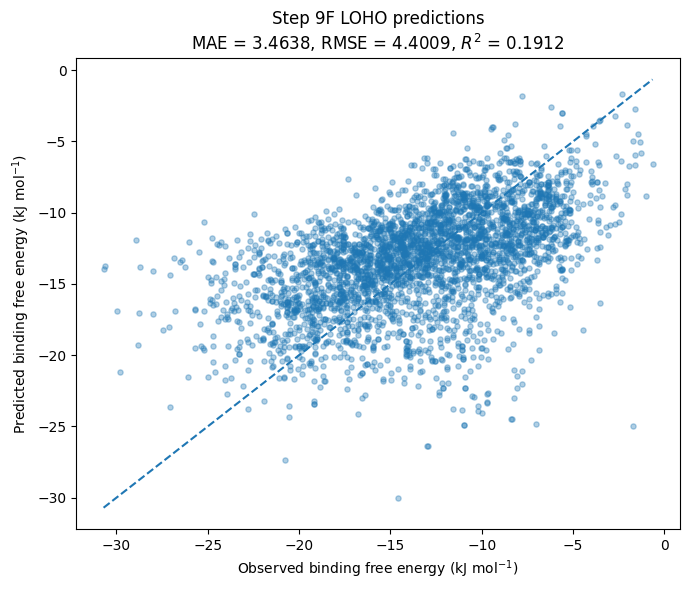

Saved: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/issue_2_verified_figures/verified_observed_vs_predicted.png


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y = d["target_DeltaG_kJmol"].to_numpy()
p = d["prediction_9F"].to_numpy()

mae = mean_absolute_error(y, p)
rmse = np.sqrt(mean_squared_error(y, p))
r2 = r2_score(y, p)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y, p, alpha=0.35, s=14)

lo = min(y.min(), p.min())
hi = max(y.max(), p.max())
ax.plot([lo, hi], [lo, hi], linestyle="--")

ax.set_xlabel("Observed binding free energy (kJ mol$^{-1}$)")
ax.set_ylabel("Predicted binding free energy (kJ mol$^{-1}$)")
ax.set_title(
    f"Step 9F LOHO predictions\n"
    f"MAE = {mae:.4f}, RMSE = {rmse:.4f}, $R^2$ = {r2:.4f}"
)

fig.tight_layout()
fig.savefig(out / "verified_observed_vs_predicted.png", dpi=300)
plt.show()

print("Saved:", out / "verified_observed_vs_predicted.png")


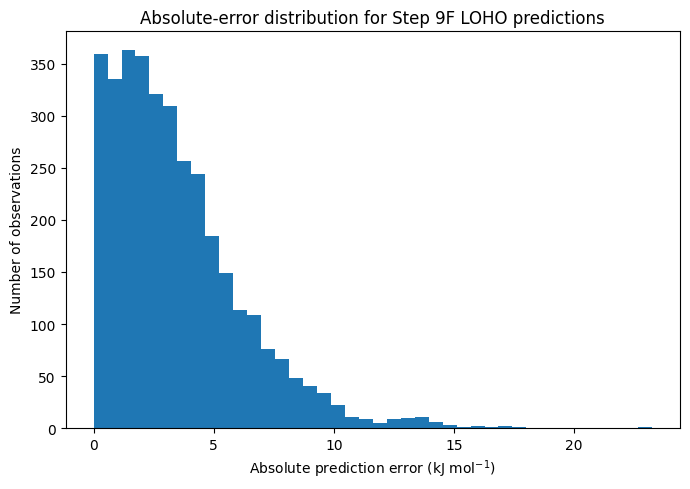

Saved: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/issue_2_verified_figures/verified_absolute_error_distribution.png


In [ ]:

fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(d["absolute_error"], bins=40)

ax.set_xlabel("Absolute prediction error (kJ mol$^{-1}$)")
ax.set_ylabel("Number of observations")
ax.set_title("Absolute-error distribution for Step 9F LOHO predictions")

fig.tight_layout()
fig.savefig(out / "verified_absolute_error_distribution.png", dpi=300)
plt.show()

print("Saved:", out / "verified_absolute_error_distribution.png")


In [ ]:

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

BASE = "/content/drive/MyDrive/CarbonNanoDot_Cancer/results"
INPUT = os.path.join(
    BASE, "step_9H", "step_9H_applicability_predictions.csv"
)
OUTDIR = os.path.join(BASE, "issue_3_verified_AD")
os.makedirs(OUTDIR, exist_ok=True)

df = pd.read_csv(INPUT)

required = [
    "target_DeltaG_kJmol",
    "prediction_9F",
    "absolute_error_9H",
    "AD_nearest_distance",
    "host_group"
]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Recalculate absolute error from the target and prediction.
# This checks whether the saved AD error column is aligned.
df["absolute_error_recalculated"] = (
    df["prediction_9F"] - df["target_DeltaG_kJmol"]
).abs()

print("Rows in file:", len(df))
print("Missing values in key AD columns:")
print(df[
    ["AD_nearest_distance", "absolute_error_9H",
     "absolute_error_recalculated"]
].isna().sum())

valid = df[
    ["AD_nearest_distance", "absolute_error_9H",
     "absolute_error_recalculated"]
].replace([np.inf, -np.inf], np.nan).dropna()

rho_saved, p_saved = spearmanr(
    valid["AD_nearest_distance"],
    valid["absolute_error_9H"]
)

rho_recalc, p_recalc = spearmanr(
    valid["AD_nearest_distance"],
    valid["absolute_error_recalculated"]
)

print("\n--- AD correlation audit ---")
print("Valid observations:", len(valid))
print(f"Stored 9H error: rho={rho_saved:.8f}, p={p_saved:.8g}")
print(f"Recalculated 9F error: rho={rho_recalc:.8f}, p={p_recalc:.8g}")

difference = (
    valid["absolute_error_9H"].to_numpy()
    - valid["absolute_error_recalculated"].to_numpy()
)
print("Maximum absolute-error-column difference:",
      np.max(np.abs(difference)))

# Distance distribution summaries
distance = valid["AD_nearest_distance"]
print("\n--- Nearest-neighbour distance ---")
for q in [0.50, 0.90, 0.95, 0.99]:
    print(f"P{int(q*100):02d}: {distance.quantile(q):.6f}")

# Save a small machine-readable audit
audit = pd.DataFrame([
    {
        "error_column": "absolute_error_9H",
        "n": len(valid),
        "spearman_rho": rho_saved,
        "p_value": p_saved
    },
    {
        "error_column": "recalculated_from_target_and_prediction_9F",
        "n": len(valid),
        "spearman_rho": rho_recalc,
        "p_value": p_recalc
    }
])

audit.to_csv(
    os.path.join(OUTDIR, "AD_correlation_recalculation.csv"),
    index=False
)

print("\nSaved audit to:", OUTDIR)


Rows in file: 3459
Missing values in key AD columns:
AD_nearest_distance            0
absolute_error_9H              0
absolute_error_recalculated    0
dtype: int64

--- AD correlation audit ---
Valid observations: 3459
Stored 9H error: rho=-0.01541550, p=0.36474434
Recalculated 9F error: rho=-0.01541550, p=0.36474434
Maximum absolute-error-column difference: 3.9968028886505635e-15

--- Nearest-neighbour distance ---
P50: 2.903027
P90: 5.402316
P95: 7.770072
P99: 9.247261

Saved audit to: /content/drive/MyDrive/CarbonNanoDot_Cancer/results/issue_3_verified_AD
